In [14]:
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

file_path = r"C:\Users\UE\OneDrive - Uniwersytet Ekonomiczny w Katowicach\Pulpit\Probability Weighted Regime\Kontrakty terminowe na gaz ziemny.csv"

df_raw = pd.read_csv(
    file_path,
    encoding="utf-8-sig"
)

In [15]:
# ------------------------------------------------------------
# RENAME COLUMNS
# ------------------------------------------------------------

df = df_raw.rename(columns={
    "Data": "Date",
    "Ostatnio": "Close",
    "Otwarcie": "Open",
    "Max.": "High",
    "Min.": "Low",
    "Wol.": "Volume",
    "Zmiana%": "Change_pct"
}).copy()


# ------------------------------------------------------------
# DATE
# ------------------------------------------------------------

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d.%m.%Y"
)


# ------------------------------------------------------------
# OHLC
# ------------------------------------------------------------

price_columns = ["Close", "Open", "High", "Low"]

for col in price_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
    )


# ------------------------------------------------------------
# PERCENTAGE CHANGE
# ------------------------------------------------------------

df["Change_pct"] = (
    df["Change_pct"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
)

df["Change_pct"] = pd.to_numeric(
    df["Change_pct"],
    errors="coerce"
)


# ------------------------------------------------------------
# VOLUME
# ------------------------------------------------------------

def convert_volume(value):
    
    if pd.isna(value):
        return np.nan
    
    value = str(value).strip().replace(",", ".")
    
    if value.endswith("K"):
        return float(value[:-1]) * 1_000
    elif value.endswith("M"):
        return float(value[:-1]) * 1_000_000
    elif value.endswith("B"):
        return float(value[:-1]) * 1_000_000_000
    
    try:
        return float(value)
    except ValueError:
        return np.nan


df["Volume"] = df["Volume"].apply(convert_volume)


# ------------------------------------------------------------
# SORT DATA
# ------------------------------------------------------------

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# BASIC VALIDATION
# ------------------------------------------------------------

print("Number of observations:", len(df))
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())
print("Duplicated dates:", df["Date"].duplicated().sum())

print("\nMissing values:")
print(df.isna().sum())


# OHLC consistency check
invalid_ohlc = df[
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1))
    |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
]

print("\nPotential OHLC inconsistencies:")
print(len(invalid_ohlc))

if len(invalid_ohlc) > 0:
    print(invalid_ohlc)


# ------------------------------------------------------------
# FINAL DATAFRAME
# ------------------------------------------------------------

df.head()

Number of observations: 4343
Start date: 2010-01-25 00:00:00
End date: 2026-09-22 00:00:00
Duplicated dates: 0

Missing values:
Date            0
Close           0
Open            0
High            0
Low             0
Volume        140
Change_pct      0
dtype: int64

Potential OHLC inconsistencies:
1
           Date  Close   Open   High  Low    Volume  Change_pct
1130 2014-07-07  4.225  4.398  4.356  4.2  112620.0        -3.3


,Date,Close,Open,High,Low,Volume,Change_pct
0,2010-01-25,5.722,5.821,5.854,5.671,85290.0,-1.67
1,2010-01-26,5.485,5.707,5.721,5.434,65650.0,-4.14
2,2010-01-27,5.274,5.460,5.482,5.223,19270.0,-3.85
3,2010-01-28,5.138,5.230,5.258,5.060,107010.0,-2.58
4,2010-01-29,5.131,5.190,5.285,5.094,79680.0,-0.14


In [16]:
# ============================================================
# STEP 2 - FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. OHLC / HIGH-LOW VALIDITY FLAGS
# ------------------------------------------------------------

# Broad OHLC inconsistency:
# relevant for estimators using Open/High/Low/Close
df["Invalid_OHLC"] = (
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1))
    |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
)


# Parkinson uses ONLY High and Low.
# Open/Close outside the reported H-L range do not invalidate
# Parkinson variance if H and L themselves are valid.
df["Invalid_HL"] = (
    (~np.isfinite(df["High"]))
    |
    (~np.isfinite(df["Low"]))
    |
    (df["High"] <= 0)
    |
    (df["Low"] <= 0)
    |
    (df["High"] < df["Low"])
)


# ------------------------------------------------------------
# 2. RETURNS
# ------------------------------------------------------------

df["Log_Return"] = (
    100
    *
    np.log(
        df["Close"]
        /
        df["Close"].shift(1)
    )
)

df["Abs_Return"] = (
    df["Log_Return"].abs()
)

df["Squared_Return"] = (
    df["Log_Return"] ** 2
)

df["Return_Difference"] = (
    df["Log_Return"]
    -
    df["Change_pct"]
)


# ------------------------------------------------------------
# 3. INTRADAY RANGE
# ------------------------------------------------------------

df["Log_Range"] = (
    100
    *
    np.log(
        df["High"]
        /
        df["Low"]
    )
)

df.loc[
    df["Invalid_HL"],
    "Log_Range"
] = np.nan


# ------------------------------------------------------------
# 4. PARKINSON VARIANCE
# ------------------------------------------------------------

log_hl = (
    100
    *
    np.log(
        df["High"]
        /
        df["Low"]
    )
)

df["Parkinson_Var"] = (
    (log_hl ** 2)
    /
    (4 * np.log(2))
)

# IMPORTANT:
# Parkinson depends only on High and Low
df.loc[
    df["Invalid_HL"],
    "Parkinson_Var"
] = np.nan


df["Parkinson_Vol"] = (
    np.sqrt(
        df["Parkinson_Var"]
    )
)


# ------------------------------------------------------------
# 5. GARMAN-KLASS
# ------------------------------------------------------------

log_co = (
    100
    *
    np.log(
        df["Close"]
        /
        df["Open"]
    )
)

df["GK_Var"] = (
    0.5 * (log_hl ** 2)
    -
    (2 * np.log(2) - 1)
    * (log_co ** 2)
)

# GK uses full OHLC,
# therefore broad OHLC inconsistency matters here.
df.loc[
    df["Invalid_OHLC"],
    "GK_Var"
] = np.nan


df["GK_Vol"] = np.sqrt(
    df["GK_Var"].where(
        df["GK_Var"] >= 0
    )
)


# ------------------------------------------------------------
# 6. ROLLING RETURN VOLATILITY
# ------------------------------------------------------------

for window in [
    5,
    10,
    20
]:

    df[
        f"Return_Vol_{window}"
    ] = (
        df["Log_Return"]
        .rolling(window)
        .std()
    )


# ------------------------------------------------------------
# 7. ROLLING PARKINSON VARIANCE
# ------------------------------------------------------------

for window in [
    5,
    10,
    20
]:

    df[
        f"Parkinson_Mean_{window}"
    ] = (
        df["Parkinson_Var"]
        .rolling(window)
        .mean()
    )


# ------------------------------------------------------------
# 8. LAGS
# ------------------------------------------------------------

lags = [
    1,
    2,
    3,
    5,
    10,
    20
]


for lag in lags:

    df[
        f"Parkinson_Lag_{lag}"
    ] = (
        df["Parkinson_Var"]
        .shift(lag)
    )

    df[
        f"Abs_Return_Lag_{lag}"
    ] = (
        df["Abs_Return"]
        .shift(lag)
    )

    df[
        f"Squared_Return_Lag_{lag}"
    ] = (
        df["Squared_Return"]
        .shift(lag)
    )


# ------------------------------------------------------------
# 9. VOLUME FEATURES
# ------------------------------------------------------------

df["Log_Volume"] = (
    np.log1p(
        df["Volume"]
    )
)

df["Volume_Change"] = (
    df["Volume"]
    .pct_change(
        fill_method=None
    )
)

df["Volume_Mean_5"] = (
    df["Volume"]
    .rolling(5)
    .mean()
)

df["Volume_Mean_20"] = (
    df["Volume"]
    .rolling(20)
    .mean()
)


# ------------------------------------------------------------
# 10. TARGETS: t+1
# ------------------------------------------------------------

df["Target_Parkinson_t1"] = (
    df["Parkinson_Var"]
    .shift(-1)
)

df["Target_GK_t1"] = (
    df["GK_Var"]
    .shift(-1)
)

df["Target_Squared_Return_t1"] = (
    df["Squared_Return"]
    .shift(-1)
)


# ------------------------------------------------------------
# 11. AUDIT
# ------------------------------------------------------------

print(
    "Broad OHLC inconsistencies:",
    int(
        df["Invalid_OHLC"].sum()
    )
)

print(
    "Invalid High-Low observations:",
    int(
        df["Invalid_HL"].sum()
    )
)

print(
    "High = Low observations:",
    int(
        (df["High"] == df["Low"]).sum()
    )
)

print(
    "Zero Parkinson variance:",
    int(
        (df["Parkinson_Var"] == 0).sum()
    )
)

print(
    "Negative GK variance:",
    int(
        (df["GK_Var"] < 0).sum()
    )
)


print(
    "\nMissing engineered variables:"
)

print(
    df[
        [
            "Log_Return",
            "Parkinson_Var",
            "GK_Var",
            "Return_Vol_5",
            "Return_Vol_10",
            "Return_Vol_20",
            "Target_Parkinson_t1"
        ]
    ]
    .isna()
    .sum()
)

Broad OHLC inconsistencies: 1
Invalid High-Low observations: 0
High = Low observations: 1
Zero Parkinson variance: 1
Negative GK variance: 0

Missing engineered variables:
Log_Return              1
Parkinson_Var           0
GK_Var                  1
Return_Vol_5            5
Return_Vol_10          10
Return_Vol_20          20
Target_Parkinson_t1     1
dtype: int64


In [17]:
# ============================================================
# STEP 3.1 - EXTREME RETURNS
# ============================================================

extreme_returns = (
    df[
        [
            "Date",
            "Close",
            "Log_Return",
            "Change_pct",
            "Parkinson_Var",
            "GK_Var"
        ]
    ]
    .dropna(subset=["Log_Return"])
    .assign(Abs_Log_Return=lambda x: x["Log_Return"].abs())
    .sort_values("Abs_Log_Return", ascending=False)
    .head(20)
)

display(extreme_returns)

,Date,Close,Log_Return,Change_pct,Parkinson_Var,GK_Var,Abs_Log_Return
4171,2026-01-29,3.918,-64.397409,-47.48,10.042644,5.761894,64.397409
4166,2026-01-22,5.045,35.568435,42.72,103.645590,143.677827,35.568435
4173,2026-02-02,3.237,-29.644799,-25.65,103.044980,71.563733,29.644799
4099,2025-10-20,4.035,29.373090,34.14,11.456658,6.102684,29.373090
4168,2026-01-26,6.800,25.394393,28.91,246.391674,241.915088,25.394393
3644,2024-01-16,2.477,-21.332563,-19.21,10.878240,12.247121,21.332563
3718,2024-04-29,2.373,21.026851,23.40,8.301248,5.601443,21.026851
4102,2025-10-23,3.344,-19.401528,-17.64,14.714812,17.367692,19.401528
3882,2024-12-16,2.702,-19.385118,-17.62,1.497281,2.041909,19.385118
2279,2018-11-15,4.043,-19.183997,-17.46,168.334869,136.675642,19.183997


In [18]:
# ============================================================
# STEP 3.2 - EXTREME RETURN COUNTS
# ============================================================

thresholds = [5, 10, 15, 20, 30]

for threshold in thresholds:
    count = (df["Log_Return"].abs() > threshold).sum()
    
    print(
        f"|Return| > {threshold}%: {count}"
    )

|Return| > 5%: 489
|Return| > 10%: 76
|Return| > 15%: 23
|Return| > 20%: 7
|Return| > 30%: 2


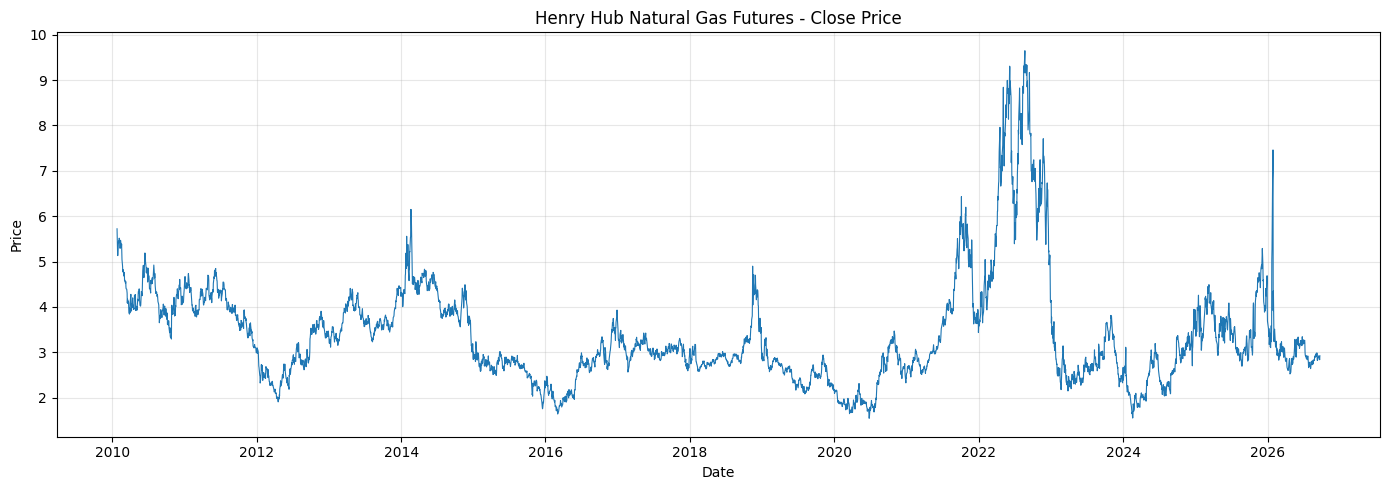

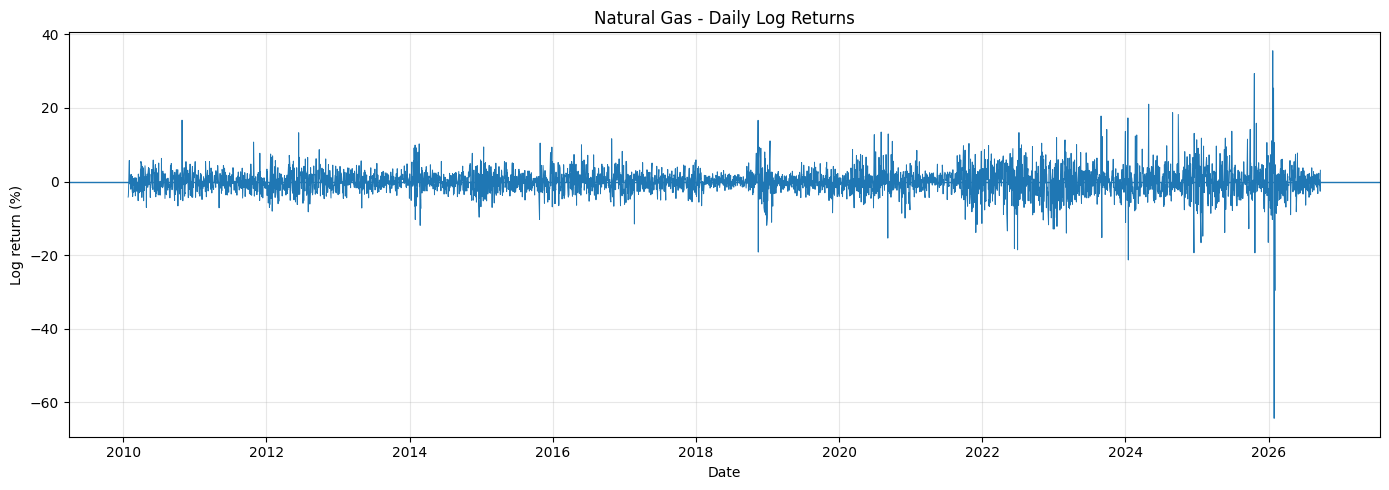

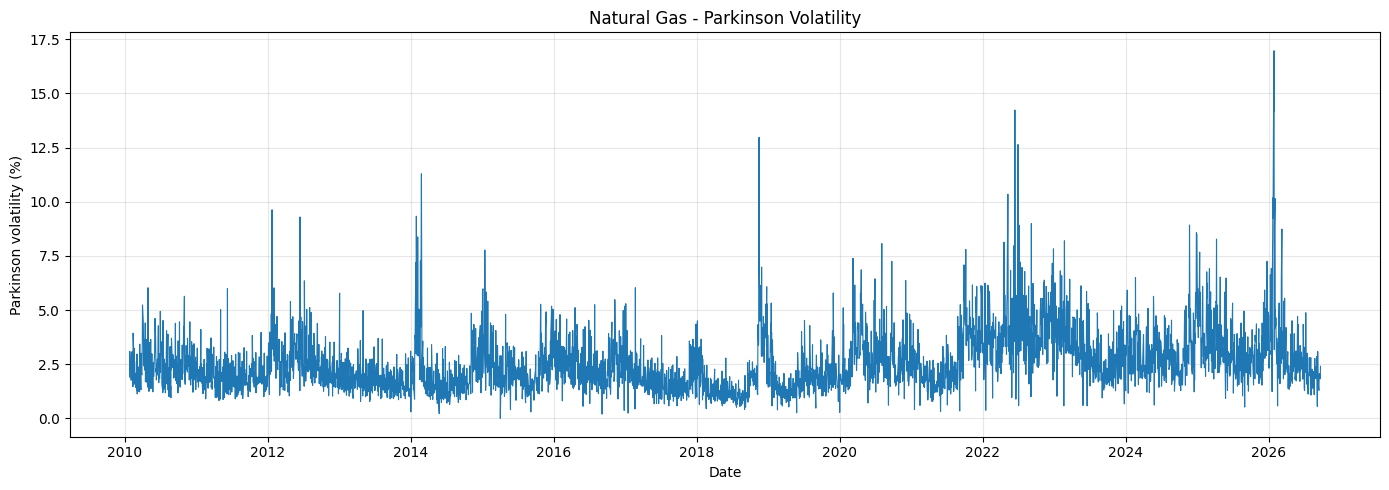

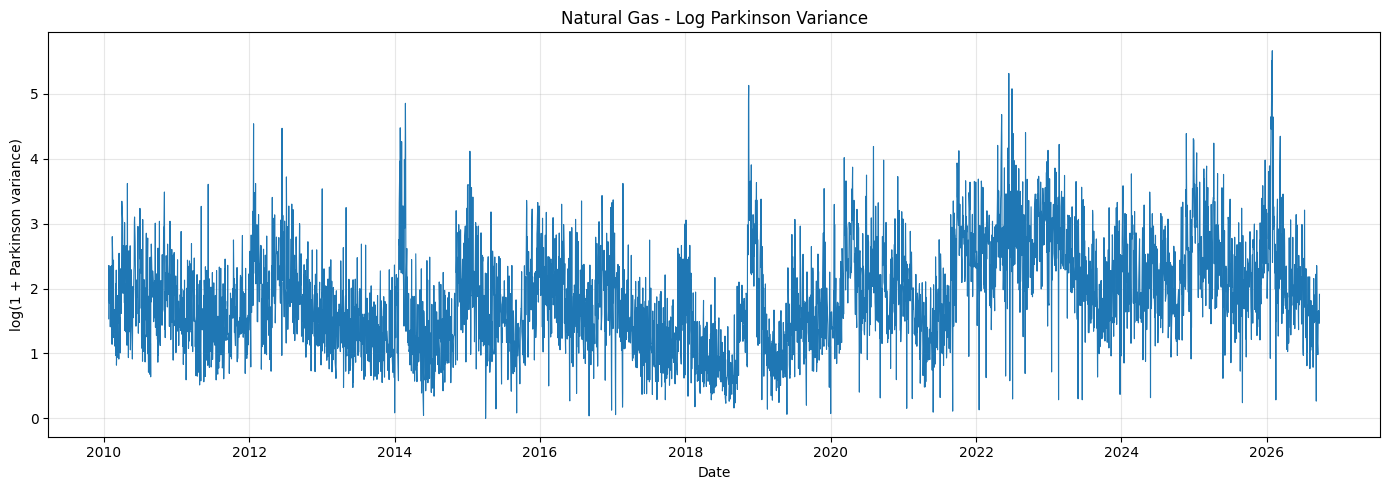

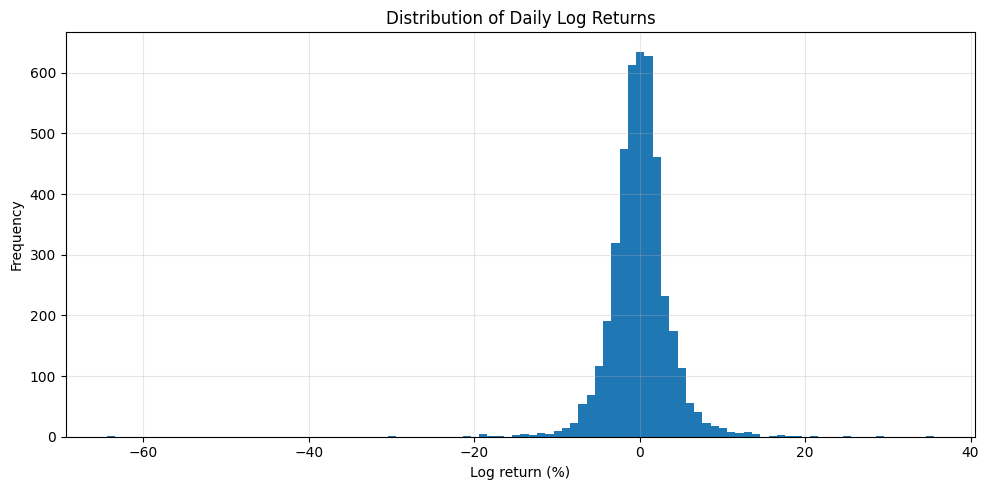

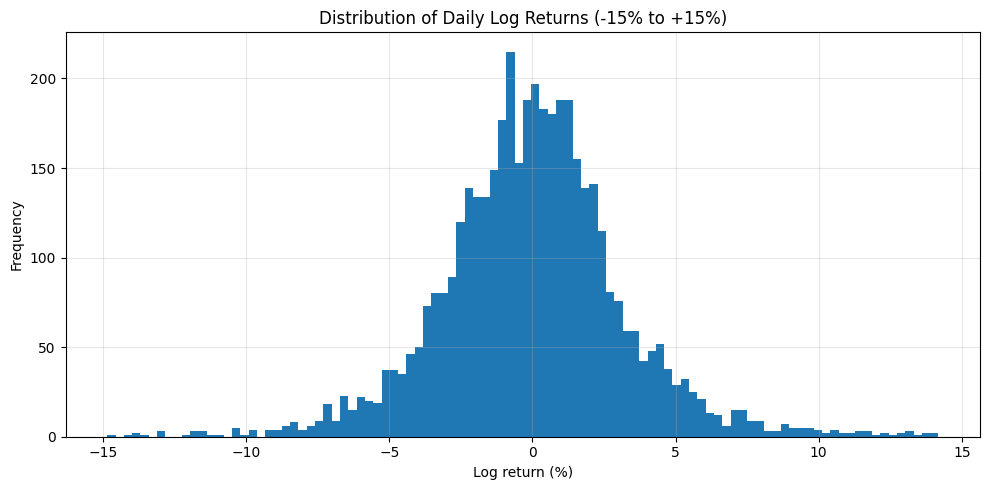

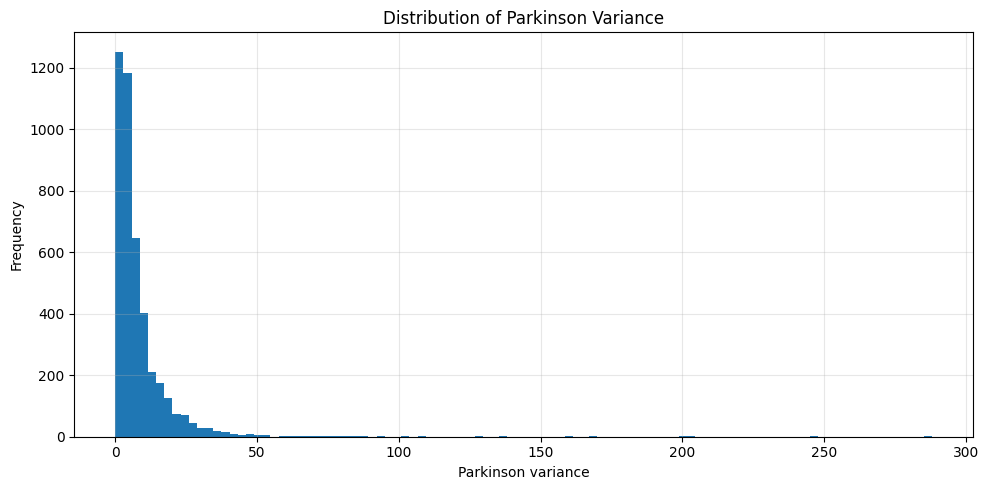

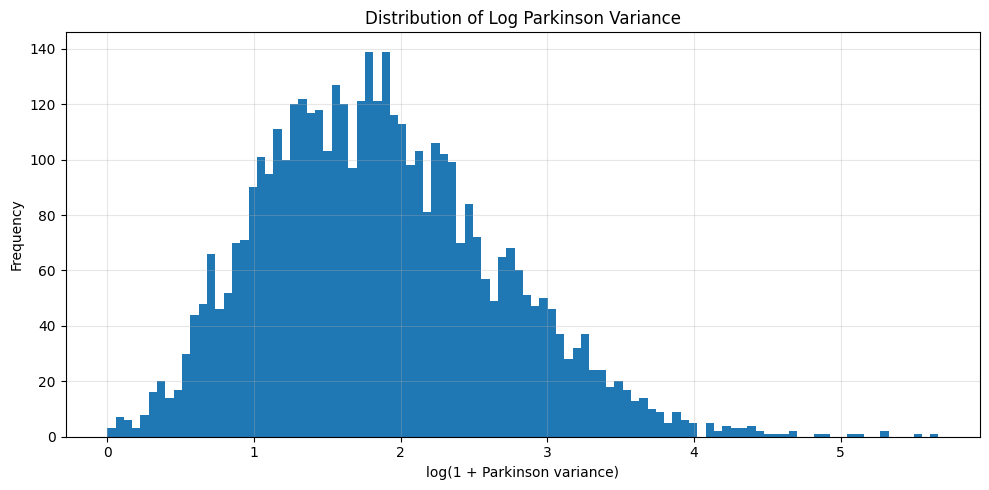

<Figure size 1000x500 with 0 Axes>

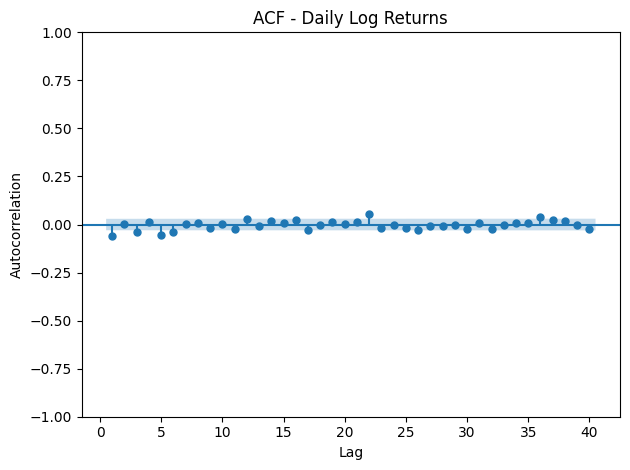

<Figure size 1000x500 with 0 Axes>

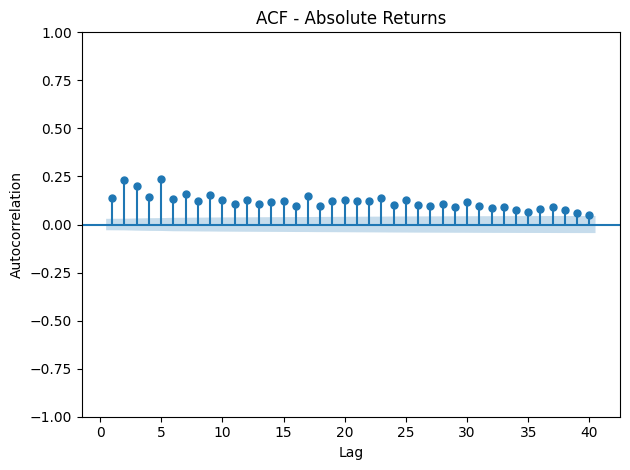

<Figure size 1000x500 with 0 Axes>

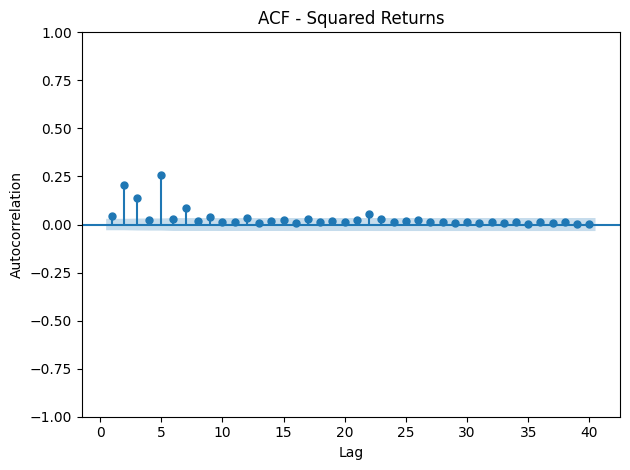

<Figure size 1000x500 with 0 Axes>

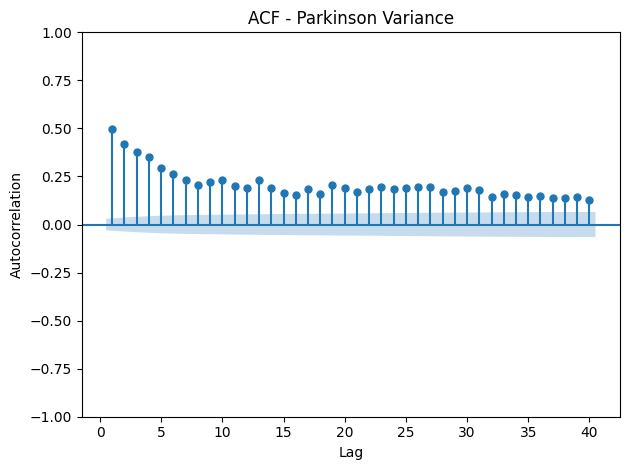


LJUNG-BOX TEST - LOG RETURNS


,lb_stat,lb_pvalue
5,35.803348,0.000001
10,44.802636,0.000002
20,59.214329,0.000009



LJUNG-BOX TEST - SQUARED RETURNS


,lb_stat,lb_pvalue
5,568.197318,1.500993e-120
10,611.093944,7.386536e-125
20,627.448944,4.709392e-120



ARCH-LM TEST


LM statistic     4.710942e+02
LM p-value       6.587138e-95
F statistic      5.272333e+01
F p-value       1.227260e-100
dtype: float64

... (2 outputs left out)


ADF TEST - PARKINSON VARIANCE


ADF statistic   -6.654893e+00
p-value          5.012963e-09
lags             3.100000e+01
observations     4.311000e+03
dtype: float64


CORRELATION BETWEEN VOLATILITY MEASURES


,Squared_Return,Parkinson_Var,GK_Var,Return_Vol_5,Return_Vol_20
Squared_Return,1.000000,0.260674,0.212198,0.439695,0.276578
Parkinson_Var,0.260674,1.000000,0.951497,0.477142,0.407643
GK_Var,0.212198,0.951497,1.000000,0.463235,0.414167
Return_Vol_5,0.439695,0.477142,0.463235,1.000000,0.681284
Return_Vol_20,0.276578,0.407643,0.414167,0.681284,1.000000


In [19]:
# ============================================================
# STEP 3.3 - 3.18
# DIAGNOSTICS OF NATURAL GAS PRICE AND VOLATILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import adfuller


# ============================================================
# STEP 3.3 - PRICE SERIES
# ============================================================

dates = df["Date"].to_numpy()
close = df["Close"].to_numpy()

plt.figure(figsize=(14, 5))

plt.plot(
    dates,
    close,
    linewidth=0.8
)

plt.title("Henry Hub Natural Gas Futures - Close Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.4 - LOG RETURNS
# ============================================================

dates_returns = (
    df.loc[df["Log_Return"].notna(), "Date"]
    .to_numpy()
)

log_returns = (
    df.loc[df["Log_Return"].notna(), "Log_Return"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_returns,
    log_returns,
    linewidth=0.7
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title("Natural Gas - Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log return (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.5 - PARKINSON VOLATILITY
# ============================================================

mask = df["Parkinson_Vol"].notna()

dates_parkinson = (
    df.loc[mask, "Date"]
    .to_numpy()
)

parkinson_vol = (
    df.loc[mask, "Parkinson_Vol"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_parkinson,
    parkinson_vol,
    linewidth=0.8
)

plt.title("Natural Gas - Parkinson Volatility")
plt.xlabel("Date")
plt.ylabel("Parkinson volatility (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.6 - LOG PARKINSON VARIANCE
# ============================================================

df["Log_Parkinson_Var"] = np.log1p(
    df["Parkinson_Var"]
)

mask = df["Log_Parkinson_Var"].notna()

dates_log_parkinson = (
    df.loc[mask, "Date"]
    .to_numpy()
)

log_parkinson = (
    df.loc[mask, "Log_Parkinson_Var"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_log_parkinson,
    log_parkinson,
    linewidth=0.8
)

plt.title("Natural Gas - Log Parkinson Variance")
plt.xlabel("Date")
plt.ylabel("log(1 + Parkinson variance)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.7 - RETURN DISTRIBUTION
# ============================================================

returns_clean = (
    df["Log_Return"]
    .dropna()
    .to_numpy()
)

# Full distribution

plt.figure(figsize=(10, 5))

plt.hist(
    returns_clean,
    bins=100
)

plt.title("Distribution of Daily Log Returns")
plt.xlabel("Log return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Zoomed distribution: -15% to +15%
# ------------------------------------------------------------

returns_zoom = returns_clean[
    (returns_clean >= -15)
    &
    (returns_clean <= 15)
]

plt.figure(figsize=(10, 5))

plt.hist(
    returns_zoom,
    bins=100
)

plt.title("Distribution of Daily Log Returns (-15% to +15%)")
plt.xlabel("Log return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.8 - PARKINSON VARIANCE DISTRIBUTION
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plt.hist(
    parkinson_var_clean,
    bins=100
)

plt.title("Distribution of Parkinson Variance")
plt.xlabel("Parkinson variance")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Log Parkinson variance
# ------------------------------------------------------------

log_parkinson_clean = (
    df["Log_Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plt.hist(
    log_parkinson_clean,
    bins=100
)

plt.title("Distribution of Log Parkinson Variance")
plt.xlabel("log(1 + Parkinson variance)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.9 - ACF OF RETURNS
# ============================================================

returns_clean = (
    df["Log_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Daily Log Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.10 - ACF OF ABSOLUTE RETURNS
# ============================================================

abs_returns_clean = (
    df["Abs_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    abs_returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Absolute Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.11 - ACF OF SQUARED RETURNS
# ============================================================

squared_returns_clean = (
    df["Squared_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    squared_returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Squared Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.12 - ACF OF PARKINSON VARIANCE
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    parkinson_var_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Parkinson Variance")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.13 - LJUNG-BOX TEST: RETURNS
# ============================================================

lb_returns = acorr_ljungbox(
    returns_clean,
    lags=[5, 10, 20],
    return_df=True
)

print("\n========================================")
print("LJUNG-BOX TEST - LOG RETURNS")
print("========================================")

display(lb_returns)


# ============================================================
# STEP 3.14 - LJUNG-BOX TEST: SQUARED RETURNS
# ============================================================

lb_squared = acorr_ljungbox(
    squared_returns_clean,
    lags=[5, 10, 20],
    return_df=True
)

print("\n========================================")
print("LJUNG-BOX TEST - SQUARED RETURNS")
print("========================================")

display(lb_squared)


# ============================================================
# STEP 3.15 - ARCH-LM TEST
# ============================================================

arch_test = het_arch(
    returns_clean,
    nlags=10
)

arch_results = pd.Series(
    {
        "LM statistic": arch_test[0],
        "LM p-value": arch_test[1],
        "F statistic": arch_test[2],
        "F p-value": arch_test[3]
    }
)

print("\n========================================")
print("ARCH-LM TEST")
print("========================================")

display(arch_results)


# ============================================================
# STEP 3.16 - ADF TEST: LOG RETURNS
# ============================================================

adf_result = adfuller(
    returns_clean,
    autolag="AIC"
)

adf_results = pd.Series(
    {
        "ADF statistic": adf_result[0],
        "p-value": adf_result[1],
        "lags": adf_result[2],
        "observations": adf_result[3]
    }
)

print("\n========================================")
print("ADF TEST - LOG RETURNS")
print("========================================")

display(adf_results)


# ============================================================
# STEP 3.17 - ADF TEST: PARKINSON VARIANCE
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

adf_pv = adfuller(
    parkinson_var_clean,
    autolag="AIC"
)

adf_pv_results = pd.Series(
    {
        "ADF statistic": adf_pv[0],
        "p-value": adf_pv[1],
        "lags": adf_pv[2],
        "observations": adf_pv[3]
    }
)

print("\n========================================")
print("ADF TEST - PARKINSON VARIANCE")
print("========================================")

display(adf_pv_results)


# ============================================================
# STEP 3.18 - CORRELATION BETWEEN VOLATILITY MEASURES
# ============================================================

volatility_variables = [
    "Squared_Return",
    "Parkinson_Var",
    "GK_Var",
    "Return_Vol_5",
    "Return_Vol_20"
]

vol_corr = (
    df[volatility_variables]
    .corr()
)

print("\n========================================")
print("CORRELATION BETWEEN VOLATILITY MEASURES")
print("========================================")

display(vol_corr)

In [20]:
# ============================================================
# STEP 4 - FINAL VERSION
# RESET + 5-DAY VOLATILITY REGIMES
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 0. REMOVE OLD REGIME VARIABLES
# ------------------------------------------------------------

columns_to_remove = [
    "Parkinson_Mean_5",
    "PV_Q33",
    "PV_Q67",
    "Volatility_Regime",
    "PV5_Q33",
    "PV5_Q67",
    "Volatility_Regime_5D"
]

df = df.drop(
    columns=[
        col for col in columns_to_remove
        if col in df.columns
    ]
)


# ------------------------------------------------------------
# 1. 5-DAY PARKINSON MEAN
# IMPORTANT: min_periods = 4
# ------------------------------------------------------------

df["Parkinson_Mean_5"] = (
    df["Parkinson_Var"]
    .rolling(
        window=5,
        min_periods=4
    )
    .mean()
)


# ------------------------------------------------------------
# 2. CHECK MISSING VALUES
# ------------------------------------------------------------

print(
    "Missing Parkinson_Var:",
    df["Parkinson_Var"].isna().sum()
)

print(
    "Missing Parkinson_Mean_5:",
    df["Parkinson_Mean_5"].isna().sum()
)


# ------------------------------------------------------------
# 3. ROLLING REGIME THRESHOLDS
# ------------------------------------------------------------

regime_window = 252
min_regime_obs = 250

df["PV5_Q33"] = (
    df["Parkinson_Mean_5"]
    .shift(1)
    .rolling(
        window=regime_window,
        min_periods=min_regime_obs
    )
    .quantile(0.33)
)

df["PV5_Q67"] = (
    df["Parkinson_Mean_5"]
    .shift(1)
    .rolling(
        window=regime_window,
        min_periods=min_regime_obs
    )
    .quantile(0.67)
)


# ------------------------------------------------------------
# 4. DEFINE VOLATILITY REGIME
# ------------------------------------------------------------

conditions = [
    df["Parkinson_Mean_5"] < df["PV5_Q33"],

    (
        (df["Parkinson_Mean_5"] >= df["PV5_Q33"])
        &
        (df["Parkinson_Mean_5"] <= df["PV5_Q67"])
    ),

    df["Parkinson_Mean_5"] > df["PV5_Q67"]
]

df["Volatility_Regime_5D"] = np.select(
    conditions,
    ["Low", "Normal", "High"],
    default=None
)


# ------------------------------------------------------------
# 5. FINAL CHECK
# ------------------------------------------------------------

print("\nMissing values:")

print(
    df[
        [
            "Parkinson_Var",
            "Parkinson_Mean_5",
            "PV5_Q33",
            "PV5_Q67",
            "Volatility_Regime_5D"
        ]
    ].isna().sum()
)


print(
    "\nObservations with regime:",
    df["Volatility_Regime_5D"].notna().sum()
)

print(
    "Observations without regime:",
    df["Volatility_Regime_5D"].isna().sum()
)


print("\nRegime shares:")

display(
    df["Volatility_Regime_5D"]
    .value_counts(normalize=True)
    .mul(100)
    .reindex(["Low", "Normal", "High"])
)

Missing Parkinson_Var: 0
Missing Parkinson_Mean_5: 3

Missing values:
Parkinson_Var             0
Parkinson_Mean_5          3
PV5_Q33                 253
PV5_Q67                 253
Volatility_Regime_5D    253
dtype: int64

Observations with regime: 4090
Observations without regime: 253

Regime shares:


Volatility_Regime_5D
Low       37.555012
Normal    29.095355
High      33.349633
Name: proportion, dtype: float64

In [21]:
# ============================================================
# STEP 4.4 - REGIME PERSISTENCE
# ============================================================

regime_df_5d = (
    df[
        ["Date", "Volatility_Regime_5D"]
    ]
    .dropna()
    .copy()
)

regime_df_5d["Previous_Regime"] = (
    regime_df_5d["Volatility_Regime_5D"]
    .shift(1)
)

regime_df_5d["Regime_Changed"] = (
    regime_df_5d["Volatility_Regime_5D"]
    != regime_df_5d["Previous_Regime"]
)

change_rate = (
    regime_df_5d["Regime_Changed"]
    .iloc[1:]
    .mean()
)

print(
    "Share of observations with regime change:",
    round(change_rate * 100, 2),
    "%"
)


transition_matrix_5d = pd.crosstab(
    regime_df_5d["Previous_Regime"],
    regime_df_5d["Volatility_Regime_5D"],
    normalize="index"
)

transition_matrix_5d = transition_matrix_5d.reindex(
    index=["Low", "Normal", "High"],
    columns=["Low", "Normal", "High"]
)

display(transition_matrix_5d)

Share of observations with regime change: 18.12 %


Volatility_Regime_5D,Low,Normal,High
Previous_Regime,,,
Low,0.865147,0.122476,0.012378
Normal,0.166387,0.700840,0.132773
High,0.007331,0.123167,0.869501


In [22]:
# ============================================================
# STEP 4.5 - REGIME DURATION
# ============================================================

regime_duration = (
    df[
        ["Date", "Volatility_Regime_5D"]
    ]
    .dropna()
    .copy()
)

regime_duration["Spell_ID"] = (
    regime_duration["Volatility_Regime_5D"]
    != regime_duration["Volatility_Regime_5D"].shift(1)
).cumsum()


spells = (
    regime_duration
    .groupby("Spell_ID")
    .agg(
        Regime=("Volatility_Regime_5D", "first"),
        Start=("Date", "min"),
        End=("Date", "max"),
        Duration=("Date", "size")
    )
)


duration_summary = (
    spells
    .groupby("Regime")["Duration"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(duration_summary)

,count,mean,median,min,max
Regime,,,,,
Low,208,7.384615,3.0,1,87
Normal,356,3.342697,2.0,1,21
High,178,7.662921,4.0,1,93


In [23]:
# ============================================================
# STEP 4.6 - VOLATILITY STATE SUMMARY
# ============================================================

regime_state_summary = (
    df
    .dropna(
        subset=[
            "Volatility_Regime_5D",
            "Parkinson_Mean_5"
        ]
    )
    .groupby("Volatility_Regime_5D")["Parkinson_Mean_5"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(regime_state_summary)

,count,mean,median,std,min,max
Volatility_Regime_5D,,,,,,
Low,1536,4.095933,3.407577,2.612967,0.547911,17.162877
Normal,1190,6.875426,5.771966,4.175249,1.539083,22.212594
High,1364,14.857240,11.459210,13.677508,2.600873,184.911968


In [24]:
# ============================================================
# STEP 4.7 - DAILY VOLATILITY WITHIN REGIMES
# Optional descriptive analysis
# ============================================================

daily_volatility_by_regime = (
    df
    .dropna(
        subset=[
            "Volatility_Regime_5D",
            "Parkinson_Var"
        ]
    )
    .groupby("Volatility_Regime_5D")["Parkinson_Var"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(daily_volatility_by_regime)

,count,mean,median,std,min,max
Volatility_Regime_5D,,,,,,
Low,1536,4.043602,3.025121,3.647038,0.038365,38.848106
Normal,1190,6.829824,4.883490,6.123785,0.000000,46.368875
High,1364,14.949059,9.709502,19.617159,0.134778,288.098948


In [25]:
# ============================================================
# STEP 5.1 - TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_end = pd.Timestamp("2016-12-31")
validation_end = pd.Timestamp("2019-12-31")


df["Sample"] = np.select(
    [
        df["Date"] <= train_end,

        (
            (df["Date"] > train_end)
            &
            (df["Date"] <= validation_end)
        ),

        df["Date"] > validation_end
    ],
    [
        "Train",
        "Validation",
        "Test"
    ],
    default=None
)

In [26]:
# ============================================================
# STEP 5.2 - SAMPLE SUMMARY
# ============================================================

sample_summary = (
    df
    .groupby("Sample")
    .agg(
        Start=("Date", "min"),
        End=("Date", "max"),
        Observations=("Date", "size")
    )
    .reindex([
        "Train",
        "Validation",
        "Test"
    ])
)

display(sample_summary)

,Start,End,Observations
Sample,,,
Train,2010-01-25,2016-12-30,1786
Validation,2017-01-02,2019-12-31,790
Test,2020-01-01,2026-09-22,1767


In [27]:
# ============================================================
# STEP 5.3 - REGIMES BY SAMPLE
# ============================================================

regime_by_sample = pd.crosstab(
    df["Sample"],
    df["Volatility_Regime_5D"]
)

regime_by_sample = regime_by_sample.reindex(
    index=["Train", "Validation", "Test"],
    columns=["Low", "Normal", "High"]
)

display(regime_by_sample)

Volatility_Regime_5D,Low,Normal,High
Sample,,,
Train,597,436,500
Validation,347,214,229
Test,592,540,635


In [28]:
# ============================================================
# STEP 5.4 - REGIME SHARES BY SAMPLE
# ============================================================

regime_by_sample_pct = (
    pd.crosstab(
        df["Sample"],
        df["Volatility_Regime_5D"],
        normalize="index"
    )
    * 100
)

regime_by_sample_pct = regime_by_sample_pct.reindex(
    index=["Train", "Validation", "Test"],
    columns=["Low", "Normal", "High"]
)

display(regime_by_sample_pct)

Volatility_Regime_5D,Low,Normal,High
Sample,,,
Train,38.943249,28.440965,32.615786
Validation,43.924051,27.088608,28.987342
Test,33.503113,30.560272,35.936616


In [29]:
# ============================================================
# STEP 5.5 - TARGET VOLATILITY BY SAMPLE
# ============================================================

target_by_sample = (
    df
    .groupby("Sample")["Parkinson_Var"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex([
        "Train",
        "Validation",
        "Test"
    ])
)

display(target_by_sample)

,count,mean,median,std,min,max
Sample,,,,,,
Train,1786,6.227990,4.150352,7.640006,0.000000,127.525765
Validation,790,4.546449,2.519990,9.270214,0.058642,168.334869
Test,1767,12.296472,8.150366,16.294148,0.076033,288.098948


In [30]:
# ============================================================
# STEP 6.1 - FINAL FEATURE SET
# ============================================================

features = [

    # Current Parkinson volatility
    "Parkinson_Var",

    # Lagged Parkinson volatility
    "Parkinson_Lag_1",
    "Parkinson_Lag_2",
    "Parkinson_Lag_3",
    "Parkinson_Lag_5",
    "Parkinson_Lag_10",
    "Parkinson_Lag_20",

    # Aggregated Parkinson volatility
    "Parkinson_Mean_5",
    "Parkinson_Mean_10",
    "Parkinson_Mean_20",

    # Current return information
    "Abs_Return",
    "Squared_Return",

    # Lagged absolute returns
    "Abs_Return_Lag_1",
    "Abs_Return_Lag_2",
    "Abs_Return_Lag_3",
    "Abs_Return_Lag_5",
    "Abs_Return_Lag_10",
    "Abs_Return_Lag_20",

    # Lagged squared returns
    "Squared_Return_Lag_1",
    "Squared_Return_Lag_2",
    "Squared_Return_Lag_3",
    "Squared_Return_Lag_5",
    "Squared_Return_Lag_10",
    "Squared_Return_Lag_20",

    # Rolling return volatility
    "Return_Vol_5",
    "Return_Vol_10",
    "Return_Vol_20"
]

target = "Target_Parkinson_t1"

In [31]:
# ============================================================
# STEP 6.2 - CREATE MODEL DATASET
# ============================================================

model_columns = (
    [
        "Date",
        "Sample",
        "Volatility_Regime_5D"
    ]
    + features
    + [target]
)

model_df = (
    df[model_columns]
    .copy()
)

print("Initial model dataset shape:")
print(model_df.shape)

Initial model dataset shape:
(4343, 31)


In [32]:
# ============================================================
# STEP 6.3 - MISSING VALUES
# ============================================================

missing_values = (
    model_df
    .isna()
    .sum()
)

print("Missing values before filtering:")
display(missing_values)

Missing values before filtering:


Date                       0
Sample                     0
Volatility_Regime_5D     253
Parkinson_Var              0
Parkinson_Lag_1            1
Parkinson_Lag_2            2
Parkinson_Lag_3            3
Parkinson_Lag_5            5
Parkinson_Lag_10          10
Parkinson_Lag_20          20
Parkinson_Mean_5           3
Parkinson_Mean_10          9
Parkinson_Mean_20         19
Abs_Return                 1
Squared_Return             1
Abs_Return_Lag_1           2
Abs_Return_Lag_2           3
Abs_Return_Lag_3           4
Abs_Return_Lag_5           6
Abs_Return_Lag_10         11
Abs_Return_Lag_20         21
Squared_Return_Lag_1       2
Squared_Return_Lag_2       3
Squared_Return_Lag_3       4
Squared_Return_Lag_5       6
Squared_Return_Lag_10     11
Squared_Return_Lag_20     21
Return_Vol_5               5
Return_Vol_10             10
Return_Vol_20             20
Target_Parkinson_t1        1
dtype: int64

In [33]:
# ============================================================
# STEP 6.4 - COMPLETE MODEL SAMPLE
# ============================================================

model_df_complete = (
    model_df
    .dropna(
        subset=features + [target]
    )
    .reset_index(drop=True)
)

print(
    "Observations before filtering:",
    len(model_df)
)

print(
    "Observations after filtering:",
    len(model_df_complete)
)

print(
    "Removed observations:",
    len(model_df) - len(model_df_complete)
)

print(
    "\nModel date range:",
    model_df_complete["Date"].min(),
    "-",
    model_df_complete["Date"].max()
)

Observations before filtering: 4343
Observations after filtering: 4321
Removed observations: 22

Model date range: 2010-02-24 00:00:00 - 2026-09-21 00:00:00


In [21]:
# ============================================================
# STEP 6.5 - X AND y
# ============================================================

X = (
    model_df_complete[features]
    .copy()
)

y = (
    model_df_complete[target]
    .copy()
)

dates_model = (
    model_df_complete["Date"]
    .copy()
)

samples_model = (
    model_df_complete["Sample"]
    .copy()
)

regimes_model = (
    model_df_complete["Volatility_Regime_5D"]
    .copy()
)


print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4321, 27)
y shape: (4321,)


In [22]:
# ============================================================
# STEP 6.6 - SAMPLE MASKS
# ============================================================

train_mask = (
    model_df_complete["Sample"] == "Train"
)

validation_mask = (
    model_df_complete["Sample"] == "Validation"
)

test_mask = (
    model_df_complete["Sample"] == "Test"
)

In [23]:
# ============================================================
# STEP 6.7 - TRAIN / VALIDATION / TEST MATRICES
# ============================================================

X_train = (
    X.loc[train_mask]
    .copy()
)

y_train = (
    y.loc[train_mask]
    .copy()
)


X_validation = (
    X.loc[validation_mask]
    .copy()
)

y_validation = (
    y.loc[validation_mask]
    .copy()
)


X_test = (
    X.loc[test_mask]
    .copy()
)

y_test = (
    y.loc[test_mask]
    .copy()
)


print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Validation:",
    X_validation.shape,
    y_validation.shape
)

print(
    "Test:",
    X_test.shape,
    y_test.shape
)

Train: (1765, 27) (1765,)
Validation: (790, 27) (790,)
Test: (1766, 27) (1766,)


In [24]:
# ============================================================
# STEP 6.8 - DATES AND REGIMES BY SAMPLE
# ============================================================

dates_train = (
    model_df_complete.loc[
        train_mask,
        "Date"
    ]
    .copy()
)

dates_validation = (
    model_df_complete.loc[
        validation_mask,
        "Date"
    ]
    .copy()
)

dates_test = (
    model_df_complete.loc[
        test_mask,
        "Date"
    ]
    .copy()
)


regimes_train = (
    model_df_complete.loc[
        train_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

regimes_validation = (
    model_df_complete.loc[
        validation_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

regimes_test = (
    model_df_complete.loc[
        test_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

In [25]:
# ============================================================
# STEP 6.9 - CHRONOLOGICAL CHECK
# ============================================================

print("TRAIN")
print(
    model_df_complete.loc[
        train_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        train_mask,
        "Date"
    ].max()
)


print("\nVALIDATION")
print(
    model_df_complete.loc[
        validation_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        validation_mask,
        "Date"
    ].max()
)


print("\nTEST")
print(
    model_df_complete.loc[
        test_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        test_mask,
        "Date"
    ].max()
)

TRAIN
2010-02-24 00:00:00 - 2016-12-30 00:00:00

VALIDATION
2017-01-02 00:00:00 - 2019-12-31 00:00:00

TEST
2020-01-01 00:00:00 - 2026-09-21 00:00:00


In [26]:
# ============================================================
# STEP 6.10 - TARGET ALIGNMENT CHECK
# ============================================================

alignment_check = (
    df[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1"
        ]
    ]
    .copy()
)

alignment_check[
    "Next_Parkinson_Actual"
] = (
    alignment_check[
        "Parkinson_Var"
    ]
    .shift(-1)
)

alignment_check[
    "Difference"
] = (
    alignment_check[
        "Target_Parkinson_t1"
    ]
    -
    alignment_check[
        "Next_Parkinson_Actual"
    ]
)


max_alignment_difference = (
    alignment_check[
        "Difference"
    ]
    .abs()
    .max()
)

print(
    "Maximum target alignment difference:",
    max_alignment_difference
)

Maximum target alignment difference: 0.0


In [27]:
# ============================================================
# STEP 6.11 - FINAL NaN CHECK
# ============================================================

print(
    "Missing values in X:",
    X.isna().sum().sum()
)

print(
    "Missing values in y:",
    y.isna().sum()
)

Missing values in X: 0
Missing values in y: 0


In [28]:
# ============================================================
# STEP 6.12 - INFINITE VALUES CHECK
# ============================================================

number_of_infinite_X = (
    np.isinf(
        X.to_numpy()
    )
    .sum()
)

number_of_infinite_y = (
    np.isinf(
        y.to_numpy()
    )
    .sum()
)

print(
    "Infinite values in X:",
    number_of_infinite_X
)

print(
    "Infinite values in y:",
    number_of_infinite_y
)

Infinite values in X: 0
Infinite values in y: 0


In [29]:
# ============================================================
# STEP 6.13 - FINAL MODEL DATA SUMMARY
# ============================================================

final_summary = pd.DataFrame({
    "Sample": [
        "Train",
        "Validation",
        "Test"
    ],

    "Observations": [
        train_mask.sum(),
        validation_mask.sum(),
        test_mask.sum()
    ],

    "Start": [
        dates_train.min(),
        dates_validation.min(),
        dates_test.min()
    ],

    "End": [
        dates_train.max(),
        dates_validation.max(),
        dates_test.max()
    ]
})

display(final_summary)

print(
    "\nNumber of features:",
    len(features)
)

print(
    "Target:",
    target
)

,Sample,Observations,Start,End
0,Train,1765,2010-02-24,2016-12-30
1,Validation,790,2017-01-02,2019-12-31
2,Test,1766,2020-01-01,2026-09-21



Number of features: 27
Target: Target_Parkinson_t1


In [30]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

print(
    "Maximum target alignment difference:",
    max_alignment_difference
)

print(
    "Missing values in X:",
    X.isna().sum().sum()
)

print(
    "Infinite values in X:",
    number_of_infinite_X
)

Train: (1765, 27) (1765,)
Validation: (790, 27) (790,)
Test: (1766, 27) (1766,)
Maximum target alignment difference: 0.0
Missing values in X: 0
Infinite values in X: 0


In [31]:

# ============================================================
# FIXED MODEL CONFIGURATIONS
# Recovered from completed original notebooks
# NO GRID SEARCH / NO HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd

# CHANGE THIS FOR EACH NOTEBOOK:
# "EUA", "BRENT", "COPPER", "NATURAL_GAS"

MARKET = "NATURAL_GAS"

MODEL_CONFIGS = {

    # ========================================================
    # EUROPEAN UNION ALLOWANCES
    # ========================================================

    "EUA": {
        "RF": {
            "n_estimators": 100,
            "max_depth": 10,
            "max_features": 1.0,
            "min_samples_leaf": 3,
            "min_samples_split": 10
        },
        "XGB": {
            "n_estimators": 200,
            "max_depth": 1,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        "SVR": {
            "kernel": "linear",
            "C": 1.0,
            "epsilon": 0.5
        },
        "ARCH": {
            "GARCH": (1, 0, 3),
            "EGARCH": (1, 1, 3),
            "GJR-GARCH": (1, 1, 3)
        }
    },

    # ========================================================
    # BRENT CRUDE OIL
    # ========================================================

    "BRENT": {
        "RF": {
            "n_estimators": 300,
            "max_depth": None,
            "max_features": 0.5,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "XGB": {
            "n_estimators": 300,
            "max_depth": 2,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "SVR": {
            "kernel": "rbf",
            "C": 10.0,
            "epsilon": 1.0,
            "gamma": 0.01
        },
        "ARCH": {
            "GARCH": (2, 0, 1),
            "EGARCH": (1, 1, 2),
            "GJR-GARCH": (2, 1, 2)
        }
    },

    # ========================================================
    # COPPER
    # ========================================================

    "COPPER": {
        "RF": {
            "n_estimators": 100,
            "max_depth": 6,
            "max_features": 0.5,
            "min_samples_leaf": 8,
            "min_samples_split": 2
        },
        "XGB": {
            "n_estimators": 450,
            "max_depth": 1,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "SVR": {
            "kernel": "linear",
            "C": 0.1,
            "epsilon": 0.5
        },
        "ARCH": {
            "GARCH": (1, 0, 3),
            "EGARCH": (2, 1, 2),
            "GJR-GARCH": (1, 1, 2)
        }
    },

    # ========================================================
    # NATURAL GAS
    # ========================================================

    "NATURAL_GAS": {
        "RF": {
            "n_estimators": 300,
            "max_depth": 6,
            "max_features": 0.25,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "XGB": {
            "n_estimators": 100,
            "max_depth": 1,
            "learning_rate": 0.1,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 5.0
        },
        "SVR": {
            "kernel": "rbf",
            "C": 10.0,
            "epsilon": 3.0,
            "gamma": 0.01
        },
        "ARCH": {
            "GARCH": (1, 0, 3),
            "EGARCH": (1, 1, 2),
            "GJR-GARCH": (1, 1, 3)
        }
    }
}

# ============================================================
# ASSIGN CONFIGURATIONS TO EXISTING NOTEBOOK VARIABLES
# ============================================================

assert MARKET in MODEL_CONFIGS

config = MODEL_CONFIGS[MARKET]

rf_final_params = config["RF"].copy()
xgb_final_params = config["XGB"].copy()
svr_final_params = config["SVR"].copy()

# All four markets selected Constant mean on Train

best_mean_name = "Constant"

best_mean_config = {
    "Name": "Constant",
    "Mean": "Constant",
    "Lags": None
}

# Build ARCH specifications expected by STEP 11.9

arch_final_specs = {}

for family, (p, o, q) in config["ARCH"].items():

    arch_final_specs[family] = {
        "vol": "EGARCH" if family == "EGARCH" else "GARCH",
        "p": p,
        "o": o,
        "q": q
    }

print("MARKET:", MARKET)
print("RF:", rf_final_params)
print("XGBoost:", xgb_final_params)
print("SVR:", svr_final_params)
print("ARCH:", arch_final_specs)
print("Mean:", best_mean_config)


MARKET: NATURAL_GAS
RF: {'n_estimators': 300, 'max_depth': 6, 'max_features': 0.25, 'min_samples_leaf': 12, 'min_samples_split': 2}
XGBoost: {'n_estimators': 100, 'max_depth': 1, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 0.6, 'min_child_weight': 5, 'reg_alpha': 0.0, 'reg_lambda': 5.0}
SVR: {'kernel': 'rbf', 'C': 10.0, 'epsilon': 3.0, 'gamma': 0.01}
ARCH: {'GARCH': {'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 3}, 'EGARCH': {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 2}, 'GJR-GARCH': {'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 3}}
Mean: {'Name': 'Constant', 'Mean': 'Constant', 'Lags': None}


In [32]:
# ============================================================
# STEP 7.1 - HAR SPECIFICATION
# ============================================================

har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

har_target = "Target_Parkinson_t1"

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def qlike_loss(actual, forecast, epsilon=1e-8):
    
    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    
    forecast = np.maximum(
        forecast,
        epsilon
    )
    
    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


def evaluate_forecast(
    actual,
    forecast,
    model_name
):
    
    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    
    mae = mean_absolute_error(
        actual,
        forecast
    )
    
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )
    
    qlike = qlike_loss(
        actual,
        forecast
    )
    
    return pd.DataFrame({
        "Model": [model_name],
        "MAE": [mae],
        "RMSE": [rmse],
        "QLIKE": [qlike]
    })

In [34]:
# ============================================================
# STEP 7.3 - FINAL WALK-FORWARD HAR
# ============================================================

from sklearn.linear_model import LinearRegression

har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

har_target = "Target_Parkinson_t1"


validation_origins = (
    model_df_complete[
        model_df_complete["Sample"] == "Validation"
    ]
    .sort_values("Date")
    .copy()
)


har_wf_forecasts = []


for _, row in validation_origins.iterrows():

    origin_date = row["Date"]

    # Only observations whose t+1 target is already known
    train_history = (
        model_df_complete[
            model_df_complete["Date"] < origin_date
        ]
        .dropna(
            subset=har_features + [har_target]
        )
    )

    X_hist = train_history[har_features]
    y_hist = train_history[har_target]

    X_current = pd.DataFrame(
        [row[har_features].values],
        columns=har_features
    )

    model = LinearRegression()

    model.fit(
        X_hist,
        y_hist
    )

    forecast = float(
        model.predict(X_current)[0]
    )

    har_wf_forecasts.append(
        {
            "Date": origin_date,
            "Forecast_HAR": forecast
        }
    )


har_validation_wf = pd.DataFrame(
    har_wf_forecasts
)


print(
    "HAR walk-forward forecasts:",
    len(har_validation_wf)
)

display(
    har_validation_wf.head()
)

HAR walk-forward forecasts: 790


,Date,Forecast_HAR
0,2017-01-02,7.344668
1,2017-01-03,11.682279
2,2017-01-04,8.094513
3,2017-01-05,8.897004
4,2017-01-06,8.656113


In [35]:
validation_base = (
    validation_origins[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)

validation_base["Forecast_Naive"] = (
    validation_base["Parkinson_Var"]
)

validation_base = (
    validation_base
    .merge(
        har_validation_wf,
        on="Date",
        how="left"
    )
)

display(validation_base.head())

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR
0,2017-01-02,2.987630,28.015118,High,2.987630,7.344668
1,2017-01-03,28.015118,4.939642,High,28.015118,11.682279
2,2017-01-04,4.939642,10.286099,High,4.939642,8.094513
3,2017-01-05,10.286099,6.928567,High,10.286099,8.897004
4,2017-01-06,6.928567,11.134139,High,6.928567,8.656113


In [36]:
# ============================================================
# STEP 7.5 - FINAL VALIDATION PERFORMANCE
# ============================================================

results_naive = evaluate_forecast(
    actual=validation_base["Target_Parkinson_t1"],
    forecast=validation_base["Forecast_Naive"],
    model_name="Naive"
)

results_har = evaluate_forecast(
    actual=validation_base["Target_Parkinson_t1"],
    forecast=validation_base["Forecast_HAR"],
    model_name="HAR"
)

validation_results = pd.concat(
    [
        results_naive,
        results_har
    ],
    ignore_index=True
)

display(validation_results)

,Model,MAE,RMSE,QLIKE
0,Naive,3.469782,8.346899,2.850852
1,HAR,2.928716,7.951431,2.274697


In [37]:
# ============================================================
# STEP 7.6 - CHECK FINAL HAR FORECASTS
# ============================================================

print(
    "Minimum HAR forecast:",
    validation_base["Forecast_HAR"].min()
)

print(
    "Negative HAR forecasts:",
    (
        validation_base["Forecast_HAR"] < 0
    ).sum()
)

print(
    "Missing HAR forecasts:",
    validation_base["Forecast_HAR"].isna().sum()
)

Minimum HAR forecast: 1.6700846523950714
Negative HAR forecasts: 0
Missing HAR forecasts: 0


In [38]:
# ============================================================
# STEP 7.7 - FINAL PERFORMANCE BY REGIME
# ============================================================

regime_results = []

for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = validation_base[
        validation_base[
            "Volatility_Regime_5D"
        ] == regime
    ]

    for model_name, forecast_col in [
        ("Naive", "Forecast_Naive"),
        ("HAR", "Forecast_HAR")
    ]:

        result = evaluate_forecast(
            actual=temp["Target_Parkinson_t1"],
            forecast=temp[forecast_col],
            model_name=model_name
        )

        result["Regime"] = regime

        regime_results.append(result)


validation_results_by_regime = pd.concat(
    regime_results,
    ignore_index=True
)

display(
    validation_results_by_regime[
        [
            "Regime",
            "Model",
            "MAE",
            "RMSE",
            "QLIKE"
        ]
    ]
)

,Regime,Model,MAE,RMSE,QLIKE
0,Low,Naive,1.780539,3.078054,2.488958
1,Low,HAR,1.678279,2.689339,1.884257
2,Normal,Naive,2.536197,3.809658,2.898781
3,Normal,HAR,2.245401,3.087836,2.162803
4,High,Naive,6.901900,14.574962,3.354433
5,High,HAR,5.462040,14.079906,2.970887


In [39]:
# ============================================================
# STEP 7.9 - DIEBOLD-MARIANO TEST FUNCTION
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t


def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None,
    epsilon=1e-8
):
    """
    Diebold-Mariano test for equal predictive accuracy.

    Parameters
    ----------
    actual : array-like
        Actual values.

    forecast_1 : array-like
        Forecasts from model 1.

    forecast_2 : array-like
        Forecasts from model 2.

    loss : str
        Loss function:
        "MAE", "MSE", or "QLIKE".

    h : int
        Forecast horizon.
        For our analysis: h = 1.

    hac_lags : int or None
        Number of HAC/Newey-West lags.
        If None, selected automatically.

    epsilon : float
        Small positive value used only to protect
        QLIKE against log(0) or division by zero.

    Returns
    -------
    pandas.DataFrame
        One-row table containing DM test results.

    Interpretation
    --------------
    Mean_Loss_Diff < 0:
        forecast_1 has lower average loss.

    Mean_Loss_Diff > 0:
        forecast_2 has lower average loss.

    p_value < 0.05:
        difference is statistically significant.
    """

    # --------------------------------------------------------
    # 1. Convert inputs to NumPy arrays
    # --------------------------------------------------------

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast_1 = np.asarray(
        forecast_1,
        dtype=float
    )

    forecast_2 = np.asarray(
        forecast_2,
        dtype=float
    )


    # --------------------------------------------------------
    # 2. Remove missing / non-finite observations jointly
    # --------------------------------------------------------

    valid = (
        np.isfinite(actual)
        &
        np.isfinite(forecast_1)
        &
        np.isfinite(forecast_2)
    )

    actual = actual[valid]
    forecast_1 = forecast_1[valid]
    forecast_2 = forecast_2[valid]


    n = len(actual)

    if n < 10:
        raise ValueError(
            "Too few valid observations for the DM test."
        )


    # --------------------------------------------------------
    # 3. Calculate loss for each model
    # --------------------------------------------------------

    loss = loss.upper()


    if loss == "MAE":

        loss_1 = np.abs(
            actual - forecast_1
        )

        loss_2 = np.abs(
            actual - forecast_2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - forecast_1
        ) ** 2

        loss_2 = (
            actual - forecast_2
        ) ** 2


    elif loss == "QLIKE":

        # Protect forecasts only for numerical reasons
        f1 = np.maximum(
            forecast_1,
            epsilon
        )

        f2 = np.maximum(
            forecast_2,
            epsilon
        )

        loss_1 = (
            np.log(f1)
            +
            actual / f1
        )

        loss_2 = (
            np.log(f2)
            +
            actual / f2
        )


    else:

        raise ValueError(
            "loss must be 'MAE', 'MSE', or 'QLIKE'."
        )


    # --------------------------------------------------------
    # 4. Loss differential
    #
    # d < 0 -> forecast_1 better
    # d > 0 -> forecast_2 better
    # --------------------------------------------------------

    d = loss_1 - loss_2

    mean_d = np.mean(d)


    # --------------------------------------------------------
    # 5. Automatic HAC lag selection
    # --------------------------------------------------------

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4 * (n / 100) ** (2 / 9)
            )
        )


    hac_lags = max(
        0,
        min(
            hac_lags,
            n - 1
        )
    )


    # --------------------------------------------------------
    # 6. Newey-West / Bartlett long-run variance
    # --------------------------------------------------------

    d_centered = (
        d - mean_d
    )


    gamma_0 = np.sum(
        d_centered ** 2
    ) / n


    long_run_variance = gamma_0


    for lag in range(
        1,
        hac_lags + 1
    ):

        gamma_lag = np.sum(
            d_centered[lag:]
            *
            d_centered[:-lag]
        ) / n


        bartlett_weight = (
            1
            -
            lag / (hac_lags + 1)
        )


        long_run_variance += (
            2
            *
            bartlett_weight
            *
            gamma_lag
        )


    if long_run_variance <= 0:

        raise ValueError(
            "Estimated long-run variance is non-positive."
        )


    # --------------------------------------------------------
    # 7. Standard DM statistic
    # --------------------------------------------------------

    dm_stat = (
        mean_d
        /
        np.sqrt(
            long_run_variance / n
        )
    )


    # --------------------------------------------------------
    # 8. Harvey-Leybourne-Newbold small-sample correction
    # --------------------------------------------------------

    hln_correction = np.sqrt(
        (
            n
            + 1
            - 2 * h
            + (
                h * (h - 1) / n
            )
        )
        / n
    )


    dm_stat_corrected = (
        dm_stat
        *
        hln_correction
    )


    # --------------------------------------------------------
    # 9. Two-sided p-value
    # --------------------------------------------------------

    p_value = (
        2
        *
        student_t.sf(
            np.abs(
                dm_stat_corrected
            ),
            df=n - 1
        )
    )


    # --------------------------------------------------------
    # 10. Return result
    # --------------------------------------------------------

    return pd.DataFrame(
        {
            "Loss": [loss],
            "N": [n],
            "Mean_Loss_Diff": [mean_d],
            "DM_stat": [dm_stat_corrected],
            "p_value": [p_value],
            "HAC_lags": [hac_lags]
        }
    )

In [40]:
# ============================================================
# FINAL GLOBAL DM TEST
# HAR walk-forward vs Naive
# ============================================================

dm_results_global = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    result = diebold_mariano_test(

        actual=
        validation_base[
            "Target_Parkinson_t1"
        ],

        # MODEL 1 = HAR
        forecast_1=
        validation_base[
            "Forecast_HAR"
        ],

        # MODEL 2 = Naive
        forecast_2=
        validation_base[
            "Forecast_Naive"
        ],

        loss=loss_function,

        h=1
    )


    result[
        "Comparison"
    ] = "HAR vs Naive"


    dm_results_global.append(
        result
    )


dm_results_global = pd.concat(
    dm_results_global,
    ignore_index=True
)


display(
    dm_results_global[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,HAR vs Naive,MAE,790,-0.541066,-4.048004,5.674675e-05,6
1,HAR vs Naive,MSE,790,-6.445471,-0.468511,6.395483e-01,6
2,HAR vs Naive,QLIKE,790,-0.576155,-5.323926,1.325006e-07,6


In [41]:
# ============================================================
# STEP 7.9 - FINAL DM TEST BY REGIME
# ============================================================

dm_results_regime = []

for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = validation_base[
        validation_base[
            "Volatility_Regime_5D"
        ] == regime
    ]

    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = diebold_mariano_test(
            actual=temp[
                "Target_Parkinson_t1"
            ],

            forecast_1=temp[
                "Forecast_HAR"
            ],

            forecast_2=temp[
                "Forecast_Naive"
            ],

            loss=loss_function,
            h=1
        )

        result["Regime"] = regime
        result["Comparison"] = "HAR vs Naive"

        dm_results_regime.append(result)


dm_results_regime = pd.concat(
    dm_results_regime,
    ignore_index=True
)

display(dm_results_regime)

,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Regime,Comparison
0,MAE,347,-0.102259,-1.542189,0.123942,5,Low,HAR vs Naive
1,MSE,347,-2.241875,-3.275534,0.001161,5,Low,HAR vs Naive
2,QLIKE,347,-0.604701,-3.199222,0.001505,5,Low,HAR vs Naive
3,MAE,214,-0.290796,-2.400517,0.017232,4,Normal,HAR vs Naive
4,MSE,214,-4.978757,-3.854160,0.000154,4,Normal,HAR vs Naive
5,QLIKE,214,-0.735978,-3.006198,0.002963,4,Normal,HAR vs Naive
6,MAE,229,-1.439859,-3.328043,0.001020,4,High,HAR vs Naive
7,MSE,229,-14.185754,-0.267097,0.789636,4,High,HAR vs Naive
8,QLIKE,229,-0.383546,-3.553128,0.000463,4,High,HAR vs Naive


In [42]:
# ============================================================
# STEP 8.0 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)
from arch import arch_model

In [43]:
# ============================================================
# STEP 8.1 - RETURN DATA FOR GARCH-FAMILY MODELS
# ============================================================

returns_df = (
    df[
        [
            "Date",
            "Log_Return"
        ]
    ]
    .dropna()
    .sort_values("Date")
    .reset_index(drop=True)
)


train_returns = (
    returns_df.loc[
        returns_df["Date"] <= train_end,
        [
            "Date",
            "Log_Return"
        ]
    ]
    .copy()
)


y_train_returns = (
    train_returns
    .set_index("Date")["Log_Return"]
)


print(
    "Train returns:",
    len(train_returns)
)

print(
    "Start:",
    train_returns["Date"].min()
)

print(
    "End:",
    train_returns["Date"].max()
)

print(
    "Missing returns:",
    train_returns["Log_Return"].isna().sum()
)

Train returns: 1785
Start: 2010-01-26 00:00:00
End: 2016-12-30 00:00:00
Missing returns: 0


In [44]:
# ============================================================
# STEP 8.2 - MEAN EQUATION SELECTION
# Constant vs AR(1) vs AR(2)
# Primary criterion: BIC on TRAIN
# ============================================================

mean_candidates = [
    {
        "Name": "Constant",
        "Mean": "Constant",
        "Lags": None
    },
    {
        "Name": "AR(1)",
        "Mean": "AR",
        "Lags": 1
    },
    {
        "Name": "AR(2)",
        "Mean": "AR",
        "Lags": 2
    }
]


mean_results = []


for candidate in mean_candidates:

    kwargs = {
        "y": y_train_returns,
        "mean": candidate["Mean"],
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1,
        "dist": "StudentsT",
        "rescale": False,
        "hold_back": 2
    }

    if candidate["Mean"] == "AR":
        kwargs["lags"] = candidate["Lags"]


    model = arch_model(**kwargs)


    result = model.fit(
        update_freq=0,
        disp="off",
        show_warning=False
    )


    mean_results.append(
        {
            "Mean_Model": candidate["Name"],
            "AIC": result.aic,
            "BIC": result.bic,
            "LogLik": result.loglikelihood,
            "Convergence_Flag":
                result.convergence_flag
        }
    )


mean_selection = pd.DataFrame(
    mean_results
)


display(
    mean_selection.sort_values("BIC")
)

,Mean_Model,AIC,BIC,LogLik,Convergence_Flag
0,Constant,8483.937318,8511.367581,-4236.968659,0
1,AR(1),8481.417091,8514.333406,-4234.708545,0
2,AR(2),8483.191411,8521.593779,-4234.595705,0


In [45]:
# ============================================================
# STEP 8.2 - SELECT FINAL MEAN EQUATION
# ============================================================

mean_selection_ok = (
    mean_selection[
        mean_selection[
            "Convergence_Flag"
        ] == 0
    ]
    .copy()
)


if len(mean_selection_ok) == 0:
    raise RuntimeError(
        "None of the candidate mean models converged."
    )


best_mean_name = (
    mean_selection_ok
    .sort_values("BIC")
    .iloc[0]["Mean_Model"]
)


best_mean_config = next(
    candidate
    for candidate in mean_candidates
    if candidate["Name"] == best_mean_name
)


print(
    "Selected mean equation:",
    best_mean_name
)

print(
    "Configuration:",
    best_mean_config
)

Selected mean equation: Constant
Configuration: {'Name': 'Constant', 'Mean': 'Constant', 'Lags': None}


In [46]:
# ============================================================
# STEP 8.3 - ARCH MODEL FACTORY
# ============================================================

def build_arch_model(
    returns,
    family,
    p,
    q,
    mean_config
):

    kwargs = {
        "y": returns,
        "mean": mean_config["Mean"],
        "p": p,
        "q": q,
        "dist": "StudentsT",
        "rescale": False
    }


    if mean_config["Mean"] == "AR":
        kwargs["lags"] = (
            mean_config["Lags"]
        )


    if family == "GARCH":

        kwargs["vol"] = "GARCH"
        kwargs["o"] = 0


    elif family == "EGARCH":

        kwargs["vol"] = "EGARCH"
        kwargs["o"] = 1


    elif family == "GJR-GARCH":

        # GJR-GARCH in the arch package:
        # vol="GARCH" with o > 0
        kwargs["vol"] = "GARCH"
        kwargs["o"] = 1


    else:

        raise ValueError(
            f"Unknown model family: {family}"
        )


    return arch_model(
        **kwargs
    )

In [47]:
# ============================================================
# STEP 8.4 - PREDEFINED MODEL GRID
# ============================================================

candidate_specs = []


for family in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    for p in [1, 2, 3]:

        for q in [1, 2, 3]:

            if family == "GARCH":

                label = (
                    f"GARCH({p},{q})"
                )

                o = 0

            else:

                label = (
                    f"{family}({p},1,{q})"
                )

                o = 1


            candidate_specs.append(
                {
                    "Family": family,
                    "p": p,
                    "o": o,
                    "q": q,
                    "Label": label
                }
            )


candidate_specs_df = pd.DataFrame(
    candidate_specs
)


display(candidate_specs_df)


print(
    "Number of candidate models:",
    len(candidate_specs_df)
)

,Family,p,o,q,Label
0,GARCH,1,0,1,"GARCH(1,1)"
1,GARCH,1,0,2,"GARCH(1,2)"
2,GARCH,1,0,3,"GARCH(1,3)"
3,GARCH,2,0,1,"GARCH(2,1)"
4,GARCH,2,0,2,"GARCH(2,2)"
5,GARCH,2,0,3,"GARCH(2,3)"
6,GARCH,3,0,1,"GARCH(3,1)"
7,GARCH,3,0,2,"GARCH(3,2)"
8,GARCH,3,0,3,"GARCH(3,3)"
9,EGARCH,1,1,1,"EGARCH(1,1,1)"


Number of candidate models: 27


In [48]:
# ============================================================
# STEP 8.5 - QLIKE LOSS
# ============================================================

def qlike_mean(
    actual,
    forecast,
    epsilon=1e-8
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    forecast = np.maximum(
        forecast,
        epsilon
    )


    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )

In [49]:
# ============================================================
# STEP 8.6 - WALK-FORWARD ARCH FORECAST
# ============================================================

def walk_forward_arch(
    returns_df,
    validation_frame,
    spec,
    mean_config
):

    forecasts = []

    convergence_issues = 0
    estimation_errors = 0


    validation_sorted = (
        validation_frame
        .sort_values("Date")
        .copy()
    )


    for counter, (_, row) in enumerate(
        validation_sorted.iterrows(),
        start=1
    ):

        origin_date = row["Date"]


        # ----------------------------------------------------
        # Information available at forecast origin t
        # ----------------------------------------------------

        history = (
            returns_df.loc[
                returns_df["Date"]
                <= origin_date,
                [
                    "Date",
                    "Log_Return"
                ]
            ]
            .set_index("Date")[
                "Log_Return"
            ]
        )


        try:

            model = build_arch_model(
                returns=history,
                family=spec["Family"],
                p=spec["p"],
                q=spec["q"],
                mean_config=mean_config
            )


            result = model.fit(
                update_freq=0,
                disp="off",
                show_warning=False
            )


            if (
                result.convergence_flag
                != 0
            ):
                convergence_issues += 1


            forecast_object = (
                result.forecast(
                    horizon=1,
                    reindex=False
                )
            )


            forecast_variance = float(
                forecast_object
                .variance
                .iloc[-1, 0]
            )


            if not np.isfinite(
                forecast_variance
            ):
                forecast_variance = np.nan
                estimation_errors += 1


        except Exception:

            forecast_variance = np.nan
            estimation_errors += 1


        forecasts.append(
            {
                "Date": origin_date,
                "Forecast":
                    forecast_variance
            }
        )


        if counter % 100 == 0:

            print(
                spec["Label"],
                "- completed:",
                counter,
                "/",
                len(validation_sorted)
            )


    forecasts_df = pd.DataFrame(
        forecasts
    )


    return (
        forecasts_df,
        convergence_issues,
        estimation_errors
    )

In [52]:
# ============================================================
# STEP 8.7 - TRAIN FIT INFORMATION
# ============================================================

train_fit_results = []


for spec in candidate_specs:

    try:

        model = build_arch_model(
            returns=y_train_returns,
            family=spec["Family"],
            p=spec["p"],
            q=spec["q"],
            mean_config=best_mean_config
        )


        result = model.fit(
            update_freq=0,
            disp="off",
            show_warning=False
        )


        train_fit_results.append(
            {
                "Label":
                    spec["Label"],

                "Family":
                    spec["Family"],

                "p":
                    spec["p"],

                "o":
                    spec["o"],

                "q":
                    spec["q"],

                "Train_AIC":
                    result.aic,

                "Train_BIC":
                    result.bic,

                "Train_LogLik":
                    result.loglikelihood,

                "Train_Convergence":
                    result.convergence_flag
            }
        )


    except Exception:

        train_fit_results.append(
            {
                "Label":
                    spec["Label"],

                "Family":
                    spec["Family"],

                "p":
                    spec["p"],

                "o":
                    spec["o"],

                "q":
                    spec["q"],

                "Train_AIC":
                    np.nan,

                "Train_BIC":
                    np.nan,

                "Train_LogLik":
                    np.nan,

                "Train_Convergence":
                    999
            }
        )


train_fit_table = pd.DataFrame(
    train_fit_results
)


display(
    train_fit_table
    .sort_values(
        [
            "Family",
            "Train_BIC"
        ]
    )
)

,Label,Family,p,o,q,Train_AIC,Train_BIC,Train_LogLik,Train_Convergence
12,"EGARCH(2,1,1)",EGARCH,2,1,1,8494.880652,8533.290868,-4240.440326,0
9,"EGARCH(1,1,1)",EGARCH,1,1,1,8503.017082,8535.940124,-4245.508541,0
13,"EGARCH(2,1,2)",EGARCH,2,1,2,8496.601356,8540.498745,-4240.300678,0
15,"EGARCH(3,1,1)",EGARCH,3,1,1,8496.643934,8540.541324,-4240.321967,0
16,"EGARCH(3,1,2)",EGARCH,3,1,2,8493.425692,8542.810255,-4237.712846,0
10,"EGARCH(1,1,2)",EGARCH,1,1,2,8505.017082,8543.427298,-4245.508541,0
14,"EGARCH(2,1,3)",EGARCH,2,1,3,8498.601356,8547.985919,-4240.300678,0
11,"EGARCH(1,1,3)",EGARCH,1,1,3,8507.017089,8550.914478,-4245.508544,0
17,"EGARCH(3,1,3)",EGARCH,3,1,3,8500.028501,8554.900238,-4240.014251,0
3,"GARCH(2,1)",GARCH,2,0,1,8490.678853,8523.601895,-4239.339426,0


In [53]:
# ============================================================
# STEP 8.8 - VALIDATION GRID SEARCH
# ============================================================

grid_results = []

candidate_forecasts = {}


for i, spec in enumerate(
    candidate_specs,
    start=1
):

    print(
        "\n========================================"
    )

    print(
        f"MODEL {i}/{len(candidate_specs)}"
    )

    print(
        spec["Label"]
    )

    print(
        "========================================"
    )


    (
        forecast_df,
        conv_issues,
        errors
    ) = walk_forward_arch(

        returns_df=returns_df,

        validation_frame=
            validation_base,

        spec=spec,

        mean_config=
            best_mean_config
    )


    candidate_forecasts[
        spec["Label"]
    ] = forecast_df.copy()


    evaluation = (
        validation_base[
            [
                "Date",
                "Target_Parkinson_t1"
            ]
        ]
        .merge(
            forecast_df,
            on="Date",
            how="left"
        )
    )


    valid = (
        evaluation[
            "Target_Parkinson_t1"
        ].notna()
        &
        evaluation[
            "Forecast"
        ].notna()
        &
        np.isfinite(
            evaluation[
                "Target_Parkinson_t1"
            ]
        )
        &
        np.isfinite(
            evaluation["Forecast"]
        )
    )


    actual = (
        evaluation.loc[
            valid,
            "Target_Parkinson_t1"
        ]
        .to_numpy()
    )


    forecast = (
        evaluation.loc[
            valid,
            "Forecast"
        ]
        .to_numpy()
    )


    if len(actual) > 0:

        mae = mean_absolute_error(
            actual,
            forecast
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )

        qlike = qlike_mean(
            actual,
            forecast
        )


    else:

        mae = np.nan
        rmse = np.nan
        qlike = np.nan


    grid_results.append(
        {
            "Label":
                spec["Label"],

            "Family":
                spec["Family"],

            "p":
                spec["p"],

            "o":
                spec["o"],

            "q":
                spec["q"],

            "N_Forecasts":
                len(actual),

            "Convergence_Issues":
                conv_issues,

            "Estimation_Errors":
                errors,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike
        }
    )


grid_results = pd.DataFrame(
    grid_results
)


MODEL 1/27
GARCH(1,1)
GARCH(1,1) - completed: 100 / 790
GARCH(1,1) - completed: 200 / 790
GARCH(1,1) - completed: 300 / 790
GARCH(1,1) - completed: 400 / 790
GARCH(1,1) - completed: 500 / 790
GARCH(1,1) - completed: 600 / 790
GARCH(1,1) - completed: 700 / 790

MODEL 2/27
GARCH(1,2)
GARCH(1,2) - completed: 100 / 790
GARCH(1,2) - completed: 200 / 790
GARCH(1,2) - completed: 300 / 790
GARCH(1,2) - completed: 400 / 790
GARCH(1,2) - completed: 500 / 790
GARCH(1,2) - completed: 600 / 790
GARCH(1,2) - completed: 700 / 790

MODEL 3/27
GARCH(1,3)
GARCH(1,3) - completed: 100 / 790
GARCH(1,3) - completed: 200 / 790
GARCH(1,3) - completed: 300 / 790
GARCH(1,3) - completed: 400 / 790
GARCH(1,3) - completed: 500 / 790
GARCH(1,3) - completed: 600 / 790
GARCH(1,3) - completed: 700 / 790

MODEL 4/27
GARCH(2,1)
GARCH(2,1) - completed: 100 / 790
GARCH(2,1) - completed: 200 / 790
GARCH(2,1) - completed: 300 / 790
GARCH(2,1) - completed: 400 / 790
GARCH(2,1) - completed: 500 / 790
GARCH(2,1) - completed: 

GJR-GARCH(2,1,2) - completed: 400 / 790
GJR-GARCH(2,1,2) - completed: 500 / 790
GJR-GARCH(2,1,2) - completed: 600 / 790
GJR-GARCH(2,1,2) - completed: 700 / 790

MODEL 24/27
GJR-GARCH(2,1,3)
GJR-GARCH(2,1,3) - completed: 100 / 790
GJR-GARCH(2,1,3) - completed: 200 / 790
GJR-GARCH(2,1,3) - completed: 300 / 790
GJR-GARCH(2,1,3) - completed: 400 / 790
GJR-GARCH(2,1,3) - completed: 500 / 790
GJR-GARCH(2,1,3) - completed: 600 / 790
GJR-GARCH(2,1,3) - completed: 700 / 790

MODEL 25/27
GJR-GARCH(3,1,1)
GJR-GARCH(3,1,1) - completed: 100 / 790
GJR-GARCH(3,1,1) - completed: 200 / 790
GJR-GARCH(3,1,1) - completed: 300 / 790
GJR-GARCH(3,1,1) - completed: 400 / 790
GJR-GARCH(3,1,1) - completed: 500 / 790
GJR-GARCH(3,1,1) - completed: 600 / 790
GJR-GARCH(3,1,1) - completed: 700 / 790

MODEL 26/27
GJR-GARCH(3,1,2)
GJR-GARCH(3,1,2) - completed: 100 / 790
GJR-GARCH(3,1,2) - completed: 200 / 790
GJR-GARCH(3,1,2) - completed: 300 / 790
GJR-GARCH(3,1,2) - completed: 400 / 790
GJR-GARCH(3,1,2) - completed: 

In [54]:
# ============================================================
# STEP 8.9 - COMPLETE CANDIDATE TABLE
# ============================================================

garch_selection_table = (
    grid_results
    .merge(
        train_fit_table,
        on=[
            "Label",
            "Family",
            "p",
            "o",
            "q"
        ],
        how="left"
    )
)


display(
    garch_selection_table
    .sort_values(
        [
            "Family",
            "QLIKE"
        ]
    )
)

,Label,Family,p,o,q,N_Forecasts,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Train_LogLik,Train_Convergence
10,"EGARCH(1,1,2)",EGARCH,1,1,2,790,0,0,3.933313,8.677301,2.350696,8505.017082,8543.427298,-4245.508541,0
9,"EGARCH(1,1,1)",EGARCH,1,1,1,790,0,0,3.933300,8.677364,2.350697,8503.017082,8535.940124,-4245.508541,0
11,"EGARCH(1,1,3)",EGARCH,1,1,3,790,0,0,3.933303,8.677355,2.350697,8507.017089,8550.914478,-4245.508544,0
17,"EGARCH(3,1,3)",EGARCH,3,1,3,790,0,0,4.020966,9.136491,2.366215,8500.028501,8554.900238,-4240.014251,0
14,"EGARCH(2,1,3)",EGARCH,2,1,3,790,0,0,4.058347,9.219096,2.369331,8498.601356,8547.985919,-4240.300678,0
13,"EGARCH(2,1,2)",EGARCH,2,1,2,790,0,0,4.077717,9.248896,2.369487,8496.601356,8540.498745,-4240.300678,0
16,"EGARCH(3,1,2)",EGARCH,3,1,2,790,0,0,4.075270,9.247836,2.369740,8493.425692,8542.810255,-4237.712846,0
15,"EGARCH(3,1,1)",EGARCH,3,1,1,790,0,0,4.082667,9.263862,2.370316,8496.643934,8540.541324,-4240.321967,0
12,"EGARCH(2,1,1)",EGARCH,2,1,1,790,0,0,4.125554,9.337993,2.370911,8494.880652,8533.290868,-4240.440326,0
2,"GARCH(1,3)",GARCH,1,0,3,790,0,0,4.302511,9.154976,2.359452,8500.864305,8539.274520,-4243.432152,0


In [55]:
display(
    garch_selection_table[
        [
            "Family",
            "Label",
            "N_Forecasts",
            "Convergence_Issues",
            "Estimation_Errors",
            "MAE",
            "RMSE",
            "QLIKE",
            "Train_AIC",
            "Train_BIC",
            "Train_Convergence"
        ]
    ]
    .sort_values(
        [
            "Family",
            "QLIKE"
        ]
    )
)

,Family,Label,N_Forecasts,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Train_Convergence
10,EGARCH,"EGARCH(1,1,2)",790,0,0,3.933313,8.677301,2.350696,8505.017082,8543.427298,0
9,EGARCH,"EGARCH(1,1,1)",790,0,0,3.933300,8.677364,2.350697,8503.017082,8535.940124,0
11,EGARCH,"EGARCH(1,1,3)",790,0,0,3.933303,8.677355,2.350697,8507.017089,8550.914478,0
17,EGARCH,"EGARCH(3,1,3)",790,0,0,4.020966,9.136491,2.366215,8500.028501,8554.900238,0
14,EGARCH,"EGARCH(2,1,3)",790,0,0,4.058347,9.219096,2.369331,8498.601356,8547.985919,0
13,EGARCH,"EGARCH(2,1,2)",790,0,0,4.077717,9.248896,2.369487,8496.601356,8540.498745,0
16,EGARCH,"EGARCH(3,1,2)",790,0,0,4.075270,9.247836,2.369740,8493.425692,8542.810255,0
15,EGARCH,"EGARCH(3,1,1)",790,0,0,4.082667,9.263862,2.370316,8496.643934,8540.541324,0
12,EGARCH,"EGARCH(2,1,1)",790,0,0,4.125554,9.337993,2.370911,8494.880652,8533.290868,0
2,GARCH,"GARCH(1,3)",790,0,0,4.302511,9.154976,2.359452,8500.864305,8539.274520,0


In [56]:
# ============================================================
# STEP 8.10 - SELECT BEST MODEL PER FAMILY
# ============================================================

required_forecasts = len(
    validation_base
)


eligible_models = (
    garch_selection_table[
        (
            garch_selection_table[
                "N_Forecasts"
            ]
            == required_forecasts
        )
        &
        (
            garch_selection_table[
                "Estimation_Errors"
            ]
            == 0
        )
        &
        (
            garch_selection_table[
                "Convergence_Issues"
            ]
            == 0
        )
        &
        (
            garch_selection_table[
                "Train_Convergence"
            ]
            == 0
        )
    ]
    .copy()
)


selected_models_list = []


for family in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    family_models = (
        eligible_models[
            eligible_models[
                "Family"
            ] == family
        ]
        .sort_values(
            "QLIKE"
        )
    )


    if len(family_models) == 0:

        print(
            "WARNING:",
            family,
            "has no fully converged eligible model."
        )

        continue


    best = (
        family_models
        .iloc[0]
    )


    selected_models_list.append(
        best
    )


selected_models = pd.DataFrame(
    selected_models_list
)


print(
    "SELECTED GARCH-FAMILY MODELS"
)


display(
    selected_models[
        [
            "Family",
            "Label",
            "MAE",
            "RMSE",
            "QLIKE",
            "Train_AIC",
            "Train_BIC",
            "Convergence_Issues",
            "Estimation_Errors"
        ]
    ]
)

SELECTED GARCH-FAMILY MODELS


,Family,Label,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Convergence_Issues,Estimation_Errors
2,GARCH,"GARCH(1,3)",4.302511,9.154976,2.359452,8500.864305,8539.274520,0,0
10,EGARCH,"EGARCH(1,1,2)",3.933313,8.677301,2.350696,8505.017082,8543.427298,0,0
20,GJR-GARCH,"GJR-GARCH(1,1,3)",4.247968,9.012106,2.357031,8502.829820,8546.727210,0,0


In [57]:
# ============================================================
# STEP 8.11 - FINAL VALIDATION FORECAST TABLE
# ============================================================

validation_forecasts = (
    validation_base.copy()
)


family_column_names = {
    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR"
}


for _, selected in (
    selected_models.iterrows()
):

    family = selected[
        "Family"
    ]

    label = selected[
        "Label"
    ]


    temp = (
        candidate_forecasts[
            label
        ]
        .rename(
            columns={
                "Forecast":
                    family_column_names[
                        family
                    ]
            }
        )
    )


    validation_forecasts = (
        validation_forecasts
        .merge(
            temp,
            on="Date",
            how="left"
        )
    )


display(
    validation_forecasts.head()
)


print(
    validation_forecasts.shape
)

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR
0,2017-01-02,2.987630,28.015118,High,2.987630,7.344668,11.750846,11.739669,11.762120
1,2017-01-03,28.015118,4.939642,High,28.015118,11.682279,12.413749,12.639398,12.468473
2,2017-01-04,4.939642,10.286099,High,4.939642,8.094513,11.778201,11.984567,11.830959
3,2017-01-05,10.286099,6.928567,High,10.286099,8.897004,11.025770,10.794620,11.069267
4,2017-01-06,6.928567,11.134139,High,6.928567,8.656113,10.341820,9.828872,10.377169


(790, 9)


In [58]:
# ============================================================
# STEP 8.12 - GLOBAL VALIDATION PERFORMANCE
# ============================================================

forecast_columns = {
    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR"
}


global_results = []


for (
    model_name,
    forecast_col
) in forecast_columns.items():

    if forecast_col not in (
        validation_forecasts.columns
    ):
        continue


    temp = (
        validation_forecasts[
            [
                "Target_Parkinson_t1",
                forecast_col
            ]
        ]
        .dropna()
    )


    actual = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy()
    )


    forecast = (
        temp[
            forecast_col
        ]
        .to_numpy()
    )


    global_results.append(
        {
            "Model":
                model_name,

            "N":
                len(temp),

            "MAE":
                mean_absolute_error(
                    actual,
                    forecast
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        actual,
                        forecast
                    )
                ),

            "QLIKE":
                qlike_mean(
                    actual,
                    forecast
                )
        }
    )


global_results = pd.DataFrame(
    global_results
)


display(
    global_results
    .sort_values(
        "QLIKE"
    )
)

,Model,N,MAE,RMSE,QLIKE
1,HAR,790,2.928716,7.951431,2.274697
3,EGARCH,790,3.933313,8.677301,2.350696
4,GJR-GARCH,790,4.247968,9.012106,2.357031
2,GARCH,790,4.302511,9.154976,2.359452
0,Naive,790,3.469782,8.346899,2.850852


In [59]:
# ============================================================
# STEP 8.13 - PERFORMANCE BY VOLATILITY REGIME
# ============================================================

regime_performance = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        validation_forecasts[
            validation_forecasts[
                "Volatility_Regime_5D"
            ]
            == regime
        ]
        .copy()
    )


    for (
        model_name,
        forecast_col
    ) in forecast_columns.items():

        if forecast_col not in (
            regime_data.columns
        ):
            continue


        temp = (
            regime_data[
                [
                    "Target_Parkinson_t1",
                    forecast_col
                ]
            ]
            .dropna()
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy()
        )


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy()
        )


        regime_performance.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(temp),

                "MAE":
                    mean_absolute_error(
                        actual,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike_mean(
                        actual,
                        forecast
                    )
            }
        )


regime_performance = pd.DataFrame(
    regime_performance
)


display(
    regime_performance
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)

,Regime,Model,N,MAE,RMSE,QLIKE
11,High,HAR,229,5.462040,14.079906,2.970887
13,High,EGARCH,229,6.865873,15.109268,3.017566
14,High,GJR-GARCH,229,7.810744,15.711462,3.018926
12,High,GARCH,229,7.966946,15.972355,3.025776
10,High,Naive,229,6.901900,14.574962,3.354433
1,Low,HAR,347,1.678279,2.689339,1.884257
3,Low,EGARCH,347,2.364998,3.190640,1.963493
2,Low,GARCH,347,2.415584,3.223336,1.973969
4,Low,GJR-GARCH,347,2.419093,3.222433,1.974479
0,Low,Naive,347,1.780539,3.078054,2.488958


In [60]:
# ============================================================
# STEP 8.14 - GLOBAL DM TESTS:
# GARCH-FAMILY MODELS VS HAR
# ============================================================

dm_vs_har_results = []


for model_name in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    forecast_col = (
        forecast_columns[
            model_name
        ]
    )


    if forecast_col not in (
        validation_forecasts.columns
    ):
        continue


    temp = (
        validation_forecasts[
            [
                "Target_Parkinson_t1",
                "Forecast_HAR",
                forecast_col
            ]
        ]
        .dropna()
    )


    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = (
            diebold_mariano_test(

                actual=
                    temp[
                        "Target_Parkinson_t1"
                    ],

                # MODEL 1
                forecast_1=
                    temp[
                        forecast_col
                    ],

                # MODEL 2
                forecast_2=
                    temp[
                        "Forecast_HAR"
                    ],

                loss=
                    loss_function,

                h=1
            )
        )


        result[
            "Comparison"
        ] = (
            model_name
            + " vs HAR"
        )


        dm_vs_har_results.append(
            result
        )


dm_vs_har = pd.concat(
    dm_vs_har_results,
    ignore_index=True
)


display(
    dm_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,GARCH vs HAR,MAE,790,1.373795,5.020024,6.389910e-07,6
1,GARCH vs HAR,MSE,790,20.588344,2.860552,4.340767e-03,6
2,GARCH vs HAR,QLIKE,790,0.084755,4.703947,3.012261e-06,6
3,EGARCH vs HAR,MAE,790,1.004597,5.489754,5.428514e-08,6
4,EGARCH vs HAR,MSE,790,12.070308,2.588452,9.818272e-03,6
5,EGARCH vs HAR,QLIKE,790,0.076000,5.449549,6.754414e-08,6
6,GJR-GARCH vs HAR,MAE,790,1.319251,5.135412,3.549608e-07,6
7,GJR-GARCH vs HAR,MSE,790,17.992800,2.742389,6.237628e-03,6
8,GJR-GARCH vs HAR,QLIKE,790,0.082334,4.570408,5.648184e-06,6


In [61]:
# ============================================================
# STEP 8.15 - DIAGNOSTICS OF SELECTED MODELS
# Development sample: Train + Validation
# ============================================================

development_returns = (
    returns_df.loc[
        returns_df["Date"]
        <= validation_end,
        [
            "Date",
            "Log_Return"
        ]
    ]
    .set_index("Date")[
        "Log_Return"
    ]
)


diagnostic_results = []

selected_arch_results = {}


for _, selected in (
    selected_models.iterrows()
):

    family = selected[
        "Family"
    ]

    label = selected[
        "Label"
    ]

    p = int(
        selected["p"]
    )

    q = int(
        selected["q"]
    )


    model = build_arch_model(
        returns=
            development_returns,

        family=
            family,

        p=
            p,

        q=
            q,

        mean_config=
            best_mean_config
    )


    result = model.fit(
        update_freq=0,
        disp="off",
        show_warning=False
    )


    selected_arch_results[
        family
    ] = result


    std_resid = (
        pd.Series(
            result.std_resid
        )
        .dropna()
        .to_numpy()
    )


    lb_resid = (
        acorr_ljungbox(
            std_resid,
            lags=[10, 20],
            return_df=True
        )
    )


    lb_squared = (
        acorr_ljungbox(
            std_resid ** 2,
            lags=[10, 20],
            return_df=True
        )
    )


    arch_test = (
        het_arch(
            std_resid,
            nlags=10
        )
    )


    diagnostic_results.append(
        {
            "Model":
                label,

            "Convergence":
                result.convergence_flag,

            "AIC":
                result.aic,

            "BIC":
                result.bic,

            "LB_resid_p10":
                lb_resid.loc[
                    10,
                    "lb_pvalue"
                ],

            "LB_resid_p20":
                lb_resid.loc[
                    20,
                    "lb_pvalue"
                ],

            "LB_squared_p10":
                lb_squared.loc[
                    10,
                    "lb_pvalue"
                ],

            "LB_squared_p20":
                lb_squared.loc[
                    20,
                    "lb_pvalue"
                ],

            "ARCH_LM_p":
                arch_test[1]
        }
    )


diagnostic_results = pd.DataFrame(
    diagnostic_results
)


display(
    diagnostic_results
)

,Model,Convergence,AIC,BIC,LB_resid_p10,LB_resid_p20,LB_squared_p10,LB_squared_p20,ARCH_LM_p
0,"GARCH(1,3)",0,11977.055668,12018.030902,0.495975,0.728230,0.410349,0.529682,0.408657
1,"EGARCH(1,1,2)",0,11979.145732,12020.120966,0.424543,0.671979,0.059228,0.221185,0.066730
2,"GJR-GARCH(1,1,3)",0,11977.902046,12024.730885,0.474307,0.705821,0.511769,0.594117,0.524940


In [62]:
# ============================================================
# STEP 8.16 - PARAMETER SIGNIFICANCE
# ============================================================

for family, result in selected_arch_results.items():

    print(
        "\n========================================"
    )
    print(family)
    print(
        "========================================"
    )

    parameter_table = pd.DataFrame({
        "Estimate": result.params,
        "Std_Error": result.std_err,
        "t_stat": result.tvalues,
        "p_value": result.pvalues
    })

    display(parameter_table)


GARCH


,Estimate,Std_Error,t_stat,p_value
mu,-4.752191e-02,0.044075,-1.078196e+00,2.809464e-01
omega,1.236981e-01,0.310729,3.980896e-01,6.905641e-01
alpha[1],6.885627e-02,0.163657,4.207353e-01,6.739484e-01
beta[1],9.145419e-01,0.241198,3.791670e+00,1.496375e-04
beta[2],0.000000e+00,2.970374,0.000000e+00,1.000000e+00
beta[3],1.624433e-15,2.914727,5.573190e-16,1.000000e+00
nu,8.379250e+00,1.331220,6.294414e+00,3.085643e-10



EGARCH


,Estimate,Std_Error,t_stat,p_value
mu,-3.580566e-02,0.001425,-2.513097e+01,2.281928e-139
omega,3.834835e-02,0.012395,3.093904e+00,1.975412e-03
alpha[1],1.502993e-01,0.029656,5.068027e+00,4.019600e-07
gamma[1],1.226858e-02,0.015383,7.975584e-01,4.251268e-01
beta[1],9.811753e-01,0.229130,4.282185e+00,1.850671e-05
beta[2],2.275172e-15,0.225227,1.010169e-14,1.000000e+00
nu,8.129821e+00,1.209657,6.720767e+00,1.807704e-11



GJR-GARCH


,Estimate,Std_Error,t_stat,p_value
mu,-4.021526e-02,0.049020,-8.203925e-01,4.119924e-01
omega,1.233598e-01,0.894847,1.378557e-01,8.903545e-01
alpha[1],7.602017e-02,0.565718,1.343783e-01,8.931035e-01
gamma[1],-1.836911e-02,0.239381,-7.673587e-02,9.388337e-01
beta[1],9.161787e-01,0.330845,2.769207e+00,5.619299e-03
beta[2],0.000000e+00,8.823455,0.000000e+00,1.000000e+00
beta[3],1.023457e-14,8.524954,1.200543e-15,1.000000e+00
nu,8.341982e+00,1.382749,6.032897e+00,1.610464e-09


In [63]:
# ============================================================
# STEP 9.0 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd

import sklearn
import xgboost as xgb

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

from sklearn.ensemble import (
    RandomForestRegressor
)

from sklearn.svm import SVR

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    make_scorer
)

from xgboost import XGBRegressor


print(
    "scikit-learn:",
    sklearn.__version__
)

print(
    "xgboost:",
    xgb.__version__
)

scikit-learn: 1.7.2
xgboost: 3.2.0


In [64]:
# ============================================================
# STEP 9.1 - ML TRAIN DATA
# ============================================================

ml_train = (
    model_df_complete[
        model_df_complete["Sample"] == "Train"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


X_train_ml = (
    ml_train[features]
    .copy()
)


y_train_ml = (
    ml_train[target]
    .copy()
)


dates_train_ml = (
    ml_train["Date"]
    .copy()
)


print(
    "X_train shape:",
    X_train_ml.shape
)

print(
    "y_train shape:",
    y_train_ml.shape
)

print(
    "Start:",
    dates_train_ml.min()
)

print(
    "End:",
    dates_train_ml.max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    X_train_ml.isna().sum().sum()
)

print(
    "Infinite X:",
    np.isinf(
        X_train_ml.to_numpy()
    ).sum()
)

print(
    "Missing y:",
    y_train_ml.isna().sum()
)

print(
    "Minimum y:",
    y_train_ml.min()
)

print(
    "Maximum y:",
    y_train_ml.max()
)

print(
    "Negative y:",
    (y_train_ml < 0).sum()
)

print(
    "Zero y:",
    (y_train_ml == 0).sum()
)

X_train shape: (1765, 27)
y_train shape: (1765,)
Start: 2010-02-24 00:00:00
End: 2016-12-30 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing y: 0
Minimum y: 0.0
Maximum y: 127.52576532764284
Negative y: 0
Zero y: 1


In [65]:
# ============================================================
# STEP 9.1B - FEATURE AUDIT
# ============================================================

for forbidden_column in [
    "Target_Parkinson_t1",
    "Volatility_Regime_5D",
    "Date",
    "Sample"
]:

    print(
        forbidden_column,
        "in features:",
        forbidden_column in features
    )

Target_Parkinson_t1 in features: False
Volatility_Regime_5D in features: False
Date in features: False
Sample in features: False


In [66]:
# ============================================================
# STEP 9.2 - TIME-SERIES CROSS-VALIDATION
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=5
)


cv_fold_summary = []


for fold, (
    train_idx,
    valid_idx
) in enumerate(
    tscv.split(X_train_ml),
    start=1
):

    cv_fold_summary.append(
        {
            "Fold": fold,

            "Train_N":
                len(train_idx),

            "Train_Start":
                dates_train_ml.iloc[
                    train_idx[0]
                ],

            "Train_End":
                dates_train_ml.iloc[
                    train_idx[-1]
                ],

            "Validation_N":
                len(valid_idx),

            "Validation_Start":
                dates_train_ml.iloc[
                    valid_idx[0]
                ],

            "Validation_End":
                dates_train_ml.iloc[
                    valid_idx[-1]
                ]
        }
    )


cv_fold_summary = pd.DataFrame(
    cv_fold_summary
)


display(cv_fold_summary)

,Fold,Train_N,Train_Start,Train_End,Validation_N,Validation_Start,Validation_End
0,1,295,2010-02-24,2011-04-25,294,2011-04-26,2012-06-22
1,2,589,2010-02-24,2012-06-22,294,2012-06-25,2013-08-20
2,3,883,2010-02-24,2013-08-20,294,2013-08-21,2014-10-08
3,4,1177,2010-02-24,2014-10-08,294,2014-10-09,2015-11-18
4,5,1471,2010-02-24,2015-11-18,294,2015-11-19,2016-12-30


In [67]:
# ============================================================
# STEP 9.3 - QLIKE SCORER FOR ML
# ============================================================

def qlike_ml_loss(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    if (
        np.any(~np.isfinite(y_pred))
        or
        np.any(y_pred <= 0)
    ):

        return 1e12


    return np.mean(
        np.log(y_pred)
        +
        y_true / y_pred
    )


qlike_scorer = make_scorer(
    qlike_ml_loss,
    greater_is_better=False
)

In [68]:
# ============================================================
# STEP 9.4 - RANDOM FOREST GRID
# ============================================================

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)


rf_param_grid = {

    "n_estimators": [
        100,
        300,
        600,
        1000
    ],

    "max_depth": [
        None,
        8,
        6,
        10,
        12
    ],

    "min_samples_split":  [      
        2,
        5,
        10],

    "min_samples_leaf": [
       
        3,
        5,
        8,
        10,
        12
    ],

    "max_features": [
        "sqrt",
        0.5,
         0.25,
        1.0
    ]
}


rf_grid = GridSearchCV(
    estimator=rf_model,

    param_grid=
        rf_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [69]:
# ============================================================
# STEP 9.4B - RANDOM FOREST TUNING
# ============================================================


rf_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "RF best parameters:"
)

print(
    rf_grid.best_params_
)


print(
    "\nRF best CV QLIKE:"
)

print(
    -rf_grid.best_score_
)

Fitting 5 folds for each of 1200 candidates, totalling 6000 fits
RF best parameters:
{'max_depth': 6, 'max_features': 0.25, 'min_samples_leaf': 12, 'min_samples_split': 2, 'n_estimators': 300}

RF best CV QLIKE:
2.7263460098790664


In [70]:
# ============================================================
# STEP 9.5 - XGBOOST GRID
# ============================================================

xgb_model = XGBRegressor(

    objective=
        "reg:squarederror",

    random_state=42,

    n_jobs=1,

    tree_method="hist",

    verbosity=0
)


xgb_param_grid = {

    "n_estimators": [
           100,
        200,
        300,
        450,
        600
    ],

    "learning_rate": [
        0.03,
        0.10,
        0.01,
        0.05
    ],

    "max_depth": [
        2,
        4,
        6,
        1
       
    ],

    "subsample": [
        0.8,
        1.0,
        0.6
    ],

    "colsample_bytree": [
        0.8,
        1.0,
        0.6
    ],

    "min_child_weight": [
        1,
        5
    ],

    "reg_alpha": [
        0.0,
        0.1
    ],

    "reg_lambda": [1.0, 5.0,
        10.0,
        20.0]
}


xgb_grid = GridSearchCV(
    estimator=xgb_model,

    param_grid=
        xgb_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [71]:
# ============================================================
# STEP 9.5B - XGBOOST TUNING
# ============================================================

xgb_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "XGBoost best parameters:"
)

print(
    xgb_grid.best_params_
)


print(
    "\nXGBoost best CV QLIKE:"
)

print(
    -xgb_grid.best_score_
)

Fitting 5 folds for each of 11520 candidates, totalling 57600 fits
XGBoost best parameters:
{'colsample_bytree': 0.6, 'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0.0, 'reg_lambda': 5.0, 'subsample': 1.0}

XGBoost best CV QLIKE:
2.7316959658131004


In [72]:
# ============================================================
# STEP 9.6 - SVR PIPELINE AND GRID
# ============================================================

svr_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svr",
            SVR(
                cache_size=2000
            )
        )
    ]
)

In [73]:
svr_param_grid = [

    # --------------------------------------------------------
    # LINEAR KERNEL
    # --------------------------------------------------------

    {
        "svr__kernel": [
            "linear"
        ],

        "svr__C": [
            0.1,
            1,
            10,
            100
        ],

        "svr__epsilon": [
            0.01,
            0.1,
            0.5,
            1.0
        ]
    },


    # --------------------------------------------------------
    # RBF KERNEL
    # --------------------------------------------------------

    {
        "svr__kernel": [
            "rbf"
        ],

        "svr__C": [
            0.1,
            1,
            10,
            100,
                0.01,
        0.03,
        0.1,
        0.3
        ],

        "svr__epsilon": [
            0.01,
            0.1,
            0.5,
            1.0,
             
        1.5,
        2.0,
        3.0
        ],

        "svr__gamma": [
            "scale",
            0.01,
            0.1
        ]
    }
]

In [74]:
svr_grid = GridSearchCV(
    estimator=
        svr_pipeline,

    param_grid=
        svr_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [75]:
# ============================================================
# STEP 9.6B - SVR TUNING
# ============================================================

svr_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "SVR best parameters:"
)

print(
    svr_grid.best_params_
)


print(
    "\nSVR best CV QLIKE:"
)

print(
    -svr_grid.best_score_
)

Fitting 5 folds for each of 184 candidates, totalling 920 fits
SVR best parameters:
{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

SVR best CV QLIKE:
2.7346060767938005


In [76]:
# ============================================================
# STEP 9.7 - ML TUNING SUMMARY
# ============================================================

ml_tuning_summary = pd.DataFrame(
    [
        {
            "Model":
                "Random Forest",

            "Best_CV_QLIKE":
                -rf_grid.best_score_,

            "Best_Params":
                rf_grid.best_params_
        },

        {
            "Model":
                "XGBoost",

            "Best_CV_QLIKE":
                -xgb_grid.best_score_,

            "Best_Params":
                xgb_grid.best_params_
        },

        {
            "Model":
                "SVR",

            "Best_CV_QLIKE":
                -svr_grid.best_score_,

            "Best_Params":
                svr_grid.best_params_
        }
    ]
)


display(
    ml_tuning_summary
)

,Model,Best_CV_QLIKE,Best_Params
0,Random Forest,2.726346,"{'max_depth': 6, 'max_features': 0.25, 'min_sa..."
1,XGBoost,2.731696,"{'colsample_bytree': 0.6, 'learning_rate': 0.1..."
2,SVR,2.734606,"{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamm..."


In [77]:
# ============================================================
# STEP 9.7B - TOP CV CONFIGURATIONS
# ============================================================

def show_top_cv_models(
    grid_search,
    model_name,
    n=5
):

    results = pd.DataFrame(
        grid_search.cv_results_
    ).copy()


    results[
        "CV_QLIKE"
    ] = (
        -results[
            "mean_test_score"
        ]
    )


    results[
        "CV_QLIKE_STD"
    ] = (
        results[
            "std_test_score"
        ]
    )


    top = (
        results
        .sort_values(
            "rank_test_score"
        )
        .head(n)
        [
            [
                "rank_test_score",
                "CV_QLIKE",
                "CV_QLIKE_STD",
                "params"
            ]
        ]
    )


    print(
        "\n=============================="
    )

    print(
        model_name
    )

    print(
        "=============================="
    )

    display(top)


show_top_cv_models(
    rf_grid,
    "Random Forest"
)

show_top_cv_models(
    xgb_grid,
    "XGBoost"
)

show_top_cv_models(
    svr_grid,
    "SVR"
)


Random Forest


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
657,1,2.726346,0.182857,"{'max_depth': 6, 'max_features': 0.25, 'min_sa..."
653,1,2.726346,0.182857,"{'max_depth': 6, 'max_features': 0.25, 'min_sa..."
649,1,2.726346,0.182857,"{'max_depth': 6, 'max_features': 0.25, 'min_sa..."
894,4,2.726558,0.185301,"{'max_depth': 10, 'max_features': 0.25, 'min_s..."
890,4,2.726558,0.185301,"{'max_depth': 10, 'max_features': 0.25, 'min_s..."



XGBoost


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
9484,1,2.731696,0.181713,"{'colsample_bytree': 0.6, 'learning_rate': 0.1..."
9364,2,2.731728,0.181693,"{'colsample_bytree': 0.6, 'learning_rate': 0.1..."
9499,3,2.731982,0.181329,"{'colsample_bytree': 0.6, 'learning_rate': 0.1..."
7603,4,2.731987,0.181502,"{'colsample_bytree': 1.0, 'learning_rate': 0.0..."
7483,4,2.731987,0.181502,"{'colsample_bytree': 1.0, 'learning_rate': 0.0..."



SVR


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
77,1,2.734606,0.175397,"{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamm..."
74,2,2.738772,0.193013,"{'svr__C': 10, 'svr__epsilon': 2.0, 'svr__gamm..."
71,3,2.743029,0.199293,"{'svr__C': 10, 'svr__epsilon': 1.5, 'svr__gamm..."
76,4,2.743105,0.173023,"{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamm..."
73,5,2.746448,0.192205,"{'svr__C': 10, 'svr__epsilon': 2.0, 'svr__gamm..."


In [78]:
# ============================================================
# STEP 9.8 - FINAL ML HYPERPARAMETERS
# AUTOMATICALLY TAKEN FROM TRAIN-ONLY GRID SEARCH
# ============================================================

# ------------------------------------------------------------
# 1. RANDOM FOREST
# ------------------------------------------------------------

rf_final_params = (
    rf_grid.best_params_.copy()
)


# ------------------------------------------------------------
# 2. XGBOOST
# ------------------------------------------------------------

xgb_final_params = (
    xgb_grid.best_params_.copy()
)


# ------------------------------------------------------------
# 3. SVR
# Remove pipeline prefix "svr__"
# ------------------------------------------------------------

svr_final_params = {
    key.replace("svr__", ""): value
    for key, value in svr_grid.best_params_.items()
}


# ------------------------------------------------------------
# 4. DISPLAY FINAL PARAMETERS
# ------------------------------------------------------------

print(
    "FINAL RF:",
    rf_final_params
)

print(
    "FINAL XGBoost:",
    xgb_final_params
)

print(
    "FINAL SVR:",
    svr_final_params
)

FINAL RF: {'max_depth': 6, 'max_features': 0.25, 'min_samples_leaf': 12, 'min_samples_split': 2, 'n_estimators': 300}
FINAL XGBoost: {'colsample_bytree': 0.6, 'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 5, 'n_estimators': 100, 'reg_alpha': 0.0, 'reg_lambda': 5.0, 'subsample': 1.0}
FINAL SVR: {'C': 10, 'epsilon': 3.0, 'gamma': 0.01, 'kernel': 'rbf'}


In [79]:
# ============================================================
# STEP 9.9 - VALIDATION DATA AUDIT FOR ML
# ============================================================

ml_validation = (
    model_df_complete[
        model_df_complete["Sample"] == "Validation"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "ML Validation observations:",
    len(ml_validation)
)

print(
    "Validation start:",
    ml_validation["Date"].min()
)

print(
    "Validation end:",
    ml_validation["Date"].max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    ml_validation[features]
    .isna()
    .sum()
    .sum()
)

print(
    "Infinite X:",
    np.isinf(
        ml_validation[features]
        .to_numpy()
    ).sum()
)

print(
    "Missing target:",
    ml_validation[target]
    .isna()
    .sum()
)

ML Validation observations: 790
Validation start: 2017-01-02 00:00:00
Validation end: 2019-12-31 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing target: 0


In [80]:
# ============================================================
# STEP 9.9B - DATE ALIGNMENT AUDIT
# ============================================================

dates_match = np.array_equal(
    ml_validation["Date"].to_numpy(),
    validation_base["Date"].to_numpy()
)


print(
    "Validation dates identical:",
    dates_match
)


if not dates_match:
    raise ValueError(
        "ML Validation dates do not match validation_base."
    )

Validation dates identical: True


In [81]:
# ============================================================
# STEP 9.10 - FINAL ML MODEL BUILDERS
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor


def build_final_rf():

    return RandomForestRegressor(
        **rf_final_params,
        random_state=42,
        n_jobs=-1
    )


def build_final_xgb():

    return XGBRegressor(
        **xgb_final_params,
        objective="reg:squarederror",
        random_state=42,
        tree_method="hist",
        n_jobs=-1,
        verbosity=0
    )


def build_final_svr():

    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svr",
                SVR(
                    **svr_final_params,
                    cache_size=2000
                )
            )
        ]
    )

In [82]:
# ============================================================
# STEP 9.10B - EXPANDING-WINDOW ML FORECASTING
# ============================================================

import time


def walk_forward_ml(
    model_df,
    validation_df,
    features,
    target,
    model_builder,
    model_name
):

    forecasts = []

    start_time = time.time()


    for counter, (_, row) in enumerate(
        validation_df.iterrows(),
        start=1
    ):

        origin_date = row["Date"]


        # ----------------------------------------------------
        # Historical observations available at origin t
        # ----------------------------------------------------

        history = (
            model_df[
                model_df["Date"] < origin_date
            ]
            .dropna(
                subset=features + [target]
            )
            .sort_values("Date")
            .copy()
        )


        # Safety check against leakage
        if len(history) == 0:
            raise ValueError(
                f"No training history for {origin_date}"
            )


        if history["Date"].max() >= origin_date:
            raise ValueError(
                "Potential look-ahead detected."
            )


        X_history = (
            history[features]
            .copy()
        )

        y_history = (
            history[target]
            .copy()
        )


        X_current = pd.DataFrame(
            [row[features].values],
            columns=features
        )


        # Fresh model at every forecast origin
        model = model_builder()


        model.fit(
            X_history,
            y_history
        )


        forecast = float(
            model.predict(
                X_current
            )[0]
        )


        forecasts.append(
            {
                "Date": origin_date,
                "Forecast": forecast,
                "Training_N": len(history),
                "Last_Training_Date":
                    history["Date"].max()
            }
        )


        if counter % 100 == 0:

            elapsed = (
                time.time()
                -
                start_time
            )

            print(
                model_name,
                "- completed:",
                counter,
                "/",
                len(validation_df),
                "| elapsed:",
                round(
                    elapsed / 60,
                    2
                ),
                "min"
            )


    total_time = (
        time.time()
        -
        start_time
    )


    forecast_df = pd.DataFrame(
        forecasts
    )


    print(
        "\n",
        model_name,
        "completed."
    )

    print(
        "Total time:",
        round(
            total_time / 60,
            2
        ),
        "minutes"
    )


    return forecast_df

In [83]:
# ============================================================
# STEP 9.11A - RANDOM FOREST WALK-FORWARD
# ============================================================

rf_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_rf,

    model_name=
        "Random Forest"
)

Random Forest - completed: 100 / 790 | elapsed: 3.05 min
Random Forest - completed: 200 / 790 | elapsed: 5.8 min
Random Forest - completed: 300 / 790 | elapsed: 8.3 min
Random Forest - completed: 400 / 790 | elapsed: 11.15 min
Random Forest - completed: 500 / 790 | elapsed: 14.25 min
Random Forest - completed: 600 / 790 | elapsed: 17.27 min
Random Forest - completed: 700 / 790 | elapsed: 19.83 min

 Random Forest completed.
Total time: 22.38 minutes


In [84]:
print(
    "RF forecasts:",
    len(rf_validation_forecasts)
)

print(
    "RF missing:",
    rf_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "RF non-positive:",
    (
        rf_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "RF minimum:",
    rf_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "RF maximum:",
    rf_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    rf_validation_forecasts.head()
)

RF forecasts: 790
RF missing: 0
RF non-positive: 0
RF minimum: 1.3462414294642364
RF maximum: 31.069248955522678


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,9.941380,1765,2016-12-30
1,2017-01-03,13.068028,1766,2017-01-02
2,2017-01-04,9.777750,1767,2017-01-03
3,2017-01-05,8.363020,1768,2017-01-04
4,2017-01-06,8.327416,1769,2017-01-05


In [85]:
# ============================================================
# STEP 9.11B - XGBOOST WALK-FORWARD
# ============================================================

xgb_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_xgb,

    model_name=
        "XGBoost"
)

XGBoost - completed: 100 / 790 | elapsed: 3.87 min
XGBoost - completed: 200 / 790 | elapsed: 7.39 min
XGBoost - completed: 300 / 790 | elapsed: 8.59 min
XGBoost - completed: 400 / 790 | elapsed: 8.87 min
XGBoost - completed: 500 / 790 | elapsed: 9.15 min
XGBoost - completed: 600 / 790 | elapsed: 9.42 min
XGBoost - completed: 700 / 790 | elapsed: 9.72 min

 XGBoost completed.
Total time: 9.99 minutes


In [86]:
print(
    "XGB forecasts:",
    len(xgb_validation_forecasts)
)

print(
    "XGB missing:",
    xgb_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "XGB non-positive:",
    (
        xgb_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "XGB minimum:",
    xgb_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "XGB maximum:",
    xgb_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    xgb_validation_forecasts.head()
)

XGB forecasts: 790
XGB missing: 0
XGB non-positive: 0
XGB minimum: 2.5633702278137207
XGB maximum: 47.256900787353516


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,10.044889,1765,2016-12-30
1,2017-01-03,10.897775,1766,2017-01-02
2,2017-01-04,11.455420,1767,2017-01-03
3,2017-01-05,8.957568,1768,2017-01-04
4,2017-01-06,8.389568,1769,2017-01-05


In [87]:
# ============================================================
# STEP 9.11C - SVR WALK-FORWARD
# ============================================================

svr_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_svr,

    model_name=
        "SVR"
)

SVR - completed: 100 / 790 | elapsed: 0.26 min
SVR - completed: 200 / 790 | elapsed: 0.54 min
SVR - completed: 300 / 790 | elapsed: 0.85 min
SVR - completed: 400 / 790 | elapsed: 1.18 min
SVR - completed: 500 / 790 | elapsed: 1.53 min
SVR - completed: 600 / 790 | elapsed: 1.9 min
SVR - completed: 700 / 790 | elapsed: 2.29 min

 SVR completed.
Total time: 2.67 minutes


In [88]:
print(
    "SVR forecasts:",
    len(svr_validation_forecasts)
)

print(
    "SVR missing:",
    svr_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "SVR non-positive:",
    (
        svr_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "SVR minimum:",
    svr_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "SVR maximum:",
    svr_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    svr_validation_forecasts.head()
)

SVR forecasts: 790
SVR missing: 0
SVR non-positive: 0
SVR minimum: 2.895954177756595
SVR maximum: 16.706382011012717


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,6.488901,1765,2016-12-30
1,2017-01-03,9.273027,1766,2017-01-02
2,2017-01-04,10.905626,1767,2017-01-03
3,2017-01-05,6.346016,1768,2017-01-04
4,2017-01-06,6.481120,1769,2017-01-05


In [89]:
# ============================================================
# STEP 9.11D - ML FORECAST AUDIT
# ============================================================

ml_forecast_audit = pd.DataFrame(
    [
        {
            "Model":
                "Random Forest",

            "N":
                len(
                    rf_validation_forecasts
                ),

            "Missing":
                rf_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    rf_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                rf_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                rf_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                rf_validation_forecasts[
                    "Forecast"
                ].max()
        },

        {
            "Model":
                "XGBoost",

            "N":
                len(
                    xgb_validation_forecasts
                ),

            "Missing":
                xgb_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    xgb_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                xgb_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                xgb_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                xgb_validation_forecasts[
                    "Forecast"
                ].max()
        },

        {
            "Model":
                "SVR",

            "N":
                len(
                    svr_validation_forecasts
                ),

            "Missing":
                svr_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    svr_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                svr_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                svr_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                svr_validation_forecasts[
                    "Forecast"
                ].max()
        }
    ]
)


display(
    ml_forecast_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Random Forest,790,0,0,1.346241,3.774834,31.069249
1,XGBoost,790,0,0,2.563370,3.777834,47.256901
2,SVR,790,0,0,2.895954,4.109842,16.706382


In [90]:
# ============================================================
# STEP 9.11E - FIRST ML FORECASTS
# ============================================================

ml_forecast_preview = (
    ml_validation[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)


# Random Forest
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        rf_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_RF"
            }
        ),
        on="Date",
        how="left"
    )
)


# XGBoost
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        xgb_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_XGB"
            }
        ),
        on="Date",
        how="left"
    )
)


# SVR
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        svr_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_SVR"
            }
        ),
        on="Date",
        how="left"
    )
)


display(
    ml_forecast_preview.head(10)
)

,Date,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2017-01-02,28.015118,High,9.941380,10.044889,6.488901
1,2017-01-03,4.939642,High,13.068028,10.897775,9.273027
2,2017-01-04,10.286099,High,9.777750,11.455420,10.905626
3,2017-01-05,6.928567,High,8.363020,8.957568,6.346016
4,2017-01-06,11.134139,High,8.327416,8.389568,6.481120
5,2017-01-09,16.408020,High,9.061081,8.655398,8.362745
6,2017-01-10,6.469407,High,10.834177,9.172728,9.164481
7,2017-01-11,7.722245,High,9.263813,8.999860,9.296115
8,2017-01-12,3.342903,High,8.707237,8.760777,6.299365
9,2017-01-13,0.058642,High,9.269008,8.497158,7.295531


In [91]:
# ============================================================
# STEP 9.11F - EXPANDING-WINDOW AUDIT
# ============================================================

for model_name, forecast_df in [
    (
        "RF",
        rf_validation_forecasts
    ),
    (
        "XGB",
        xgb_validation_forecasts
    ),
    (
        "SVR",
        svr_validation_forecasts
    )
]:

    leakage_check = (
        forecast_df[
            "Last_Training_Date"
        ]
        <
        forecast_df[
            "Date"
        ]
    ).all()


    training_grows = (
        forecast_df[
            "Training_N"
        ]
        .diff()
        .dropna()
        >= 0
    ).all()


    print(
        model_name,
        "| No look-ahead:",
        leakage_check,
        "| Expanding training sample:",
        training_grows,
        "| First N:",
        forecast_df[
            "Training_N"
        ].iloc[0],
        "| Last N:",
        forecast_df[
            "Training_N"
        ].iloc[-1]
    )

RF | No look-ahead: True | Expanding training sample: True | First N: 1765 | Last N: 2554
XGB | No look-ahead: True | Expanding training sample: True | First N: 1765 | Last N: 2554
SVR | No look-ahead: True | Expanding training sample: True | First N: 1765 | Last N: 2554


In [92]:
# ============================================================
# STEP 9.11G - FINAL ALIGNMENT / DUPLICATE AUDIT
# ============================================================

print(
    "RF duplicate dates:",
    rf_validation_forecasts["Date"].duplicated().sum()
)

print(
    "XGB duplicate dates:",
    xgb_validation_forecasts["Date"].duplicated().sum()
)

print(
    "SVR duplicate dates:",
    svr_validation_forecasts["Date"].duplicated().sum()
)

print(
    "Validation duplicate dates:",
    ml_validation["Date"].duplicated().sum()
)


target_match = np.allclose(
    ml_validation["Target_Parkinson_t1"].to_numpy(),
    validation_forecasts["Target_Parkinson_t1"].to_numpy(),
    equal_nan=True
)

print(
    "Targets identical to STEP 8:",
    target_match
)

RF duplicate dates: 0
XGB duplicate dates: 0
SVR duplicate dates: 0
Validation duplicate dates: 0
Targets identical to STEP 8: True


In [93]:
# ============================================================
# STEP 9.12 - MERGE ALL FORECASTS
# ============================================================

all_validation_forecasts = (
    validation_forecasts
    .copy()
)


# Random Forest
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        rf_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_RF"
            }
        ),
        on="Date",
        how="left"
    )
)


# XGBoost
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        xgb_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_XGB"
            }
        ),
        on="Date",
        how="left"
    )
)


# SVR
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        svr_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_SVR"
            }
        ),
        on="Date",
        how="left"
    )
)


print(
    "Final validation shape:",
    all_validation_forecasts.shape
)

display(
    all_validation_forecasts.head()
)

Final validation shape: (790, 12)


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2017-01-02,2.987630,28.015118,High,2.987630,7.344668,11.750846,11.739669,11.762120,9.941380,10.044889,6.488901
1,2017-01-03,28.015118,4.939642,High,28.015118,11.682279,12.413749,12.639398,12.468473,13.068028,10.897775,9.273027
2,2017-01-04,4.939642,10.286099,High,4.939642,8.094513,11.778201,11.984567,11.830959,9.777750,11.455420,10.905626
3,2017-01-05,10.286099,6.928567,High,10.286099,8.897004,11.025770,10.794620,11.069267,8.363020,8.957568,6.346016
4,2017-01-06,6.928567,11.134139,High,6.928567,8.656113,10.341820,9.828872,10.377169,8.327416,8.389568,6.481120


In [94]:
# ============================================================
# STEP 9.12B - FINAL FORECAST TABLE AUDIT
# ============================================================

forecast_columns_all = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR"
}


audit_all_models = []


for model_name, forecast_col in forecast_columns_all.items():

    audit_all_models.append(
        {
            "Model": model_name,

            "N":
                all_validation_forecasts[
                    forecast_col
                ].notna().sum(),

            "Missing":
                all_validation_forecasts[
                    forecast_col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_validation_forecasts[
                        forecast_col
                    ] <= 0
                ).sum()
        }
    )


audit_all_models = pd.DataFrame(
    audit_all_models
)


display(audit_all_models)

,Model,N,Missing,Nonpositive
0,Naive,790,0,0
1,HAR,790,0,0
2,GARCH,790,0,0
3,EGARCH,790,0,0
4,GJR-GARCH,790,0,0
5,Random Forest,790,0,0
6,XGBoost,790,0,0
7,SVR,790,0,0


In [95]:
# ============================================================
# STEP 9.13 - GLOBAL PERFORMANCE
# ALL MODELS
# ============================================================

global_performance_all = []


for model_name, forecast_col in forecast_columns_all.items():

    temp = (
        all_validation_forecasts[
            [
                "Target_Parkinson_t1",
                forecast_col
            ]
        ]
        .dropna()
    )


    actual = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy()
    )


    forecast = (
        temp[
            forecast_col
        ]
        .to_numpy()
    )


    global_performance_all.append(
        {
            "Model":
                model_name,

            "N":
                len(temp),

            "MAE":
                mean_absolute_error(
                    actual,
                    forecast
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        actual,
                        forecast
                    )
                ),

            "QLIKE":
                qlike_mean(
                    actual,
                    forecast
                )
        }
    )


global_performance_all = pd.DataFrame(
    global_performance_all
)


display(
    global_performance_all
    .sort_values(
        "QLIKE"
    )
    .reset_index(drop=True)
)

,Model,N,MAE,RMSE,QLIKE
0,Random Forest,790,2.996277,8.107538,2.270543
1,HAR,790,2.928716,7.951431,2.274697
2,XGBoost,790,3.038266,7.884763,2.292684
3,SVR,790,3.182774,8.494497,2.333455
4,EGARCH,790,3.933313,8.677301,2.350696
5,GJR-GARCH,790,4.247968,9.012106,2.357031
6,GARCH,790,4.302511,9.154976,2.359452
7,Naive,790,3.469782,8.346899,2.850852


In [96]:
# ============================================================
# STEP 9.13B - GLOBAL RANKINGS
# ============================================================

global_rankings = (
    global_performance_all
    .copy()
)


global_rankings[
    "Rank_MAE"
] = (
    global_rankings[
        "MAE"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)


global_rankings[
    "Rank_RMSE"
] = (
    global_rankings[
        "RMSE"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)


global_rankings[
    "Rank_QLIKE"
] = (
    global_rankings[
        "QLIKE"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)


display(
    global_rankings[
        [
            "Model",
            "MAE",
            "Rank_MAE",
            "RMSE",
            "Rank_RMSE",
            "QLIKE",
            "Rank_QLIKE"
        ]
    ]
    .sort_values(
        "Rank_QLIKE"
    )
)

,Model,MAE,Rank_MAE,RMSE,Rank_RMSE,QLIKE,Rank_QLIKE
5,Random Forest,2.996277,2,8.107538,3,2.270543,1
1,HAR,2.928716,1,7.951431,2,2.274697,2
6,XGBoost,3.038266,3,7.884763,1,2.292684,3
7,SVR,3.182774,4,8.494497,5,2.333455,4
3,EGARCH,3.933313,6,8.677301,6,2.350696,5
4,GJR-GARCH,4.247968,7,9.012106,7,2.357031,6
2,GARCH,4.302511,8,9.154976,8,2.359452,7
0,Naive,3.469782,5,8.346899,4,2.850852,8


In [97]:
# ============================================================
# STEP 9.14 - PERFORMANCE BY VOLATILITY REGIME
# ALL MODELS
# ============================================================

regime_performance_all = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        all_validation_forecasts[
            all_validation_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for model_name, forecast_col in forecast_columns_all.items():

        temp = (
            regime_data[
                [
                    "Target_Parkinson_t1",
                    forecast_col
                ]
            ]
            .dropna()
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy()
        )


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy()
        )


        regime_performance_all.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(temp),

                "MAE":
                    mean_absolute_error(
                        actual,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike_mean(
                        actual,
                        forecast
                    )
            }
        )


regime_performance_all = pd.DataFrame(
    regime_performance_all
)


display(
    regime_performance_all
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
    .reset_index(drop=True)
)

,Regime,Model,N,MAE,RMSE,QLIKE
0,High,XGBoost,229,5.386890,13.906933,2.942362
1,High,Random Forest,229,5.749616,14.380753,2.967023
2,High,HAR,229,5.462040,14.079906,2.970887
3,High,SVR,229,5.494818,15.033915,3.012189
4,High,EGARCH,229,6.865873,15.109268,3.017566
5,High,GJR-GARCH,229,7.810744,15.711462,3.018926
6,High,GARCH,229,7.966946,15.972355,3.025776
7,High,Naive,229,6.901900,14.574962,3.354433
8,Low,HAR,347,1.678279,2.689339,1.884257
9,Low,Random Forest,347,1.683313,2.714560,1.886679


In [98]:
# ============================================================
# STEP 9.14B - QLIKE RANKING BY REGIME
# ============================================================

regime_qlike_ranking = (
    regime_performance_all
    .copy()
)


regime_qlike_ranking[
    "Rank_QLIKE"
] = (
    regime_qlike_ranking
    .groupby(
        "Regime"
    )[
        "QLIKE"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)


display(
    regime_qlike_ranking[
        [
            "Regime",
            "Model",
            "QLIKE",
            "Rank_QLIKE",
            "MAE",
            "RMSE"
        ]
    ]
    .sort_values(
        [
            "Regime",
            "Rank_QLIKE"
        ]
    )
)

,Regime,Model,QLIKE,Rank_QLIKE,MAE,RMSE
22,High,XGBoost,2.942362,1,5.386890,13.906933
21,High,Random Forest,2.967023,2,5.749616,14.380753
17,High,HAR,2.970887,3,5.462040,14.079906
23,High,SVR,3.012189,4,5.494818,15.033915
19,High,EGARCH,3.017566,5,6.865873,15.109268
20,High,GJR-GARCH,3.018926,6,7.810744,15.711462
18,High,GARCH,3.025776,7,7.966946,15.972355
16,High,Naive,3.354433,8,6.901900,14.574962
1,Low,HAR,1.884257,1,1.678279,2.689339
5,Low,Random Forest,1.886679,2,1.683313,2.714560


In [99]:
# ============================================================
# STEP 9.14C - QLIKE MATRIX
# ============================================================

qlike_regime_matrix = (
    regime_performance_all
    .pivot(
        index="Model",
        columns="Regime",
        values="QLIKE"
    )
)


# Optional ordering
regime_order = [
    col
    for col in [
        "Low",
        "Normal",
        "High"
    ]
    if col in qlike_regime_matrix.columns
]


qlike_regime_matrix = (
    qlike_regime_matrix[
        regime_order
    ]
)


display(
    qlike_regime_matrix
)

Regime,Low,Normal,High
Model,,,
EGARCH,1.963493,2.264932,3.017566
GARCH,1.973969,2.271481,3.025776
GJR-GARCH,1.974479,2.269048,3.018926
HAR,1.884257,2.162803,2.970887
Naive,2.488958,2.898781,3.354433
Random Forest,1.886679,2.147676,2.967023
SVR,1.974951,2.188458,3.012189
XGBoost,1.945161,2.160977,2.942362


In [100]:
# ============================================================
# STEP 9.15 - GLOBAL DIEBOLD-MARIANO TESTS
# ML MODELS VS HAR
# ============================================================

dm_ml_vs_har_results = []


ml_models_dm = {
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR"
}


for model_name, forecast_col in ml_models_dm.items():

    temp = (
        all_validation_forecasts[
            [
                "Target_Parkinson_t1",
                "Forecast_HAR",
                forecast_col
            ]
        ]
        .dropna()
    )


    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            # MODEL 1 = ML
            forecast_1=
                temp[
                    forecast_col
                ],

            # MODEL 2 = HAR
            forecast_2=
                temp[
                    "Forecast_HAR"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        dm_ml_vs_har_results.append(
            result
        )


dm_ml_vs_har = pd.concat(
    dm_ml_vs_har_results,
    ignore_index=True
)


display(
    dm_ml_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Random Forest vs HAR,MAE,790,0.067561,1.013068,0.311338,6
1,Random Forest vs HAR,MSE,790,2.506932,1.264719,0.206345,6
2,Random Forest vs HAR,QLIKE,790,-0.004154,-0.675635,0.499470,6
3,XGBoost vs HAR,MAE,790,0.109550,1.573865,0.115919,6
4,XGBoost vs HAR,MSE,790,-1.055757,-0.488611,0.625253,6
5,XGBoost vs HAR,QLIKE,790,0.017988,1.420452,0.155871,6
6,SVR vs HAR,MAE,790,0.254058,2.536523,0.011388,6
7,SVR vs HAR,MSE,790,8.931232,1.120196,0.262971,6
8,SVR vs HAR,QLIKE,790,0.058758,4.273063,0.000022,6


In [101]:
# ============================================================
# STEP 9.15B - GLOBAL DM:
# RANDOM FOREST VS XGBOOST
# ============================================================

dm_rf_vs_xgb_results = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    result = diebold_mariano_test(

        actual=
            all_validation_forecasts[
                "Target_Parkinson_t1"
            ],

        # MODEL 1 = RF
        forecast_1=
            all_validation_forecasts[
                "Forecast_RF"
            ],

        # MODEL 2 = XGBoost
        forecast_2=
            all_validation_forecasts[
                "Forecast_XGB"
            ],

        loss=
            loss_function,

        h=1
    )


    result[
        "Comparison"
    ] = "Random Forest vs XGBoost"


    dm_rf_vs_xgb_results.append(
        result
    )


dm_rf_vs_xgb = pd.concat(
    dm_rf_vs_xgb_results,
    ignore_index=True
)


display(
    dm_rf_vs_xgb[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Random Forest vs XGBoost,MAE,790,-0.041989,-0.671301,0.502225,6
1,Random Forest vs XGBoost,MSE,790,3.562689,1.065401,0.287021,6
2,Random Forest vs XGBoost,QLIKE,790,-0.022142,-2.188440,0.028930,6


In [102]:
# ============================================================
# STEP 9.16A - CONDITIONAL LOSS DIFFERENTIAL TEST
# Full chronological sample + HAC
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm


def conditional_loss_test(
    data,
    actual_col,
    forecast_1_col,
    forecast_2_col,
    regime_col="Volatility_Regime_5D",
    loss="QLIKE",
    hac_lags=None,
    epsilon=1e-8
):

    temp = (
        data[
            [
                actual_col,
                forecast_1_col,
                forecast_2_col,
                regime_col
            ]
        ]
        .dropna()
        .copy()
    )

    actual = temp[actual_col].to_numpy(dtype=float)

    f1 = temp[forecast_1_col].to_numpy(dtype=float)
    f2 = temp[forecast_2_col].to_numpy(dtype=float)

    loss = loss.upper()


    # --------------------------------------------------------
    # Loss functions
    # --------------------------------------------------------

    if loss == "MAE":

        loss_1 = np.abs(actual - f1)
        loss_2 = np.abs(actual - f2)


    elif loss == "MSE":

        loss_1 = (actual - f1) ** 2
        loss_2 = (actual - f2) ** 2


    elif loss == "QLIKE":

        if (
            np.any(f1 <= 0)
            or np.any(f2 <= 0)
        ):
            raise ValueError(
                "QLIKE requires strictly positive forecasts."
            )

        f1_safe = np.maximum(
            f1,
            epsilon
        )

        f2_safe = np.maximum(
            f2,
            epsilon
        )

        loss_1 = (
            np.log(f1_safe)
            +
            actual / f1_safe
        )

        loss_2 = (
            np.log(f2_safe)
            +
            actual / f2_safe
        )


    else:

        raise ValueError(
            "loss must be MAE, MSE, or QLIKE."
        )


    # --------------------------------------------------------
    # Loss differential:
    # negative -> model 1 better
    # positive -> model 2 better
    # --------------------------------------------------------

    temp["Loss_Diff"] = (
        loss_1 - loss_2
    )


    # --------------------------------------------------------
    # Regime dummy matrix
    # NO intercept:
    # each coefficient = conditional mean loss differential
    # --------------------------------------------------------

    regime_order = [
        "Low",
        "Normal",
        "High"
    ]


    X = pd.get_dummies(
        temp[regime_col]
    )


    X = (
        X
        .reindex(
            columns=regime_order,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp["Loss_Diff"]
        .astype(float)
    )


    # --------------------------------------------------------
    # HAC lag selection
    # --------------------------------------------------------

    n = len(temp)

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4 * (n / 100) ** (2 / 9)
            )
        )


    # --------------------------------------------------------
    # OLS + Newey-West HAC covariance
    # --------------------------------------------------------

    model = sm.OLS(
        y,
        X
    )

    result = model.fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": hac_lags,
            "use_correction": True
        }
    )


    output = pd.DataFrame({
        "Regime": regime_order,
        "Mean_Loss_Diff": [
            result.params[r]
            for r in regime_order
        ],
        "HAC_SE": [
            result.bse[r]
            for r in regime_order
        ],
        "t_stat": [
            result.tvalues[r]
            for r in regime_order
        ],
        "p_value": [
            result.pvalues[r]
            for r in regime_order
        ],
        "N_Regime": [
            (temp[regime_col] == r).sum()
            for r in regime_order
        ]
    })


    output["Loss"] = loss
    output["HAC_lags"] = hac_lags


    return output, result

In [103]:
# ============================================================
# STEP 9.16B - CONDITIONAL TESTS:
# ML MODELS VS HAR
# ============================================================

conditional_results = []


ml_comparisons = {
    "Random Forest vs HAR":
        "Forecast_RF",

    "XGBoost vs HAR":
        "Forecast_XGB",

    "SVR vs HAR":
        "Forecast_SVR"
}


conditional_models = {}


for comparison_name, forecast_col in (
    ml_comparisons.items()
):

    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        table, model_result = (
            conditional_loss_test(

                data=
                    all_validation_forecasts,

                actual_col=
                    "Target_Parkinson_t1",

                forecast_1_col=
                    forecast_col,

                forecast_2_col=
                    "Forecast_HAR",

                regime_col=
                    "Volatility_Regime_5D",

                loss=
                    loss_function
            )
        )


        table[
            "Comparison"
        ] = comparison_name


        conditional_results.append(
            table
        )


        conditional_models[
            (
                comparison_name,
                loss_function
            )
        ] = model_result


conditional_results = pd.concat(
    conditional_results,
    ignore_index=True
)


display(
    conditional_results[
        [
            "Comparison",
            "Loss",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Random Forest vs HAR,MAE,Low,347,0.005034,0.026449,0.190314,8.490627e-01,6
1,Random Forest vs HAR,MAE,Normal,214,-0.066488,0.052286,-1.271636,2.035025e-01,6
2,Random Forest vs HAR,MAE,High,229,0.287576,0.215188,1.336394,1.814205e-01,6
3,Random Forest vs HAR,MSE,Low,347,0.136291,0.120068,1.135113,2.563279e-01,6
4,Random Forest vs HAR,MSE,Normal,214,-0.128893,0.325216,-0.396331,6.918607e-01,6
5,Random Forest vs HAR,MSE,High,229,8.562299,6.746914,1.269069,2.044165e-01,6
6,Random Forest vs HAR,QLIKE,Low,347,0.002422,0.006129,0.395100,6.927688e-01,6
7,Random Forest vs HAR,QLIKE,Normal,214,-0.015127,0.010539,-1.435244,1.512175e-01,6
8,Random Forest vs HAR,QLIKE,High,229,-0.003864,0.016085,-0.240221,8.101587e-01,6
9,XGBoost vs HAR,MAE,Low,347,0.311982,0.043924,7.102824,1.222333e-12,6


In [104]:
# ============================================================
# STEP 9.16C - CONDITIONAL TEST:
# RANDOM FOREST VS XGBOOST
# ============================================================

conditional_rf_xgb = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    table, model_result = (
        conditional_loss_test(

            data=
                all_validation_forecasts,

            actual_col=
                "Target_Parkinson_t1",

            forecast_1_col=
                "Forecast_RF",

            forecast_2_col=
                "Forecast_XGB",

            regime_col=
                "Volatility_Regime_5D",

            loss=
                loss_function
        )
    )


    table[
        "Comparison"
    ] = "Random Forest vs XGBoost"


    conditional_rf_xgb.append(
        table
    )


    conditional_models[
        (
            "Random Forest vs XGBoost",
            loss_function
        )
    ] = model_result


conditional_rf_xgb = pd.concat(
    conditional_rf_xgb,
    ignore_index=True
)


display(
    conditional_rf_xgb[
        [
            "Comparison",
            "Loss",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Random Forest vs XGBoost,MAE,Low,347,-0.306948,0.045112,-6.804108,1.016776e-11,6
1,Random Forest vs XGBoost,MAE,Normal,214,-0.045442,0.044790,-1.014556,3.103176e-01,6
2,Random Forest vs XGBoost,MAE,High,229,0.362726,0.171089,2.120099,3.399770e-02,6
3,Random Forest vs XGBoost,MSE,Low,347,-0.823016,0.171511,-4.798610,1.597709e-06,6
4,Random Forest vs XGBoost,MSE,Normal,214,0.143750,0.227578,0.631651,5.276151e-01,6
5,Random Forest vs XGBoost,MSE,High,229,13.403268,11.295632,1.186589,2.353899e-01,6
6,Random Forest vs XGBoost,QLIKE,Low,347,-0.058482,0.012414,-4.711112,2.463690e-06,6
7,Random Forest vs XGBoost,QLIKE,Normal,214,-0.013300,0.008106,-1.640686,1.008626e-01,6
8,Random Forest vs XGBoost,QLIKE,High,229,0.024661,0.023407,1.053578,2.920762e-01,6


In [105]:
# ============================================================
# STEP 9.16D - REGIME DIFFERENCE TESTS
# QLIKE
# ============================================================

from scipy.stats import chi2


def regime_contrast_tests(
    regression_result,
    comparison_name
):

    # Parameter order:
    # Low, Normal, High

    contrasts = {
        "Low vs Normal":
            np.array(
                [1, -1, 0]
            ),

        "Low vs High":
            np.array(
                [1, 0, -1]
            ),

        "Normal vs High":
            np.array(
                [0, 1, -1]
            )
    }


    rows = []


    for contrast_name, R in (
        contrasts.items()
    ):

        test = (
            regression_result
            .t_test(R)
        )


        rows.append(
            {
                "Comparison":
                    comparison_name,

                "Regime_Contrast":
                    contrast_name,

                "Difference":
                    float(
                        np.asarray(
                            test.effect
                        ).squeeze()
                    ),

                "t_stat":
                    float(
                        np.asarray(
                            test.tvalue
                        ).squeeze()
                    ),

                "p_value":
                    float(
                        np.asarray(
                            test.pvalue
                        ).squeeze()
                    )
            }
        )


    return pd.DataFrame(rows)

In [106]:
# ============================================================
# QLIKE REGIME CONTRASTS
# ============================================================

regime_contrast_results = []


for comparison_name in [
    "Random Forest vs HAR",
    "XGBoost vs HAR",
    "SVR vs HAR",
    "Random Forest vs XGBoost"
]:

    result = conditional_models[
        (
            comparison_name,
            "QLIKE"
        )
    ]


    table = regime_contrast_tests(
        result,
        comparison_name
    )


    regime_contrast_results.append(
        table
    )


regime_contrast_results = pd.concat(
    regime_contrast_results,
    ignore_index=True
)


display(
    regime_contrast_results
)

,Comparison,Regime_Contrast,Difference,t_stat,p_value
0,Random Forest vs HAR,Low vs Normal,0.017548,1.476374,0.139843
1,Random Forest vs HAR,Low vs High,0.006286,0.365143,0.715004
2,Random Forest vs HAR,Normal vs High,-0.011263,-0.588692,0.556068
3,XGBoost vs HAR,Low vs Normal,0.062730,4.088379,0.000043
4,XGBoost vs HAR,Low vs High,0.089428,2.499718,0.012429
5,XGBoost vs HAR,Normal vs High,0.026698,0.802059,0.422519
6,SVR vs HAR,Low vs Normal,0.065038,3.860196,0.000113
7,SVR vs HAR,Low vs High,0.049392,1.175842,0.239658
8,SVR vs HAR,Normal vs High,-0.015647,-0.372778,0.709313
9,Random Forest vs XGBoost,Low vs Normal,-0.045182,-3.112054,0.001858


In [107]:
# ============================================================
# STEP 9.16E - OMNIBUS TEST OF REGIME DEPENDENCE
# Primary loss: QLIKE
# ============================================================

import numpy as np
import pandas as pd


def regime_omnibus_test(
    regression_result,
    comparison_name
):

    # Parameter order:
    # Low, Normal, High
    #
    # H0:
    # Low = Normal
    # Low = High

    R = np.array([
        [1, -1, 0],
        [1,  0, -1]
    ])


    test = regression_result.wald_test(
        R,
        scalar=True
    )


    return pd.DataFrame({
        "Comparison": [
            comparison_name
        ],

        "Wald_stat": [
            float(
                np.asarray(
                    test.statistic
                ).squeeze()
            )
        ],

        "df": [2],

        "p_value": [
            float(
                np.asarray(
                    test.pvalue
                ).squeeze()
            )
        ]
    })


omnibus_results = []


for comparison_name in [
    "Random Forest vs HAR",
    "XGBoost vs HAR",
    "SVR vs HAR",
    "Random Forest vs XGBoost"
]:

    result = conditional_models[
        (
            comparison_name,
            "QLIKE"
        )
    ]


    omnibus_results.append(
        regime_omnibus_test(
            result,
            comparison_name
        )
    )


omnibus_results = pd.concat(
    omnibus_results,
    ignore_index=True
)


display(omnibus_results)

,Comparison,Wald_stat,df,p_value
0,Random Forest vs HAR,2.191463,2,0.334295
1,XGBoost vs HAR,17.835498,2,0.000134
2,SVR vs HAR,15.063205,2,0.000536
3,Random Forest vs XGBoost,13.096533,2,0.001433


In [108]:
# ============================================================
# STEP 9.16F - HOLM CORRECTION
# OMNIBUS QLIKE TESTS
# ============================================================

from statsmodels.stats.multitest import multipletests


holm_reject, holm_p, _, _ = multipletests(
    omnibus_results["p_value"],
    alpha=0.05,
    method="holm"
)


omnibus_results["p_value_Holm"] = (
    holm_p
)

omnibus_results["Significant_Holm_5pct"] = (
    holm_reject
)


display(
    omnibus_results
    .sort_values("p_value_Holm")
)

,Comparison,Wald_stat,df,p_value,p_value_Holm,Significant_Holm_5pct
1,XGBoost vs HAR,17.835498,2,0.000134,0.000536,True
2,SVR vs HAR,15.063205,2,0.000536,0.001608,True
3,Random Forest vs XGBoost,13.096533,2,0.001433,0.002865,True
0,Random Forest vs HAR,2.191463,2,0.334295,0.334295,False


In [109]:
# ============================================================
# HOLM CORRECTION
# PAIRWISE QLIKE REGIME CONTRASTS
# ============================================================

contrast_results_holm = (
    regime_contrast_results
    .copy()
)


reject, corrected_p, _, _ = multipletests(
    contrast_results_holm[
        "p_value"
    ],
    alpha=0.05,
    method="holm"
)


contrast_results_holm[
    "p_value_Holm"
] = corrected_p


contrast_results_holm[
    "Significant_Holm_5pct"
] = reject


display(
    contrast_results_holm[
        [
            "Comparison",
            "Regime_Contrast",
            "Difference",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Regime_Contrast,Difference,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
3,XGBoost vs HAR,Low vs Normal,0.062730,4.088379,0.000043,0.000521,True
6,SVR vs HAR,Low vs Normal,0.065038,3.860196,0.000113,0.001246,True
9,Random Forest vs XGBoost,Low vs Normal,-0.045182,-3.112054,0.001858,0.017865,True
10,Random Forest vs XGBoost,Low vs High,-0.083143,-3.123609,0.001786,0.017865,True
4,XGBoost vs HAR,Low vs High,0.089428,2.499718,0.012429,0.099434,False
11,Random Forest vs XGBoost,Normal vs High,-0.037961,-1.626367,0.103872,0.727102,False
0,Random Forest vs HAR,Low vs Normal,0.017548,1.476374,0.139843,0.839061,False
1,Random Forest vs HAR,Low vs High,0.006286,0.365143,0.715004,1.000000,False
2,Random Forest vs HAR,Normal vs High,-0.011263,-0.588692,0.556068,1.000000,False
5,XGBoost vs HAR,Normal vs High,0.026698,0.802059,0.422519,1.000000,False


In [110]:
# ============================================================
# HOLM CORRECTION
# CONDITIONAL QLIKE DIFFERENCES
# ============================================================

conditional_qlike = (
    pd.concat(
        [
            conditional_results,
            conditional_rf_xgb
        ],
        ignore_index=True
    )
)


conditional_qlike = (
    conditional_qlike[
        conditional_qlike[
            "Loss"
        ] == "QLIKE"
    ]
    .copy()
    .reset_index(drop=True)
)


reject, corrected_p, _, _ = multipletests(
    conditional_qlike[
        "p_value"
    ],
    alpha=0.05,
    method="holm"
)


conditional_qlike[
    "p_value_Holm"
] = corrected_p


conditional_qlike[
    "Significant_Holm_5pct"
] = reject


display(
    conditional_qlike[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Regime,Mean_Loss_Diff,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
6,SVR vs HAR,Low,0.090694,6.301778,2.942506e-10,3.531008e-09,True
3,XGBoost vs HAR,Low,0.060903,5.347383,8.923509e-08,9.815860e-07,True
9,Random Forest vs XGBoost,Low,-0.058482,-4.711112,2.463690e-06,2.463690e-05,True
7,SVR vs HAR,Normal,0.025655,2.338883,1.934150e-02,1.740735e-01,False
10,Random Forest vs XGBoost,Normal,-0.013300,-1.640686,1.008626e-01,8.069010e-01,False
0,Random Forest vs HAR,Low,0.002422,0.395100,6.927688e-01,1.000000e+00,False
1,Random Forest vs HAR,Normal,-0.015127,-1.435244,1.512175e-01,1.000000e+00,False
2,Random Forest vs HAR,High,-0.003864,-0.240221,8.101587e-01,1.000000e+00,False
4,XGBoost vs HAR,Normal,-0.001826,-0.163639,8.700155e-01,1.000000e+00,False
5,XGBoost vs HAR,High,-0.028525,-0.843912,3.987184e-01,1.000000e+00,False


In [111]:
# ============================================================
# STEP 10.1 - FORECAST COMBINATION DEVELOPMENT DATA
# Validation only
# ============================================================

combo_model_columns = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}


combo_dev = (
    all_validation_forecasts[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D",
            "Forecast_HAR",
            "Forecast_RF",
            "Forecast_XGB"
        ]
    ]
    .dropna()
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Combination development observations:",
    len(combo_dev)
)

print(
    "Start:",
    combo_dev["Date"].min()
)

print(
    "End:",
    combo_dev["Date"].max()
)

print(
    "Missing values:",
    combo_dev.isna().sum().sum()
)

Combination development observations: 790
Start: 2017-01-02 00:00:00
End: 2019-12-31 00:00:00
Missing values: 0


In [112]:
# ============================================================
# STEP 10.2 - COMBINATION QLIKE
# ============================================================

def combination_qlike(
    weights,
    forecasts,
    actual
):

    weights = np.asarray(
        weights,
        dtype=float
    )

    forecasts = np.asarray(
        forecasts,
        dtype=float
    )

    actual = np.asarray(
        actual,
        dtype=float
    )


    combined_forecast = (
        forecasts @ weights
    )


    if (
        np.any(
            ~np.isfinite(
                combined_forecast
            )
        )
        or
        np.any(
            combined_forecast <= 0
        )
    ):

        return 1e12


    return np.mean(
        np.log(
            combined_forecast
        )
        +
        actual / combined_forecast
    )

In [113]:
# ============================================================
# STEP 10.3 - CONVEX QLIKE WEIGHT OPTIMIZATION
# ============================================================

from scipy.optimize import minimize


def optimize_qlike_weights(
    forecasts,
    actual
):

    forecasts = np.asarray(
        forecasts,
        dtype=float
    )

    actual = np.asarray(
        actual,
        dtype=float
    )


    n_models = (
        forecasts.shape[1]
    )


    # --------------------------------------------------------
    # Deterministic starting points
    # --------------------------------------------------------

    starts = []


    # Equal weights
    starts.append(
        np.repeat(
            1 / n_models,
            n_models
        )
    )


    # Each individual model
    for i in range(n_models):

        start = np.zeros(
            n_models
        )

        start[i] = 1.0

        starts.append(start)


    # Pairwise 50/50 combinations
    for i in range(n_models):

        for j in range(
            i + 1,
            n_models
        ):

            start = np.zeros(
                n_models
            )

            start[i] = 0.5
            start[j] = 0.5

            starts.append(start)


    constraints = {
        "type": "eq",
        "fun": lambda w:
            np.sum(w) - 1.0
    }


    bounds = [
        (0.0, 1.0)
        for _ in range(
            n_models
        )
    ]


    successful_results = []


    for start in starts:

        result = minimize(

            fun=
                combination_qlike,

            x0=
                start,

            args=(
                forecasts,
                actual
            ),

            method=
                "SLSQP",

            bounds=
                bounds,

            constraints=
                constraints,

            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )


        if result.success:

            successful_results.append(
                result
            )


    if len(
        successful_results
    ) == 0:

        raise RuntimeError(
            "No successful combination optimization."
        )


    best_result = min(
        successful_results,
        key=lambda x: x.fun
    )


    return best_result

In [114]:
# ============================================================
# STEP 10.4 - STATIC EQUAL WEIGHTS
# ============================================================

combo_model_order = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


combo_forecast_columns = [
    combo_model_columns[
        model
    ]
    for model in combo_model_order
]


equal_weights = np.array(
    [
        1/3,
        1/3,
        1/3
    ]
)


equal_weight_table = pd.DataFrame({
    "Model":
        combo_model_order,

    "Weight":
        equal_weights
})


print(
    "STATIC EQUAL WEIGHTS"
)

display(
    equal_weight_table
)

STATIC EQUAL WEIGHTS


,Model,Weight
0,HAR,0.333333
1,Random Forest,0.333333
2,XGBoost,0.333333


In [115]:
# ============================================================
# STEP 10.5 - STATIC QLIKE-OPTIMAL WEIGHTS
# Validation development sample
# ============================================================

F_validation = (
    combo_dev[
        combo_forecast_columns
    ]
    .to_numpy()
)


y_validation = (
    combo_dev[
        "Target_Parkinson_t1"
    ]
    .to_numpy()
)


static_opt_result = (
    optimize_qlike_weights(
        forecasts=
            F_validation,

        actual=
            y_validation
    )
)


static_opt_weights = (
    static_opt_result.x
)


static_weight_table = pd.DataFrame({
    "Model":
        combo_model_order,

    "Weight":
        static_opt_weights
})


print(
    "STATIC QLIKE-OPTIMAL WEIGHTS"
)

display(
    static_weight_table
)


print(
    "Weight sum:",
    static_opt_weights.sum()
)

print(
    "Optimization success:",
    static_opt_result.success
)

print(
    "Validation QLIKE objective:",
    static_opt_result.fun
)

STATIC QLIKE-OPTIMAL WEIGHTS


,Model,Weight
0,HAR,0.309645
1,Random Forest,0.690355
2,XGBoost,0.000000


Weight sum: 1.0000000000000002
Optimization success: True
Validation QLIKE objective: 2.2694015696198164


In [116]:
# ============================================================
# STEP 10.6 - REGIME-SPECIFIC QLIKE-OPTIMAL WEIGHTS
# ============================================================

regime_weight_results = []


regime_opt_results = {}


for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = (
        combo_dev[
            combo_dev[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    F_regime = (
        temp[
            combo_forecast_columns
        ]
        .to_numpy()
    )


    y_regime = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy()
    )


    result = optimize_qlike_weights(

        forecasts=
            F_regime,

        actual=
            y_regime
    )


    regime_opt_results[
        regime
    ] = result


    for model_name, weight in zip(
        combo_model_order,
        result.x
    ):

        regime_weight_results.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "Weight":
                    weight,

                "N_Regime":
                    len(temp),

                "QLIKE_Objective":
                    result.fun,

                "Optimization_Success":
                    result.success
            }
        )


regime_weight_table = pd.DataFrame(
    regime_weight_results
)


display(
    regime_weight_table
)

,Regime,Model,Weight,N_Regime,QLIKE_Objective,Optimization_Success
0,Low,HAR,7.153272e-01,347,1.883783,True
1,Low,Random Forest,2.846728e-01,347,1.883783,True
2,Low,XGBoost,1.948420e-15,347,1.883783,True
3,Normal,HAR,0.000000e+00,214,2.147676,True
4,Normal,Random Forest,1.000000e+00,214,2.147676,True
5,Normal,XGBoost,0.000000e+00,214,2.147676,True
6,High,HAR,1.616409e-01,229,2.941283,True
7,High,Random Forest,5.271255e-17,229,2.941283,True
8,High,XGBoost,8.383591e-01,229,2.941283,True


In [117]:
# ============================================================
# STEP 10.6B - REGIME WEIGHT MATRIX
# ============================================================

regime_weight_matrix = (
    regime_weight_table
    .pivot(
        index="Model",
        columns="Regime",
        values="Weight"
    )
)


regime_weight_matrix = (
    regime_weight_matrix[
        [
            "Low",
            "Normal",
            "High"
        ]
    ]
)


display(
    regime_weight_matrix
)

Regime,Low,Normal,High
Model,,,
HAR,7.153272e-01,0.0,1.616409e-01
Random Forest,2.846728e-01,1.0,5.271255e-17
XGBoost,1.948420e-15,0.0,8.383591e-01


In [118]:
# ============================================================
# STEP 10.6C - WEIGHT SUM AUDIT
# ============================================================

weight_sum_audit = (
    regime_weight_table
    .groupby(
        "Regime"
    )[
        "Weight"
    ]
    .sum()
    .reset_index(
        name="Weight_Sum"
    )
)


display(
    weight_sum_audit
)

,Regime,Weight_Sum
0,High,1.0
1,Low,1.0
2,Normal,1.0


In [119]:
# ============================================================
# STEP 10.7 - REGIME-SWITCHING MODEL RULE
# ============================================================

eligible_switch_models = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


switch_development = (
    regime_performance_all[
        regime_performance_all[
            "Model"
        ].isin(
            eligible_switch_models
        )
    ]
    .copy()
)


best_model_by_regime = (
    switch_development
    .loc[
        switch_development
        .groupby(
            "Regime"
        )[
            "QLIKE"
        ]
        .idxmin()
    ]
    [
        [
            "Regime",
            "Model",
            "QLIKE"
        ]
    ]
    .sort_values(
        "Regime"
    )
    .reset_index(
        drop=True
    )
)


display(
    best_model_by_regime
)

,Regime,Model,QLIKE
0,High,XGBoost,2.942362
1,Low,HAR,1.884257
2,Normal,Random Forest,2.147676


In [120]:
# ============================================================
# STEP 10.8 - COMBINATION DESIGN SUMMARY
# ============================================================

print(
    "========================================"
)

print(
    "STATIC EQUAL WEIGHTS"
)

print(
    "========================================"
)

display(
    equal_weight_table
)


print(
    "\n========================================"
)

print(
    "STATIC QLIKE-OPTIMAL WEIGHTS"
)

print(
    "========================================"
)

display(
    static_weight_table
)


print(
    "\n========================================"
)

print(
    "REGIME-SPECIFIC QLIKE WEIGHTS"
)

print(
    "========================================"
)

display(
    regime_weight_matrix
)


print(
    "\n========================================"
)

print(
    "REGIME SWITCH RULE"
)

print(
    "========================================"
)

display(
    best_model_by_regime
)

STATIC EQUAL WEIGHTS


,Model,Weight
0,HAR,0.333333
1,Random Forest,0.333333
2,XGBoost,0.333333



STATIC QLIKE-OPTIMAL WEIGHTS


,Model,Weight
0,HAR,0.309645
1,Random Forest,0.690355
2,XGBoost,0.000000



REGIME-SPECIFIC QLIKE WEIGHTS


Regime,Low,Normal,High
Model,,,
HAR,7.153272e-01,0.0,1.616409e-01
Random Forest,2.846728e-01,1.0,5.271255e-17
XGBoost,1.948420e-15,0.0,8.383591e-01



REGIME SWITCH RULE


,Regime,Model,QLIKE
0,High,XGBoost,2.942362
1,Low,HAR,1.884257
2,Normal,Random Forest,2.147676


In [121]:
# ============================================================
# STEP 11.0 - FINAL STRICT EVALUATION HELPERS
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ============================================================
# STRICT QLIKE
# ============================================================

def qlike_loss_strict(
    actual,
    forecast
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan


    if np.any(
        forecast <= 0
    ):
        return np.nan


    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


# ============================================================
# STRICT DIEBOLD-MARIANO
# ============================================================

def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast_1 = np.asarray(
        forecast_1,
        dtype=float
    )

    forecast_2 = np.asarray(
        forecast_2,
        dtype=float
    )


    valid = (
        np.isfinite(actual)
        &
        np.isfinite(forecast_1)
        &
        np.isfinite(forecast_2)
    )


    actual = actual[valid]
    forecast_1 = forecast_1[valid]
    forecast_2 = forecast_2[valid]


    n = len(actual)


    if n < 10:

        raise ValueError(
            "Too few valid observations for the DM test."
        )


    loss = loss.upper()


    if loss == "MAE":

        loss_1 = np.abs(
            actual - forecast_1
        )

        loss_2 = np.abs(
            actual - forecast_2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - forecast_1
        ) ** 2

        loss_2 = (
            actual - forecast_2
        ) ** 2


    elif loss == "QLIKE":

        if (
            np.any(forecast_1 <= 0)
            or
            np.any(forecast_2 <= 0)
        ):

            raise ValueError(
                "QLIKE requires strictly positive forecasts."
            )


        loss_1 = (
            np.log(forecast_1)
            +
            actual / forecast_1
        )

        loss_2 = (
            np.log(forecast_2)
            +
            actual / forecast_2
        )


    else:

        raise ValueError(
            "loss must be 'MAE', 'MSE', or 'QLIKE'."
        )


    # negative -> forecast 1 better
    d = (
        loss_1
        -
        loss_2
    )


    mean_d = np.mean(
        d
    )


    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4
                *
                (n / 100) ** (2 / 9)
            )
        )


    hac_lags = max(
        0,
        min(
            hac_lags,
            n - 1
        )
    )


    d_centered = (
        d - mean_d
    )


    gamma_0 = (
        np.sum(
            d_centered ** 2
        )
        /
        n
    )


    long_run_variance = (
        gamma_0
    )


    for lag in range(
        1,
        hac_lags + 1
    ):

        gamma_lag = (
            np.sum(
                d_centered[lag:]
                *
                d_centered[:-lag]
            )
            /
            n
        )


        bartlett_weight = (
            1
            -
            lag
            /
            (hac_lags + 1)
        )


        long_run_variance += (
            2
            *
            bartlett_weight
            *
            gamma_lag
        )


    if long_run_variance <= 0:

        raise ValueError(
            "Estimated long-run variance is non-positive."
        )


    dm_stat = (
        mean_d
        /
        np.sqrt(
            long_run_variance
            /
            n
        )
    )


    # Harvey-Leybourne-Newbold correction
    hln_correction = np.sqrt(

        (
            n
            + 1
            - 2 * h
            + (
                h * (h - 1)
                /
                n
            )
        )
        /
        n
    )


    dm_stat_corrected = (
        dm_stat
        *
        hln_correction
    )


    p_value = (
        2
        *
        student_t.sf(
            np.abs(
                dm_stat_corrected
            ),
            df=
                n - 1
        )
    )


    return pd.DataFrame(
        {
            "Loss": [loss],
            "N": [n],
            "Mean_Loss_Diff": [mean_d],
            "DM_stat": [dm_stat_corrected],
            "p_value": [p_value],
            "HAC_lags": [hac_lags]
        }
    )


# ============================================================
# STRICT CONDITIONAL LOSS TEST
# ============================================================

def conditional_loss_test(
    data,
    actual_col,
    forecast_1_col,
    forecast_2_col,
    regime_col="Volatility_Regime_5D",
    loss="QLIKE",
    hac_lags=None
):

    temp = (
        data[
            [
                actual_col,
                forecast_1_col,
                forecast_2_col,
                regime_col
            ]
        ]
        .dropna()
        .copy()
    )


    finite = (
        np.isfinite(
            temp[actual_col]
        )
        &
        np.isfinite(
            temp[forecast_1_col]
        )
        &
        np.isfinite(
            temp[forecast_2_col]
        )
    )


    temp = (
        temp.loc[
            finite
        ]
        .copy()
    )


    actual = (
        temp[
            actual_col
        ]
        .to_numpy(dtype=float)
    )

    f1 = (
        temp[
            forecast_1_col
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        temp[
            forecast_2_col
        ]
        .to_numpy(dtype=float)
    )


    loss = loss.upper()


    if loss == "MAE":

        loss_1 = np.abs(
            actual - f1
        )

        loss_2 = np.abs(
            actual - f2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - f1
        ) ** 2

        loss_2 = (
            actual - f2
        ) ** 2


    elif loss == "QLIKE":

        if (
            np.any(f1 <= 0)
            or
            np.any(f2 <= 0)
        ):

            raise ValueError(
                "QLIKE requires strictly positive forecasts."
            )


        loss_1 = (
            np.log(f1)
            +
            actual / f1
        )

        loss_2 = (
            np.log(f2)
            +
            actual / f2
        )


    else:

        raise ValueError(
            "loss must be MAE, MSE, or QLIKE."
        )


    temp[
        "Loss_Diff"
    ] = (
        loss_1
        -
        loss_2
    )


    regime_order = [
        "Low",
        "Normal",
        "High"
    ]


    X = (
        pd.get_dummies(
            temp[
                regime_col
            ]
        )
        .reindex(
            columns=
                regime_order,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp[
            "Loss_Diff"
        ]
        .astype(float)
    )


    n = len(
        temp
    )


    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4
                *
                (n / 100) ** (2 / 9)
            )
        )


    model = sm.OLS(
        y,
        X
    )


    result = model.fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags":
                hac_lags,

            "use_correction":
                True
        }
    )


    output = pd.DataFrame(
        {
            "Regime":
                regime_order,

            "Mean_Loss_Diff":
                [
                    result.params[r]
                    for r in regime_order
                ],

            "HAC_SE":
                [
                    result.bse[r]
                    for r in regime_order
                ],

            "t_stat":
                [
                    result.tvalues[r]
                    for r in regime_order
                ],

            "p_value":
                [
                    result.pvalues[r]
                    for r in regime_order
                ],

            "N_Regime":
                [
                    (
                        temp[
                            regime_col
                        ]
                        ==
                        r
                    ).sum()

                    for r in regime_order
                ]
        }
    )


    output[
        "Loss"
    ] = loss

    output[
        "HAC_lags"
    ] = hac_lags


    return (
        output,
        result
    )

In [122]:
# ============================================================
# STEP 11.1 - FINAL TEST SAMPLE
# ============================================================

test_df = (
    model_df_complete[
        model_df_complete["Sample"] == "Test"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Test observations:",
    len(test_df)
)

print(
    "Test start:",
    test_df["Date"].min()
)

print(
    "Test end:",
    test_df["Date"].max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    test_df[features]
    .isna()
    .sum()
    .sum()
)

print(
    "Infinite X:",
    np.isinf(
        test_df[features].to_numpy()
    ).sum()
)

print(
    "Missing target:",
    test_df[target]
    .isna()
    .sum()
)

Test observations: 1766
Test start: 2020-01-01 00:00:00
Test end: 2026-09-21 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing target: 0


In [123]:
# ============================================================
# STEP 11.2 - TEST REGIME AUDIT
# ============================================================

print(
    test_df[
        "Volatility_Regime_5D"
    ]
    .value_counts()
)

print()

print(
    test_df[
        "Volatility_Regime_5D"
    ]
    .value_counts(
        normalize=True
    )
    * 100
)

Volatility_Regime_5D
High      635
Low       591
Normal    540
Name: count, dtype: int64

Volatility_Regime_5D
High      35.956965
Low       33.465459
Normal    30.577576
Name: proportion, dtype: float64


In [124]:
# ============================================================
# STEP 11.3 - CHRONOLOGY AUDIT
# ============================================================

print(
    "Last Validation date:",
    validation_base["Date"].max()
)

print(
    "First Test date:",
    test_df["Date"].min()
)

print(
    "Correct chronology:",
    (
        validation_base["Date"].max()
        <
        test_df["Date"].min()
    )
)

Last Validation date: 2019-12-31 00:00:00
First Test date: 2020-01-01 00:00:00
Correct chronology: True


In [125]:
# ============================================================
# STEP 11.4 - FREEZE EXACT DEVELOPMENT COMBINATION RULES
# ============================================================

# Model order used throughout the combination analysis
combo_model_order = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


# ------------------------------------------------------------
# Equal weights
# ------------------------------------------------------------

weights_equal = np.repeat(
    1 / 3,
    3
)


# ------------------------------------------------------------
# Exact static QLIKE weights from Validation
# ------------------------------------------------------------

frozen_static_weights = (
    np.asarray(
        static_opt_weights,
        dtype=float
    )
    .copy()
)


# ------------------------------------------------------------
# Exact regime-specific weights from Validation
# ------------------------------------------------------------

frozen_regime_weights = {

    regime:
        np.asarray(
            regime_opt_results[
                regime
            ].x,
            dtype=float
        )
        .copy()

    for regime in [
        "Low",
        "Normal",
        "High"
    ]
}


# ------------------------------------------------------------
# Exact hard-switch rule selected on Validation
# ------------------------------------------------------------

frozen_switch_rule = dict(

    zip(
        best_model_by_regime[
            "Regime"
        ],

        best_model_by_regime[
            "Model"
        ]
    )
)


# ============================================================
# AUDIT
# ============================================================

print(
    "Equal weights:",
    weights_equal,
    "sum =",
    weights_equal.sum()
)

print(
    "\nStatic:",
    frozen_static_weights,
    "sum =",
    frozen_static_weights.sum()
)


for regime in [
    "Low",
    "Normal",
    "High"
]:

    print(
        regime,
        frozen_regime_weights[
            regime
        ],
        "sum =",
        frozen_regime_weights[
            regime
        ].sum()
    )


print(
    "\nSwitch:",
    frozen_switch_rule
)

Equal weights: [0.33333333 0.33333333 0.33333333] sum = 1.0

Static: [0.30964469 0.69035531 0.        ] sum = 1.0000000000000002
Low [7.15327223e-01 2.84672777e-01 1.94841972e-15] sum = 1.0000000000000002
Normal [0. 1. 0.] sum = 1.0
High [1.61640936e-01 5.27125544e-17 8.38359064e-01] sum = 1.0

Switch: {'High': 'XGBoost', 'Low': 'HAR', 'Normal': 'Random Forest'}


In [126]:
# ============================================================
# STEP 11.5 - NAIVE FORECAST ON FINAL TEST
# ============================================================

test_base = (
    test_df[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)


test_base[
    "Forecast_Naive"
] = (
    test_base[
        "Parkinson_Var"
    ]
)


print(
    "Test observations:",
    len(test_base)
)

display(
    test_base.head()
)

Test observations: 1766


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive
0,2020-01-01,0.076033,3.921835,Normal,0.076033
1,2020-01-02,3.921835,4.133427,Normal,3.921835
2,2020-01-03,4.133427,4.164868,Low,4.133427
3,2020-01-06,4.164868,3.142436,Normal,4.164868
4,2020-01-07,3.142436,2.948819,Normal,3.142436


In [127]:
# ============================================================
# STEP 11.5B - EXPANDING-WINDOW HAR ON FINAL TEST
# ============================================================

from sklearn.linear_model import LinearRegression
import time


har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]


har_test_results = []


start_time = time.time()


for counter, (_, row) in enumerate(
    test_df.iterrows(),
    start=1
):

    origin_date = row["Date"]


    # --------------------------------------------------------
    # IMPORTANT:
    # Date < origin_date
    #
    # Row t-1 contains Target = PV_t,
    # which is already known at forecast origin t.
    # --------------------------------------------------------

    history = (
        model_df_complete[
            model_df_complete[
                "Date"
            ] < origin_date
        ]
        .dropna(
            subset=
                har_features
                +
                [target]
        )
        .sort_values("Date")
        .copy()
    )


    if (
        history["Date"].max()
        >=
        origin_date
    ):
        raise RuntimeError(
            "HAR look-ahead detected."
        )


    X_history = (
        history[
            har_features
        ]
    )

    y_history = (
        history[
            target
        ]
    )


    X_current = pd.DataFrame(
        [
            row[
                har_features
            ].values
        ],
        columns=
            har_features
    )


    model = LinearRegression()


    model.fit(
        X_history,
        y_history
    )


    forecast = float(
        model.predict(
            X_current
        )[0]
    )


    har_test_results.append(
        {
            "Date":
                origin_date,

            "Forecast_HAR":
                forecast,

            "Training_N":
                len(history),

            "Last_Training_Date":
                history[
                    "Date"
                ].max()
        }
    )


    if counter % 200 == 0:

        elapsed = (
            time.time()
            -
            start_time
        )

        print(
            "HAR:",
            counter,
            "/",
            len(test_df),
            "|",
            round(
                elapsed / 60,
                2
            ),
            "min"
        )


har_test_forecasts = pd.DataFrame(
    har_test_results
)


print(
    "\nHAR completed:",
    len(har_test_forecasts)
)

HAR: 200 / 1766 | 0.03 min
HAR: 400 / 1766 | 0.07 min
HAR: 600 / 1766 | 0.1 min
HAR: 800 / 1766 | 0.14 min
HAR: 1000 / 1766 | 0.17 min
HAR: 1200 / 1766 | 0.21 min
HAR: 1400 / 1766 | 0.25 min
HAR: 1600 / 1766 | 0.29 min

HAR completed: 1766


In [128]:
# ============================================================
# STEP 11.5C - HAR TEST AUDIT
# ============================================================

print(
    "N:",
    len(har_test_forecasts)
)

print(
    "Missing:",
    har_test_forecasts[
        "Forecast_HAR"
    ].isna().sum()
)

print(
    "Nonpositive:",
    (
        har_test_forecasts[
            "Forecast_HAR"
        ] <= 0
    ).sum()
)

print(
    "Minimum:",
    har_test_forecasts[
        "Forecast_HAR"
    ].min()
)

print(
    "Maximum:",
    har_test_forecasts[
        "Forecast_HAR"
    ].max()
)

print(
    "No look-ahead:",
    (
        har_test_forecasts[
            "Last_Training_Date"
        ]
        <
        har_test_forecasts[
            "Date"
        ]
    ).all()
)

print(
    "First training N:",
    har_test_forecasts[
        "Training_N"
    ].iloc[0]
)

print(
    "Last training N:",
    har_test_forecasts[
        "Training_N"
    ].iloc[-1]
)

N: 1766
Missing: 0
Nonpositive: 0
Minimum: 2.607701825679194
Maximum: 178.32290536380768
No look-ahead: True
First training N: 2555
Last training N: 4320


In [129]:
# ============================================================
# STEP 11.6 - RANDOM FOREST FINAL TEST
# ============================================================

rf_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_rf,

    model_name=
        "Random Forest - TEST"
)

Random Forest - TEST - completed: 100 / 1766 | elapsed: 1.75 min
Random Forest - TEST - completed: 200 / 1766 | elapsed: 3.52 min
Random Forest - TEST - completed: 300 / 1766 | elapsed: 5.32 min
Random Forest - TEST - completed: 400 / 1766 | elapsed: 7.16 min
Random Forest - TEST - completed: 500 / 1766 | elapsed: 9.05 min
Random Forest - TEST - completed: 600 / 1766 | elapsed: 10.98 min
Random Forest - TEST - completed: 700 / 1766 | elapsed: 12.94 min
Random Forest - TEST - completed: 800 / 1766 | elapsed: 14.75 min
Random Forest - TEST - completed: 900 / 1766 | elapsed: 16.24 min
Random Forest - TEST - completed: 1000 / 1766 | elapsed: 17.76 min
Random Forest - TEST - completed: 1100 / 1766 | elapsed: 19.27 min
Random Forest - TEST - completed: 1200 / 1766 | elapsed: 20.67 min
Random Forest - TEST - completed: 1300 / 1766 | elapsed: 22.1 min
Random Forest - TEST - completed: 1400 / 1766 | elapsed: 24.03 min
Random Forest - TEST - completed: 1500 / 1766 | elapsed: 26.33 min
Random For

In [130]:
rf_test_forecasts = (
    rf_test_forecasts
    .rename(
        columns={
            "Forecast": "Forecast_RF"
        }
    )
)

In [131]:
print(
    "RF N:",
    len(rf_test_forecasts)
)

print(
    "RF missing:",
    rf_test_forecasts[
        "Forecast_RF"
    ].isna().sum()
)

print(
    "RF nonpositive:",
    (
        rf_test_forecasts[
            "Forecast_RF"
        ] <= 0
    ).sum()
)

print(
    "RF min:",
    rf_test_forecasts[
        "Forecast_RF"
    ].min()
)

print(
    "RF max:",
    rf_test_forecasts[
        "Forecast_RF"
    ].max()
)

RF N: 1766
RF missing: 0
RF nonpositive: 0
RF min: 2.050552841915229
RF max: 66.64184939384562


In [132]:

# ============================================================
# QLIKE LOSS FUNCTION - STRICT VERSION
# ============================================================

import numpy as np

def qlike_loss_strict(actual, forecast):

    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)

    if (
        np.any(~np.isfinite(actual))
        or np.any(~np.isfinite(forecast))
    ):
        return np.nan

    if np.any(forecast <= 0):
        return np.nan

    return float(np.mean(
        np.log(forecast) + actual / forecast
    ))

print("QLIKE function ready.")


QLIKE function ready.


In [133]:
print("XGBoost:", "xgb_test_forecasts" in globals())
print("HAR:", "har_test_forecasts" in globals())
print("RF:", "rf_test_forecasts" in globals())

XGBoost: False
HAR: True
RF: True


In [134]:
# ============================================================
# STEP 11.7 - XGBOOST FINAL TEST
# ============================================================

xgb_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_xgb,

    model_name=
        "XGBoost - TEST"
)

XGBoost - TEST - completed: 100 / 1766 | elapsed: 0.46 min
XGBoost - TEST - completed: 200 / 1766 | elapsed: 0.9 min
XGBoost - TEST - completed: 300 / 1766 | elapsed: 1.36 min
XGBoost - TEST - completed: 400 / 1766 | elapsed: 1.81 min
XGBoost - TEST - completed: 500 / 1766 | elapsed: 2.27 min
XGBoost - TEST - completed: 600 / 1766 | elapsed: 2.73 min
XGBoost - TEST - completed: 700 / 1766 | elapsed: 3.19 min
XGBoost - TEST - completed: 800 / 1766 | elapsed: 3.68 min
XGBoost - TEST - completed: 900 / 1766 | elapsed: 4.15 min
XGBoost - TEST - completed: 1000 / 1766 | elapsed: 4.65 min
XGBoost - TEST - completed: 1100 / 1766 | elapsed: 5.15 min
XGBoost - TEST - completed: 1200 / 1766 | elapsed: 5.64 min
XGBoost - TEST - completed: 1300 / 1766 | elapsed: 6.14 min
XGBoost - TEST - completed: 1400 / 1766 | elapsed: 6.64 min
XGBoost - TEST - completed: 1500 / 1766 | elapsed: 7.18 min
XGBoost - TEST - completed: 1600 / 1766 | elapsed: 7.68 min
XGBoost - TEST - completed: 1700 / 1766 | elapsed:

In [135]:
xgb_test_forecasts = (
    xgb_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_XGB"
        }
    )
)

In [136]:

# ============================================================
# STEP 14.4 - NATURAL GAS
# CORRECT RECONSTRUCTION OF REGIME SWITCH
#
# Low    -> HAR
# Normal -> Random Forest
# High   -> XGBoost
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# Previously generated HAR and RF forecasts
gas_comparison = eua_comparison.drop(
    columns=["Forecast_Combo_RegimeSwitch"],
    errors="ignore"
).copy()

gas_comparison["Date"] = pd.to_datetime(
    gas_comparison["Date"]
)

# Add XGBoost forecasts
xgb = xgb_test_forecasts.copy()
xgb["Date"] = pd.to_datetime(xgb["Date"])

if "Forecast" in xgb.columns:
    xgb = xgb.rename(
        columns={"Forecast": "Forecast_XGB"}
    )

gas_comparison = gas_comparison.merge(
    xgb[["Date", "Forecast_XGB"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

assert len(gas_comparison) == 1766

# Correct frozen switching rule
regime = gas_comparison["Volatility_Regime_5D"]

gas_comparison["Forecast_Combo_RegimeSwitch"] = (
    np.select(
        [
            regime == "Low",
            regime == "Normal",
            regime == "High"
        ],
        [
            gas_comparison["Forecast_HAR"],
            gas_comparison["Forecast_RF"],
            gas_comparison["Forecast_XGB"]
        ],
        default=np.nan
    )
)

# ------------------------------------------------------------
# Audit
# ------------------------------------------------------------

columns = [
    "Target_Parkinson_t1",
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB",
    "Forecast_Combo_RegimeSwitch"
]

assert np.isfinite(
    gas_comparison[columns].to_numpy(dtype=float)
).all()

assert (
    gas_comparison[
        ["Forecast_RF", "Forecast_Combo_RegimeSwitch"]
    ] > 0
).all().all()

actual = gas_comparison[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

rf = gas_comparison[
    "Forecast_RF"
].to_numpy(dtype=float)

switch = gas_comparison[
    "Forecast_Combo_RegimeSwitch"
].to_numpy(dtype=float)

print("HAR QLIKE:", qlike_loss_strict(
    actual, gas_comparison["Forecast_HAR"]
))

print("RF QLIKE:", qlike_loss_strict(actual, rf))
print("Correct Switch QLIKE:",
      qlike_loss_strict(actual, switch))

# ------------------------------------------------------------
# Correct DM test
# ------------------------------------------------------------

dm_result = diebold_mariano_test(
    actual=actual,
    forecast_1=switch,
    forecast_2=rf,
    loss="QLIKE",
    h=1
)

display(dm_result)

# ------------------------------------------------------------
# Save CORRECTED results
# ------------------------------------------------------------

out_dir = Path("editor_review_outputs/GAS")
out_dir.mkdir(parents=True, exist_ok=True)

gas_comparison.to_csv(
    out_dir / "GAS_HAR_RF_XGB_Switch_CORRECTED.csv",
    index=False
)

dm_result.to_csv(
    out_dir / "GAS_DM_Switch_vs_RF_CORRECTED.csv",
    index=False
)

print("Corrected results saved:", out_dir.resolve())


NameError: name 'eua_comparison' is not defined

In [ ]:
print(
    "XGB N:",
    len(xgb_test_forecasts)
)

print(
    "XGB missing:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].isna().sum()
)

print(
    "XGB nonpositive:",
    (
        xgb_test_forecasts[
            "Forecast_XGB"
        ] <= 0
    ).sum()
)

print(
    "XGB min:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].min()
)

print(
    "XGB max:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].max()
)

In [137]:
# ============================================================
# STEP 11.8 - SVR FINAL TEST
# ============================================================

svr_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_svr,

    model_name=
        "SVR - TEST"
)

SVR - TEST - completed: 100 / 1766 | elapsed: 0.37 min
SVR - TEST - completed: 200 / 1766 | elapsed: 0.77 min
SVR - TEST - completed: 300 / 1766 | elapsed: 1.2 min
SVR - TEST - completed: 400 / 1766 | elapsed: 1.66 min
SVR - TEST - completed: 500 / 1766 | elapsed: 2.14 min
SVR - TEST - completed: 600 / 1766 | elapsed: 2.65 min
SVR - TEST - completed: 700 / 1766 | elapsed: 3.2 min
SVR - TEST - completed: 800 / 1766 | elapsed: 3.79 min
SVR - TEST - completed: 900 / 1766 | elapsed: 4.44 min
SVR - TEST - completed: 1000 / 1766 | elapsed: 5.12 min
SVR - TEST - completed: 1100 / 1766 | elapsed: 5.84 min
SVR - TEST - completed: 1200 / 1766 | elapsed: 6.61 min
SVR - TEST - completed: 1300 / 1766 | elapsed: 7.44 min
SVR - TEST - completed: 1400 / 1766 | elapsed: 8.29 min
SVR - TEST - completed: 1500 / 1766 | elapsed: 9.19 min
SVR - TEST - completed: 1600 / 1766 | elapsed: 10.17 min
SVR - TEST - completed: 1700 / 1766 | elapsed: 11.15 min

 SVR - TEST completed.
Total time: 11.83 minutes


In [138]:
svr_test_forecasts = (
    svr_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_SVR"
        }
    )
)

In [139]:
print(
    "SVR N:",
    len(svr_test_forecasts)
)

print(
    "SVR missing:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].isna().sum()
)

print(
    "SVR nonpositive:",
    (
        svr_test_forecasts[
            "Forecast_SVR"
        ] <= 0
    ).sum()
)

print(
    "SVR min:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].min()
)

print(
    "SVR max:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].max()
)

SVR N: 1766
SVR missing: 0
SVR nonpositive: 0
SVR min: 3.3835485383529793
SVR max: 26.39818201686782


In [140]:
# ============================================================
# STEP 11.9 - FROZEN ARCH SPECIFICATIONS
# ============================================================

arch_final_specs = {

    "GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 3
    },

    "EGARCH": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 2
    },

    "GJR-GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 3
    }
}


print(
    arch_final_specs
)

{'GARCH': {'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 3}, 'EGARCH': {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 2}, 'GJR-GARCH': {'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 3}}


In [141]:
# ============================================================
# STEP 11.9B - FINAL ARCH WALK-FORWARD FUNCTION
# ============================================================

from arch import arch_model
import time


def walk_forward_arch_test(
    source_df,
    forecast_dates,
    model_name,
    spec
):

    rows = []

    start_time = time.time()


    for counter, origin_date in enumerate(
        forecast_dates,
        start=1
    ):

        # ----------------------------------------------------
        # Return at t is known at forecast origin t
        # ----------------------------------------------------

        history = (
            source_df[
                (
                    source_df[
                        "Date"
                    ] <= origin_date
                )
                &
                (
                    source_df[
                        "Log_Return"
                    ].notna()
                )
            ]
            .sort_values("Date")
            .copy()
        )


        y_history = (
            history[
                "Log_Return"
            ]
            .astype(float)
        )


        convergence_flag = np.nan
        estimation_error = False
        forecast = np.nan


        try:

            model = arch_model(

                y=
                    y_history,

                mean=
                    "Constant",

                vol=
                    spec["vol"],

                p=
                    spec["p"],

                o=
                    spec["o"],

                q=
                    spec["q"],

                dist=
                    "StudentsT",

                rescale=
                    False,

                hold_back=
                    2
            )


            result = model.fit(
                update_freq=0,
                disp="off",
                show_warning=False
            )


            convergence_flag = (
                result.convergence_flag
            )


            variance_forecast = (
                result
                .forecast(
                    horizon=1,
                    reindex=False
                )
                .variance
                .values[-1, 0]
            )


            forecast = float(
                variance_forecast
            )


        except Exception:

            estimation_error = True


        rows.append(
            {
                "Date":
                    origin_date,

                "Forecast":
                    forecast,

                "Training_N":
                    len(y_history),

                "Last_Return_Date":
                    history[
                        "Date"
                    ].max(),

                "Convergence_Flag":
                    convergence_flag,

                "Estimation_Error":
                    estimation_error
            }
        )


        if counter % 200 == 0:

            elapsed = (
                time.time()
                -
                start_time
            )

            print(
                model_name,
                ":",
                counter,
                "/",
                len(forecast_dates),
                "|",
                round(
                    elapsed / 60,
                    2
                ),
                "min"
            )


    print(
        "\n",
        model_name,
        "completed."
    )


    return pd.DataFrame(
        rows
    )

In [142]:
garch_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "GARCH(1,3)",

        spec=
            arch_final_specs[
                "GARCH"
            ]
    )
)

GARCH(1,3) : 200 / 1766 | 0.32 min
GARCH(1,3) : 400 / 1766 | 0.63 min
GARCH(1,3) : 600 / 1766 | 0.94 min
GARCH(1,3) : 800 / 1766 | 1.24 min
GARCH(1,3) : 1000 / 1766 | 1.56 min
GARCH(1,3) : 1200 / 1766 | 1.9 min
GARCH(1,3) : 1400 / 1766 | 2.26 min
GARCH(1,3) : 1600 / 1766 | 2.59 min

 GARCH(1,3) completed.


In [143]:
garch_test_forecasts = (
    garch_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_GARCH"
        }
    )
)

In [144]:
egarch_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "EGARCH(1,1,2)",

        spec=
            arch_final_specs[
                "EGARCH"
            ]
    )
)

EGARCH(1,1,2) : 200 / 1766 | 0.25 min
EGARCH(1,1,2) : 400 / 1766 | 0.52 min
EGARCH(1,1,2) : 600 / 1766 | 0.8 min
EGARCH(1,1,2) : 800 / 1766 | 1.07 min
EGARCH(1,1,2) : 1000 / 1766 | 1.39 min
EGARCH(1,1,2) : 1200 / 1766 | 1.72 min
EGARCH(1,1,2) : 1400 / 1766 | 2.05 min
EGARCH(1,1,2) : 1600 / 1766 | 2.39 min

 EGARCH(1,1,2) completed.


In [145]:
egarch_test_forecasts = (
    egarch_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_EGARCH"
        }
    )
)

In [146]:
gjr_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "GJR-GARCH(1,1,3)",

        spec=
            arch_final_specs[
                "GJR-GARCH"
            ]
    )
)

GJR-GARCH(1,1,3) : 200 / 1766 | 0.45 min
GJR-GARCH(1,1,3) : 400 / 1766 | 0.88 min
GJR-GARCH(1,1,3) : 600 / 1766 | 1.33 min
GJR-GARCH(1,1,3) : 800 / 1766 | 1.78 min
GJR-GARCH(1,1,3) : 1000 / 1766 | 2.18 min
GJR-GARCH(1,1,3) : 1200 / 1766 | 2.5 min
GJR-GARCH(1,1,3) : 1400 / 1766 | 2.81 min
GJR-GARCH(1,1,3) : 1600 / 1766 | 3.14 min

 GJR-GARCH(1,1,3) completed.


In [147]:
gjr_test_forecasts = (
    gjr_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_GJR"
        }
    )
)

In [148]:
# ============================================================
# STEP 11.10 - ARCH TEST FORECAST AUDIT
# ============================================================

arch_test_audit = []


for model_name, frame, col in [

    (
        "GARCH",
        garch_test_forecasts,
        "Forecast_GARCH"
    ),

    (
        "EGARCH",
        egarch_test_forecasts,
        "Forecast_EGARCH"
    ),

    (
        "GJR-GARCH",
        gjr_test_forecasts,
        "Forecast_GJR"
    )
]:

    arch_test_audit.append(
        {
            "Model":
                model_name,

            "N":
                len(frame),

            "Missing":
                frame[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    frame[
                        col
                    ] <= 0
                ).sum(),

            "Convergence_Issues":
                (
                    frame[
                        "Convergence_Flag"
                    ].fillna(-999)
                    != 0
                ).sum(),

            "Estimation_Errors":
                frame[
                    "Estimation_Error"
                ].sum(),

            "Minimum":
                frame[
                    col
                ].min(),

            "Median":
                frame[
                    col
                ].median(),

            "Maximum":
                frame[
                    col
                ].max()
        }
    )


arch_test_audit = pd.DataFrame(
    arch_test_audit
)


display(
    arch_test_audit
)

,Model,N,Missing,Nonpositive,Convergence_Issues,Estimation_Errors,Minimum,Median,Maximum
0,GARCH,1766,0,0,0,0,2.485342,15.718008,410.443504
1,EGARCH,1766,0,0,0,0,2.156673,14.551832,254.946875
2,GJR-GARCH,1766,0,0,0,0,2.510547,15.948620,414.826678


In [149]:
# ============================================================
# STEP 11.11 - MERGE ALL FINAL TEST FORECASTS
# ============================================================

all_test_forecasts = (
    test_base
    .copy()
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        har_test_forecasts[
            [
                "Date",
                "Forecast_HAR"
            ]
        ],
        on="Date",
        how="left"
    )
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        garch_test_forecasts[
            [
                "Date",
                "Forecast_GARCH"
            ]
        ],
        on="Date",
        how="left"
    )
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        egarch_test_forecasts[
            [
                "Date",
                "Forecast_EGARCH"
            ]
        ],
        on="Date",
        how="left"
    )
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        gjr_test_forecasts[
            [
                "Date",
                "Forecast_GJR"
            ]
        ],
        on="Date",
        how="left"
    )
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        rf_test_forecasts[
            [
                "Date",
                "Forecast_RF"
            ]
        ],
        on="Date",
        how="left"
    )
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        xgb_test_forecasts[
            [
                "Date",
                "Forecast_XGB"
            ]
        ],
        on="Date",
        how="left"
    )
)


all_test_forecasts = (
    all_test_forecasts
    .merge(
        svr_test_forecasts[
            [
                "Date",
                "Forecast_SVR"
            ]
        ],
        on="Date",
        how="left"
    )
)


print(
    "Final shape:",
    all_test_forecasts.shape
)

display(
    all_test_forecasts.head()
)

Final shape: (1766, 12)


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2020-01-01,0.076033,3.921835,Normal,0.076033,3.113010,6.085214,6.490596,5.846806,4.128733,3.640895,4.227235
1,2020-01-02,3.921835,4.133427,Normal,3.921835,3.989094,6.784080,7.184248,6.413261,4.673086,3.704395,4.140284
2,2020-01-03,4.133427,4.164868,Low,4.133427,3.774487,6.389710,6.746671,6.058348,3.648061,3.629773,3.468304
3,2020-01-06,4.164868,3.142436,Normal,4.164868,3.906240,6.047410,6.409507,5.755642,3.580198,3.621864,4.352713
4,2020-01-07,3.142436,2.948819,Normal,3.142436,3.732757,5.712927,6.048288,5.456053,3.718779,3.789392,4.121917


In [150]:
# ============================================================
# STEP 11.12 - FINAL TEST FORECAST AUDIT
# ============================================================

test_forecast_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR"
}


test_forecast_audit = []


for model_name, col in (
    test_forecast_columns.items()
):

    test_forecast_audit.append(
        {
            "Model":
                model_name,

            "N":
                all_test_forecasts[
                    col
                ].notna().sum(),

            "Missing":
                all_test_forecasts[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_test_forecasts[
                        col
                    ] <= 0
                ).sum(),

            "Minimum":
                all_test_forecasts[
                    col
                ].min(),

            "Median":
                all_test_forecasts[
                    col
                ].median(),

            "Maximum":
                all_test_forecasts[
                    col
                ].max()
        }
    )


test_forecast_audit = pd.DataFrame(
    test_forecast_audit
)


display(
    test_forecast_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Naive,1766,0,0,0.076033,8.155281,288.098948
1,HAR,1766,0,0,2.607702,9.434677,178.322905
2,GARCH,1766,0,0,2.485342,15.718008,410.443504
3,EGARCH,1766,0,0,2.156673,14.551832,254.946875
4,GJR-GARCH,1766,0,0,2.510547,15.948620,414.826678
5,Random Forest,1766,0,0,2.050553,9.864809,66.641849
6,XGBoost,1766,0,0,2.522190,9.360624,119.863914
7,SVR,1766,0,0,3.383549,8.390266,26.398182


In [151]:
# ============================================================
# STEP 11.12B - DATE ALIGNMENT AUDIT
# ============================================================

print(
    "Duplicate dates:",
    all_test_forecasts[
        "Date"
    ].duplicated().sum()
)

print(
    "Rows:",
    len(
        all_test_forecasts
    )
)

print(
    "Dates identical to test_df:",
    np.array_equal(

        all_test_forecasts[
            "Date"
        ].to_numpy(),

        test_df[
            "Date"
        ].to_numpy()
    )
)

Duplicate dates: 0
Rows: 1766
Dates identical to test_df: True


In [152]:
# ============================================================
# STEP 11.13 - APPLY FROZEN FORECAST COMBINATIONS TO TEST
# ============================================================

combo_cols_test = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

F_test_combo = (
    all_test_forecasts[
        combo_cols_test
    ]
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# 1. Equal weights
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_EW3"
] = (
    F_test_combo
    @
    weights_equal
)


# ------------------------------------------------------------
# 2. Static QLIKE-optimal weights
# Frozen on Validation
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_Static"
] = (
    F_test_combo
    @
    frozen_static_weights
)


# ------------------------------------------------------------
# 3. Regime-specific weighted combination
# Frozen on Validation
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_RegimeWeighted"
] = np.nan


for regime in [
    "Low",
    "Normal",
    "High"
]:

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )

    regime_F = (
        all_test_forecasts.loc[
            mask,
            combo_cols_test
        ]
        .to_numpy(dtype=float)
    )

    all_test_forecasts.loc[
        mask,
        "Forecast_Combo_RegimeWeighted"
    ] = (
        regime_F
        @
        frozen_regime_weights[
            regime
        ]
    )


# ------------------------------------------------------------
# 4. Hard regime switch
# Frozen on Validation
# ------------------------------------------------------------

switch_column_map = {
    "HAR":
        "Forecast_HAR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB"
}


all_test_forecasts[
    "Forecast_Combo_RegimeSwitch"
] = np.nan


for regime, selected_model in (
    frozen_switch_rule.items()
):

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )

    source_col = (
        switch_column_map[
            selected_model
        ]
    )

    all_test_forecasts.loc[
        mask,
        "Forecast_Combo_RegimeSwitch"
    ] = (
        all_test_forecasts.loc[
            mask,
            source_col
        ]
    )

In [153]:
# ============================================================
# STEP 11.13B - COMBINATION FORECAST AUDIT
# ============================================================

combination_columns = {

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


combination_audit = []


for model_name, col in (
    combination_columns.items()
):

    combination_audit.append(
        {
            "Model":
                model_name,

            "N":
                all_test_forecasts[
                    col
                ].notna().sum(),

            "Missing":
                all_test_forecasts[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_test_forecasts[
                        col
                    ] <= 0
                ).sum(),

            "Minimum":
                all_test_forecasts[
                    col
                ].min(),

            "Median":
                all_test_forecasts[
                    col
                ].median(),

            "Maximum":
                all_test_forecasts[
                    col
                ].max()
        }
    )


combination_audit = pd.DataFrame(
    combination_audit
)


display(
    combination_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Equal Weight 3,1766,0,0,2.505286,9.671391,121.049728
1,Static QLIKE,1766,0,0,2.322992,9.839233,100.063854
2,Regime Weighted,1766,0,0,2.667682,9.545122,129.313281
3,Regime Switch,1766,0,0,2.607702,9.506531,119.863914


In [154]:
# ============================================================
# STEP 11.13C - REGIME SWITCH AUDIT
# ============================================================

switch_audit = []


for regime, selected_model in (
    frozen_switch_rule.items()
):

    source_col = (
        switch_column_map[
            selected_model
        ]
    )

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )


    max_diff = np.max(
        np.abs(
            all_test_forecasts.loc[
                mask,
                "Forecast_Combo_RegimeSwitch"
            ].to_numpy()
            -
            all_test_forecasts.loc[
                mask,
                source_col
            ].to_numpy()
        )
    )


    switch_audit.append(
        {
            "Regime":
                regime,

            "Selected_Model":
                selected_model,

            "N":
                mask.sum(),

            "Max_Absolute_Difference":
                max_diff
        }
    )


switch_audit = pd.DataFrame(
    switch_audit
)


display(
    switch_audit
)

,Regime,Selected_Model,N,Max_Absolute_Difference
0,High,XGBoost,635,0.0
1,Low,HAR,591,0.0
2,Normal,Random Forest,540,0.0


In [155]:

# ============================================================
# REVISION CHECK - MODEL PARAMETERS VS MANUSCRIPT 24.10.2026
# TABLE B1: GARCH / EGARCH / GJR-GARCH
# TABLE B2: RANDOM FOREST / XGBOOST / SVR
#
# RUN AFTER STEP 11.13
# DOES NOT MODIFY ANY MODEL OR FORECAST
# ============================================================

import math
import pandas as pd

# CHANGE ONLY THIS VALUE:
MARKET = "Natural Gas"  # Natural Gas / Brent / Copper / EUA

# ============================================================
# 1. REFERENCE PARAMETERS FROM MANUSCRIPT
# ============================================================

REFERENCE = {
    "Natural Gas": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 2.3595),
            "EGARCH": ("EGARCH(1,1,2)", 2.3507),
            "GJR-GARCH": ("GJR-GARCH(1,1,3)", 2.3570)
        },
        "rf": {
            "n_estimators": 300,
            "max_depth": 6,
            "max_features": 0.25,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 100,
            "max_depth": 1,
            "learning_rate": 0.1,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 5.0
        },
        "svr": {
            "kernel": "rbf",
            "C": 10,
            "epsilon": 3.0,
            "gamma": 0.01
        }
    },

    "Brent": {
        "garch": {
            "GARCH": ("GARCH(2,1)", 1.9859),
            "EGARCH": ("EGARCH(1,1,2)", 1.9675),
            "GJR-GARCH": ("GJR-GARCH(2,1,2)", 1.9771)
        },
        "rf": {
            "n_estimators": 300,
            "max_depth": None,
            "max_features": 0.5,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 300,
            "max_depth": 2,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "svr": {
            "kernel": "rbf",
            "C": 10,
            "epsilon": 1.0,
            "gamma": 0.01
        }
    },

    "Copper": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 1.1309),
            "EGARCH": ("EGARCH(2,1,2)", 1.1280),
            "GJR-GARCH": ("GJR-GARCH(1,1,2)", 1.1262)
        },
        "rf": {
            "n_estimators": 100,
            "max_depth": 6,
            "max_features": 0.5,
            "min_samples_leaf": 8,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 450,
            "max_depth": 1,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "svr": {
            "kernel": "linear",
            "C": 0.1,
            "epsilon": 0.5
        }
    },

    "EUA": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 2.9234),
            "EGARCH": ("EGARCH(1,1,3)", 2.9470),
            "GJR-GARCH": ("GJR-GARCH(1,1,3)", 2.9297)
        },
        "rf": {
            "n_estimators": 100,
            "max_depth": 10,
            "max_features": 1.0,
            "min_samples_leaf": 3,
            "min_samples_split": 10
        },
        "xgb": {
            "n_estimators": 200,
            "max_depth": 1,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        "svr": {
            "kernel": "linear",
            "C": 1,
            "epsilon": 0.5
        }
    }
}

if MARKET not in REFERENCE:
    raise ValueError(f"Unknown market: {MARKET}")

ref = REFERENCE[MARKET]
MISSING = object()
report = []


# ============================================================
# 2. PARAMETER COMPARISON FUNCTIONS
# ============================================================

def same_value(expected, actual):

    if actual is MISSING:
        return False

    if expected is None or actual is None:
        return expected is None and actual is None

    if (
        isinstance(expected, (int, float))
        and isinstance(actual, (int, float))
    ):
        return math.isclose(
            float(expected),
            float(actual),
            rel_tol=0,
            abs_tol=1e-10
        )

    return expected == actual


def check(group, parameter, expected, actual, metric=False):

    missing = (
        actual is MISSING
        or (
            actual is not None
            and pd.isna(actual)
        )
    )

    if missing:
        status = "BRAK DANYCH"

    elif metric:
        # Manuscript QLIKE is rounded to four decimals.
        try:
            status = (
                "OK"
                if math.isclose(
                    float(actual),
                    float(expected),
                    rel_tol=0,
                    abs_tol=0.000051
                )
                else "ODCHYLENIE QLIKE"
            )
        except (TypeError, ValueError):
            status = "ODCHYLENIE QLIKE"

    else:
        status = (
            "OK"
            if same_value(expected, actual)
            else "NIEZGODNOŚĆ"
        )

    report.append({
        "Model": group,
        "Parameter": parameter,
        "Manuscript": repr(expected),
        "Notebook": (
            "BRAK"
            if actual is MISSING
            else repr(actual)
        ),
        "Status": status
    })


# ============================================================
# 3. CHECK SELECTED GARCH MODELS
# ============================================================

sm = globals().get("selected_models", MISSING)

for family, (expected_label, expected_qlike) in (
    ref["garch"].items()
):

    if (
        isinstance(sm, pd.DataFrame)
        and {"Family", "Label"}.issubset(sm.columns)
    ):

        rows = sm.loc[
            sm["Family"].astype(str) == family
        ]

        if len(rows) == 1:

            row = rows.iloc[0]

            check(
                family,
                "Selected specification",
                expected_label,
                str(row["Label"])
            )

            check(
                family,
                "Validation QLIKE",
                expected_qlike,
                row.get("QLIKE", MISSING),
                metric=True
            )

        else:
            check(
                family,
                "Selected specification",
                expected_label,
                MISSING
            )

    else:
        check(
            family,
            "Selected specification",
            expected_label,
            MISSING
        )


# ============================================================
# 4. CHECK FINAL ML PARAMETER DICTIONARIES
# ============================================================

model_variables = {
    "rf": "rf_final_params",
    "xgb": "xgb_final_params",
    "svr": "svr_final_params"
}

model_names = {
    "rf": "Random Forest",
    "xgb": "XGBoost",
    "svr": "SVR"
}

for model_key, variable_name in model_variables.items():

    current_params = globals().get(
        variable_name,
        MISSING
    )

    for parameter, expected in ref[model_key].items():

        actual = (
            current_params.get(parameter, MISSING)
            if isinstance(current_params, dict)
            else MISSING
        )

        check(
            model_names[model_key] + " - dictionary",
            parameter,
            expected,
            actual
        )


# ============================================================
# 5. CHECK ACTUAL MODEL BUILDERS
# NO MODEL FITTING IS PERFORMED
# ============================================================

builders = {
    "rf": "build_final_rf",
    "xgb": "build_final_xgb",
    "svr": "build_final_svr"
}

for model_key, function_name in builders.items():

    builder = globals().get(function_name)

    try:

        estimator = (
            builder()
            if callable(builder)
            else None
        )

        if model_key == "svr" and estimator is not None:
            estimator = estimator.named_steps["svr"]

        actual_params = (
            estimator.get_params(deep=False)
            if estimator is not None
            else {}
        )

    except Exception as error:

        print(
            f"WARNING - {function_name}: {error}"
        )

        actual_params = {}

    for parameter, expected in ref[model_key].items():

        check(
            model_names[model_key] + " - estimator",
            parameter,
            expected,
            actual_params.get(parameter, MISSING)
        )

    # Additional reproducibility settings

    if model_key in ("rf", "xgb"):

        check(
            model_names[model_key] + " - estimator",
            "random_state",
            42,
            actual_params.get("random_state", MISSING)
        )

    if model_key == "xgb":

        check(
            "XGBoost - estimator",
            "objective",
            "reg:squarederror",
            actual_params.get("objective", MISSING)
        )


# ============================================================
# 6. CHECK COMMON MODEL SETTINGS
# ============================================================

mean_config = globals().get(
    "best_mean_config",
    {}
)

check(
    "ARCH common",
    "Mean specification",
    "Constant",
    (
        mean_config.get("Mean", MISSING)
        if isinstance(mean_config, dict)
        else MISSING
    )
)

cv_object = globals().get("tscv", None)

check(
    "ML common",
    "Number of CV folds",
    5,
    getattr(cv_object, "n_splits", MISSING)
)

current_features = globals().get(
    "features",
    MISSING
)

check(
    "ML common",
    "Number of features",
    27,
    (
        len(current_features)
        if isinstance(current_features, (list, tuple))
        else MISSING
    )
)


# ============================================================
# 7. FINAL REPORT
# ============================================================

comparison_report = pd.DataFrame(report)

print("\n" + "=" * 75)
print(f"MODEL PARAMETER AUDIT - {MARKET}")
print("Reference: Manuscript 24.10.2026, Tables B1-B2")
print("=" * 75)

display(comparison_report)

print("\nSTATUS SUMMARY")
print(
    comparison_report["Status"]
    .value_counts()
    .to_string()
)

problems = comparison_report.loc[
    comparison_report["Status"] != "OK"
]

print("\n" + "=" * 75)

if problems.empty:

    print("PASS")
    print(
        "All checked parameters and selected "
        "specifications match the reference."
    )

else:

    print("ATTENTION")
    print(
        "Some parameters or Validation results "
        "require verification."
    )

    display(problems)

print("=" * 75)



MODEL PARAMETER AUDIT - Natural Gas
Reference: Manuscript 24.10.2026, Tables B1-B2


,Model,Parameter,Manuscript,Notebook,Status
0,GARCH,Selected specification,"'GARCH(1,3)'","'GARCH(1,3)'",OK
1,GARCH,Validation QLIKE,2.3595,2.3594516316866136,OK
2,EGARCH,Selected specification,"'EGARCH(1,1,2)'","'EGARCH(1,1,2)'",OK
3,EGARCH,Validation QLIKE,2.3507,2.3506964091321247,OK
4,GJR-GARCH,Selected specification,"'GJR-GARCH(1,1,3)'","'GJR-GARCH(1,1,3)'",OK
5,GJR-GARCH,Validation QLIKE,2.357,2.3570308398935125,OK
6,Random Forest - dictionary,n_estimators,300,300,OK
7,Random Forest - dictionary,max_depth,6,6,OK
8,Random Forest - dictionary,max_features,0.25,0.25,OK
9,Random Forest - dictionary,min_samples_leaf,12,12,OK



STATUS SUMMARY
Status
OK    46

PASS
All checked parameters and selected specifications match the reference.


In [156]:

# ============================================================
# MAJOR REVISION - STAGE 1
# 11.13x - TARGET AND SPLIT BOUNDARY AUDIT
# 11.13y - FORECAST POSITIVITY AUDIT
# 11.13z - VALIDATION-BASED GARCH CALIBRATION
#
# RUN AFTER ORIGINAL STEP 11.13
# NO RETUNING, NO MODEL RE-ESTIMATION
# ORIGINAL FORECASTS ARE NOT MODIFIED
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# CHANGE ONLY THIS VALUE
MARKET = "Natural Gas"  # Natural Gas / Brent / Copper / EUA

TARGET = "Target_Parkinson_t1"
END_TRAIN = pd.Timestamp("2016-12-31")
END_VALIDATION = pd.Timestamp("2019-12-31")

MODEL_COLUMNS = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR",
    "Equal Weight 3": "Forecast_Combo_EW3",
    "Static QLIKE": "Forecast_Combo_Static",
    "Regime Weighted": "Forecast_Combo_RegimeWeighted",
    "Regime Switch": "Forecast_Combo_RegimeSwitch",
}

ARCH_COLUMNS = {
    k: MODEL_COLUMNS[k]
    for k in ("GARCH", "EGARCH", "GJR-GARCH")
}


# ============================================================
# COMMON FUNCTIONS
# ============================================================

def prepare_forecasts(frame, label):

    x = frame.copy(deep=True)

    required = {
        "Date",
        TARGET,
        "Forecast_HAR",
        *ARCH_COLUMNS.values()
    }

    missing = required.difference(x.columns)

    if missing:
        raise ValueError(
            f"{label}: missing columns: {sorted(missing)}"
        )

    x["Date"] = pd.to_datetime(x["Date"])

    if (
        x["Date"].isna().any()
        or x["Date"].duplicated().any()
    ):
        raise ValueError(
            f"{label}: invalid or duplicated dates"
        )

    x = (
        x.sort_values("Date")
         .reset_index(drop=True)
    )

    forecast_cols = [
        c for c in MODEL_COLUMNS.values()
        if c in x.columns
    ]

    for col in [TARGET] + forecast_cols:
        x[col] = pd.to_numeric(x[col], errors="coerce")

    if (
        not np.isfinite(x[TARGET]).all()
        or (x[TARGET] < 0).any()
    ):
        raise ValueError(
            f"{label}: invalid Parkinson target"
        )

    return x


def strict_qlike(y, forecast):

    y = np.asarray(y, dtype=float)
    f = np.asarray(forecast, dtype=float)

    if len(y) == 0 or len(y) != len(f):
        return np.nan

    if (
        not np.isfinite(y).all()
        or not np.isfinite(f).all()
        or (y < 0).any()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(np.log(f) + y / f)
    )


# ============================================================
# STEP 12.0 - SAMPLE BOUNDARY AND TARGET AUDIT
# ============================================================

val = prepare_forecasts(
    all_validation_forecasts,
    "Validation"
)

tst = prepare_forecasts(
    all_test_forecasts,
    "Test"
)

if (
    val["Date"].max() > END_VALIDATION
    or tst["Date"].min() <= END_VALIDATION
):
    raise ValueError(
        "Incorrect Validation/Test forecast-origin dates"
    )

if set(val["Date"]) & set(tst["Date"]):
    raise ValueError(
        "Overlapping Validation and Test dates"
    )

raw = df[["Date", "Parkinson_Var"]].copy()

raw["Date"] = pd.to_datetime(raw["Date"])

raw = (
    raw.sort_values("Date")
       .reset_index(drop=True)
)

if (
    raw["Date"].isna().any()
    or raw["Date"].duplicated().any()
):
    raise ValueError("Invalid or duplicated raw dates")

# Next available trading date and realized target
raw["Target_Date_t1"] = raw["Date"].shift(-1)

raw["Target_from_df"] = (
    raw["Parkinson_Var"].shift(-1)
)

lookup = raw[
    ["Date", "Target_Date_t1", "Target_from_df"]
]

val = val.merge(
    lookup,
    on="Date",
    how="left",
    validate="one_to_one"
)

tst = tst.merge(
    lookup,
    on="Date",
    how="left",
    validate="one_to_one"
)

boundary_checks = []

for split, x in [
    ("Validation", val),
    ("Test", tst)
]:

    inconsistent = (
        ~np.isclose(
            x[TARGET],
            x["Target_from_df"],
            atol=1e-8,
            rtol=1e-10
        )
        | x["Target_Date_t1"].isna()
    )

    boundary_checks.append({
        "Check": f"{split}: target alignment mismatch",
        "Count": int(inconsistent.sum())
    })

boundary_checks.extend([
    {
        "Check": "Train target realized after 2016",
        "Count": int(
            (
                (raw["Date"] <= END_TRAIN)
                &
                (raw["Target_Date_t1"] > END_TRAIN)
            ).sum()
        )
    },
    {
        "Check": "Validation target realized in Test",
        "Count": int(
            (
                val["Target_Date_t1"] > END_VALIDATION
            ).sum()
        )
    }
])

boundary_audit = pd.DataFrame(boundary_checks)

boundary_rows = val.loc[
    val["Target_Date_t1"] > END_VALIDATION,
    ["Date", "Target_Date_t1",
     TARGET, "Target_from_df"]
].copy()

print("\n=== STEP 12.0: SAMPLE BOUNDARY AUDIT ===")
print("Market:", MARKET)

display(boundary_audit)

if not boundary_rows.empty:
    print("\nCross-boundary Validation observations:")
    display(boundary_rows)

target_errors = boundary_audit.loc[
    boundary_audit["Check"].str.contains(
        "alignment mismatch"
    ),
    "Count"
].sum()

if target_errors > 0:
    raise ValueError(
        "STOP: target alignment must be corrected"
    )


# ============================================================
# STEP 12.1 - FORECAST POSITIVITY AUDIT
# ============================================================

positivity_rows = []
positivity_details_list = []

for split, x in [
    ("Validation", val),
    ("Test", tst)
]:

    for model, col in MODEL_COLUMNS.items():

        if col not in x.columns:
            continue

        f = x[col].to_numpy(dtype=float)

        invalid = ~np.isfinite(f)
        negative = np.isfinite(f) & (f < 0)
        zero = np.isfinite(f) & (f == 0)

        positivity_rows.append({
            "Split": split,
            "Model": model,
            "N": len(x),
            "Nonfinite": int(invalid.sum()),
            "Negative": int(negative.sum()),
            "Zero": int(zero.sum()),
            "QLIKE_strict": strict_qlike(
                x[TARGET], f
            )
        })

        bad = invalid | negative | zero

        if bad.any():

            details = x.loc[
                bad,
                ["Date", TARGET, col]
            ].copy()

            details.insert(0, "Split", split)
            details.insert(1, "Model", model)

            details = details.rename(
                columns={col: "Forecast"}
            )

            positivity_details_list.append(details)

positivity_audit = pd.DataFrame(positivity_rows)

if positivity_details_list:

    positivity_details = pd.concat(
        positivity_details_list,
        ignore_index=True
    )

else:

    positivity_details = pd.DataFrame(
        columns=[
            "Split", "Model", "Date",
            TARGET, "Forecast"
        ]
    )

print("\n=== STEP 12.1: POSITIVITY AUDIT ===")
print("Market:", MARKET)

display(positivity_audit)

if not positivity_details.empty:

    print("\nDates of invalid/non-positive forecasts:")
    display(positivity_details)



# Exclude Validation rows whose target is realized
# after the Validation period.
# This adjustment applies ONLY to new calibration.
# It does not silently modify the original experiment.

safe_val = val.loc[
    val["Target_Date_t1"].le(
        END_VALIDATION
    )
].copy()

if len(safe_val) < 30:
    raise ValueError(
        "Insufficient safe Validation observations"
    )

calibration_rows = []

calibrated_test_forecasts = tst[
    ["Date", TARGET, "Forecast_HAR",
     *ARCH_COLUMNS.values()]
].copy()

for model, col in ARCH_COLUMNS.items():

    y_val = safe_val[TARGET].to_numpy(dtype=float)
    f_val = safe_val[col].to_numpy(dtype=float)

    y_test = tst[TARGET].to_numpy(dtype=float)
    f_test = tst[col].to_numpy(dtype=float)

    if (
        not np.isfinite(f_val).all()
        or (f_val <= 0).any()
        or not np.isfinite(f_test).all()
        or (f_test <= 0).any()
    ):
        raise ValueError(
            f"{model}: invalid variance forecast"
        )

    # Exact multiplicative QLIKE recalibration:
    # c = mean(y_validation / f_validation)
    # No Test target is used to estimate c.

    c = float(np.mean(y_val / f_val))

    if not np.isfinite(c) or c <= 0:
        raise ValueError(
            f"{model}: inadmissible calibration coefficient"
        )

    f_val_cal = c * f_val
    f_test_cal = c * f_test

    calibrated_test_forecasts[
        col + "_CAL"
    ] = f_test_cal

    calibration_rows.append({
        "Market": MARKET,
        "Model": model,
        "N_Val_original": len(val),
        "N_Val_safe": len(safe_val),
        "N_Test": len(tst),
        "Scale_c": c,

        "Validation_QLIKE_original":
            strict_qlike(y_val, f_val),

        "Validation_QLIKE_calibrated":
            strict_qlike(y_val, f_val_cal),

        "Test_QLIKE_original":
            strict_qlike(y_test, f_test),

        "Test_QLIKE_calibrated":
            strict_qlike(y_test, f_test_cal),

        "Test_QLIKE_HAR":
            strict_qlike(
                y_test,
                tst["Forecast_HAR"]
            )
    })

calibration_summary = pd.DataFrame(
    calibration_rows
)

calibration_summary[
    "Delta_Test_calibrated_minus_original"
] = (
    calibration_summary["Test_QLIKE_calibrated"]
    -
    calibration_summary["Test_QLIKE_original"]
)

print("\n=== STEP 12.2: GARCH CALIBRATION ===")
print("Market:", MARKET)

display(calibration_summary.round(6))


# ============================================================
# EXPORT RESULTS - SEPARATE FOLDER PER MARKET
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

results_to_export = {
    "12_0_boundary_audit.csv": boundary_audit,
    "12_0_boundary_rows.csv": boundary_rows,
    "12_1_positivity_audit.csv": positivity_audit,
    "12_1_positivity_details.csv": positivity_details,
    "12_2_GARCH_calibration_summary.csv":
        calibration_summary,
    "12_2_GARCH_test_forecasts.csv":
        calibrated_test_forecasts
}

for filename, table in results_to_export.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\nResults saved to:")
print(output_dir.resolve())

if (boundary_audit["Count"] > 0).any():

    print(
        "\nWARNING: A Train/Validation or "
        "Validation/Test boundary requires review."
    )

    print(
        "Calibration used only targets realized "
        "within Validation, but the original "
        "model-selection pipeline may need correction."
    )



=== STEP 12.0: SAMPLE BOUNDARY AUDIT ===
Market: Natural Gas


,Check,Count
0,Validation: target alignment mismatch,0
1,Test: target alignment mismatch,0
2,Train target realized after 2016,1
3,Validation target realized in Test,1



Cross-boundary Validation observations:


,Date,Target_Date_t1,Target_Parkinson_t1,Target_from_df
789,2019-12-31,2020-01-01,0.076033,0.076033



=== STEP 12.1: POSITIVITY AUDIT ===
Market: Natural Gas


,Split,Model,N,Nonfinite,Negative,Zero,QLIKE_strict
0,Validation,Naive,790,0,0,0,2.850852
1,Validation,HAR,790,0,0,0,2.274697
2,Validation,GARCH,790,0,0,0,2.359452
3,Validation,EGARCH,790,0,0,0,2.350696
4,Validation,GJR-GARCH,790,0,0,0,2.357031
5,Validation,Random Forest,790,0,0,0,2.270543
6,Validation,XGBoost,790,0,0,0,2.292684
7,Validation,SVR,790,0,0,0,2.333455
8,Test,Naive,1766,0,0,0,3.777762
9,Test,HAR,1766,0,0,0,3.367213



=== STEP 12.2: GARCH CALIBRATION ===
Market: Natural Gas


,Market,Model,N_Val_original,N_Val_safe,N_Test,Scale_c,Validation_QLIKE_original,Validation_QLIKE_calibrated,Test_QLIKE_original,Test_QLIKE_calibrated,Test_QLIKE_HAR,Delta_Test_calibrated_minus_original
0,Natural Gas,GARCH,790,789,1766,0.657910,2.360068,2.283471,3.494041,3.470779,3.367213,-0.023262
1,Natural Gas,EGARCH,790,789,1766,0.675344,2.351223,2.283346,3.446312,3.435142,3.367213,-0.011169
2,Natural Gas,GJR-GARCH,790,789,1766,0.658154,2.357699,2.281228,3.494504,3.472474,3.367213,-0.022030



Results saved to:
C:\Users\UE\REVISION_RESULTS\Natural_Gas

Calibration used only targets realized within Validation, but the original model-selection pipeline may need correction.


In [157]:

# ============================================================
# STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY
# ============================================================
# Purpose:
# Check whether excluding Validation observations whose
# target is realized after 2019-12-31 changes:
# - Static QLIKE weights
# - Regime Weighted coefficients
# - Regime Switch rules
# - Final Test QLIKE
#
# No model refitting or hyperparameter tuning.
# Original objects remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# CONFIGURATION
# ============================================================

MARKET = "Natural Gas"  # Natural Gas / Brent / Copper / EUA

CUTOFF = pd.Timestamp("2019-12-31")

REGIMES = ["Low", "Normal", "High"]

MODEL_NAMES = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

COLS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"


# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

required_vars = [
    "df",
    "combo_dev",
    "all_test_forecasts",
    "optimize_qlike_weights",
    "frozen_static_weights",
    "frozen_regime_weights",
    "frozen_switch_rule"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing notebook variables: {missing_vars}"
    )


# ============================================================
# 2. IDENTIFY CROSS-BOUNDARY OBSERVATIONS
# ============================================================

original_val = combo_dev.copy(deep=True)
test = all_test_forecasts.copy(deep=True)

raw = df[["Date"]].copy()

for data in [original_val, test, raw]:

    data["Date"] = pd.to_datetime(data["Date"])

    if (
        data["Date"].isna().any()
        or data["Date"].duplicated().any()
    ):
        raise ValueError(
            "Missing or duplicated dates detected."
        )

raw = (
    raw.sort_values("Date")
       .reset_index(drop=True)
)

raw["Target_Date"] = raw["Date"].shift(-1)

original_val = original_val.merge(
    raw[["Date", "Target_Date"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

if original_val["Target_Date"].isna().any():
    raise ValueError(
        "Missing target realization dates."
    )

excluded = original_val.loc[
    original_val["Target_Date"] > CUTOFF
].copy()

safe_val = original_val.loc[
    original_val["Target_Date"] <= CUTOFF
].copy()

print("=" * 65)
print("STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY")
print("MARKET:", MARKET)
print("=" * 65)

print("\nOriginal Validation N:", len(original_val))
print("Corrected Validation N:", len(safe_val))
print("Excluded observations:", len(excluded))

print("\nExcluded Validation rows:")

display(
    excluded[
        ["Date", "Target_Date", TARGET, REGIME]
    ]
)

if len(safe_val) < 30:
    raise ValueError(
        "Insufficient corrected Validation observations."
    )


# ============================================================
# 3. INPUT DATA AUDIT
# ============================================================

for name, data in [
    ("Validation", safe_val),
    ("Test", test)
]:

    required_cols = COLS + [TARGET, REGIME]

    missing_cols = (
        set(required_cols) - set(data.columns)
    )

    if missing_cols:
        raise ValueError(
            f"{name}: missing columns {missing_cols}"
        )

    numeric_data = data[
        COLS + [TARGET]
    ].to_numpy(dtype=float)

    if not np.isfinite(numeric_data).all():
        raise ValueError(
            f"{name}: nonfinite values detected."
        )

    if (data[TARGET] < 0).any():
        raise ValueError(
            f"{name}: negative variance target."
        )

if (safe_val[COLS] <= 0).any().any():
    raise ValueError(
        "Non-positive Validation constituent forecasts."
    )


# ============================================================
# 4. STRICT QLIKE FUNCTION
# ============================================================

def qlike_revision(actual, forecast):

    y = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)

    if (
        len(y) != len(f)
        or len(y) == 0
        or not np.isfinite(y).all()
        or not np.isfinite(f).all()
        or (y < 0).any()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(np.log(f) + y / f)
    )


# ============================================================
# 5. RECALCULATE STATIC QLIKE WEIGHTS
# ============================================================

F_val = safe_val[
    COLS
].to_numpy(dtype=float)

y_val = safe_val[
    TARGET
].to_numpy(dtype=float)

static_result_corrected = optimize_qlike_weights(
    forecasts=F_val,
    actual=y_val
)

new_static_weights = np.asarray(
    static_result_corrected.x,
    dtype=float
)

old_static_weights = np.asarray(
    frozen_static_weights,
    dtype=float
).copy()

static_comparison = pd.DataFrame({

    "Model": MODEL_NAMES,

    "Original": old_static_weights,

    "Corrected": new_static_weights,

    "Difference": (
        new_static_weights - old_static_weights
    )
})

print("\n=== A. STATIC WEIGHT COMPARISON ===")

display(static_comparison.round(8))


# ============================================================
# 6. RECALCULATE REGIME-SPECIFIC WEIGHTS
# ============================================================

new_regime_weights = {}
new_switch_rule = {}

regime_weight_rows = []
switch_rows = []

for regime in REGIMES:

    subset = safe_val.loc[
        safe_val[REGIME] == regime
    ].copy()

    if subset.empty:
        raise ValueError(
            f"No Validation observations for {regime}"
        )

    F = subset[
        COLS
    ].to_numpy(dtype=float)

    y = subset[
        TARGET
    ].to_numpy(dtype=float)

    result = optimize_qlike_weights(
        forecasts=F,
        actual=y
    )

    new_w = np.asarray(
        result.x,
        dtype=float
    )

    new_regime_weights[regime] = new_w

    old_w = np.asarray(
        frozen_regime_weights[regime],
        dtype=float
    )

    for model_name, old, new in zip(
        MODEL_NAMES,
        old_w,
        new_w
    ):

        regime_weight_rows.append({

            "Regime": regime,

            "Model": model_name,

            "Original": old,

            "Corrected": new,

            "Difference": new - old
        })

    # --------------------------------------------------------
    # Regime Switch: select best Validation model
    # --------------------------------------------------------

    losses = {}

    for i, model_name in enumerate(MODEL_NAMES):

        losses[model_name] = qlike_revision(
            y,
            F[:, i]
        )

    selected_model = min(
        losses,
        key=losses.get
    )

    new_switch_rule[regime] = selected_model

    old_selected = frozen_switch_rule[regime]

    switch_rows.append({

        "Regime": regime,

        "N_Validation": len(subset),

        "Original": old_selected,

        "Corrected": selected_model,

        "Changed": (
            old_selected != selected_model
        )
    })


regime_weight_comparison = pd.DataFrame(
    regime_weight_rows
)

switch_comparison = pd.DataFrame(
    switch_rows
)

print("\n=== B. REGIME WEIGHT COMPARISON ===")

display(
    regime_weight_comparison.round(8)
)

print("\n=== C. REGIME SWITCH COMPARISON ===")

display(switch_comparison)


# ============================================================
# 7. APPLY CORRECTED RULES TO UNCHANGED TEST FORECASTS
# ============================================================

F_test = test[
    COLS
].to_numpy(dtype=float)

y_test = test[
    TARGET
].to_numpy(dtype=float)

# Static combination

new_static_test = (
    F_test @ new_static_weights
)

# Regime Weighted

new_rw_test = np.full(
    len(test),
    np.nan
)

# Regime Switch

new_switch_test = np.full(
    len(test),
    np.nan
)

test_regimes = test[
    REGIME
].to_numpy()

for regime in REGIMES:

    mask = (
        test_regimes == regime
    )

    new_rw_test[mask] = (
        F_test[mask]
        @ new_regime_weights[regime]
    )

    selected_index = MODEL_NAMES.index(
        new_switch_rule[regime]
    )

    new_switch_test[mask] = (
        F_test[mask, selected_index]
    )

if (
    np.isnan(new_rw_test).any()
    or np.isnan(new_switch_test).any()
):
    raise ValueError(
        "Some Test regimes were not assigned."
    )


# ============================================================
# 8. COMPARE TEST QLIKE
# ============================================================

comparisons = [

    (
        "Static QLIKE",
        "Forecast_Combo_Static",
        new_static_test
    ),

    (
        "Regime Weighted",
        "Forecast_Combo_RegimeWeighted",
        new_rw_test
    ),

    (
        "Regime Switch",
        "Forecast_Combo_RegimeSwitch",
        new_switch_test
    )
]

performance_rows = []

for name, original_col, corrected_forecast in comparisons:

    original_forecast = test[
        original_col
    ].to_numpy(dtype=float)

    original_loss = qlike_revision(
        y_test,
        original_forecast
    )

    corrected_loss = qlike_revision(
        y_test,
        corrected_forecast
    )

    performance_rows.append({

        "Strategy": name,

        "Original_Test_QLIKE": original_loss,

        "Corrected_Test_QLIKE": corrected_loss,

        "Difference": (
            corrected_loss - original_loss
        ),

        "Changed_forecast_days": int(
            (
                np.abs(
                    original_forecast - corrected_forecast
                ) > 1e-10
            ).sum()
        ),

        "Max_abs_forecast_change": float(
            np.max(
                np.abs(
                    original_forecast - corrected_forecast
                )
            )
        )
    })

performance_comparison = pd.DataFrame(
    performance_rows
)

print("\n=== D. TEST QLIKE: ORIGINAL VS CORRECTED ===")

display(
    performance_comparison.round(8)
)


# ============================================================
# 9. EXPORT RESULTS
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

export_tables = {

    "12_3_excluded_validation_rows.csv":
        excluded,

    "12_3_static_weights.csv":
        static_comparison,

    "12_3_regime_weights.csv":
        regime_weight_comparison,

    "12_3_switch_rules.csv":
        switch_comparison,

    "12_3_test_performance.csv":
        performance_comparison
}

for filename, table in export_tables.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\n" + "=" * 65)
print("STEP 12.3 COMPLETED")
print("Results saved to:", output_dir.resolve())
print("=" * 65)


STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY
MARKET: Natural Gas

Original Validation N: 790
Corrected Validation N: 789
Excluded observations: 1

Excluded Validation rows:


,Date,Target_Date,Target_Parkinson_t1,Volatility_Regime_5D
789,2019-12-31,2020-01-01,0.076033,Normal



=== A. STATIC WEIGHT COMPARISON ===


,Model,Original,Corrected,Difference
0,HAR,0.309645,0.300932,-0.008712
1,Random Forest,0.690355,0.699068,0.008712
2,XGBoost,0.000000,0.000000,0.000000



=== B. REGIME WEIGHT COMPARISON ===


,Regime,Model,Original,Corrected,Difference
0,Low,HAR,0.715327,0.715327,0.0
1,Low,Random Forest,0.284673,0.284673,0.0
2,Low,XGBoost,0.000000,0.000000,0.0
3,Normal,HAR,0.000000,0.000000,0.0
4,Normal,Random Forest,1.000000,1.000000,-0.0
5,Normal,XGBoost,0.000000,0.000000,0.0
6,High,HAR,0.161641,0.161641,0.0
7,High,Random Forest,0.000000,0.000000,0.0
8,High,XGBoost,0.838359,0.838359,0.0



=== C. REGIME SWITCH COMPARISON ===


,Regime,N_Validation,Original,Corrected,Changed
0,Low,347,HAR,HAR,False
1,Normal,213,Random Forest,Random Forest,False
2,High,229,XGBoost,XGBoost,False



=== D. TEST QLIKE: ORIGINAL VS CORRECTED ===


,Strategy,Original_Test_QLIKE,Corrected_Test_QLIKE,Difference,Changed_forecast_days,Max_abs_forecast_change
0,Static QLIKE,3.368077,3.368171,0.000094,1766,0.98763
1,Regime Weighted,3.369634,3.369634,0.000000,0,0.00000
2,Regime Switch,3.372043,3.372043,0.000000,0,0.00000



STEP 12.3 COMPLETED
Results saved to: C:\Users\UE\REVISION_RESULTS\Natural_Gas


In [158]:

# ============================================================
# REVISION STEP 12.4
# TRAIN-VALIDATION CHRONOLOGY & GARCH SELECTION AUDIT
#
# No new estimation or hyperparameter tuning.
# Original forecasts and model settings remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# CHANGE ONLY MARKET
MARKET = "Natural Gas"  # Natural Gas / Brent / Copper / EUA

TRAIN_END = pd.Timestamp("2016-12-31")
VALIDATION_END = pd.Timestamp("2019-12-31")
TARGET = "Target_Parkinson_t1"

# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

for obj in ("df", "model_df_complete"):
    if obj not in globals():
        raise RuntimeError(
            f"Missing {obj}. Run notebook through STEP 11.13."
        )

# ============================================================
# 2. RECONSTRUCT ACTUAL TARGET REALIZATION DATES
# ============================================================

calendar = df[
    ["Date", "Parkinson_Var"]
].copy()

calendar["Date"] = pd.to_datetime(
    calendar["Date"], errors="raise"
)

calendar = (
    calendar.sort_values("Date")
    .reset_index(drop=True)
)

if calendar["Date"].duplicated().any():
    raise ValueError("Duplicate Date in df")

calendar["Target_Date"] = (
    calendar["Date"].shift(-1)
)

calendar["Target_Check"] = (
    calendar["Parkinson_Var"].shift(-1)
)

model = model_df_complete[
    ["Date", "Sample", TARGET]
].copy()

model["Date"] = pd.to_datetime(
    model["Date"], errors="raise"
)

if model["Date"].duplicated().any():
    raise ValueError("Duplicate dates in model_df_complete")

model = model.merge(
    calendar[
        ["Date", "Target_Date", "Target_Check"]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

if model["Target_Date"].isna().any():
    raise ValueError(
        "Missing target realization dates"
    )

if not np.allclose(
    model[TARGET].astype(float),
    model["Target_Check"].astype(float),
    rtol=1e-10,
    atol=1e-8,
    equal_nan=False
):
    raise ValueError(
        "Target does not match next-day Parkinson variance"
    )

# ============================================================
# 3. TRAIN / VALIDATION BOUNDARY AUDIT
# ============================================================

summary = []
boundary_rows = []

for name, cutoff in [
    ("Train", TRAIN_END),
    ("Validation", VALIDATION_END)
]:

    sub = model.loc[
        model["Sample"] == name
    ].copy()

    cross = sub.loc[
        sub["Target_Date"] > cutoff
    ].copy()

    cross.insert(
        0,
        "Boundary",
        name + " -> " +
        ("Validation" if name == "Train" else "Test")
    )

    boundary_rows.append(cross)

    summary.append({
        "Market": MARKET,
        "Split": name,
        "N": len(sub),
        "Max_forecast_origin": sub["Date"].max(),
        "Max_target_realization": sub["Target_Date"].max(),
        "N_targets_outside_split": len(cross),
        "First_forecast_origin_next_split":
            model.loc[
                model["Date"] > cutoff, "Date"
            ].min()
    })

split_summary = pd.DataFrame(summary)

boundary_details = pd.concat(
    boundary_rows,
    ignore_index=True
)

print("\n=== A. SPLIT / TARGET AUDIT ===")
display(split_summary)

print("\nCross-boundary observations:")
display(
    boundary_details[
        ["Boundary", "Date", "Target_Date", TARGET]
    ]
)

# ============================================================
# 4. WHEN WERE TARGETS AVAILABLE?
# ============================================================

availability = []

for item in summary:

    cutoff = (
        TRAIN_END
        if item["Split"] == "Train"
        else VALIDATION_END
    )

    next_dates = model.loc[
        model["Date"] > cutoff, "Date"
    ]

    next_origin = (
        next_dates.min()
        if not next_dates.empty
        else pd.NaT
    )

    crossings = boundary_details.loc[
        boundary_details["Boundary"].str.startswith(
            item["Split"] + " ->"
        )
    ]

    for _, r in crossings.iterrows():

        availability.append({
            "Boundary": item["Split"],
            "Training_origin": r["Date"],
            "Target_realized_on": r["Target_Date"],
            "First_next_period_origin": next_origin,
            "Target_realized_by_first_origin":
                bool(r["Target_Date"] <= next_origin)
                if pd.notna(next_origin)
                else False
        })

availability = pd.DataFrame(availability)

print("\n=== B. TARGET AVAILABILITY ===")
display(availability)

# ============================================================
# 5. TIME-SERIES CV BOUNDARY AUDIT
# ============================================================

cv_rows = []

if "tscv" in globals():

    ml_train = (
        model.loc[model["Sample"] == "Train"]
        .sort_values("Date")
        .reset_index(drop=True)
    )

    for fold, (tr_idx, va_idx) in enumerate(
        tscv.split(ml_train), start=1
    ):

        last_train = ml_train.iloc[tr_idx[-1]]
        first_val = ml_train.iloc[va_idx[0]]

        cv_rows.append({
            "Fold": fold,
            "Train_end_origin":
                last_train["Date"],
            "Last_training_target_date":
                last_train["Target_Date"],
            "CV_validation_first_origin":
                first_val["Date"],
            "Target_at_or_after_cv_start":
                bool(
                    last_train["Target_Date"]
                    >= first_val["Date"]
                ),
            "Target_strictly_after_cv_start":
                bool(
                    last_train["Target_Date"]
                    > first_val["Date"]
                )
        })

cv_audit = pd.DataFrame(cv_rows)

print("\n=== C. ML CROSS-VALIDATION AUDIT ===")

if cv_audit.empty:
    print("Variable tscv not available.")
else:
    display(cv_audit)

# ============================================================
# 6. GARCH MODEL SELECTION SENSITIVITY
# Re-evaluate saved candidate forecasts on safe Validation.
# Original candidate eligibility rules are preserved.
# ============================================================

garch_ranks = []
garch_stability = []

objects_available = (
    isinstance(
        globals().get("candidate_forecasts"), dict
    )
    and isinstance(
        globals().get("eligible_models"), pd.DataFrame
    )
    and isinstance(
        globals().get("selected_models"), pd.DataFrame
    )
)

if objects_available:

    safe_val = model.loc[
        (model["Sample"] == "Validation")
        &
        (model["Target_Date"] <= VALIDATION_END),
        ["Date", TARGET]
    ].copy()

    eligible = eligible_models[
        ["Family", "Label"]
    ].drop_duplicates()

    for _, r in eligible.iterrows():

        family = str(r["Family"])
        label = str(r["Label"])

        fc = candidate_forecasts.get(label)

        if (
            not isinstance(fc, pd.DataFrame)
            or not {"Date", "Forecast"}.issubset(fc.columns)
        ):
            continue

        p = fc[["Date", "Forecast"]].copy()
        p["Date"] = pd.to_datetime(p["Date"])

        joined = safe_val.merge(
            p,
            on="Date",
            how="left",
            validate="one_to_one"
        )

        y = joined[TARGET].to_numpy(dtype=float)
        f = joined["Forecast"].to_numpy(dtype=float)

        if (
            len(joined) != len(safe_val)
            or not np.isfinite(f).all()
            or (f <= 0).any()
        ):
            continue

        qlike = float(
            np.mean(np.log(f) + y / f)
        )

        garch_ranks.append({
            "Family": family,
            "Label": label,
            "N_Validation_safe": len(y),
            "QLIKE_safe": qlike
        })

    ranks = pd.DataFrame(garch_ranks)

    if not ranks.empty:

        ranks = (
            ranks.sort_values(
                ["Family", "QLIKE_safe", "Label"]
            )
            .reset_index(drop=True)
        )

        for family in [
            "GARCH",
            "EGARCH",
            "GJR-GARCH"
        ]:

            candidates = ranks.loc[
                ranks["Family"] == family
            ]

            original = selected_models.loc[
                selected_models["Family"] == family
            ]

            if candidates.empty or original.empty:
                continue

            old_label = str(
                original.iloc[0]["Label"]
            )

            new_label = str(
                candidates.iloc[0]["Label"]
            )

            garch_stability.append({
                "Market": MARKET,
                "Family": family,
                "Original_selected": old_label,
                "Selected_without_boundary": new_label,
                "Same_selected_model":
                    old_label == new_label,
                "QLIKE_of_corrected_best":
                    float(
                        candidates.iloc[0]["QLIKE_safe"]
                    ),
                "Second_best_QLIKE":
                    float(
                        candidates.iloc[1]["QLIKE_safe"]
                    )
                    if len(candidates) > 1
                    else np.nan,
                "Eligible_candidates_rechecked":
                    len(candidates)
            })

ranking = pd.DataFrame(garch_ranks)
stability = pd.DataFrame(garch_stability)

print("\n=== D. GARCH SELECTION SENSITIVITY ===")

if stability.empty:

    print(
        "GARCH ranking could not be verified. "
        "Check candidate_forecasts, eligible_models "
        "and selected_models."
    )

else:

    display(stability)

    print("\nSelected models changed:",
          int((~stability["Same_selected_model"]).sum()))

# ============================================================
# 7. EXPORT RESULTS
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

tables = {
    "12_4_split_summary.csv":
        split_summary,
    "12_4_boundary_details.csv":
        boundary_details,
    "12_4_origin_timing.csv":
        availability,
    "12_4_cv_fold_audit.csv":
        cv_audit,
    "12_4_GARCH_ranking.csv":
        ranking,
    "12_4_GARCH_selection_stability.csv":
        stability
}

for filename, table in tables.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\n" + "=" * 65)
print("STEP 12.4 COMPLETED")
print("Market:", MARKET)
print("Results saved to:", output_dir.resolve())
print("Original forecasts and model settings unchanged.")
print("=" * 65)



=== A. SPLIT / TARGET AUDIT ===


,Market,Split,N,Max_forecast_origin,Max_target_realization,N_targets_outside_split,First_forecast_origin_next_split
0,Natural Gas,Train,1765,2016-12-30,2017-01-02,1,2017-01-02
1,Natural Gas,Validation,790,2019-12-31,2020-01-01,1,2020-01-01



Cross-boundary observations:


,Boundary,Date,Target_Date,Target_Parkinson_t1
0,Train -> Validation,2016-12-30,2017-01-02,2.987630
1,Validation -> Test,2019-12-31,2020-01-01,0.076033



=== B. TARGET AVAILABILITY ===


,Boundary,Training_origin,Target_realized_on,First_next_period_origin,Target_realized_by_first_origin
0,Train,2016-12-30,2017-01-02,2017-01-02,True
1,Validation,2019-12-31,2020-01-01,2020-01-01,True



=== C. ML CROSS-VALIDATION AUDIT ===


,Fold,Train_end_origin,Last_training_target_date,CV_validation_first_origin,Target_at_or_after_cv_start,Target_strictly_after_cv_start
0,1,2011-04-25,2011-04-26,2011-04-26,True,False
1,2,2012-06-22,2012-06-25,2012-06-25,True,False
2,3,2013-08-20,2013-08-21,2013-08-21,True,False
3,4,2014-10-08,2014-10-09,2014-10-09,True,False
4,5,2015-11-18,2015-11-19,2015-11-19,True,False



=== D. GARCH SELECTION SENSITIVITY ===


,Market,Family,Original_selected,Selected_without_boundary,Same_selected_model,QLIKE_of_corrected_best,Second_best_QLIKE,Eligible_candidates_rechecked
0,Natural Gas,GARCH,"GARCH(1,3)","GARCH(1,3)",True,2.360068,2.360068,9
1,Natural Gas,EGARCH,"EGARCH(1,1,2)","EGARCH(1,1,2)",True,2.351223,2.351223,9
2,Natural Gas,GJR-GARCH,"GJR-GARCH(1,1,3)","GJR-GARCH(1,1,3)",True,2.357699,2.357699,9



Selected models changed: 0

STEP 12.4 COMPLETED
Market: Natural Gas
Results saved to: C:\Users\UE\REVISION_RESULTS\Natural_Gas
Original forecasts and model settings unchanged.


In [160]:

# ============================================================
# FIX - RESTORE STATSMODELS ALIAS
# ============================================================

import statsmodels.api as sm

print("sm type:", type(sm))
print("OLS available:", hasattr(sm, "OLS"))

assert hasattr(sm, "OLS"), (
    "The sm alias does not point to statsmodels.api"
)

print("FIX COMPLETED - you can run STEP 12.5A")


sm type: <class 'module'>
OLS available: True
FIX COMPLETED - you can run STEP 12.5A


In [161]:

# ================================================================
# STEP 12.5A
# CORRECTED COMBINATIONS AND STATISTICAL INFERENCE
#
# No model fitting or hyperparameter tuning.
# Original all_test_forecasts remains unchanged.
# Uses STEP 12.3 corrected weights and switching rules.
# ================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ================================================================
# 1. CONFIGURATION
# ================================================================

MARKET = "Natural Gas"
# "Natural Gas", "Brent", "Copper", "EUA"

OUTPUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

OUTPUT.mkdir(parents=True, exist_ok=True)


# ================================================================
# 2. REQUIRED OBJECTS
# ================================================================

required_objects = [
    "all_test_forecasts",
    "diebold_mariano_test",
    "conditional_loss_test",
    "regime_omnibus_test"
]

for name in required_objects:

    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. "
            "Run the original notebook through STEP 11.13."
        )


# ================================================================
# 3. LOAD CORRECTED WEIGHTS FROM STEP 12.3
# ================================================================

cols = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}

models = list(cols)

regimes = [
    "Low",
    "Normal",
    "High"
]

colreg = "Volatility_Regime_5D"
target = "Target_Parkinson_t1"

paths = {
    "static":
        OUTPUT / "12_3_static_weights.csv",

    "regime":
        OUTPUT / "12_3_regime_weights.csv",

    "switch":
        OUTPUT / "12_3_switch_rules.csv"
}

for label, path in paths.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing STEP 12.3 {label} file: {path}"
        )


static_w = (
    pd.read_csv(paths["static"])
    .set_index("Model")
)

regime_w = (
    pd.read_csv(paths["regime"])
    .set_index(["Regime", "Model"])
)

switch_tbl = (
    pd.read_csv(paths["switch"])
    .set_index("Regime")
)

if (
    set(static_w.index) != set(models)
    or
    set(regime_w.index) != {
        (r, m)
        for r in regimes
        for m in models
    }
    or
    set(switch_tbl.index) != set(regimes)
):
    raise ValueError(
        "Unexpected model/regime labels in STEP 12.3 CSVs."
    )


w_static = (
    static_w.loc[
        models,
        "Corrected"
    ]
    .to_numpy(dtype=float)
)

w_regime = {

    r:
        regime_w.loc[
            [(r, m) for m in models],
            "Corrected"
        ].to_numpy(dtype=float)

    for r in regimes
}

switch = {

    r: str(
        switch_tbl.loc[
            r,
            "Corrected"
        ]
    )

    for r in regimes
}


# ================================================================
# 4. WEIGHT VALIDATION
# ================================================================

all_weights = (
    [("Static", w_static)]
    +
    list(w_regime.items())
)

for key, w in all_weights:

    if (
        not np.isfinite(w).all()
        or (w < -1e-9).any()
        or not np.isclose(
            w.sum(),
            1,
            atol=1e-7
        )
    ):
        raise ValueError(
            f"Invalid weights: {key}: {w}"
        )


if not set(switch.values()).issubset(set(models)):
    raise ValueError(
        f"Invalid Regime Switch labels: {switch}"
    )


# Check compatibility with original notebook weights.

if "frozen_static_weights" in globals():

    assert np.allclose(
        static_w.loc[models, "Original"],
        frozen_static_weights,
        rtol=0,
        atol=1e-7
    )


if "frozen_regime_weights" in globals():

    for r in regimes:

        assert np.allclose(
            regime_w.loc[
                [(r, m) for m in models],
                "Original"
            ],
            frozen_regime_weights[r],
            rtol=0,
            atol=1e-7
        )


# ================================================================
# 5. CREATE CORRECTED TEST FORECASTS
# ================================================================

REV125_TEST = (
    all_test_forecasts
    .copy(deep=True)
)

REV125_TEST["Date"] = pd.to_datetime(
    REV125_TEST["Date"]
)

REV125_TEST = (
    REV125_TEST
    .sort_values("Date")
    .reset_index(drop=True)
)

if (
    REV125_TEST["Date"].isna().any()
    or REV125_TEST["Date"].duplicated().any()
):
    raise ValueError(
        "Missing or duplicated Test dates."
    )


needed = (
    list(cols.values())
    +
    [
        target,
        colreg,
        "Forecast_Combo_Static",
        "Forecast_Combo_RegimeWeighted",
        "Forecast_Combo_RegimeSwitch",
        "Forecast_Combo_EW3"
    ]
)

missing = set(needed) - set(REV125_TEST.columns)

if missing:
    raise ValueError(
        f"Missing Test columns: {missing}"
    )

if not REV125_TEST[colreg].isin(regimes).all():
    raise ValueError(
        "Unrecognized volatility regimes in Test."
    )

if not np.isfinite(
    REV125_TEST[
        list(cols.values()) + [target]
    ].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Nonfinite constituent forecasts or target."
    )

if (REV125_TEST[target] < 0).any():
    raise ValueError(
        "Negative Parkinson variance target."
    )


F = REV125_TEST[
    list(cols.values())
].to_numpy(dtype=float)


# Static QLIKE corrected

REV125_TEST[
    "Forecast_Combo_Static_CORR"
] = F @ w_static


# Regime Weighted corrected

REV125_TEST[
    "Forecast_Combo_RegimeWeighted_CORR"
] = np.nan


# Regime Switch corrected

REV125_TEST[
    "Forecast_Combo_RegimeSwitch_CORR"
] = np.nan


for r in regimes:

    mask = (
        REV125_TEST[colreg] == r
    ).to_numpy()

    REV125_TEST.loc[
        mask,
        "Forecast_Combo_RegimeWeighted_CORR"
    ] = (
        F[mask] @ w_regime[r]
    )

    selected_index = models.index(
        switch[r]
    )

    REV125_TEST.loc[
        mask,
        "Forecast_Combo_RegimeSwitch_CORR"
    ] = F[
        mask,
        selected_index
    ]


changed = [
    "Forecast_Combo_Static_CORR",
    "Forecast_Combo_RegimeWeighted_CORR",
    "Forecast_Combo_RegimeSwitch_CORR"
]

if not np.isfinite(
    REV125_TEST[changed].to_numpy(float)
).all():
    raise ValueError(
        "Nonfinite corrected combination forecasts."
    )


# ================================================================
# 6. MODEL MAPPING
# ================================================================

forecast_map = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static_CORR",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted_CORR",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch_CORR"
}

Y = REV125_TEST[
    target
].to_numpy(dtype=float)

N = len(Y)


# ================================================================
# 7. STATISTICAL HELPERS
# ================================================================

def rev125_qlike(y, f):

    if (
        not np.isfinite(f).all()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(
            np.log(f) + y / f
        )
    )


def rev125_is_valid(f):

    return bool(
        np.isfinite(f).all()
        and (f > 0).all()
    )


def rev125_holm(table):

    table = table.copy()

    table["p_value_Holm"] = np.nan
    table["Significant_Holm_5pct"] = False

    ok = pd.to_numeric(
        table["p_value"],
        errors="coerce"
    ).notna()

    if ok.any():

        reject, adjusted, _, _ = multipletests(
            table.loc[
                ok,
                "p_value"
            ].to_numpy(float),

            alpha=0.05,
            method="holm"
        )

        table.loc[
            ok,
            "p_value_Holm"
        ] = adjusted

        table.loc[
            ok,
            "Significant_Holm_5pct"
        ] = reject

    return table


def rev125_dm(label, first, second):

    f1 = REV125_TEST[
        first
    ].to_numpy(dtype=float)

    f2 = REV125_TEST[
        second
    ].to_numpy(dtype=float)

    result = {
        "Comparison": label,
        "N": N,
        "Mean_Loss_Diff": np.nan,
        "DM_stat": np.nan,
        "p_value": np.nan,
        "HAC_lags": np.nan,
        "Status": "OK"
    }

    if (
        not rev125_is_valid(f1)
        or not rev125_is_valid(f2)
    ):

        result["Status"] = (
            "QLIKE inadmissible; "
            f"First_nonpositive={int((f1 <= 0).sum())}; "
            f"Second_nonpositive={int((f2 <= 0).sum())}"
        )

        return result

    if np.array_equal(f1, f2):

        result["Mean_Loss_Diff"] = 0.0

        result["Status"] = (
            "Identical forecasts: test undefined"
        )

        return result

    try:

        dm = diebold_mariano_test(
            actual=Y,
            forecast_1=f1,
            forecast_2=f2,
            loss="QLIKE",
            h=1
        ).iloc[0]

        for key in [
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]:
            result[key] = dm[key]

    except ValueError as exc:

        result["Status"] = (
            "DM undefined: " + str(exc)
        )

    return result


# ================================================================
# 8. UPDATED GLOBAL PERFORMANCE
# ================================================================

perf = []

for name, col in forecast_map.items():

    f = REV125_TEST[
        col
    ].to_numpy(dtype=float)

    if not np.isfinite(f).all():
        raise ValueError(
            f"Nonfinite forecast: {name}"
        )

    perf.append({
        "Market": MARKET,
        "Model": name,
        "N": N,
        "Nonpositive": int((f <= 0).sum()),

        "MAE": float(
            np.mean(np.abs(Y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((Y - f) ** 2))
        ),

        "QLIKE": rev125_qlike(Y, f),

        "QLIKE_Admissible":
            rev125_is_valid(f)
    })


performance = pd.DataFrame(perf)


# ================================================================
# 9. EFFECT OF CORRECTION
# ================================================================

impact = []

comparisons = [

    (
        "Static QLIKE",
        "Forecast_Combo_Static",
        "Forecast_Combo_Static_CORR"
    ),

    (
        "Regime Weighted",
        "Forecast_Combo_RegimeWeighted",
        "Forecast_Combo_RegimeWeighted_CORR"
    ),

    (
        "Regime Switch",
        "Forecast_Combo_RegimeSwitch",
        "Forecast_Combo_RegimeSwitch_CORR"
    )
]


for name, old, new in comparisons:

    old_f = REV125_TEST[
        old
    ].to_numpy(dtype=float)

    new_f = REV125_TEST[
        new
    ].to_numpy(dtype=float)

    old_q = rev125_qlike(Y, old_f)
    new_q = rev125_qlike(Y, new_f)

    impact.append({

        "Model": name,

        "Old_QLIKE": old_q,
        "New_QLIKE": new_q,
        "Delta_QLIKE": new_q - old_q,

        "Old_MAE": float(
            np.mean(np.abs(Y - old_f))
        ),

        "New_MAE": float(
            np.mean(np.abs(Y - new_f))
        ),

        "Old_RMSE": float(
            np.sqrt(np.mean((Y - old_f) ** 2))
        ),

        "New_RMSE": float(
            np.sqrt(np.mean((Y - new_f) ** 2))
        ),

        "Forecast_days_changed": int(
            (
                np.abs(new_f - old_f) > 1e-10
            ).sum()
        )
    })


impact = pd.DataFrame(impact)


# ================================================================
# 10. CHECK CONSISTENCY WITH STEP 12.3
# ================================================================

previous = (
    OUTPUT / "12_3_test_performance.csv"
)

if previous.is_file():

    reference = (
        pd.read_csv(previous)
        .set_index("Strategy")
    )

    for _, row in impact.iterrows():

        ref = reference.loc[
            row["Model"],
            "Corrected_Test_QLIKE"
        ]

        now = row["New_QLIKE"]

        if (
            np.isfinite(ref)
            and not np.isclose(
                ref,
                now,
                rtol=0,
                atol=5e-7
            )
        ):

            raise AssertionError(
                "STEP 12.3 inconsistency: "
                f"{row['Model']}: {ref} != {now}"
            )


# ================================================================
# 11. GLOBAL DM-HLN VS HAR
# ORIGINAL FAMILY OF 11 PLANNED COMPARISONS
# ================================================================

primary_pairs = [

    (
        f"{m} vs HAR",
        col,
        "Forecast_HAR"
    )

    for m, col in forecast_map.items()
    if m != "HAR"
]

primary_dm = rev125_holm(
    pd.DataFrame([
        rev125_dm(*x)
        for x in primary_pairs
    ])
)


# ================================================================
# 12. ADAPTIVE VS NON-ADAPTIVE
# ORIGINAL FAMILY OF FOUR COMPARISONS
# ================================================================

adaptive_pairs = [

    (
        "Regime Weighted vs Static QLIKE",
        forecast_map["Regime Weighted"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Switch vs Static QLIKE",
        forecast_map["Regime Switch"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Weighted vs Equal Weight 3",
        forecast_map["Regime Weighted"],
        forecast_map["Equal Weight 3"]
    ),

    (
        "Regime Switch vs Equal Weight 3",
        forecast_map["Regime Switch"],
        forecast_map["Equal Weight 3"]
    )
]

adaptive_dm = rev125_holm(
    pd.DataFrame([
        rev125_dm(*x)
        for x in adaptive_pairs
    ])
)


# ================================================================
# 13. CONDITIONAL HAC TESTS
# ================================================================

conditional_pairs = [

    (
        "Equal Weight 3 vs HAR",
        forecast_map["Equal Weight 3"],
        forecast_map["HAR"]
    ),

    (
        "Static QLIKE vs HAR",
        forecast_map["Static QLIKE"],
        forecast_map["HAR"]
    ),

    (
        "Regime Weighted vs HAR",
        forecast_map["Regime Weighted"],
        forecast_map["HAR"]
    ),

    (
        "Regime Switch vs HAR",
        forecast_map["Regime Switch"],
        forecast_map["HAR"]
    ),

    (
        "Regime Weighted vs Static QLIKE",
        forecast_map["Regime Weighted"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Switch vs Static QLIKE",
        forecast_map["Regime Switch"],
        forecast_map["Static QLIKE"]
    )
]


conditional_results = []
omnibus_results = []
excluded_conditional = []


for label, col1, col2 in conditional_pairs:

    f1 = REV125_TEST[
        col1
    ].to_numpy(dtype=float)

    f2 = REV125_TEST[
        col2
    ].to_numpy(dtype=float)

    if (
        not rev125_is_valid(f1)
        or not rev125_is_valid(f2)
    ):

        excluded_conditional.append({
            "Comparison": label,
            "Reason": "Global QLIKE inadmissible"
        })

        continue

    ctable, fit = conditional_loss_test(

        data=REV125_TEST,

        actual_col=target,

        forecast_1_col=col1,

        forecast_2_col=col2,

        regime_col=colreg,

        loss="QLIKE"
    )

    ctable["Comparison"] = label

    # Identical forecasts within a regime:
    # the loss-differential test is undefined.

    for reg in regimes:

        mask = (
            REV125_TEST[colreg] == reg
        ).to_numpy()

        identical = (
            np.array_equal(
                f1[mask],
                f2[mask]
            )
            or np.allclose(
                f1[mask],
                f2[mask],
                atol=1e-12,
                rtol=0
            )
        )

        if identical:

            ctable.loc[
                ctable["Regime"] == reg,
                [
                    "Mean_Loss_Diff",
                    "HAC_SE",
                    "t_stat",
                    "p_value"
                ]
            ] = [
                0.0,
                np.nan,
                np.nan,
                np.nan
            ]

    conditional_results.append(ctable)

    omnibus_results.append(
        regime_omnibus_test(
            fit,
            label
        )
    )


conditional = rev125_holm(
    pd.concat(
        conditional_results,
        ignore_index=True
    )
)

omnibus = rev125_holm(
    pd.concat(
        omnibus_results,
        ignore_index=True
    )
)

excluded_conditional = pd.DataFrame(
    excluded_conditional,
    columns=["Comparison", "Reason"]
)


# ================================================================
# 14. EXPORT RESULTS
# ================================================================

outputs = {

    "12_5A_performance.csv":
        performance,

    "12_5A_combination_impact.csv":
        impact,

    "12_5A_primary_DM_vs_HAR.csv":
        primary_dm,

    "12_5A_adaptive_DM_Holm.csv":
        adaptive_dm,

    "12_5A_conditional_Holm.csv":
        conditional,

    "12_5A_omnibus_Holm.csv":
        omnibus,

    "12_5A_conditional_excluded.csv":
        excluded_conditional,

    "12_5A_daily_forecasts.csv":

        REV125_TEST[
            [
                "Date",
                colreg,
                target
            ]
            +
            list(forecast_map.values())
            +
            [
                "Forecast_Combo_Static",
                "Forecast_Combo_RegimeWeighted",
                "Forecast_Combo_RegimeSwitch"
            ]
        ].copy()
}


for filename, frame in outputs.items():

    frame.to_csv(
        OUTPUT / filename,
        index=False,
        float_format="%.12g"
    )


# ================================================================
# 15. DISPLAY RESULTS
# ================================================================

print("\n=== STEP 12.5A: PERFORMANCE ===")
display(performance)

print("\n=== STEP 12.5A: COMBINATION IMPACT ===")
display(impact)

print("\n=== STEP 12.5A: ADAPTIVE DM-HLN + HOLM ===")

display(
    adaptive_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\n=== STEP 12.5A: GLOBAL DM VS HAR ===")

display(
    primary_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\n=== STEP 12.5A: CONDITIONAL HAC ===")

display(
    conditional[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print("\n=== STEP 12.5A: OMNIBUS WALD ===")

display(
    omnibus[
        [
            "Comparison",
            "Wald_stat",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print("\nSTEP 12.5A COMPLETED")
print("Market:", MARKET)
print("Files:", OUTPUT.resolve())



=== STEP 12.5A: PERFORMANCE ===


,Market,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,Natural Gas,Naive,1766,0,8.539392,16.749971,3.777762,True
1,Natural Gas,HAR,1766,0,6.920960,14.171216,3.367213,True
2,Natural Gas,GARCH,1766,0,13.876069,31.934438,3.494041,True
3,Natural Gas,EGARCH,1766,0,10.668914,20.062437,3.446312,True
4,Natural Gas,GJR-GARCH,1766,0,13.821173,31.962261,3.494504,True
5,Natural Gas,Random Forest,1766,0,7.076346,14.482229,3.372865,True
6,Natural Gas,XGBoost,1766,0,7.027770,14.260247,3.376439,True
7,Natural Gas,SVR,1766,0,6.844000,15.547332,3.424455,True
8,Natural Gas,Equal Weight 3,1766,0,6.966165,14.169570,3.367968,True
9,Natural Gas,Static QLIKE,1766,0,6.999273,14.254271,3.368171,True



=== STEP 12.5A: COMBINATION IMPACT ===


,Model,Old_QLIKE,New_QLIKE,Delta_QLIKE,Old_MAE,New_MAE,Old_RMSE,New_RMSE,Forecast_days_changed
0,Static QLIKE,3.368077,3.368171,9.373289e-05,6.997416,6.999273,14.249358,14.254271,1766
1,Regime Weighted,3.369634,3.369634,-2.220446e-15,7.030832,7.030832,14.176880,14.176880,0
2,Regime Switch,3.372043,3.372043,0.000000e+00,7.055830,7.055830,14.224303,14.224303,0



=== STEP 12.5A: ADAPTIVE DM-HLN + HOLM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct,Status
0,Regime Weighted vs Static QLIKE,0.001463,0.754150,0.450860,0.453207,False,OK
1,Regime Switch vs Static QLIKE,0.003872,1.618236,0.105790,0.317371,False,OK
2,Regime Weighted vs Equal Weight 3,0.001665,1.209577,0.226603,0.453207,False,OK
3,Regime Switch vs Equal Weight 3,0.004074,2.173759,0.029856,0.119423,False,OK


... (3 outputs left out)

,Comparison,Regime,Mean_Loss_Diff,p_value_Holm,Significant_Holm_5pct
0,Equal Weight 3 vs HAR,Low,-0.001556,1.000000,False
1,Equal Weight 3 vs HAR,Normal,0.000605,1.000000,False
2,Equal Weight 3 vs HAR,High,0.003035,1.000000,False
3,Static QLIKE vs HAR,Low,-0.002463,1.000000,False
4,Static QLIKE vs HAR,Normal,-0.000761,1.000000,False
5,Static QLIKE vs HAR,High,0.005605,1.000000,False
6,Regime Weighted vs HAR,Low,-0.002193,1.000000,False
7,Regime Weighted vs HAR,Normal,0.002307,1.000000,False
8,Regime Weighted vs HAR,High,0.006812,1.000000,False
9,Regime Switch vs HAR,Low,0.000000,NaN,False



=== STEP 12.5A: OMNIBUS WALD ===


,Comparison,Wald_stat,p_value_Holm,Significant_Holm_5pct
0,Equal Weight 3 vs HAR,0.721187,1.0,False
1,Static QLIKE vs HAR,1.671534,1.0,False
2,Regime Weighted vs HAR,2.522826,1.0,False
3,Regime Switch vs HAR,2.377391,1.0,False
4,Regime Weighted vs Static QLIKE,1.454191,1.0,False
5,Regime Switch vs Static QLIKE,0.269529,1.0,False



STEP 12.5A COMPLETED
Market: Natural Gas
Files: C:\Users\UE\REVISION_RESULTS\Natural_Gas


In [ ]:
# ============================================================
# STEP 11.14 - FINAL TEST GLOBAL PERFORMANCE
# STRICT QLIKE
# ============================================================

final_model_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


final_global_performance = []


actual = (
    all_test_forecasts[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


for model_name, forecast_col in (
    final_model_columns.items()
):

    forecast = (
        all_test_forecasts[
            forecast_col
        ]
        .to_numpy(dtype=float)
    )


    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    qlike = (
        qlike_loss_strict(
            actual,
            forecast
        )
    )


    final_global_performance.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Nonpositive":
                nonpositive,

            "MAE":
                mean_absolute_error(
                    actual,
                    forecast
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        actual,
                        forecast
                    )
                ),

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                (
                    "Yes"
                    if np.isfinite(
                        qlike
                    )
                    else "No"
                )
        }
    )


final_global_performance = pd.DataFrame(
    final_global_performance
)


display(
    final_global_performance
    .sort_values(
        "QLIKE",
        na_position="last"
    )
    .reset_index(drop=True)
)

In [162]:

# ================================================================
# STEP 12.5B
# CALIBRATED GARCH PERFORMANCE AND DM-HLN TESTS
#
# Uses STEP 12.2 calibration results.
# No refitting, no Test-based scale estimation.
# ================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ================================================================
# 1. CHECK PREVIOUS STEP
# ================================================================

if (
    "REV125_TEST" not in globals()
    or "MARKET" not in globals()
):
    raise RuntimeError(
        "Run STEP 12.5A first."
    )


OUTPUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

cal_path = (
    OUTPUT / "12_2_GARCH_test_forecasts.csv"
)

summary_path = (
    OUTPUT / "12_2_GARCH_calibration_summary.csv"
)

for path in [cal_path, summary_path]:

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing STEP 12.2 file: {path}"
        )


# ================================================================
# 2. LOAD CALIBRATION RESULTS
# ================================================================

cal = pd.read_csv(
    cal_path,
    parse_dates=["Date"]
)

scales = pd.read_csv(
    summary_path
)

base = (
    REV125_TEST
    .copy(deep=True)
    .sort_values("Date")
    .reset_index(drop=True)
)

cal = (
    cal.sort_values("Date")
    .reset_index(drop=True)
)


# ================================================================
# 3. DATA CONSISTENCY AUDIT
# ================================================================

if (
    len(cal) != len(base)
    or not cal["Date"].equals(base["Date"])
):
    raise ValueError(
        "STEP 12.2 and STEP 12.5A dates do not match."
    )

if not np.allclose(
    cal["Target_Parkinson_t1"],
    base["Target_Parkinson_t1"],
    rtol=1e-9,
    atol=1e-8
):
    raise ValueError(
        "Target mismatch between saved forecasts."
    )


family = {

    "GARCH": (
        "Forecast_GARCH",
        "Forecast_GARCH_CAL"
    ),

    "EGARCH": (
        "Forecast_EGARCH",
        "Forecast_EGARCH_CAL"
    ),

    "GJR-GARCH": (
        "Forecast_GJR",
        "Forecast_GJR_CAL"
    )
}


for name, (old, new) in family.items():

    if (
        old not in base.columns
        or new not in cal.columns
    ):
        raise ValueError(
            f"Missing forecast columns for {name}"
        )

    if not np.allclose(
        cal[old],
        base[old],
        rtol=1e-9,
        atol=1e-8
    ):
        raise ValueError(
            f"Original {name} forecasts differ."
        )

    row = scales.loc[
        scales["Model"] == name
    ]

    if (
        len(row) != 1
        or str(row.iloc[0]["Market"]) != MARKET
    ):
        raise ValueError(
            f"Missing scale row: {name}"
        )

    c = float(
        row.iloc[0]["Scale_c"]
    )

    if (
        not np.isfinite(c)
        or c <= 0
    ):
        raise ValueError(
            f"Invalid calibration factor: {name}"
        )

    expected = (
        cal[old].to_numpy(float) * c
    )

    if not np.allclose(
        cal[new],
        expected,
        rtol=1e-9,
        atol=1e-8
    ):
        raise ValueError(
            f"Calibration factor mismatch: {name}"
        )

    base[new] = (
        cal[new].to_numpy(dtype=float)
    )


# ================================================================
# 4. STRICT QLIKE
# ================================================================

Y = base[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

N = len(base)


def rev125b_loss(f):

    f = np.asarray(
        f,
        dtype=float
    )

    if (
        not np.isfinite(f).all()
        or (f <= 0).any()
    ):
        raise ValueError(
            "QLIKE requires strictly positive forecasts."
        )

    return (
        np.log(f) + Y / f
    )


# ================================================================
# 5. PERFORMANCE BEFORE AND AFTER CALIBRATION
# ================================================================

rows_perf = []

for name, (old, new) in family.items():

    c = float(
        scales.loc[
            scales["Model"] == name,
            "Scale_c"
        ].iloc[0]
    )

    for kind, col in [

        ("Original", old),

        ("Calibrated", new)

    ]:

        f = base[
            col
        ].to_numpy(dtype=float)

        rows_perf.append({

            "Market": MARKET,

            "Family": name,

            "Specification": kind,

            "N": N,

            "Scale_c":
                1.0 if kind == "Original" else c,

            "MAE": float(
                np.mean(np.abs(Y - f))
            ),

            "RMSE": float(
                np.sqrt(np.mean((Y - f) ** 2))
            ),

            "QLIKE": float(
                rev125b_loss(f).mean()
            )
        })


# Benchmarks

for label, col in [

    ("HAR", "Forecast_HAR"),

    ("Random Forest", "Forecast_RF")

]:

    f = base[
        col
    ].to_numpy(dtype=float)

    rows_perf.append({

        "Market": MARKET,

        "Family": label,

        "Specification": "Benchmark",

        "N": N,

        "Scale_c": np.nan,

        "MAE": float(
            np.mean(np.abs(Y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((Y - f) ** 2))
        ),

        "QLIKE": float(
            rev125b_loss(f).mean()
        )
    })


performance = pd.DataFrame(
    rows_perf
)


# ================================================================
# 6. VERIFY AGAINST STEP 12.2
# ================================================================

for name in family:

    saved = scales.loc[
        scales["Model"] == name
    ].iloc[0]

    checks = [

        (
            "Original",
            "Test_QLIKE_original"
        ),

        (
            "Calibrated",
            "Test_QLIKE_calibrated"
        )
    ]

    for kind, field in checks:

        current = performance.loc[
            (
                performance["Family"] == name
            )
            &
            (
                performance["Specification"] == kind
            ),
            "QLIKE"
        ].iloc[0]

        if not np.isclose(
            current,
            float(saved[field]),
            atol=5e-7,
            rtol=0
        ):
            raise AssertionError(
                f"STEP 12.2 mismatch: {name}, {kind}"
            )


# ================================================================
# 7. NINE PRESPECIFIED ROBUSTNESS COMPARISONS
# ================================================================

pairs = []

for name, (old, new) in family.items():

    pairs.extend([

        (
            f"{name} calibrated vs original",
            new,
            old,
            "Scale effect"
        ),

        (
            f"{name} calibrated vs HAR",
            new,
            "Forecast_HAR",
            "Against HAR"
        ),

        (
            f"{name} calibrated vs Random Forest",
            new,
            "Forecast_RF",
            "Against RF"
        )
    ])


# ================================================================
# 8. DM-HLN TESTS
# ================================================================

rows_dm = []

daily = base[
    [
        "Date",
        "Target_Parkinson_t1"
    ]
].copy()


for label, first, second, category in pairs:

    f1 = base[
        first
    ].to_numpy(dtype=float)

    f2 = base[
        second
    ].to_numpy(dtype=float)

    d = (
        rev125b_loss(f1)
        -
        rev125b_loss(f2)
    )

    daily[
        "LossDiff_" + first + "_vs_" + second
    ] = d


    rec = {

        "Market": MARKET,

        "Comparison": label,

        "Category": category,

        "N": N,

        "QLIKE_1": float(
            rev125b_loss(f1).mean()
        ),

        "QLIKE_2": float(
            rev125b_loss(f2).mean()
        ),

        "Mean_Loss_Diff": float(
            d.mean()
        ),

        "DM_stat": np.nan,

        "p_value": np.nan,

        "HAC_lags": np.nan,

        "Status": "OK"
    }


    if np.array_equal(f1, f2):

        rec["Status"] = (
            "Identical forecasts: DM undefined"
        )

    else:

        try:

            result = diebold_mariano_test(

                actual=Y,

                forecast_1=f1,

                forecast_2=f2,

                loss="QLIKE",

                h=1

            ).iloc[0]

            for key in [
                "Mean_Loss_Diff",
                "DM_stat",
                "p_value",
                "HAC_lags"
            ]:
                rec[key] = result[key]

        except ValueError as exc:

            rec["Status"] = (
                "DM undefined: " + str(exc)
            )


    rows_dm.append(rec)


dm_results = pd.DataFrame(
    rows_dm
)


# ================================================================
# 9. HOLM CORRECTION FOR NINE TESTS
# ================================================================

dm_results["p_value_Holm_9"] = np.nan

dm_results[
    "Significant_Holm_5pct"
] = False

valid = dm_results[
    "p_value"
].notna()


if valid.any():

    reject, p_adj, _, _ = multipletests(

        dm_results.loc[
            valid,
            "p_value"
        ].to_numpy(float),

        alpha=0.05,

        method="holm"
    )

    dm_results.loc[
        valid,
        "p_value_Holm_9"
    ] = p_adj

    dm_results.loc[
        valid,
        "Significant_Holm_5pct"
    ] = reject


# ================================================================
# 10. EXPORT
# ================================================================

performance.to_csv(
    OUTPUT / "12_5B_GARCH_performance.csv",
    index=False,
    float_format="%.12g"
)

dm_results.to_csv(
    OUTPUT / "12_5B_GARCH_DM_Holm.csv",
    index=False,
    float_format="%.12g"
)

daily.to_csv(
    OUTPUT / "12_5B_daily_loss_differences.csv",
    index=False,
    float_format="%.12g"
)


# ================================================================
# 11. DISPLAY RESULTS
# ================================================================

print(
    "\n=== STEP 12.5B: GARCH PERFORMANCE ==="
)

display(
    performance
)


print(
    "\n=== STEP 12.5B: DM-HLN + HOLM ==="
)

display(
    dm_results[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm_9",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\nSTEP 12.5B COMPLETED")

print("Market:", MARKET)

print("Files:", OUTPUT.resolve())



=== STEP 12.5B: GARCH PERFORMANCE ===


,Market,Family,Specification,N,Scale_c,MAE,RMSE,QLIKE
0,Natural Gas,GARCH,Original,1766,1.000000,13.876069,31.934438,3.494041
1,Natural Gas,GARCH,Calibrated,1766,0.657910,9.818028,22.462766,3.470779
2,Natural Gas,EGARCH,Original,1766,1.000000,10.668914,20.062437,3.446312
3,Natural Gas,EGARCH,Calibrated,1766,0.675344,8.011629,16.590489,3.435142
4,Natural Gas,GJR-GARCH,Original,1766,1.000000,13.821173,31.962261,3.494504
5,Natural Gas,GJR-GARCH,Calibrated,1766,0.658154,9.807840,22.515424,3.472474
6,Natural Gas,HAR,Benchmark,1766,NaN,6.920960,14.171216,3.367213
7,Natural Gas,Random Forest,Benchmark,1766,NaN,7.076346,14.482229,3.372865



=== STEP 12.5B: DM-HLN + HOLM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm_9,Significant_Holm_5pct,Status
0,GARCH calibrated vs original,-0.023262,-1.687516,9.168078e-02,2.750423e-01,False,OK
1,GARCH calibrated vs HAR,0.103566,6.825151,1.203486e-11,9.627892e-11,True,OK
2,GARCH calibrated vs Random Forest,0.097913,6.319537,3.313913e-10,1.988348e-09,True,OK
3,EGARCH calibrated vs original,-0.011169,-0.901944,3.672099e-01,3.672099e-01,False,OK
4,EGARCH calibrated vs HAR,0.067930,6.258700,4.861655e-10,2.430827e-09,True,OK
5,EGARCH calibrated vs Random Forest,0.062277,5.642580,1.947693e-08,7.790773e-08,True,OK
6,GJR-GARCH calibrated vs original,-0.022030,-1.588167,1.124278e-01,2.750423e-01,False,OK
7,GJR-GARCH calibrated vs HAR,0.105261,6.898461,7.299810e-12,6.569829e-11,True,OK
8,GJR-GARCH calibrated vs Random Forest,0.099609,6.401598,1.965664e-10,1.375965e-09,True,OK



STEP 12.5B COMPLETED
Market: Natural Gas
Files: C:\Users\UE\REVISION_RESULTS\Natural_Gas


In [10]:

# =============================================================
# FAST RESUME FOR STEP 12.6 AND 12.7
# NO GRID SEARCH / NO MODEL TRAINING
# =============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import t as student_t

# =============================================================
# CONFIGURATION
# =============================================================

MARKET = "Natural Gas"
# Options: "Natural Gas", "Brent", "Copper", "EUA"

# Set if df is not yet available in memory.
# Copy the original file_path from notebook CELL 0.
RAW_CSV_PATH = None

# Optional: original Validation forecasts saved separately.
# Especially important for Brent.
ORIGINAL_VAL_CSV = None

FOLDERS = {
    "Natural Gas": "GAS",
    "Brent": "BRENT",
    "Copper": "COPPER",
    "EUA": "EUA"
}

EXPECTED = {
    "Natural Gas": (790, 1766),
    "Brent": (774, 1736),
    "Copper": (770, 1772),
    "EUA": (770, 1728)
}

if MARKET not in FOLDERS:
    raise ValueError("Unknown MARKET")

OUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

CODE = FOLDERS[MARKET]


# =============================================================
# 1. RESTORE PRICE DATA WITHOUT FEATURE/MODEL PIPELINE
# =============================================================

needed_df_cols = {
    "Date",
    "Close",
    "Log_Return",
    "Target_Parkinson_t1"
}

if (
    "df" not in globals()
    or not needed_df_cols.issubset(df.columns)
):

    if RAW_CSV_PATH is None:
        raise FileNotFoundError(
            "Set RAW_CSV_PATH to the original price CSV, "
            "or execute original notebook cells 0, 1 and 2."
        )

    raw = pd.read_csv(
        RAW_CSV_PATH,
        encoding="utf-8-sig"
    )

    raw = raw.rename(columns={
        "Data": "Date",
        "Ostatnio": "Close",
        "Max.": "High",
        "Min.": "Low"
    })

    for col in ["Close", "High", "Low"]:

        raw[col] = (
            raw[col].astype(str)
            .str.replace(",", ".", regex=False)
            .astype(float)
        )

    raw["Date"] = pd.to_datetime(
        raw["Date"],
        format="%d.%m.%Y"
    )

    df = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    df["Log_Return"] = (
        100 * np.log(
            df["Close"] / df["Close"].shift(1)
        )
    )

    df["Squared_Return"] = (
        df["Log_Return"] ** 2
    )

    df["Parkinson_Var"] = (
        (100 * np.log(df["High"] / df["Low"])) ** 2
        / (4 * np.log(2))
    )

    df["Target_Parkinson_t1"] = (
        df["Parkinson_Var"].shift(-1)
    )

    df["Target_Squared_Return_t1"] = (
        df["Squared_Return"].shift(-1)
    )

else:

    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])

df = (
    df.sort_values("Date")
    .reset_index(drop=True)
)

if df["Date"].duplicated().any():
    raise ValueError("Duplicated dates in df")

if (df["Close"] <= 0).any():
    raise ValueError("Nonpositive source Close price")


# =============================================================
# 2. FIND SAVED VALIDATION FORECASTS
# =============================================================

review_roots = [

    Path.cwd() / "editor_review_outputs",

    Path.home() / "editor_review_outputs",

    Path(r"C:\Users\UE\editor_review_outputs")
]


def first_existing(paths):

    return next(
        (p for p in paths if p.is_file()),
        None
    )


if ORIGINAL_VAL_CSV is not None:

    val_path = Path(ORIGINAL_VAL_CSV)

else:

    original_names = [
        "all_validation_forecasts.csv",
        "combo_dev.csv",
        "Validation_Original_3Models.csv"
    ]

    val_candidates = [

        root / CODE / name

        for root in review_roots
        for name in original_names
    ]

    # These Comment 5 inputs contain the original models
    # for Gas, Copper and EUA.
    #
    # Brent Comment 5 uses Tweedie XGBoost, and must NOT
    # be substituted for the original XGBoost.

    if MARKET != "Brent":

        prefix = CODE + "_"

        val_candidates += [

            root / CODE /
            (prefix + "Comment5_Validation_Input.csv")

            for root in review_roots
        ]

    val_path = first_existing(val_candidates)


if val_path is None or not val_path.is_file():

    raise FileNotFoundError(

        f"Original Validation forecasts not found: {MARKET}.\n"

        "For Gas, Copper and EUA, locate the saved "
        "Comment5_Validation_Input.csv file.\n"

        "For Brent, provide a CSV with the ORIGINAL "
        "HAR, RF and XGBoost Validation forecasts "
        "using ORIGINAL_VAL_CSV.\n"

        "The Brent Comment5 file is based on Tweedie "
        "and is not interchangeable with the primary model."
    )


# =============================================================
# 3. LOAD SAVED TEST FORECASTS
# =============================================================

test_path = (
    OUT / "12_5A_daily_forecasts.csv"
)

if not test_path.is_file():

    raise FileNotFoundError(
        f"Missing original Test archive: {test_path}\n"
        "Do not substitute a Tweedie robustness export."
    )


val = pd.read_csv(
    val_path,
    parse_dates=["Date"]
)

test = pd.read_csv(
    test_path,
    parse_dates=["Date"]
)


# =============================================================
# 4. INPUT VALIDATION
# =============================================================

base_cols = [
    "Date",
    "Target_Parkinson_t1",
    "Volatility_Regime_5D"
]

model_cols = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

needed = base_cols + model_cols

for label, frame in [
    ("Validation", val),
    ("Test", test)
]:

    missing = set(needed) - set(frame.columns)

    if missing:
        raise ValueError(
            f"{label}: missing columns {sorted(missing)}"
        )

    if (
        frame["Date"].isna().any()
        or frame["Date"].duplicated().any()
    ):
        raise ValueError(
            f"{label}: invalid dates"
        )

    if not frame[
        "Volatility_Regime_5D"
    ].isin(["Low", "Normal", "High"]).all():

        raise ValueError(
            f"{label}: invalid regime labels"
        )

    numeric = frame[
        model_cols + ["Target_Parkinson_t1"]
    ].to_numpy(float)

    if not np.isfinite(numeric).all():
        raise ValueError(
            f"{label}: nonfinite forecasts or targets"
        )

    if (frame["Target_Parkinson_t1"] < 0).any():
        raise ValueError(
            f"{label}: negative target"
        )


val = (
    val.sort_values("Date")
    .reset_index(drop=True)
)

test = (
    test.sort_values("Date")
    .reset_index(drop=True)
)


if (len(val), len(test)) != EXPECTED[MARKET]:

    raise ValueError(
        f"Unexpected sizes: "
        f"{len(val)}, {len(test)} "
        f"expected {EXPECTED[MARKET]}"
    )


# =============================================================
# 5. VALIDATE PRICE/TARGET ALIGNMENT
# =============================================================

raw_targets = df[
    ["Date", "Target_Parkinson_t1"]
].rename(columns={
    "Target_Parkinson_t1": "Raw_Target"
})

for label, frame in [
    ("Validation", val),
    ("Test", test)
]:

    check = frame[
        ["Date", "Target_Parkinson_t1"]
    ].merge(
        raw_targets,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    if not np.allclose(
        check["Target_Parkinson_t1"],
        check["Raw_Target"],
        rtol=1e-8,
        atol=1e-7
    ):

        raise ValueError(
            f"{label}: targets do not match raw data"
        )


# =============================================================
# 6. VERIFY ORIGINAL STATIC TEST COMBINATION
# =============================================================

w_path = (
    OUT / "12_3_static_weights.csv"
)

if not w_path.is_file():
    raise FileNotFoundError(
        f"Missing weights: {w_path}"
    )

old_weights = (
    pd.read_csv(w_path)
    .set_index("Model")
    .loc[
        ["HAR", "Random Forest", "XGBoost"],
        "Original"
    ]
    .to_numpy(float)
)

original_static = (
    test[model_cols].to_numpy(float)
    @ old_weights
)

if (
    "Forecast_Combo_Static" not in test.columns
    or not np.allclose(
        original_static,
        test["Forecast_Combo_Static"].to_numpy(float),
        rtol=1e-8,
        atol=1e-7
    )
):
    raise ValueError(
        "Saved Test forecasts and original Static "
        "weights are inconsistent."
    )


# =============================================================
# 7. RESTORE REQUIRED NOTEBOOK OBJECTS
# =============================================================

combo_dev = val[
    needed
].copy()

all_validation_forecasts = (
    val.copy(deep=True)
)

all_test_forecasts = (
    test.copy(deep=True)
)


# =============================================================
# 8. RESTORE DM-HLN FUNCTION
# Same one-step QLIKE / Newey-West / HLN convention
# =============================================================

def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None
):

    y = np.asarray(actual, dtype=float)

    f1 = np.asarray(forecast_1, dtype=float)
    f2 = np.asarray(forecast_2, dtype=float)

    if (
        y.ndim != 1
        or y.shape != f1.shape
        or y.shape != f2.shape
    ):
        raise ValueError("DM: unequal input shapes")

    if not np.isfinite(
        np.column_stack([y, f1, f2])
    ).all():
        raise ValueError("DM: nonfinite inputs")

    if (
        loss != "QLIKE"
        or (f1 <= 0).any()
        or (f2 <= 0).any()
    ):
        raise ValueError(
            "DM requires positive QLIKE forecasts"
        )

    d = (
        np.log(f1) + y / f1
        -
        np.log(f2) - y / f2
    )

    n = len(d)
    mean_d = float(d.mean())

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4 * (n / 100) ** (2 / 9)
            )
        )

    hac_lags = min(
        max(int(hac_lags), 0),
        n - 1
    )

    centered = d - mean_d

    long_run_variance = float(
        np.dot(centered, centered) / n
    )

    for lag in range(1, hac_lags + 1):

        covariance = float(
            np.dot(
                centered[lag:],
                centered[:-lag]
            ) / n
        )

        weight = (
            1 - lag / (hac_lags + 1)
        )

        long_run_variance += (
            2 * weight * covariance
        )

    if (
        not np.isfinite(long_run_variance)
        or long_run_variance <= 0
    ):
        raise ValueError(
            "DM: nonpositive long-run variance"
        )

    statistic = (
        mean_d
        / np.sqrt(long_run_variance / n)
    )

    hln = np.sqrt(
        (
            n + 1 - 2 * h
            + h * (h - 1) / n
        ) / n
    )

    statistic *= hln

    p_value = (
        2 * student_t.sf(
            abs(statistic),
            n - 1
        )
    )

    return pd.DataFrame({
        "Loss": [loss],
        "N": [n],
        "Mean_Loss_Diff": [mean_d],
        "DM_stat": [statistic],
        "p_value": [p_value],
        "HAC_lags": [hac_lags]
    })


# =============================================================
# 9. FINAL STATUS
# =============================================================

print("\n" + "=" * 65)

print("FAST RESUME READY:", MARKET)

print(
    "\nValidation observations:",
    len(combo_dev)
)

print(
    "Test observations:",
    len(all_test_forecasts)
)

print("\nValidation source:", val_path)
print("Test source:", test_path)

print("\nOriginal Static forecasts: VERIFIED")

print("\nRequired objects:")

for name in [
    "df",
    "combo_dev",
    "all_validation_forecasts",
    "all_test_forecasts",
    "diebold_mariano_test"
]:

    print(name, "OK" if name in globals() else "MISSING")

print("\nNO MODEL TRAINING PERFORMED")
print("=" * 65)



FAST RESUME READY: Natural Gas

Validation observations: 790
Test observations: 1766

Validation source: C:\Users\UE\editor_review_outputs\GAS\GAS_Comment5_Validation_Input.csv
Test source: REVISION_RESULTS\Natural_Gas\12_5A_daily_forecasts.csv

Original Static forecasts: VERIFIED

Required objects:
df OK
combo_dev OK
all_validation_forecasts OK
all_test_forecasts OK
diebold_mariano_test OK

NO MODEL TRAINING PERFORMED


In [11]:

# ============================================================
# STEP 12.6 - INVERSE-MSE FORECAST COMBINATION
#
# Primary: original Validation period.
# Sensitivity: Validation without final boundary observation.
# No model refitting, no Test-based weight estimation.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display

MARKET = "Natural Gas"  # Natural Gas / Brent / Copper / EUA

OUT126 = Path("REVISION_RESULTS") / MARKET.replace(" ", "_")
OUT126.mkdir(parents=True, exist_ok=True)

candidates126 = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}

cols126 = list(candidates126.values())
ycol126 = "Target_Parkinson_t1"

for obj in (
    "combo_dev",
    "all_test_forecasts",
    "df",
    "diebold_mariano_test"
):
    if obj not in globals():
        raise RuntimeError(f"Missing notebook object: {obj}")


# ============================================================
# 1. VALIDATION AND TEST DATA
# ============================================================

v126 = combo_dev.copy(deep=True)
t126 = all_test_forecasts.copy(deep=True)

calendar126 = df[["Date"]].copy()

for a in (v126, t126, calendar126):
    a["Date"] = pd.to_datetime(a["Date"], errors="raise")

    if a["Date"].isna().any() or a["Date"].duplicated().any():
        raise ValueError("Null or duplicated dates")

calendar126 = (
    calendar126.sort_values("Date").reset_index(drop=True)
)

calendar126["Target_Date"] = (
    calendar126["Date"].shift(-1)
)

v126 = v126.merge(
    calendar126[["Date", "Target_Date"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

v126 = v126.sort_values("Date").reset_index(drop=True)
t126 = t126.sort_values("Date").reset_index(drop=True)

v_safe126 = v126.loc[
    v126["Target_Date"].le(pd.Timestamp("2019-12-31"))
].copy()

if len(v126) - len(v_safe126) != 1:
    raise ValueError(
        "Expected exactly one cross-boundary "
        "Validation observation."
    )

for name, data in (
    ("Validation", v126),
    ("Test", t126)
):
    needed = cols126 + [ycol126]

    missing = set(needed) - set(data.columns)

    if missing:
        raise ValueError(
            f"{name}: missing columns {missing}"
        )

    if not np.isfinite(
        data[needed].to_numpy(float)
    ).all():
        raise ValueError(
            f"{name}: nonfinite input data."
        )

    if (data[ycol126] < 0).any():
        raise ValueError(
            f"{name}: negative target."
        )

if (v126[cols126] <= 0).any().any():
    raise ValueError(
        "Nonpositive Validation constituent forecasts."
    )


# ============================================================
# 2. INVERSE-MSE WEIGHTS
# ============================================================

def inverse_mse_weights126(validation):

    F = validation[cols126].to_numpy(float)
    y = validation[ycol126].to_numpy(float)

    mse = np.mean(
        (F - y[:, None]) ** 2,
        axis=0
    )

    if (
        not np.isfinite(mse).all()
        or np.any(mse <= 0)
    ):
        raise ValueError(
            f"Invalid Validation MSE: {mse}"
        )

    inverse = 1.0 / mse
    weights = inverse / inverse.sum()

    return mse, weights


mse_primary126, w_primary126 = (
    inverse_mse_weights126(v126)
)

mse_safe126, w_safe126 = (
    inverse_mse_weights126(v_safe126)
)


# ============================================================
# 3. APPLY FROZEN WEIGHTS ON TEST
# ============================================================

REV126_TEST = t126.copy(deep=True)

Ftest126 = (
    REV126_TEST[cols126]
    .to_numpy(float)
)

REV126_TEST[
    "Forecast_Combo_InvMSE"
] = Ftest126 @ w_primary126

REV126_TEST[
    "Forecast_Combo_InvMSE_BoundarySens"
] = Ftest126 @ w_safe126


# Confirm the original equal-weight combination.

if not np.allclose(
    REV126_TEST[
        "Forecast_Combo_EW3"
    ].to_numpy(float),
    Ftest126.mean(axis=1),
    atol=1e-8,
    rtol=1e-8
):
    raise AssertionError(
        "EW3 differs from the mean of HAR, RF and XGB."
    )


# ============================================================
# 4. WEIGHT TABLE
# ============================================================

weights126 = pd.DataFrame({

    "Market": MARKET,

    "Model": list(candidates126),

    "MSE_Validation_Primary":
        mse_primary126,

    "InvMSE_Weight_Primary":
        w_primary126,

    "MSE_Validation_BoundarySens":
        mse_safe126,

    "InvMSE_Weight_BoundarySens":
        w_safe126,

    "N_Validation_Primary":
        len(v126),

    "N_Validation_BoundarySens":
        len(v_safe126)
})


# ============================================================
# 5. PERFORMANCE METRICS
# ============================================================

def metrics126(forecast):

    f = np.asarray(forecast, dtype=float)
    y = REV126_TEST[ycol126].to_numpy(float)

    if not np.isfinite(f).all():
        raise ValueError(
            "Nonfinite Test forecasts."
        )

    positive = np.all(f > 0)

    return {

        "N": len(y),

        "Nonpositive":
            int(np.sum(f <= 0)),

        "MAE": float(
            np.mean(np.abs(y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((y - f) ** 2))
        ),

        "QLIKE": (
            float(np.mean(np.log(f) + y / f))
            if positive else np.nan
        ),

        "QLIKE_Admissible":
            bool(positive)
    }


compare126 = {

    "HAR": "Forecast_HAR",

    "Random Forest": "Forecast_RF",

    "Equal Weight 3": "Forecast_Combo_EW3",

    "Static QLIKE": "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch",

    "Inverse-MSE (primary)":
        "Forecast_Combo_InvMSE",

    "Inverse-MSE (boundary sensitivity)":
        "Forecast_Combo_InvMSE_BoundarySens"
}


performance126 = pd.DataFrame([

    {
        "Market": MARKET,
        "Strategy": name,

        **metrics126(
            REV126_TEST[col].to_numpy(float)
        )
    }

    for name, col in compare126.items()

])


# ============================================================
# 6. DM-HLN TESTS VS PREDEFINED BENCHMARKS
# ============================================================

pairs126 = [

    (
        "Inverse-MSE vs " + name,
        col
    )

    for name, col in compare126.items()

    if name not in (
        "Inverse-MSE (primary)",
        "Inverse-MSE (boundary sensitivity)"
    )
]


rows126 = []

for label, col in pairs126:

    f1 = REV126_TEST[
        "Forecast_Combo_InvMSE"
    ].to_numpy(float)

    f2 = REV126_TEST[
        col
    ].to_numpy(float)

    row = {

        "Market": MARKET,
        "Comparison": label,
        "N": len(f1),

        "Mean_Loss_Diff": np.nan,
        "DM_stat": np.nan,
        "p_value": np.nan,
        "HAC_lags": np.nan,

        "Status": "OK"
    }

    if np.any(f1 <= 0) or np.any(f2 <= 0):

        row["Status"] = (
            "QLIKE inadmissible: "
            f"InvMSE={sum(f1 <= 0)}, "
            f"benchmark={sum(f2 <= 0)} nonpositive"
        )

    elif np.array_equal(f1, f2):

        row["Mean_Loss_Diff"] = 0.0

        row["Status"] = (
            "Identical forecasts: DM undefined"
        )

    else:

        result = diebold_mariano_test(

            actual=REV126_TEST[
                ycol126
            ].to_numpy(float),

            forecast_1=f1,

            forecast_2=f2,

            loss="QLIKE",

            h=1

        ).iloc[0]

        for key in (
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ):
            row[key] = result[key]

    rows126.append(row)


dm126 = pd.DataFrame(rows126)

dm126["p_value_Holm"] = np.nan
dm126["Significant_Holm_5pct"] = False

valid126 = dm126["p_value"].notna()

if valid126.any():

    reject, adjusted, _, _ = multipletests(

        dm126.loc[
            valid126, "p_value"
        ].to_numpy(float),

        alpha=0.05,

        method="holm"
    )

    dm126.loc[
        valid126, "p_value_Holm"
    ] = adjusted

    dm126.loc[
        valid126, "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 7. EXPORT
# ============================================================

weights126.to_csv(
    OUT126 / "12_6_inverse_MSE_weights.csv",
    index=False,
    float_format="%.12g"
)

performance126.to_csv(
    OUT126 / "12_6_inverse_MSE_performance.csv",
    index=False,
    float_format="%.12g"
)

dm126.to_csv(
    OUT126 / "12_6_inverse_MSE_DM_Holm.csv",
    index=False,
    float_format="%.12g"
)

REV126_TEST[
    [
        "Date",
        ycol126,
        "Volatility_Regime_5D"
    ]
    +
    list(compare126.values())
].to_csv(
    OUT126 / "12_6_inverse_MSE_daily_forecasts.csv",
    index=False,
    float_format="%.12g"
)


# ============================================================
# 8. DISPLAY
# ============================================================

print("\n=== STEP 12.6: VALIDATION WEIGHTS ===")
display(weights126)

print("\n=== STEP 12.6: TEST PERFORMANCE ===")
display(performance126)

print("\n=== STEP 12.6: DM-HLN + HOLM ===")
display(dm126)

print("\nSTEP 12.6 FINISHED")
print("Market:", MARKET)
print("Results:", OUT126.resolve())



=== STEP 12.6: VALIDATION WEIGHTS ===


,Market,Model,MSE_Validation_Primary,InvMSE_Weight_Primary,MSE_Validation_BoundarySens,InvMSE_Weight_BoundarySens,N_Validation_Primary,N_Validation_BoundarySens
0,Natural Gas,HAR,63.225248,0.335701,63.289013,0.335681,790,789
1,Natural Gas,Random Forest,65.732180,0.322898,65.792730,0.322907,790,789
2,Natural Gas,XGBoost,62.169490,0.341402,62.226607,0.341412,790,789



=== STEP 12.6: TEST PERFORMANCE ===


,Market,Strategy,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,Natural Gas,HAR,1766,0,6.920960,14.171216,3.367213,True
1,Natural Gas,Random Forest,1766,0,7.076346,14.482229,3.372865,True
2,Natural Gas,Equal Weight 3,1766,0,6.966165,14.169570,3.367968,True
3,Natural Gas,Static QLIKE,1766,0,6.997416,14.249358,3.368077,True
4,Natural Gas,Regime Weighted,1766,0,7.030832,14.176880,3.369634,True
5,Natural Gas,Regime Switch,1766,0,7.055830,14.224303,3.372043,True
6,Natural Gas,Inverse-MSE (primary),1766,0,6.965290,14.167902,3.367974,True
7,Natural Gas,Inverse-MSE (boundary sensitivity),1766,0,6.965293,14.167908,3.367974,True



=== STEP 12.6: DM-HLN + HOLM ===


,Market,Comparison,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Status,p_value_Holm,Significant_Holm_5pct
0,Natural Gas,Inverse-MSE vs HAR,1766,0.000761,0.340734,0.733344,7,OK,1.000000,False
1,Natural Gas,Inverse-MSE vs Random Forest,1766,-0.004891,-2.249327,0.024615,7,OK,0.147687,False
2,Natural Gas,Inverse-MSE vs Equal Weight 3,1766,0.000006,0.215168,0.829661,7,OK,1.000000,False
3,Natural Gas,Inverse-MSE vs Static QLIKE,1766,-0.000103,-0.101691,0.919013,7,OK,1.000000,False
4,Natural Gas,Inverse-MSE vs Regime Weighted,1766,-0.001660,-1.211132,0.226007,7,OK,0.904028,False
5,Natural Gas,Inverse-MSE vs Regime Switch,1766,-0.004069,-2.178822,0.029477,7,OK,0.147687,False



STEP 12.6 FINISHED
Market: Natural Gas
Results: C:\Users\UE\REVISION_RESULTS\Natural_Gas


In [12]:

# ============================================================
# STEP 12.7 - ECONOMIC RELEVANCE: VaR BACKTEST
#
# Primary: Gaussian VaR (95% and 99%)
# Robustness: empirical standardized-return quantiles
#
# All risk calibration uses Validation only.
# No refitting of forecasting models.
# No Test-based parameter selection.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import norm, chi2, t as student_t
from scipy.special import xlogy
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ============================================================
# 1. REQUIRED OBJECTS AND SETTINGS
# ============================================================

if (
    "REV126_TEST" not in globals()
    or "v_safe126" not in globals()
):
    raise RuntimeError(
        "Run STEP 12.6 first in the SAME notebook kernel."
    )

if (
    "all_validation_forecasts" not in globals()
    or "df" not in globals()
):
    raise RuntimeError(
        "Missing Validation forecasts or input df."
    )


OUT127 = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

OUT127.mkdir(parents=True, exist_ok=True)

# Tail probabilities:
# 0.05 = VaR 95%
# 0.01 = VaR 99%

TAILS127 = [0.05, 0.01]

# Gaussian = primary analysis
# Empirical = robustness check

DIST127 = ["Gaussian", "Empirical"]

REGIMES127 = ["Low", "Normal", "High"]


# ============================================================
# 2. NEXT-SESSION CLOSE-TO-CLOSE RETURNS
# ============================================================

price127 = df[
    ["Date", "Close", "Log_Return"]
].copy()

price127["Date"] = pd.to_datetime(
    price127["Date"]
)

price127 = (
    price127
    .sort_values("Date")
    .reset_index(drop=True)
)

if price127["Date"].duplicated().any():
    raise ValueError(
        "Duplicate dates in source prices."
    )

if (price127["Close"] <= 0).any():
    raise ValueError(
        "Nonpositive Close prevents valid log returns."
    )


# r_(t+1) is aligned with forecast origin t.

price127["Return_t1"] = (
    price127["Log_Return"].shift(-1)
)

price127["Date_t1"] = (
    price127["Date"].shift(-1)
)


# Historical 20-session return variance benchmark.
# Uses information available at forecast origin t.

price127["HistoricalVol20_Var"] = (
    price127["Log_Return"]
    .rolling(
        20,
        min_periods=20
    )
    .std() ** 2
)


# ============================================================
# 3. ALIGN VALIDATION AND TEST
# ============================================================

# Boundary-safe Validation is used for NEW risk calibration.
# The original primary forecast models remain unchanged.

val_dates127 = v_safe126[
    ["Date"]
].copy()

base_val127 = (
    all_validation_forecasts.copy(deep=True)
)

base_val127["Date"] = pd.to_datetime(
    base_val127["Date"]
)

val127 = val_dates127.merge(
    base_val127,
    on="Date",
    how="left",
    validate="one_to_one"
)

test127 = REV126_TEST.copy(deep=True)

test127["Date"] = pd.to_datetime(
    test127["Date"]
)

price_add127 = price127[
    [
        "Date",
        "Date_t1",
        "Return_t1",
        "HistoricalVol20_Var"
    ]
]

val127 = val127.merge(
    price_add127,
    on="Date",
    how="left",
    validate="one_to_one"
)

test127 = test127.merge(
    price_add127,
    on="Date",
    how="left",
    validate="one_to_one"
)

val127 = (
    val127.sort_values("Date").reset_index(drop=True)
)

test127 = (
    test127.sort_values("Date").reset_index(drop=True)
)


# ============================================================
# 4. ALIGNMENT AUDIT
# ============================================================

if (
    len(val127) != len(v_safe126)
    or len(test127) != len(REV126_TEST)
):
    raise ValueError(
        "Alignment changed Validation/Test sample sizes."
    )

if not (
    val127["Date_t1"]
    <= pd.Timestamp("2019-12-31")
).all():
    raise ValueError(
        "Risk calibration crosses into Test."
    )

if (
    val127["Date"].max()
    >= test127["Date"].min()
):
    raise ValueError(
        "Incorrect chronological split."
    )

for name, frame in (
    ("Validation", val127),
    ("Test", test127)
):

    for col in (
        "Return_t1",
        "HistoricalVol20_Var"
    ):

        if not np.isfinite(
            frame[col].to_numpy(float)
        ).all():
            raise ValueError(
                f"{name}: nonfinite {col}."
            )

    if (
        frame["HistoricalVol20_Var"] <= 0
    ).any():
        raise ValueError(
            f"{name}: invalid historical volatility."
        )

    if frame["Date_t1"].isna().any():
        raise ValueError(
            f"{name}: missing next-session date."
        )


# Verify alignment with squared-return target.

if "Target_Squared_Return_t1" in df.columns:

    target_sq127 = df[
        ["Date", "Target_Squared_Return_t1"]
    ].copy()

    target_sq127["Date"] = pd.to_datetime(
        target_sq127["Date"]
    )

    audited = test127[
        ["Date", "Return_t1"]
    ].merge(
        target_sq127,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    if not np.allclose(
        audited["Return_t1"].to_numpy(float) ** 2,
        audited[
            "Target_Squared_Return_t1"
        ].to_numpy(float),
        atol=1e-8,
        rtol=1e-8
    ):
        raise ValueError(
            "Next-session return and squared-return "
            "target differ."
        )


# ============================================================
# 5. RECONSTRUCT ORIGINAL VALIDATION COMBINATIONS
# ============================================================

orig_models127 = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

model_cols127 = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

Fv127 = val127[
    model_cols127
].to_numpy(float)

Ft127 = test127[
    model_cols127
].to_numpy(float)


# Load originally frozen weights from STEP 12.3 files.
# Do not rely on potentially overwritten frozen_* aliases.

stat127 = pd.read_csv(
    OUT127 / "12_3_static_weights.csv"
).set_index("Model")

reg127 = pd.read_csv(
    OUT127 / "12_3_regime_weights.csv"
).set_index(["Regime", "Model"])

swt127 = pd.read_csv(
    OUT127 / "12_3_switch_rules.csv"
).set_index("Regime")


stat_old127 = stat127.loc[
    orig_models127,
    "Original"
].to_numpy(float)

reg_old127 = {

    regime: reg127.loc[
        [
            (regime, model)
            for model in orig_models127
        ],
        "Original"
    ].to_numpy(float)

    for regime in REGIMES127
}

switch_old127 = {

    regime: str(
        swt127.loc[
            regime,
            "Original"
        ]
    )

    for regime in REGIMES127
}


# Reconstruct original Validation strategies.

val127["Risk_EW3"] = (
    Fv127.mean(axis=1)
)

val127["Risk_Static"] = (
    Fv127 @ stat_old127
)

val127["Risk_RegimeWeighted"] = np.nan
val127["Risk_RegimeSwitch"] = np.nan

idx127 = {
    model: i
    for i, model in enumerate(orig_models127)
}

for regime in REGIMES127:

    mask = (
        val127["Volatility_Regime_5D"]
        == regime
    ).to_numpy()

    val127.loc[
        mask,
        "Risk_RegimeWeighted"
    ] = Fv127[mask] @ reg_old127[regime]

    val127.loc[
        mask,
        "Risk_RegimeSwitch"
    ] = Fv127[
        mask,
        idx127[switch_old127[regime]]
    ]


val127["Risk_InvMSE"] = (
    Fv127 @ w_primary126
)


# Confirm that original Static weights reproduce Test.

if not np.allclose(
    Ft127 @ stat_old127,
    test127[
        "Forecast_Combo_Static"
    ].to_numpy(float),
    atol=1e-8,
    rtol=1e-8
):
    raise AssertionError(
        "Original Static weights do not reconstruct Test."
    )


# ============================================================
# 6. FORECASTS TO BE ASSESSED FOR VaR
# ============================================================

# Parkinson-variance forecasting models.
# These require Validation-only return-variance mapping.

pv127 = {

    "HAR": (
        "Forecast_HAR",
        "Forecast_HAR"
    ),

    "Random Forest": (
        "Forecast_RF",
        "Forecast_RF"
    ),

    "Equal Weight 3": (
        "Risk_EW3",
        "Forecast_Combo_EW3"
    ),

    "Static QLIKE": (
        "Risk_Static",
        "Forecast_Combo_Static"
    ),

    "Regime Weighted": (
        "Risk_RegimeWeighted",
        "Forecast_Combo_RegimeWeighted"
    ),

    "Regime Switch": (
        "Risk_RegimeSwitch",
        "Forecast_Combo_RegimeSwitch"
    ),

    "Inverse-MSE": (
        "Risk_InvMSE",
        "Forecast_Combo_InvMSE"
    )
}


# Original GARCH forecasts are already return variances.
# Historical Vol 20 is also a return-variance estimate.

raw_return_var127 = {
    "Historical Vol 20": "HistoricalVol20_Var"
}

for name, column in [

    ("GARCH native", "Forecast_GARCH"),

    ("EGARCH native", "Forecast_EGARCH"),

    ("GJR-GARCH native", "Forecast_GJR")

]:

    if (
        column in val127.columns
        and column in test127.columns
    ):

        raw_return_var127[name] = column

    else:

        print(
            f"SKIPPED {name}: "
            "no saved original Validation forecasts."
        )

print(
    "VaR return-variance benchmarks:",
    list(raw_return_var127)
)


# ============================================================
# 7. VALIDATION-ONLY RETURN VARIANCE CALIBRATION
# ============================================================

risk_vars127 = {}
quantile_z127 = {}
mapping127 = []

r_valid127 = val127[
    "Return_t1"
].to_numpy(float)


for name, (validation_col, test_col) in pv127.items():

    fv = val127[
        validation_col
    ].to_numpy(float)

    ft = test127[
        test_col
    ].to_numpy(float)

    valid_validation = (
        np.isfinite(fv).all()
        and (fv > 0).all()
    )

    valid_test = (
        np.isfinite(ft).all()
        and (ft > 0).all()
    )

    if not valid_validation:
        raise ValueError(
            f"Invalid Validation variance: {name}"
        )

    # QLIKE-optimal multiplicative mapping
    # from Parkinson variance to return variance.

    factor = float(
        np.mean(
            (r_valid127 ** 2) / fv
        )
    )

    if (
        not np.isfinite(factor)
        or factor <= 0
    ):
        raise ValueError(
            f"Invalid risk mapping factor: {name}"
        )

    if valid_test:

        risk_vars127[name] = factor * ft

        # Validation standardized returns.

        z_validation = (
            r_valid127
            /
            np.sqrt(factor * fv)
        )

        quantile_z127[name] = {

            alpha: float(
                np.quantile(
                    z_validation,
                    alpha
                )
            )

            for alpha in TAILS127
        }

    mapping127.append({

        "Market": MARKET,

        "Model": name,

        "Kind":
            "Parkinson proxy -> return variance",

        "Scale_from_Validation": factor,

        "N_Validation": len(fv),

        "Test_admissible": bool(valid_test),

        "Test_nonpositive":
            int(np.sum(ft <= 0)),

        "Reason": (
            "OK"
            if valid_test
            else "Nonpositive Test variance: excluded in full"
        )
    })


# ============================================================
# 8. DIRECT RETURN-VARIANCE MODELS
# ============================================================

for name, col in raw_return_var127.items():

    fv = val127[
        col
    ].to_numpy(float)

    ft = test127[
        col
    ].to_numpy(float)

    if (
        not np.isfinite(fv).all()
        or (fv <= 0).any()
    ):
        raise ValueError(
            f"Invalid Validation return variance: {name}"
        )

    valid_test = (
        np.isfinite(ft).all()
        and (ft > 0).all()
    )

    if valid_test:

        risk_vars127[name] = ft

        z_validation = (
            r_valid127 / np.sqrt(fv)
        )

        quantile_z127[name] = {

            alpha: float(
                np.quantile(
                    z_validation,
                    alpha
                )
            )

            for alpha in TAILS127
        }

    mapping127.append({

        "Market": MARKET,

        "Model": name,

        "Kind": "Direct return variance",

        "Scale_from_Validation": 1.0,

        "N_Validation": len(fv),

        "Test_admissible": bool(valid_test),

        "Test_nonpositive":
            int(np.sum(ft <= 0)),

        "Reason": (
            "OK"
            if valid_test
            else "Nonpositive Test variance: excluded in full"
        )
    })


mapping127 = pd.DataFrame(mapping127)


# ============================================================
# 9. KUPIEC AND CHRISTOFFERSEN BACKTESTS
# ============================================================

def bernoulli_loglik127(success, total, prob):

    return float(
        xlogy(success, prob)
        +
        xlogy(total - success, 1 - prob)
    )


def backtest127(hit, alpha):

    hit = np.asarray(hit, dtype=np.int8)

    n = len(hit)
    x = int(hit.sum())

    p_hat = x / n

    # Kupiec unconditional coverage

    ll_null = bernoulli_loglik127(
        x, n, alpha
    )

    ll_alt = bernoulli_loglik127(
        x, n, p_hat
    )

    LR_uc = max(
        0.0,
        2 * (ll_alt - ll_null)
    )

    # Christoffersen independence

    previous = hit[:-1]
    current = hit[1:]

    n00 = int(np.sum(
        (previous == 0) & (current == 0)
    ))

    n01 = int(np.sum(
        (previous == 0) & (current == 1)
    ))

    n10 = int(np.sum(
        (previous == 1) & (current == 0)
    ))

    n11 = int(np.sum(
        (previous == 1) & (current == 1)
    ))

    p = (n01 + n11) / (n - 1)

    p0 = (
        n01 / (n00 + n01)
        if (n00 + n01) else 0.0
    )

    p1 = (
        n11 / (n10 + n11)
        if (n10 + n11) else 0.0
    )

    ll_ind_null = bernoulli_loglik127(
        n01 + n11,
        n - 1,
        p
    )

    ll_ind_alt = (
        bernoulli_loglik127(
            n01,
            n00 + n01,
            p0
        )
        +
        bernoulli_loglik127(
            n11,
            n10 + n11,
            p1
        )
    )

    LR_ind = max(
        0.0,
        2 * (ll_ind_alt - ll_ind_null)
    )

    LR_cc = LR_uc + LR_ind

    return {

        "Exceptions": x,

        "Expected_Exceptions": n * alpha,

        "Hit_Rate": p_hat,

        "LR_uc": LR_uc,

        "p_uc": chi2.sf(LR_uc, 1),

        "LR_ind": LR_ind,

        "p_ind": chi2.sf(LR_ind, 1),

        "LR_cc": LR_cc,

        "p_cc": chi2.sf(LR_cc, 2),

        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11
    }


# ============================================================
# 10. QUANTILE LOSS
# ============================================================

def pinball127(actual_return, quantile, alpha):

    error = actual_return - quantile

    return (
        error
        *
        (
            alpha
            -
            (error < 0).astype(float)
        )
    )


# ============================================================
# 11. VaR FORECASTS AND BACKTESTS
# ============================================================

r_test127 = test127[
    "Return_t1"
].to_numpy(float)

assert np.isfinite(r_test127).all()

daily127 = test127[
    [
        "Date",
        "Date_t1",
        "Volatility_Regime_5D",
        "Return_t1"
    ]
].copy()

results127 = []
regime_results127 = []
losses127 = {}


for distribution in DIST127:

    for alpha in TAILS127:

        tail_label = (
            f"{int(round(100 * alpha))}pct"
        )

        for name, variance in risk_vars127.items():

            if (
                not np.isfinite(variance).all()
                or (variance <= 0).any()
            ):
                raise ValueError(
                    f"Invalid Test return variance: {name}"
                )

            if distribution == "Gaussian":

                z = norm.ppf(alpha)

            else:

                z = quantile_z127[name][alpha]

            # Lower return quantile

            quantile = (
                z * np.sqrt(variance)
            )

            hit = (
                r_test127 < quantile
            )

            quantile_loss = pinball127(
                r_test127,
                quantile,
                alpha
            )

            losses127[
                (distribution, alpha, name)
            ] = quantile_loss

            safe_name = (
                name.replace(" ", "_")
                .replace("-", "_")
            )

            prefix = (
                f"{distribution}_{tail_label}_{safe_name}"
            )

            daily127[
                f"Quantile_{prefix}"
            ] = quantile

            daily127[
                f"Hit_{prefix}"
            ] = hit.astype(int)

            statistics = backtest127(
                hit,
                alpha
            )

            results127.append({

                "Market": MARKET,

                "Distribution": distribution,

                "VaR_Level": 1 - alpha,

                "Model": name,

                "N": len(quantile),

                "Mean_Quantile_Score":
                    float(quantile_loss.mean()),

                "Mean_VaR_pct":
                    float(np.mean(-quantile)),

                "Calibration_Z": z,

                **statistics
            })

            # Descriptive performance by volatility regime

            for regime in REGIMES127:

                mask = (
                    test127["Volatility_Regime_5D"]
                    .eq(regime)
                    .to_numpy()
                )

                regime_results127.append({

                    "Market": MARKET,

                    "Distribution": distribution,

                    "VaR_Level": 1 - alpha,

                    "Model": name,

                    "Regime": regime,

                    "N": int(mask.sum()),

                    "Exceptions":
                        int(hit[mask].sum()),

                    "Hit_Rate":
                        float(hit[mask].mean()),

                    "Mean_Quantile_Score":
                        float(quantile_loss[mask].mean())
                })


backtests127 = pd.DataFrame(
    results127
)

regimes_table127 = pd.DataFrame(
    regime_results127
)


# ============================================================
# 12. DM-HLN FOR QUANTILE LOSS
#
# The original DM function supports MAE/MSE/QLIKE.
# Here we explicitly implement the same HAC/HLN approach
# for loss differentials based on the quantile score.
# ============================================================

def dm_loss127(loss_difference):

    d = np.asarray(
        loss_difference,
        dtype=float
    )

    n = len(d)
    mean = float(d.mean())

    hac_lags = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    hac_lags = max(
        0,
        min(hac_lags, n - 1)
    )

    centered = d - mean

    longrun_variance = float(
        np.dot(centered, centered) / n
    )

    for lag in range(1, hac_lags + 1):

        gamma = float(
            np.dot(
                centered[lag:],
                centered[:-lag]
            ) / n
        )

        weight = (
            1 - lag / (hac_lags + 1)
        )

        longrun_variance += (
            2 * weight * gamma
        )

    if (
        not np.isfinite(longrun_variance)
        or longrun_variance <= 0
    ):
        return (
            mean,
            np.nan,
            np.nan,
            hac_lags,
            "Undefined HAC variance"
        )

    # HLN correction for one-step-ahead forecasts

    hln = np.sqrt(
        (n - 1) / n
    )

    statistic = float(
        mean
        /
        np.sqrt(longrun_variance / n)
        *
        hln
    )

    p_value = float(
        2
        *
        student_t.sf(
            abs(statistic),
            n - 1
        )
    )

    return (
        mean,
        statistic,
        p_value,
        hac_lags,
        "OK"
    )


# ============================================================
# 13. PLANNED VaR FORECAST COMPARISONS
# ============================================================

comparisons127 = [

    ("HAR", "Historical Vol 20"),

    ("Random Forest", "Historical Vol 20"),

    ("Equal Weight 3", "Historical Vol 20"),

    ("Static QLIKE", "Historical Vol 20"),

    ("Regime Weighted", "Historical Vol 20"),

    ("Regime Switch", "Historical Vol 20"),

    ("Inverse-MSE", "Historical Vol 20"),

    ("GARCH native", "Historical Vol 20"),

    ("Regime Switch", "Inverse-MSE"),

    ("Regime Switch", "Random Forest"),

    ("Inverse-MSE", "Equal Weight 3"),

    ("Inverse-MSE", "Static QLIKE"),

    ("Inverse-MSE", "Random Forest")
]


rows_dm127 = []

for distribution in DIST127:

    for alpha in TAILS127:

        for first, second in comparisons127:

            row = {

                "Market": MARKET,

                "Distribution": distribution,

                "VaR_Level": 1 - alpha,

                "Comparison":
                    first + " vs " + second,

                "N": len(r_test127),

                "Mean_Loss_Diff": np.nan,

                "DM_stat": np.nan,

                "p_value": np.nan,

                "HAC_lags": np.nan,

                "Status": "OK"
            }

            key1 = (
                distribution,
                alpha,
                first
            )

            key2 = (
                distribution,
                alpha,
                second
            )

            if (
                key1 not in losses127
                or key2 not in losses127
            ):

                row["Status"] = (
                    "Not admissible for full Test"
                )

            else:

                difference = (
                    losses127[key1]
                    -
                    losses127[key2]
                )

                (
                    mean,
                    stat,
                    p_value,
                    lags,
                    status
                ) = dm_loss127(difference)

                row.update({

                    "Mean_Loss_Diff": mean,

                    "DM_stat": stat,

                    "p_value": p_value,

                    "HAC_lags": lags,

                    "Status": status
                })

            rows_dm127.append(row)


dm127 = pd.DataFrame(rows_dm127)

dm127["p_value_Holm"] = np.nan

dm127[
    "Significant_Holm_5pct"
] = False


# Holm correction is applied separately within each
# distribution and VaR confidence-level family.

for (distribution, level), subset in dm127.groupby(
    ["Distribution", "VaR_Level"]
):

    valid_indices = subset.index[
        subset["p_value"].notna()
    ]

    if len(valid_indices) == 0:
        continue

    reject, adjusted, _, _ = multipletests(

        dm127.loc[
            valid_indices,
            "p_value"
        ].to_numpy(float),

        method="holm",

        alpha=0.05
    )

    dm127.loc[
        valid_indices,
        "p_value_Holm"
    ] = adjusted

    dm127.loc[
        valid_indices,
        "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 14. EXPORT RESULTS
# ============================================================

files127 = {

    "12_7_return_variance_mapping.csv":
        mapping127,

    "12_7_VaR_backtests.csv":
        backtests127,

    "12_7_VaR_by_regime.csv":
        regimes_table127,

    "12_7_VaR_quantile_DM_Holm.csv":
        dm127,

    "12_7_VaR_daily.csv":
        daily127
}


for filename, frame in files127.items():

    frame.to_csv(
        OUT127 / filename,
        index=False,
        float_format="%.12g"
    )


# ============================================================
# 15. DISPLAY RESULTS
# ============================================================

print(
    "\n=== 12.7: VALIDATION RETURN-VARIANCE MAPPING ==="
)

display(mapping127)


print(
    "\n=== 12.7: GAUSSIAN VaR 95% / 99% ==="
)

display(

    backtests127.loc[
        backtests127["Distribution"] == "Gaussian",

        [
            "Model",
            "VaR_Level",
            "N",
            "Exceptions",
            "Expected_Exceptions",
            "Hit_Rate",
            "p_uc",
            "p_ind",
            "p_cc",
            "Mean_Quantile_Score"
        ]
    ]
)


print(
    "\n=== 12.7: EMPIRICAL QUANTILE ROBUSTNESS ==="
)

display(

    backtests127.loc[
        backtests127["Distribution"] == "Empirical",

        [
            "Model",
            "VaR_Level",
            "N",
            "Hit_Rate",
            "p_uc",
            "p_cc",
            "Mean_Quantile_Score"
        ]
    ]
)


print(
    "\n=== 12.7: QUANTILE LOSS DM-HLN + HOLM ==="
)

display(

    dm127[
        [
            "Distribution",
            "VaR_Level",
            "Comparison",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)


print("\nSTEP 12.7 FINISHED")
print("Market:", MARKET)
print("Results:", OUT127.resolve())


SKIPPED GARCH native: no saved original Validation forecasts.
SKIPPED EGARCH native: no saved original Validation forecasts.
SKIPPED GJR-GARCH native: no saved original Validation forecasts.
VaR return-variance benchmarks: ['Historical Vol 20']

=== 12.7: VALIDATION RETURN-VARIANCE MAPPING ===


,Market,Model,Kind,Scale_from_Validation,N_Validation,Test_admissible,Test_nonpositive,Reason
0,Natural Gas,HAR,Parkinson proxy -> return variance,1.217254,789,True,0,OK
1,Natural Gas,Random Forest,Parkinson proxy -> return variance,1.202012,789,True,0,OK
2,Natural Gas,Equal Weight 3,Parkinson proxy -> return variance,1.165662,789,True,0,OK
3,Natural Gas,Static QLIKE,Parkinson proxy -> return variance,1.199070,789,True,0,OK
4,Natural Gas,Regime Weighted,Parkinson proxy -> return variance,1.206709,789,True,0,OK
5,Natural Gas,Regime Switch,Parkinson proxy -> return variance,1.210784,789,True,0,OK
6,Natural Gas,Inverse-MSE,Parkinson proxy -> return variance,1.165001,789,True,0,OK
7,Natural Gas,Historical Vol 20,Direct return variance,1.000000,789,True,0,OK



=== 12.7: GAUSSIAN VaR 95% / 99% ===


,Model,VaR_Level,N,Exceptions,Expected_Exceptions,Hit_Rate,p_uc,p_ind,p_cc,Mean_Quantile_Score
0,HAR,0.95,1766,101,88.30,0.057191,0.174808,0.422211,0.288607,0.475109
1,Random Forest,0.95,1766,101,88.30,0.057191,0.174808,0.582783,0.342498,0.480429
2,Equal Weight 3,0.95,1766,110,88.30,0.062288,0.022268,0.741200,0.069466,0.478645
3,Static QLIKE,0.95,1766,104,88.30,0.058890,0.095047,0.694375,0.229795,0.478194
4,Regime Weighted,0.95,1766,100,88.30,0.056625,0.210527,0.862507,0.449825,0.477723
5,Regime Switch,0.95,1766,99,88.30,0.056059,0.251387,0.819977,0.504754,0.479396
6,Inverse-MSE,0.95,1766,111,88.30,0.062854,0.016966,0.704029,0.053819,0.478660
7,Historical Vol 20,0.95,1766,93,88.30,0.052661,0.610791,0.942034,0.876204,0.512499
8,HAR,0.99,1766,31,17.66,0.017554,0.003946,0.292413,0.009018,0.172109
9,Random Forest,0.99,1766,30,17.66,0.016988,0.007286,0.308400,0.016256,0.180812



=== 12.7: EMPIRICAL QUANTILE ROBUSTNESS ===


,Model,VaR_Level,N,Hit_Rate,p_uc,p_cc,Mean_Quantile_Score
16,HAR,0.95,1766,0.067950,0.001002,0.003186,0.479290
17,Random Forest,0.95,1766,0.067384,0.001419,0.006156,0.485618
18,Equal Weight 3,0.95,1766,0.075311,0.000005,0.000031,0.488880
19,Static QLIKE,0.95,1766,0.071914,0.000070,0.000368,0.485880
20,Regime Weighted,0.95,1766,0.067950,0.001002,0.004462,0.482244
21,Regime Switch,0.95,1766,0.065685,0.003833,0.014926,0.483027
22,Inverse-MSE,0.95,1766,0.075311,0.000005,0.000031,0.488917
23,Historical Vol 20,0.95,1766,0.045866,0.419191,0.710335,0.514657
24,HAR,0.99,1766,0.015289,0.038228,0.076774,0.165906
25,Random Forest,0.99,1766,0.016988,0.007286,0.016256,0.177926



=== 12.7: QUANTILE LOSS DM-HLN + HOLM ===


,Distribution,VaR_Level,Comparison,Mean_Loss_Diff,p_value_Holm,Significant_Holm_5pct,Status
0,Gaussian,0.95,HAR vs Historical Vol 20,-0.037389,0.007560,True,OK
1,Gaussian,0.95,Random Forest vs Historical Vol 20,-0.032070,0.065219,False,OK
2,Gaussian,0.95,Equal Weight 3 vs Historical Vol 20,-0.033854,0.026991,True,OK
3,Gaussian,0.95,Static QLIKE vs Historical Vol 20,-0.034305,0.026991,True,OK
4,Gaussian,0.95,Regime Weighted vs Historical Vol 20,-0.034775,0.013967,True,OK
5,Gaussian,0.95,Regime Switch vs Historical Vol 20,-0.033102,0.025194,True,OK
6,Gaussian,0.95,Inverse-MSE vs Historical Vol 20,-0.033839,0.026991,True,OK
7,Gaussian,0.95,GARCH native vs Historical Vol 20,NaN,NaN,False,Not admissible for full Test
8,Gaussian,0.95,Regime Switch vs Inverse-MSE,0.000736,1.000000,False,OK
9,Gaussian,0.95,Regime Switch vs Random Forest,-0.001032,1.000000,False,OK



STEP 12.7 FINISHED
Market: Natural Gas
Results: C:\Users\UE\REVISION_RESULTS\Natural_Gas


In [280]:
# ============================================================
# STEP 11.14B - FINAL TEST RANKINGS
# ============================================================

final_global_rankings = (
    final_global_performance
    .copy()
)


for metric in [
    "MAE",
    "RMSE",
    "QLIKE"
]:

    final_global_rankings[
        f"Rank_{metric}"
    ] = (
        final_global_rankings[
            metric
        ]
        .rank(
            method="min",
            na_option="keep"
        )
        .astype(
            "Int64"
        )
    )


display(
    final_global_rankings[
        [
            "Model",
            "MAE",
            "Rank_MAE",
            "RMSE",
            "Rank_RMSE",
            "QLIKE",
            "Rank_QLIKE",
            "QLIKE_Admissible"
        ]
    ]
    .sort_values(
        "Rank_QLIKE",
        na_position="last"
    )
)

,Model,MAE,Rank_MAE,RMSE,Rank_RMSE,QLIKE,Rank_QLIKE,QLIKE_Admissible
1,HAR,6.920960,2,14.171216,2,3.367213,1,Yes
8,Equal Weight 3,6.966165,3,14.169570,1,3.367968,2,Yes
9,Static QLIKE,6.997416,4,14.249359,5,3.368077,3,Yes
10,Regime Weighted,7.030832,6,14.176880,3,3.369634,4,Yes
11,Regime Switch,7.055830,7,14.224303,4,3.372043,5,Yes
5,Random Forest,7.076346,8,14.482229,7,3.372865,6,Yes
6,XGBoost,7.027770,5,14.260247,6,3.376439,7,Yes
7,SVR,6.844000,1,15.547332,8,3.424455,8,Yes
3,EGARCH,10.668914,10,20.062437,10,3.446312,9,Yes
2,GARCH,13.876069,12,31.934438,11,3.494041,10,Yes


In [281]:
# ============================================================
# STEP 11.14C - IMPROVEMENT RELATIVE TO HAR
# ============================================================

har_final_row = (
    final_global_performance[
        final_global_performance[
            "Model"
        ] == "HAR"
    ]
    .iloc[0]
)


final_improvement_vs_har = (
    final_global_performance
    .copy()
)


for metric in [
    "MAE",
    "RMSE",
    "QLIKE"
]:

    har_value = (
        har_final_row[
            metric
        ]
    )

    final_improvement_vs_har[
        f"{metric}_Improvement_vs_HAR_pct"
    ] = (
        100
        *
        (
            1
            -
            final_improvement_vs_har[
                metric
            ]
            /
            har_value
        )
    )


display(
    final_improvement_vs_har[
        [
            "Model",
            "MAE_Improvement_vs_HAR_pct",
            "RMSE_Improvement_vs_HAR_pct",
            "QLIKE_Improvement_vs_HAR_pct"
        ]
    ]
    .sort_values(
        "QLIKE_Improvement_vs_HAR_pct",
        ascending=False
    )
)

,Model,MAE_Improvement_vs_HAR_pct,RMSE_Improvement_vs_HAR_pct,QLIKE_Improvement_vs_HAR_pct
1,HAR,0.000000,0.000000,0.000000
8,Equal Weight 3,-0.653158,0.011615,-0.022446
9,Static QLIKE,-1.104706,-0.551416,-0.025683
10,Regime Weighted,-1.587531,-0.039971,-0.071902
11,Regime Switch,-1.948728,-0.374613,-0.143446
5,Random Forest,-2.245155,-2.194684,-0.167874
6,XGBoost,-1.543291,-0.628248,-0.274020
7,SVR,1.111982,-9.710640,-1.700005
3,EGARCH,-54.153681,-41.571735,-2.349095
2,GARCH,-100.493416,-125.347198,-3.766566


In [282]:
# ============================================================
# STEP 11.15 - FINAL TEST PERFORMANCE BY REGIME
# STRICT QLIKE
# ============================================================

final_regime_performance = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        all_test_forecasts[
            all_test_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    actual = (
        regime_data[
            "Target_Parkinson_t1"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        forecast = (
            regime_data[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        qlike = (
            qlike_loss_strict(
                actual,
                forecast
            )
        )


        final_regime_performance.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(actual),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    (
                        "Yes"
                        if np.isfinite(
                            qlike
                        )
                        else "No"
                    )
            }
        )


final_regime_performance = pd.DataFrame(
    final_regime_performance
)


display(
    final_regime_performance
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        na_position="last"
    )
    .reset_index(drop=True)
)

,Regime,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,High,HAR,635,0,10.452942,21.120729,3.771661,Yes
1,High,Equal Weight 3,635,0,10.525727,21.108682,3.774696,Yes
2,High,Static QLIKE,635,0,10.555935,21.276602,3.777082,Yes
3,High,Regime Weighted,635,0,10.582276,21.116768,3.778473,Yes
4,High,XGBoost,635,0,10.643821,21.194051,3.783132,Yes
5,High,Regime Switch,635,0,10.643821,21.194051,3.783132,Yes
6,High,Random Forest,635,0,10.663317,21.686387,3.786066,Yes
7,High,EGARCH,635,0,14.979093,29.159047,3.837902,Yes
8,High,GJR-GARCH,635,0,18.668614,44.926940,3.870916,Yes
9,High,GARCH,635,0,18.765771,44.758493,3.871196,Yes


In [283]:
# ============================================================
# STEP 11.15B - FINAL QLIKE RANKING BY REGIME
# ============================================================

final_regime_ranking = (
    final_regime_performance
    .copy()
)


final_regime_ranking[
    "Rank_QLIKE"
] = (
    final_regime_ranking
    .groupby(
        "Regime"
    )[
        "QLIKE"
    ]
    .rank(
        method="min",
        na_option="keep"
    )
    .astype(
        "Int64"
    )
)


display(
    final_regime_ranking[
        [
            "Regime",
            "Model",
            "N",
            "QLIKE",
            "Rank_QLIKE",
            "MAE",
            "RMSE",
            "Nonpositive"
        ]
    ]
    .sort_values(
        [
            "Regime",
            "Rank_QLIKE"
        ],
        na_position="last"
    )
)

,Regime,Model,N,QLIKE,Rank_QLIKE,MAE,RMSE,Nonpositive
25,High,HAR,635,3.771661,1,10.452942,21.120729,0
32,High,Equal Weight 3,635,3.774696,2,10.525727,21.108682,0
33,High,Static QLIKE,635,3.777082,3,10.555935,21.276602,0
34,High,Regime Weighted,635,3.778473,4,10.582276,21.116768,0
30,High,XGBoost,635,3.783132,5,10.643821,21.194051,0
35,High,Regime Switch,635,3.783132,5,10.643821,21.194051,0
29,High,Random Forest,635,3.786066,7,10.663317,21.686387,0
27,High,EGARCH,635,3.837902,8,14.979093,29.159047,0
28,High,GJR-GARCH,635,3.870916,9,18.668614,44.926940,0
26,High,GARCH,635,3.871196,10,18.765771,44.758493,0


In [284]:
# ============================================================
# STEP 11.15C - FINAL TEST QLIKE MATRIX
# ============================================================

final_qlike_matrix = (
    final_regime_performance
    .pivot(
        index="Model",
        columns="Regime",
        values="QLIKE"
    )
)


final_qlike_matrix = (
    final_qlike_matrix[
        [
            "Low",
            "Normal",
            "High"
        ]
    ]
)


display(
    final_qlike_matrix
)

Regime,Low,Normal,High
Model,,,
EGARCH,3.070194,3.397469,3.837902
Equal Weight 3,2.974918,3.319858,3.774696
GARCH,3.132763,3.445932,3.871196
GJR-GARCH,3.134831,3.445514,3.870916
HAR,2.976474,3.319253,3.771661
Naive,3.445033,3.792352,4.075028
Random Forest,2.975780,3.321560,3.786066
Regime Switch,2.976474,3.321560,3.783132
Regime Weighted,2.974282,3.321560,3.778473


In [285]:
# ============================================================
# STEP 11.16 - FINAL TEST
# PRIMARY QLIKE DM TESTS VS HAR
# ONLY QLIKE-ADMISSIBLE COMPARISONS
# ============================================================

final_vs_har_columns = {

    "Naive":
        "Forecast_Naive",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


dm_final_vs_har_results = []

dm_final_vs_har_excluded = []


for model_name, forecast_col in (
    final_vs_har_columns.items()
):

    f1 = (
        all_test_forecasts[
            forecast_col
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        all_test_forecasts[
            "Forecast_HAR"
        ]
        .to_numpy(dtype=float)
    )


    f1_admissible = (
        np.all(
            np.isfinite(f1)
        )
        and
        np.all(
            f1 > 0
        )
    )


    f2_admissible = (
        np.all(
            np.isfinite(f2)
        )
        and
        np.all(
            f2 > 0
        )
    )


    comparison_name = (
        model_name
        +
        " vs HAR"
    )


    if not (
        f1_admissible
        and
        f2_admissible
    ):

        dm_final_vs_har_excluded.append(
            {
                "Comparison":
                    comparison_name,

                "Forecast_1_Nonpositive":
                    int(
                        np.sum(
                            f1 <= 0
                        )
                    ),

                "Forecast_2_Nonpositive":
                    int(
                        np.sum(
                            f2 <= 0
                        )
                    )
            }
        )

        continue


    result = (
        diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    forecast_col
                ],

            forecast_2=
                all_test_forecasts[
                    "Forecast_HAR"
                ],

            loss="QLIKE",
            h=1
        )
    )


    result[
        "Comparison"
    ] = comparison_name


    dm_final_vs_har_results.append(
        result
    )


dm_final_vs_har = pd.concat(
    dm_final_vs_har_results,
    ignore_index=True
)


dm_final_vs_har_excluded = pd.DataFrame(
    dm_final_vs_har_excluded,
    columns=[
        "Comparison",
        "Forecast_1_Nonpositive",
        "Forecast_2_Nonpositive"
    ]
)


display(
    dm_final_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)


if len(
    dm_final_vs_har_excluded
) > 0:

    print(
        "\nExcluded QLIKE comparisons:"
    )

    display(
        dm_final_vs_har_excluded
    )

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Naive vs HAR,QLIKE,1766,0.410549,8.863174,1.857426e-18,7
1,GARCH vs HAR,QLIKE,1766,0.126828,6.583377,6.047227e-11,7
2,EGARCH vs HAR,QLIKE,1766,0.079099,6.258369,4.871768e-10,7
3,GJR-GARCH vs HAR,QLIKE,1766,0.127292,6.585191,5.975578e-11,7
4,Random Forest vs HAR,QLIKE,1766,0.005653,1.523654,1.277744e-01,7
5,XGBoost vs HAR,QLIKE,1766,0.009227,2.244064,2.495178e-02,7
6,SVR vs HAR,QLIKE,1766,0.057243,2.241593,2.511151e-02,7
7,Equal Weight 3 vs HAR,QLIKE,1766,0.000756,0.337933,7.354542e-01,7
8,Static QLIKE vs HAR,QLIKE,1766,0.000865,0.367281,7.134535e-01,7
9,Regime Weighted vs HAR,QLIKE,1766,0.002421,0.861378,3.891467e-01,7


In [286]:
# ============================================================
# STEP 11.16B - HOLM CORRECTION
# FINAL QLIKE TESTS VS HAR
# ============================================================

from statsmodels.stats.multitest import multipletests


dm_final_vs_har_holm = (
    dm_final_vs_har
    .copy()
)


reject, corrected_p, _, _ = multipletests(

    dm_final_vs_har_holm[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


dm_final_vs_har_holm[
    "p_value_Holm"
] = corrected_p


dm_final_vs_har_holm[
    "Significant_Holm_5pct"
] = reject


display(
    dm_final_vs_har_holm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Naive vs HAR,0.410549,8.863174,1.857426e-18,2.043169e-17,True
1,GARCH vs HAR,0.126828,6.583377,6.047227e-11,5.975578e-10,True
3,GJR-GARCH vs HAR,0.127292,6.585191,5.975578e-11,5.975578e-10,True
2,EGARCH vs HAR,0.079099,6.258369,4.871768e-10,3.897414e-09,True
5,XGBoost vs HAR,0.009227,2.244064,2.495178e-02,1.746624e-01,False
6,SVR vs HAR,0.057243,2.241593,2.511151e-02,1.746624e-01,False
4,Random Forest vs HAR,0.005653,1.523654,1.277744e-01,6.387919e-01,False
10,Regime Switch vs HAR,0.004830,1.523718,1.277584e-01,6.387919e-01,False
7,Equal Weight 3 vs HAR,0.000756,0.337933,7.354542e-01,1.000000e+00,False
8,Static QLIKE vs HAR,0.000865,0.367281,7.134535e-01,1.000000e+00,False


In [287]:
# ============================================================
# STEP 11.16C - ADAPTIVE VS NON-ADAPTIVE COMBINATIONS
# PRIMARY LOSS = QLIKE
# ============================================================

combo_pairwise_tests = {

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        ),

    "Regime Weighted vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_EW3"
        ),

    "Regime Switch vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_EW3"
        )
}


dm_combo_pairwise_results = []


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in combo_pairwise_tests.items():

    result = diebold_mariano_test(

        actual=
            all_test_forecasts[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            all_test_forecasts[
                forecast_1_col
            ],

        forecast_2=
            all_test_forecasts[
                forecast_2_col
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = comparison_name


    dm_combo_pairwise_results.append(
        result
    )


dm_combo_pairwise = pd.concat(
    dm_combo_pairwise_results,
    ignore_index=True
)

In [288]:
reject, corrected_p, _, _ = multipletests(

    dm_combo_pairwise[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


dm_combo_pairwise[
    "p_value_Holm"
] = corrected_p


dm_combo_pairwise[
    "Significant_Holm_5pct"
] = reject


display(
    dm_combo_pairwise[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Regime Weighted vs Static QLIKE,0.001556,0.806669,0.419966,0.453206,False
1,Regime Switch vs Static QLIKE,0.003965,1.662430,0.096604,0.289813,False
2,Regime Weighted vs Equal Weight 3,0.001665,1.209578,0.226603,0.453206,False
3,Regime Switch vs Equal Weight 3,0.004074,2.173759,0.029856,0.119423,False


In [289]:
# ============================================================
# STEP 11.17 - FINAL CONDITIONAL QLIKE TESTS
# ============================================================

final_conditional_comparisons = {

    "Equal Weight 3 vs HAR":
        (
            "Forecast_Combo_EW3",
            "Forecast_HAR"
        ),

    "Static QLIKE vs HAR":
        (
            "Forecast_Combo_Static",
            "Forecast_HAR"
        ),

    "Regime Weighted vs HAR":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_HAR"
        ),

    "Regime Switch vs HAR":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_HAR"
        ),

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        )
}


final_conditional_results = []

final_conditional_models = {}


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in final_conditional_comparisons.items():

    table, model_result = conditional_loss_test(

        data=
            all_test_forecasts,

        actual_col=
            "Target_Parkinson_t1",

        forecast_1_col=
            forecast_1_col,

        forecast_2_col=
            forecast_2_col,

        regime_col=
            "Volatility_Regime_5D",

        loss=
            "QLIKE"
    )


    table[
        "Comparison"
    ] = comparison_name


    final_conditional_results.append(
        table
    )


    final_conditional_models[
        comparison_name
    ] = model_result


final_conditional_results = pd.concat(
    final_conditional_results,
    ignore_index=True
)


display(
    final_conditional_results[
        [
            "Comparison",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Equal Weight 3 vs HAR,Low,591,-0.001556,3.094683e-03,-0.502767,0.615128,7
1,Equal Weight 3 vs HAR,Normal,540,0.000605,3.630653e-03,0.166692,0.867613,7
2,Equal Weight 3 vs HAR,High,635,0.003035,4.822898e-03,0.629369,0.529108,7
3,Static QLIKE vs HAR,Low,591,-0.002490,3.119082e-03,-0.798185,0.424763,7
4,Static QLIKE vs HAR,Normal,540,-0.000822,3.770150e-03,-0.218086,0.827362,7
5,Static QLIKE vs HAR,High,635,0.005421,5.367242e-03,1.010083,0.312455,7
6,Regime Weighted vs HAR,Low,591,-0.002193,1.305265e-03,-1.679830,0.092990,7
7,Regime Weighted vs HAR,Normal,540,0.002307,5.169889e-03,0.446212,0.655444,7
8,Regime Weighted vs HAR,High,635,0.006812,6.680915e-03,1.019665,0.307887,7
9,Regime Switch vs HAR,Low,591,0.000000,2.605064e-19,0.000000,1.000000,7


In [327]:
# ============================================================
# EXACTLY IDENTICAL FORECASTS -> TEST UNDEFINED
# ============================================================

for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in final_conditional_comparisons.items():

    for regime in ["Low", "Normal", "High"]:

        regime_mask = (
            all_test_forecasts["Volatility_Regime_5D"]
            == regime
        )

        f1 = all_test_forecasts.loc[
            regime_mask,
            forecast_1_col
        ].to_numpy(dtype=float)

        f2 = all_test_forecasts.loc[
            regime_mask,
            forecast_2_col
        ].to_numpy(dtype=float)

        if (
            len(f1) > 0
            and np.allclose(
                f1,
                f2,
                rtol=0.0,
                atol=1e-12
            )
        ):

            result_mask = (
                (final_conditional_results["Comparison"] == comparison_name)
                &
                (final_conditional_results["Regime"] == regime)
            )

            final_conditional_results.loc[
                result_mask,
                "Mean_Loss_Diff"
            ] = 0.0

            final_conditional_results.loc[
                result_mask,
                [
                    "HAC_SE",
                    "t_stat",
                    "p_value"
                ]
            ] = np.nan

In [328]:
# ============================================================
# STEP 11.17B - HOLM CORRECTION
# CONDITIONAL QLIKE
# VALID P-VALUES ONLY
# ============================================================

import numpy as np
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Copy conditional test results
# ------------------------------------------------------------

final_conditional_holm = (
    final_conditional_results
    .copy()
)


# ------------------------------------------------------------
# 2. Initialize Holm columns
# ------------------------------------------------------------

final_conditional_holm[
    "p_value_Holm"
] = np.nan


final_conditional_holm[
    "Significant_Holm_5pct"
] = False


# ------------------------------------------------------------
# 3. Identify statistically valid tests
# ------------------------------------------------------------
# Holm correction is applied only to tests for which
# a finite p-value exists.
#
# Undefined DM tests (e.g. identical forecasts causing
# zero loss-differential variance) remain N.A.
# ------------------------------------------------------------

valid_holm_mask = (
    np.isfinite(
        final_conditional_holm[
            "p_value"
        ].to_numpy(dtype=float)
    )
)


n_total_tests = len(
    final_conditional_holm
)

n_valid_tests = int(
    valid_holm_mask.sum()
)

n_undefined_tests = (
    n_total_tests
    -
    n_valid_tests
)


print(
    "Conditional QLIKE comparisons:",
    n_total_tests
)

print(
    "Valid tests included in Holm correction:",
    n_valid_tests
)

print(
    "Undefined tests excluded from Holm correction:",
    n_undefined_tests
)


# ------------------------------------------------------------
# 4. Holm correction - valid tests only
# ------------------------------------------------------------

if n_valid_tests > 0:

    reject, corrected_p, _, _ = multipletests(

        final_conditional_holm.loc[
            valid_holm_mask,
            "p_value"
        ],

        alpha=0.05,

        method="holm"
    )


    final_conditional_holm.loc[
        valid_holm_mask,
        "p_value_Holm"
    ] = corrected_p


    final_conditional_holm.loc[
        valid_holm_mask,
        "Significant_Holm_5pct"
    ] = reject


# ------------------------------------------------------------
# 5. Final display
# ------------------------------------------------------------

print(
    "\nConditional QLIKE DM tests "
    "with Holm correction:"
)


display(
    final_conditional_holm[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm",
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 6. Explicitly report undefined tests
# ------------------------------------------------------------

undefined_conditional_tests = (
    final_conditional_holm[
        ~valid_holm_mask
    ]
    [
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value"
        ]
    ]
    .copy()
)


if len(
    undefined_conditional_tests
) > 0:

    print(
        "\nUndefined conditional DM tests "
        "(excluded from Holm correction):"
    )

    display(
        undefined_conditional_tests
    )

else:

    print(
        "\nNo undefined conditional DM tests."
    )

Conditional QLIKE comparisons: 18
Valid tests included in Holm correction: 17
Undefined tests excluded from Holm correction: 1

Conditional QLIKE DM tests with Holm correction:


,Comparison,Regime,Mean_Loss_Diff,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Regime Weighted vs Static QLIKE,Normal,0.003129,2.172165,0.029843,0.507334,False
1,Regime Switch vs Static QLIKE,Normal,0.003129,2.172165,0.029843,0.507334,False
2,Equal Weight 3 vs HAR,Low,-0.001556,-0.502767,0.615128,1.000000,False
3,Regime Switch vs Static QLIKE,Low,0.002490,0.798185,0.424763,1.000000,False
4,Regime Weighted vs Static QLIKE,High,0.001391,0.284518,0.776013,1.000000,False
5,Regime Weighted vs Static QLIKE,Low,0.000297,0.162715,0.870743,1.000000,False
6,Regime Switch vs HAR,High,0.011471,1.442934,0.149039,1.000000,False
7,Regime Switch vs HAR,Normal,0.002307,0.446212,0.655444,1.000000,False
8,Regime Weighted vs HAR,High,0.006812,1.019665,0.307887,1.000000,False
9,Regime Weighted vs HAR,Low,-0.002193,-1.679830,0.092990,1.000000,False



Undefined conditional DM tests (excluded from Holm correction):


,Comparison,Regime,Mean_Loss_Diff,t_stat,p_value
9,Regime Switch vs HAR,Low,0.0,NaN,NaN


In [329]:
# ============================================================
# STEP 11.17C - FINAL OMNIBUS REGIME TESTS
# ============================================================

final_omnibus_results = []


for comparison_name in (
    final_conditional_comparisons.keys()
):

    result = (
        final_conditional_models[
            comparison_name
        ]
    )


    table = regime_omnibus_test(
        regression_result=
            result,

        comparison_name=
            comparison_name
    )


    final_omnibus_results.append(
        table
    )


final_omnibus_results = pd.concat(
    final_omnibus_results,
    ignore_index=True
)

In [330]:
reject, corrected_p, _, _ = multipletests(

    final_omnibus_results[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


final_omnibus_results[
    "p_value_Holm"
] = corrected_p


final_omnibus_results[
    "Significant_Holm_5pct"
] = reject


display(
    final_omnibus_results[
        [
            "Comparison",
            "Wald_stat",
            "df",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Wald_stat,df,p_value,p_value_Holm,Significant_Holm_5pct
0,Equal Weight 3 vs HAR,0.721187,2,0.697262,1.0,False
1,Static QLIKE vs HAR,1.652678,2,0.437649,1.0,False
2,Regime Weighted vs HAR,2.522829,2,0.283253,1.0,False
3,Regime Switch vs HAR,2.377391,2,0.304618,1.0,False
4,Regime Weighted vs Static QLIKE,1.482040,2,0.476627,1.0,False
5,Regime Switch vs Static QLIKE,0.296772,2,0.862098,1.0,False


In [293]:
# ============================================================
# STEP 12.0 - ROBUSTNESS HELPERS
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_absolute_error, mean_squared_error


def loss_vector(
    actual,
    forecast,
    loss="QLIKE"
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    loss = loss.upper()


    if np.any(
        ~np.isfinite(forecast)
    ):
        raise ValueError(
            "Forecast contains non-finite values."
        )


    if loss == "MAE":

        return np.abs(
            actual - forecast
        )


    elif loss == "MSE":

        return (
            actual - forecast
        ) ** 2


    elif loss == "QLIKE":

        if np.any(
            forecast <= 0
        ):
            raise ValueError(
                "QLIKE requires positive forecasts."
            )

        return (
            np.log(forecast)
            +
            actual / forecast
        )


    else:

        raise ValueError(
            "Loss must be MAE, MSE or QLIKE."
        )

In [294]:
# ============================================================
# STEP 12.1A - TEMPORAL SUBPERIODS
# ============================================================

temporal_test = (
    all_test_forecasts
    .copy()
)


temporal_test[
    "Robust_Period"
] = np.where(

    temporal_test[
        "Date"
    ] <= pd.Timestamp(
        "2022-12-31"
    ),

    "2020-2022",

    "2023-2026"
)


print(
    temporal_test[
        "Robust_Period"
    ]
    .value_counts()
)


print()

print(
    temporal_test
    .groupby(
        "Robust_Period"
    )[
        "Date"
    ]
    .agg(
        [
            "min",
            "max",
            "count"
        ]
    )
)

Robust_Period
2023-2026    974
2020-2022    792
Name: count, dtype: int64

                     min        max  count
Robust_Period                             
2020-2022     2020-01-01 2022-12-30    792
2023-2026     2023-01-02 2026-09-21    974


In [295]:
# ============================================================
# STEP 12.1B - PERFORMANCE BY TEST SUBPERIOD
# STRICT QLIKE
# ============================================================

temporal_performance = []


for period in [
    "2020-2022",
    "2023-2026"
]:

    period_data = (
        temporal_test[
            temporal_test[
                "Robust_Period"
            ] == period
        ]
        .copy()
    )


    actual = (
        period_data[
            "Target_Parkinson_t1"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        forecast = (
            period_data[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        qlike = (
            qlike_loss_strict(
                actual,
                forecast
            )
        )


        temporal_performance.append(
            {
                "Period":
                    period,

                "Model":
                    model_name,

                "N":
                    len(actual),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    (
                        "Yes"
                        if np.isfinite(
                            qlike
                        )
                        else "No"
                    )
            }
        )


temporal_performance = pd.DataFrame(
    temporal_performance
)


display(
    temporal_performance
    .sort_values(
        [
            "Period",
            "QLIKE"
        ],
        na_position="last"
    )
)

,Period,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
9,2020-2022,Static QLIKE,792,0,7.003470,13.556382,3.392951,Yes
8,2020-2022,Equal Weight 3,792,0,6.994493,13.585007,3.393657,Yes
1,2020-2022,HAR,792,0,7.004270,13.720605,3.394649,Yes
10,2020-2022,Regime Weighted,792,0,7.042569,13.583583,3.395213,Yes
5,2020-2022,Random Forest,792,0,7.058713,13.579904,3.396848,Yes
11,2020-2022,Regime Switch,792,0,7.054226,13.598968,3.397839,Yes
6,2020-2022,XGBoost,792,0,7.079088,13.703000,3.405541,Yes
3,2020-2022,EGARCH,792,0,7.913976,13.992985,3.409268,Yes
4,2020-2022,GJR-GARCH,792,0,8.339610,14.360414,3.418460,Yes
2,2020-2022,GARCH,792,0,8.451141,14.499002,3.418824,Yes


In [296]:
# ============================================================
# STEP 12.1C - QLIKE DM VS HAR BY SUBPERIOD
# ONLY LOCALLY ADMISSIBLE COMPARISONS
# ============================================================

temporal_dm_results = []

temporal_dm_excluded = []


for period in [
    "2020-2022",
    "2023-2026"
]:

    temp = (
        temporal_test[
            temporal_test[
                "Robust_Period"
            ] == period
        ]
        .copy()
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        if model_name == "HAR":
            continue


        f1 = (
            temp[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )

        f2 = (
            temp[
                "Forecast_HAR"
            ]
            .to_numpy(dtype=float)
        )


        f1_admissible = (
            np.all(
                np.isfinite(f1)
            )
            and
            np.all(
                f1 > 0
            )
        )


        f2_admissible = (
            np.all(
                np.isfinite(f2)
            )
            and
            np.all(
                f2 > 0
            )
        )


        if not (
            f1_admissible
            and
            f2_admissible
        ):

            temporal_dm_excluded.append(
                {
                    "Period":
                        period,

                    "Model":
                        model_name,

                    "Nonpositive":
                        int(
                            np.sum(
                                f1 <= 0
                            )
                        ),

                    "Reason":
                        "QLIKE inadmissible"
                }
            )

            continue


        result = (
            diebold_mariano_test(

                actual=
                    temp[
                        "Target_Parkinson_t1"
                    ],

                forecast_1=
                    temp[
                        forecast_col
                    ],

                forecast_2=
                    temp[
                        "Forecast_HAR"
                    ],

                loss="QLIKE",
                h=1
            )
        )


        result[
            "Period"
        ] = period


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        temporal_dm_results.append(
            result
        )


temporal_dm = pd.concat(
    temporal_dm_results,
    ignore_index=True
)


temporal_dm_excluded = pd.DataFrame(
    temporal_dm_excluded,
    columns=[
        "Period",
        "Model",
        "Nonpositive",
        "Reason"
    ]
)

In [297]:
# ============================================================
# STEP 12.1D - HOLM WITHIN EACH SUBPERIOD
# ============================================================

temporal_dm[
    "p_value_Holm"
] = np.nan

temporal_dm[
    "Significant_Holm_5pct"
] = False


for period in [
    "2020-2022",
    "2023-2026"
]:

    mask = (
        temporal_dm[
            "Period"
        ] == period
    )


    reject, corrected_p, _, _ = (
        multipletests(

            temporal_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    temporal_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    temporal_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    temporal_dm[
        [
            "Period",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Period",
            "p_value_Holm"
        ]
    )
)

print(
    "\nExcluded temporal QLIKE tests:"
)

display(
    temporal_dm_excluded
)

,Period,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,2020-2022,Naive vs HAR,0.457665,5.498655,5.167333e-08,5.684066e-07,True
6,2020-2022,SVR vs HAR,0.035067,3.989012,7.250438e-05,7.250438e-04,True
1,2020-2022,GARCH vs HAR,0.024175,1.994920,4.639428e-02,4.175485e-01,False
3,2020-2022,GJR-GARCH vs HAR,0.023812,1.980394,4.800539e-02,4.175485e-01,False
2,2020-2022,EGARCH vs HAR,0.014620,1.488083,1.371275e-01,9.598926e-01,False
4,2020-2022,Random Forest vs HAR,0.002199,0.431444,6.662633e-01,1.000000e+00,False
5,2020-2022,XGBoost vs HAR,0.010893,1.351985,1.767666e-01,1.000000e+00,False
7,2020-2022,Equal Weight 3 vs HAR,-0.000992,-0.244297,8.070642e-01,1.000000e+00,False
8,2020-2022,Static QLIKE vs HAR,-0.001697,-0.467514,6.402607e-01,1.000000e+00,False
9,2020-2022,Regime Weighted vs HAR,0.000565,0.101281,9.193528e-01,1.000000e+00,False



Excluded temporal QLIKE tests:


,Period,Model,Nonpositive,Reason


In [298]:
# ============================================================
# STEP 12.1E - FORMAL TEMPORAL STABILITY TEST
# ============================================================

def temporal_loss_stability_test(
    data,
    forecast_1_col,
    forecast_2_col,
    comparison_name,
    loss="QLIKE"
):

    temp = (
        data[
            [
                "Target_Parkinson_t1",
                forecast_1_col,
                forecast_2_col,
                "Robust_Period"
            ]
        ]
        .dropna()
        .copy()
    )


    l1 = loss_vector(
        temp[
            "Target_Parkinson_t1"
        ],
        temp[
            forecast_1_col
        ],
        loss=loss
    )


    l2 = loss_vector(
        temp[
            "Target_Parkinson_t1"
        ],
        temp[
            forecast_2_col
        ],
        loss=loss
    )


    temp[
        "Loss_Diff"
    ] = (
        l1 - l2
    )


    periods = [
        "2020-2022",
        "2023-2026"
    ]


    X = (
        pd.get_dummies(
            temp[
                "Robust_Period"
            ]
        )
        .reindex(
            columns=periods,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp[
            "Loss_Diff"
        ]
        .astype(float)
    )


    n = len(temp)

    hac_lags = int(
        np.floor(
            4
            *
            (n / 100) ** (2 / 9)
        )
    )


    model = sm.OLS(
        y,
        X
    )


    result = model.fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags":
                hac_lags,

            "use_correction":
                True
        }
    )


    contrast = (
        result.t_test(
            np.array(
                [1, -1]
            )
        )
    )


    return {
        "Comparison":
            comparison_name,

        "Mean_Diff_2020_2022":
            result.params[
                "2020-2022"
            ],

        "Mean_Diff_2023_2026":
            result.params[
                "2023-2026"
            ],

        "Difference_Between_Periods":
            float(
                np.asarray(
                    contrast.effect
                ).squeeze()
            ),

        "Test_stat":
            float(
                np.asarray(
                    contrast.tvalue
                ).squeeze()
            ),

        "p_value":
            float(
                np.asarray(
                    contrast.pvalue
                ).squeeze()
            ),

        "HAC_lags":
            hac_lags
    }

In [299]:
temporal_stability_comparisons = {

    "Random Forest vs HAR":
        "Forecast_RF",

    "XGBoost vs HAR":
        "Forecast_XGB",

    "Equal Weight 3 vs HAR":
        "Forecast_Combo_EW3",

    "Static QLIKE vs HAR":
        "Forecast_Combo_Static",

    "Regime Weighted vs HAR":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch vs HAR":
        "Forecast_Combo_RegimeSwitch"
}


temporal_stability_results = []


for comparison_name, forecast_col in (
    temporal_stability_comparisons.items()
):

    temporal_stability_results.append(

        temporal_loss_stability_test(

            data=
                temporal_test,

            forecast_1_col=
                forecast_col,

            forecast_2_col=
                "Forecast_HAR",

            comparison_name=
                comparison_name,

            loss=
                "QLIKE"
        )
    )


temporal_stability_results = pd.DataFrame(
    temporal_stability_results
)

In [300]:
reject, corrected_p, _, _ = multipletests(

    temporal_stability_results[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


temporal_stability_results[
    "p_value_Holm"
] = corrected_p


temporal_stability_results[
    "Significant_Holm_5pct"
] = reject


display(
    temporal_stability_results
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Mean_Diff_2020_2022,Mean_Diff_2023_2026,Difference_Between_Periods,Test_stat,p_value,HAC_lags,p_value_Holm,Significant_Holm_5pct
0,Random Forest vs HAR,0.002199,0.008461,-0.006261,-0.851328,0.394587,7,1.0,False
1,XGBoost vs HAR,0.010893,0.007872,0.003020,0.342390,0.732058,7,1.0,False
2,Equal Weight 3 vs HAR,-0.000992,0.002177,-0.003168,-0.672920,0.500998,7,1.0,False
3,Static QLIKE vs HAR,-0.001697,0.002948,-0.004646,-0.974579,0.329769,7,1.0,False
4,Regime Weighted vs HAR,0.000565,0.003931,-0.003366,-0.556544,0.577839,7,1.0,False
5,Regime Switch vs HAR,0.003190,0.006164,-0.002974,-0.434785,0.663719,7,1.0,False


In [301]:
# ============================================================
# STEP 12.2A - CAUSAL REGIME BUILDER
# ============================================================

def build_causal_regime_frame(
    data,
    measure,
    regime_col,
    q_low,
    q_high,
    rolling_window=252,
    min_regime_obs=250
):

    measure = pd.Series(
        measure,
        index=data.index,
        dtype=float
    )


    q_low_series = (
        measure
        .shift(1)
        .rolling(
            window=
                rolling_window,

            min_periods=
                min_regime_obs
        )
        .quantile(
            q_low
        )
    )


    q_high_series = (
        measure
        .shift(1)
        .rolling(
            window=
                rolling_window,

            min_periods=
                min_regime_obs
        )
        .quantile(
            q_high
        )
    )


    conditions = [

        measure
        <
        q_low_series,

        (
            measure
            >=
            q_low_series
        )
        &
        (
            measure
            <=
            q_high_series
        ),

        measure
        >
        q_high_series
    ]


    regime = np.select(

        conditions,

        [
            "Low",
            "Normal",
            "High"
        ],

        default=None
    )


    return pd.DataFrame(
        {
            "Date":
                data[
                    "Date"
                ].values,

            regime_col:
                regime
        }
    )

In [302]:
# ============================================================
# STEP 12.2B - GENERIC REGIME ROBUSTNESS FUNCTION
# STRICT QLIKE
# ============================================================

def run_regime_robustness(
    regime_frame,
    regime_col,
    label
):

    combo_names = [
        "HAR",
        "Random Forest",
        "XGBoost"
    ]


    combo_cols = [
        "Forecast_HAR",
        "Forecast_RF",
        "Forecast_XGB"
    ]


    regimes = [
        "Low",
        "Normal",
        "High"
    ]


    # ========================================================
    # VALIDATION
    # ========================================================

    val = (
        all_validation_forecasts
        .merge(
            regime_frame[
                [
                    "Date",
                    regime_col
                ]
            ],
            on="Date",
            how="left"
        )
    )


    validation_rows = []


    for regime in regimes:

        temp = (
            val[
                val[
                    regime_col
                ] == regime
            ]
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        for model_name, col in zip(
            combo_names,
            combo_cols
        ):

            forecast = (
                temp[
                    col
                ]
                .to_numpy(dtype=float)
            )


            nonpositive = int(
                np.sum(
                    forecast <= 0
                )
            )


            qlike = (
                qlike_loss_strict(
                    actual,
                    forecast
                )
            )


            validation_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "N":
                        len(temp),

                    "Nonpositive":
                        nonpositive,

                    "QLIKE":
                        qlike,

                    "QLIKE_Admissible":
                        (
                            "Yes"
                            if np.isfinite(
                                qlike
                            )
                            else "No"
                        )
                }
            )


    validation_performance = pd.DataFrame(
        validation_rows
    )


    # ========================================================
    # REGIME-SPECIFIC OPTIMAL WEIGHTS
    # Validation only
    # ========================================================

    regime_weights = {}

    weight_rows = []


    for regime in regimes:

        temp = (
            val[
                val[
                    regime_col
                ] == regime
            ]
            .copy()
        )


        F = (
            temp[
                combo_cols
            ]
            .to_numpy(dtype=float)
        )


        y = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        result = (
            optimize_qlike_weights(
                forecasts=F,
                actual=y
            )
        )


        weights = np.asarray(
            result.x,
            dtype=float
        )


        weighted_validation_forecast = (
            F @ weights
        )


        weighted_validation_qlike = (
            qlike_loss_strict(
                y,
                weighted_validation_forecast
            )
        )


        if not np.isfinite(
            weighted_validation_qlike
        ):

            raise ValueError(
                f"{label}, regime {regime}: "
                "optimized Validation combination "
                "is not QLIKE-admissible."
            )


        regime_weights[
            regime
        ] = weights.copy()


        for model_name, weight in zip(
            combo_names,
            weights
        ):

            weight_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "Weight":
                        weight,

                    "Optimization_Success":
                        result.success,

                    "Validation_Combined_QLIKE":
                        weighted_validation_qlike
                }
            )


    weight_table = pd.DataFrame(
        weight_rows
    )


    # ========================================================
    # HARD SWITCH
    # Admissible Validation models only
    # ========================================================

    admissible_validation = (
        validation_performance[
            np.isfinite(
                validation_performance[
                    "QLIKE"
                ]
            )
        ]
        .copy()
    )


    admissible_counts = (
        admissible_validation
        .groupby(
            "Regime"
        )
        .size()
    )


    for regime in regimes:

        if (
            regime
            not in
            admissible_counts.index
            or
            admissible_counts.loc[
                regime
            ] == 0
        ):

            raise ValueError(
                f"{label}, regime {regime}: "
                "no admissible Validation model."
            )


    switch_table = (
        admissible_validation
        .loc[
            admissible_validation
            .groupby(
                "Regime"
            )[
                "QLIKE"
            ]
            .idxmin()
        ]
        [
            [
                "Regime",
                "Model",
                "QLIKE"
            ]
        ]
        .sort_values(
            "Regime"
        )
        .reset_index(drop=True)
    )


    switch_rule = dict(
        zip(
            switch_table[
                "Regime"
            ],
            switch_table[
                "Model"
            ]
        )
    )


    # ========================================================
    # TEST
    # ========================================================

    test = (
        all_test_forecasts
        .merge(
            regime_frame[
                [
                    "Date",
                    regime_col
                ]
            ],
            on="Date",
            how="left"
        )
        .copy()
    )


    weighted_col = (
        f"Forecast_{label}_Weighted"
    )

    switch_col = (
        f"Forecast_{label}_Switch"
    )


    test[
        weighted_col
    ] = np.nan

    test[
        switch_col
    ] = np.nan


    model_to_col = {

        "HAR":
            "Forecast_HAR",

        "Random Forest":
            "Forecast_RF",

        "XGBoost":
            "Forecast_XGB"
    }


    for regime in regimes:

        mask = (
            test[
                regime_col
            ] == regime
        )


        F = (
            test.loc[
                mask,
                combo_cols
            ]
            .to_numpy(dtype=float)
        )


        test.loc[
            mask,
            weighted_col
        ] = (
            F
            @
            regime_weights[
                regime
            ]
        )


        selected_model = (
            switch_rule[
                regime
            ]
        )


        source_col = (
            model_to_col[
                selected_model
            ]
        )


        test.loc[
            mask,
            switch_col
        ] = (
            test.loc[
                mask,
                source_col
            ]
        )


    # ========================================================
    # GLOBAL TEST PERFORMANCE
    # ========================================================

    robustness_models = {

        "HAR":
            "Forecast_HAR",

        "Equal Weight 3":
            "Forecast_Combo_EW3",

        "Static QLIKE":
            "Forecast_Combo_Static",

        f"{label} Regime Weighted":
            weighted_col,

        f"{label} Regime Switch":
            switch_col
    }


    global_rows = []


    actual_test = (
        test[
            "Target_Parkinson_t1"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, col in (
        robustness_models.items()
    ):

        forecast = (
            test[
                col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        qlike = (
            qlike_loss_strict(
                actual_test,
                forecast
            )
        )


        global_rows.append(
            {
                "Model":
                    model_name,

                "N":
                    len(test),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual_test,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual_test,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    (
                        "Yes"
                        if np.isfinite(
                            qlike
                        )
                        else "No"
                    )
            }
        )


    global_performance = pd.DataFrame(
        global_rows
    )


    # ========================================================
    # TEST PERFORMANCE BY REGIME
    # ========================================================

    regime_rows = []


    for regime in regimes:

        temp = (
            test[
                test[
                    regime_col
                ] == regime
            ]
        )


        actual_regime = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        for model_name, col in (
            robustness_models.items()
        ):

            forecast = (
                temp[
                    col
                ]
                .to_numpy(dtype=float)
            )


            nonpositive = int(
                np.sum(
                    forecast <= 0
                )
            )


            qlike = (
                qlike_loss_strict(
                    actual_regime,
                    forecast
                )
            )


            regime_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "N":
                        len(temp),

                    "Nonpositive":
                        nonpositive,

                    "QLIKE":
                        qlike,

                    "QLIKE_Admissible":
                        (
                            "Yes"
                            if np.isfinite(
                                qlike
                            )
                            else "No"
                        )
                }
            )


    regime_performance = pd.DataFrame(
        regime_rows
    )


    # ========================================================
    # QLIKE DM
    # ONLY ADMISSIBLE COMPARISONS
    # ========================================================

    planned_dm_pairs = {

        f"{label} Weighted vs HAR":
            (
                weighted_col,
                "Forecast_HAR"
            ),

        f"{label} Switch vs HAR":
            (
                switch_col,
                "Forecast_HAR"
            ),

        f"{label} Weighted vs Static":
            (
                weighted_col,
                "Forecast_Combo_Static"
            ),

        f"{label} Switch vs Static":
            (
                switch_col,
                "Forecast_Combo_Static"
            )
    }


    dm_rows = []

    excluded_dm_rows = []


    for comparison, (
        col1,
        col2
    ) in planned_dm_pairs.items():

        f1 = (
            test[
                col1
            ]
            .to_numpy(dtype=float)
        )

        f2 = (
            test[
                col2
            ]
            .to_numpy(dtype=float)
        )


        f1_admissible = (
            np.all(
                np.isfinite(f1)
            )
            and
            np.all(
                f1 > 0
            )
        )


        f2_admissible = (
            np.all(
                np.isfinite(f2)
            )
            and
            np.all(
                f2 > 0
            )
        )


        if not (
            f1_admissible
            and
            f2_admissible
        ):

            excluded_dm_rows.append(
                {
                    "Comparison":
                        comparison,

                    "Forecast_1_Nonpositive":
                        int(
                            np.sum(
                                f1 <= 0
                            )
                        ),

                    "Forecast_2_Nonpositive":
                        int(
                            np.sum(
                                f2 <= 0
                            )
                        ),

                    "Reason":
                        (
                            "QLIKE inadmissible: "
                            "non-positive or non-finite forecast"
                        )
                }
            )

            continue


        result = (
            diebold_mariano_test(

                actual=
                    test[
                        "Target_Parkinson_t1"
                    ],

                forecast_1=
                    test[
                        col1
                    ],

                forecast_2=
                    test[
                        col2
                    ],

                loss="QLIKE",
                h=1
            )
        )


        result[
            "Comparison"
        ] = comparison


        dm_rows.append(
            result
        )


    if len(
        dm_rows
    ) > 0:

        dm_global = pd.concat(
            dm_rows,
            ignore_index=True
        )


        reject, corrected_p, _, _ = (
            multipletests(

                dm_global[
                    "p_value"
                ],

                alpha=0.05,
                method="holm"
            )
        )


        dm_global[
            "p_value_Holm"
        ] = corrected_p


        dm_global[
            "Significant_Holm_5pct"
        ] = reject


    else:

        dm_global = pd.DataFrame(
            columns=[
                "Comparison",
                "Loss",
                "N",
                "Mean_Loss_Diff",
                "DM_stat",
                "p_value",
                "HAC_lags",
                "p_value_Holm",
                "Significant_Holm_5pct"
            ]
        )


    dm_excluded = pd.DataFrame(
        excluded_dm_rows,
        columns=[
            "Comparison",
            "Forecast_1_Nonpositive",
            "Forecast_2_Nonpositive",
            "Reason"
        ]
    )


    return {

        "Validation_Performance":
            validation_performance,

        "Weights":
            weight_table,

        "Switch":
            switch_table,

        "Switch_Rule":
            switch_rule,

        "Test_Data":
            test,

        "Global_Performance":
            global_performance,

        "Regime_Performance":
            regime_performance,

        "DM_Global":
            dm_global,

        "DM_Excluded":
            dm_excluded
    }

In [303]:
# ============================================================
# STEP 12.2C - 10-DAY REGIME
# ============================================================

parkinson_mean_10_robust = (
    df[
        "Parkinson_Var"
    ]
    .rolling(
        window=10,
        min_periods=9
    )
    .mean()
)


regime_10d_frame = (
    build_causal_regime_frame(

        data=
            df,

        measure=
            parkinson_mean_10_robust,

        regime_col=
            "Regime_10D_Q33Q67",

        q_low=
            0.33,

        q_high=
            0.67
    )
)

In [304]:
print(
    regime_10d_frame[
        "Regime_10D_Q33Q67"
    ]
    .value_counts(
        dropna=False
    )
)

Regime_10D_Q33Q67
Low       1596
High      1316
Normal    1173
None       258
Name: count, dtype: int64


In [305]:
robust_10d = (
    run_regime_robustness(

        regime_frame=
            regime_10d_frame,

        regime_col=
            "Regime_10D_Q33Q67",

        label=
            "R10"
    )
)

In [306]:
print(
    "=== 10D VALIDATION WEIGHTS ==="
)

display(
    robust_10d[
        "Weights"
    ]
)


print(
    "=== 10D SWITCH RULE ==="
)

display(
    robust_10d[
        "Switch"
    ]
)


print(
    "=== 10D TEST GLOBAL ==="
)

display(
    robust_10d[
        "Global_Performance"
    ]
    .sort_values(
        "QLIKE"
    )
)


print(
    "=== 10D TEST BY REGIME ==="
)

display(
    robust_10d[
        "Regime_Performance"
    ]
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)


print(
    "=== 10D DM ==="
)

display(
    robust_10d[
        "DM_Global"
    ][
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

=== 10D VALIDATION WEIGHTS ===


,Regime,Model,Weight,Optimization_Success,Validation_Combined_QLIKE
0,Low,HAR,0.000000e+00,True,1.866335
1,Low,Random Forest,1.000000e+00,True,1.866335
2,Low,XGBoost,0.000000e+00,True,1.866335
3,Normal,HAR,2.145637e-01,True,2.213381
4,Normal,Random Forest,7.854363e-01,True,2.213381
5,Normal,XGBoost,1.253812e-16,True,2.213381
6,High,HAR,1.249465e-01,True,2.969657
7,High,Random Forest,0.000000e+00,True,2.969657
8,High,XGBoost,8.750535e-01,True,2.969657


=== 10D SWITCH RULE ===


,Regime,Model,QLIKE
0,High,XGBoost,2.970295
1,Low,Random Forest,1.866335
2,Normal,Random Forest,2.213996


=== 10D TEST GLOBAL ===


,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,HAR,1766,0,6.920960,14.171216,3.367213,Yes
1,Equal Weight 3,1766,0,6.966165,14.169570,3.367968,Yes
2,Static QLIKE,1766,0,6.997416,14.249359,3.368077,Yes
3,R10 Regime Weighted,1766,0,7.040575,14.194843,3.371165,Yes
4,R10 Regime Switch,1766,0,7.078591,14.239157,3.373755,Yes


=== 10D TEST BY REGIME ===


,Regime,Model,N,Nonpositive,QLIKE,QLIKE_Admissible
10,High,HAR,635,0,3.794377,Yes
11,High,Equal Weight 3,635,0,3.794508,Yes
12,High,Static QLIKE,635,0,3.795754,Yes
13,High,R10 Regime Weighted,635,0,3.801225,Yes
14,High,R10 Regime Switch,635,0,3.805471,Yes
2,Low,Static QLIKE,598,0,2.933087,Yes
1,Low,Equal Weight 3,598,0,2.933922,Yes
0,Low,HAR,598,0,2.934303,Yes
3,Low,R10 Regime Weighted,598,0,2.935296,Yes
4,Low,R10 Regime Switch,598,0,2.935296,Yes


=== 10D DM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,R10 Weighted vs HAR,0.003952,1.194051,0.232618,0.299703,False
1,R10 Switch vs HAR,0.006543,1.695606,0.090137,0.270411,False
2,R10 Weighted vs Static,0.003088,1.440684,0.149851,0.299703,False
3,R10 Switch vs Static,0.005678,2.170439,0.030107,0.120426,False


In [307]:
print(
    "\n=== 10D DM EXCLUDED ==="
)

display(
    robust_10d[
        "DM_Excluded"
    ]
)


=== 10D DM EXCLUDED ===


,Comparison,Forecast_1_Nonpositive,Forecast_2_Nonpositive,Reason


In [308]:
# ============================================================
# STEP 12.3A - Q25 / Q75 REGIME
# ============================================================

regime_q2575_frame = (
    build_causal_regime_frame(

        data=
            df,

        measure=
            df[
                "Parkinson_Mean_5"
            ],

        regime_col=
            "Regime_5D_Q25Q75",

        q_low=
            0.25,

        q_high=
            0.75
    )
)

In [309]:
print(
    regime_q2575_frame[
        "Regime_5D_Q25Q75"
    ]
    .value_counts(
        dropna=False
    )
)

Regime_5D_Q25Q75
Normal    1757
Low       1284
High      1049
None       253
Name: count, dtype: int64


In [310]:
robust_q2575 = (
    run_regime_robustness(

        regime_frame=
            regime_q2575_frame,

        regime_col=
            "Regime_5D_Q25Q75",

        label=
            "Q2575"
    )
)

In [311]:
print(
    "=== Q25/Q75 VALIDATION WEIGHTS ==="
)

display(
    robust_q2575[
        "Weights"
    ]
)


print(
    "=== Q25/Q75 SWITCH RULE ==="
)

display(
    robust_q2575[
        "Switch"
    ]
)


print(
    "=== Q25/Q75 TEST GLOBAL ==="
)

display(
    robust_q2575[
        "Global_Performance"
    ]
    .sort_values(
        "QLIKE"
    )
)


print(
    "=== Q25/Q75 TEST BY REGIME ==="
)

display(
    robust_q2575[
        "Regime_Performance"
    ]
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)


print(
    "=== Q25/Q75 DM ==="
)

display(
    robust_q2575[
        "DM_Global"
    ][
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

=== Q25/Q75 VALIDATION WEIGHTS ===


,Regime,Model,Weight,Optimization_Success,Validation_Combined_QLIKE
0,Low,HAR,8.636777e-01,True,1.880903
1,Low,Random Forest,1.363223e-01,True,1.880903
2,Low,XGBoost,5.122855e-18,True,1.880903
3,Normal,HAR,1.942890e-16,True,2.151168
4,Normal,Random Forest,1.000000e+00,True,2.151168
5,Normal,XGBoost,6.800116e-16,True,2.151168
6,High,HAR,9.325653e-02,True,3.120459
7,High,Random Forest,0.000000e+00,True,3.120459
8,High,XGBoost,9.067435e-01,True,3.120459


=== Q25/Q75 SWITCH RULE ===


,Regime,Model,QLIKE
0,High,XGBoost,3.120895
1,Low,HAR,1.881026
2,Normal,Random Forest,2.151168


=== Q25/Q75 TEST GLOBAL ===


,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,HAR,1766,0,6.920960,14.171216,3.367213,Yes
1,Equal Weight 3,1766,0,6.966165,14.169570,3.367968,Yes
2,Static QLIKE,1766,0,6.997416,14.249359,3.368077,Yes
3,Q2575 Regime Weighted,1766,0,7.057282,14.198538,3.371012,Yes
4,Q2575 Regime Switch,1766,0,7.069894,14.223136,3.372153,Yes


=== Q25/Q75 TEST BY REGIME ===


,Regime,Model,N,Nonpositive,QLIKE,QLIKE_Admissible
10,High,HAR,487,0,3.855411,Yes
11,High,Equal Weight 3,487,0,3.857075,Yes
12,High,Static QLIKE,487,0,3.859505,Yes
13,High,Q2575 Regime Weighted,487,0,3.862815,Yes
14,High,Q2575 Regime Switch,487,0,3.865680,Yes
2,Low,Static QLIKE,495,0,2.913780,Yes
3,Low,Q2575 Regime Weighted,495,0,2.914901,Yes
1,Low,Equal Weight 3,495,0,2.914902,Yes
0,Low,HAR,495,0,2.916152,Yes
4,Low,Q2575 Regime Switch,495,0,2.916152,Yes


=== Q25/Q75 DM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Q2575 Weighted vs HAR,0.003800,1.263681,0.206511,0.361584,False
1,Q2575 Switch vs HAR,0.004940,1.553311,0.120528,0.361584,False
2,Q2575 Weighted vs Static,0.002935,1.461459,0.144068,0.361584,False
3,Q2575 Switch vs Static,0.004076,1.833692,0.066868,0.267472,False


In [312]:
# ============================================================
# STEP 12.4A - PARSIMONIOUS ARCH SPECS
# ============================================================

parsimonious_arch_specs = {

    "GARCH11": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1
    },

    "EGARCH111": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 1
    },

    "GJR111": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1
    }
}

In [313]:
garch11_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "GARCH(1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "GARCH11"
        ]
)


garch11_test = (
    garch11_test
    .rename(
        columns={
            "Forecast":
                "Forecast_GARCH11"
        }
    )
)

GARCH(1,1) ROBUSTNESS : 200 / 1766 | 0.16 min
GARCH(1,1) ROBUSTNESS : 400 / 1766 | 0.33 min
GARCH(1,1) ROBUSTNESS : 600 / 1766 | 0.48 min
GARCH(1,1) ROBUSTNESS : 800 / 1766 | 0.65 min
GARCH(1,1) ROBUSTNESS : 1000 / 1766 | 0.82 min
GARCH(1,1) ROBUSTNESS : 1200 / 1766 | 0.99 min
GARCH(1,1) ROBUSTNESS : 1400 / 1766 | 1.17 min
GARCH(1,1) ROBUSTNESS : 1600 / 1766 | 1.37 min

 GARCH(1,1) ROBUSTNESS completed.


In [314]:
egarch111_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "EGARCH(1,1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "EGARCH111"
        ]
)


egarch111_test = (
    egarch111_test
    .rename(
        columns={
            "Forecast":
                "Forecast_EGARCH111"
        }
    )
)

EGARCH(1,1,1) ROBUSTNESS : 200 / 1766 | 0.16 min
EGARCH(1,1,1) ROBUSTNESS : 400 / 1766 | 0.33 min
EGARCH(1,1,1) ROBUSTNESS : 600 / 1766 | 0.51 min
EGARCH(1,1,1) ROBUSTNESS : 800 / 1766 | 0.7 min
EGARCH(1,1,1) ROBUSTNESS : 1000 / 1766 | 0.9 min
EGARCH(1,1,1) ROBUSTNESS : 1200 / 1766 | 1.11 min
EGARCH(1,1,1) ROBUSTNESS : 1400 / 1766 | 1.33 min
EGARCH(1,1,1) ROBUSTNESS : 1600 / 1766 | 1.56 min

 EGARCH(1,1,1) ROBUSTNESS completed.


In [315]:
gjr111_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "GJR-GARCH(1,1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "GJR111"
        ]
)


gjr111_test = (
    gjr111_test
    .rename(
        columns={
            "Forecast":
                "Forecast_GJR111"
        }
    )
)

GJR-GARCH(1,1,1) ROBUSTNESS : 200 / 1766 | 0.18 min
GJR-GARCH(1,1,1) ROBUSTNESS : 400 / 1766 | 0.36 min
GJR-GARCH(1,1,1) ROBUSTNESS : 600 / 1766 | 0.54 min
GJR-GARCH(1,1,1) ROBUSTNESS : 800 / 1766 | 0.74 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1000 / 1766 | 0.96 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1200 / 1766 | 1.18 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1400 / 1766 | 1.41 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1600 / 1766 | 1.64 min

 GJR-GARCH(1,1,1) ROBUSTNESS completed.


In [316]:
# ============================================================
# STEP 12.4E - PARSIMONIOUS ARCH AUDIT
# ============================================================

parsimonious_arch_audit = []


for name, frame, col in [

    (
        "GARCH(1,1)",
        garch11_test,
        "Forecast_GARCH11"
    ),

    (
        "EGARCH(1,1,1)",
        egarch111_test,
        "Forecast_EGARCH111"
    ),

    (
        "GJR-GARCH(1,1,1)",
        gjr111_test,
        "Forecast_GJR111"
    )
]:

    parsimonious_arch_audit.append(
        {
            "Model":
                name,

            "N":
                len(frame),

            "Missing":
                frame[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    frame[
                        col
                    ] <= 0
                ).sum(),

            "Convergence_Issues":
                (
                    frame[
                        "Convergence_Flag"
                    ].fillna(-999)
                    != 0
                ).sum(),

            "Estimation_Errors":
                frame[
                    "Estimation_Error"
                ].sum()
        }
    )


parsimonious_arch_audit = pd.DataFrame(
    parsimonious_arch_audit
)


display(
    parsimonious_arch_audit
)

,Model,N,Missing,Nonpositive,Convergence_Issues,Estimation_Errors
0,"GARCH(1,1)",1766,0,0,0,0
1,"EGARCH(1,1,1)",1766,0,0,0,0
2,"GJR-GARCH(1,1,1)",1766,0,0,0,0


In [317]:
parsimonious_test = (
    all_test_forecasts
    .copy()
)


for frame, col in [

    (
        garch11_test,
        "Forecast_GARCH11"
    ),

    (
        egarch111_test,
        "Forecast_EGARCH111"
    ),

    (
        gjr111_test,
        "Forecast_GJR111"
    )
]:

    parsimonious_test = (
        parsimonious_test
        .merge(
            frame[
                [
                    "Date",
                    col
                ]
            ],
            on="Date",
            how="left"
        )
    )

In [318]:
# ============================================================
# STEP 12.4G - PARSIMONIOUS ARCH PERFORMANCE
# STRICT QLIKE
# ============================================================

parsimonious_models = {

    "HAR":
        "Forecast_HAR",

    "GARCH(1,1)":
        "Forecast_GARCH11",

    "EGARCH(1,1,1)":
        "Forecast_EGARCH111",

    "GJR-GARCH(1,1,1)":
        "Forecast_GJR111"
}


parsimonious_performance = []


actual = (
    parsimonious_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


for model_name, col in (
    parsimonious_models.items()
):

    forecast = (
        parsimonious_test[
            col
        ]
        .to_numpy(dtype=float)
    )


    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    qlike = (
        qlike_loss_strict(
            actual,
            forecast
        )
    )


    parsimonious_performance.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Nonpositive":
                nonpositive,

            "MAE":
                mean_absolute_error(
                    actual,
                    forecast
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        actual,
                        forecast
                    )
                ),

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                (
                    "Yes"
                    if np.isfinite(
                        qlike
                    )
                    else "No"
                )
        }
    )


parsimonious_performance = pd.DataFrame(
    parsimonious_performance
)


display(
    parsimonious_performance
    .sort_values(
        "QLIKE",
        na_position="last"
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,HAR,1766,0,6.920960,14.171216,3.367213,Yes
2,"EGARCH(1,1,1)",1766,0,10.668914,20.062240,3.446312,Yes
1,"GARCH(1,1)",1766,0,13.876112,31.934797,3.494041,Yes
3,"GJR-GARCH(1,1,1)",1766,0,13.821208,31.962440,3.494504,Yes


In [319]:
parsimonious_dm_rows = []


for model_name, col in (
    parsimonious_models.items()
):

    if model_name == "HAR":
        continue


    result = diebold_mariano_test(

        actual=
            parsimonious_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            parsimonious_test[
                col
            ],

        forecast_2=
            parsimonious_test[
                "Forecast_HAR"
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = (
        model_name
        +
        " vs HAR"
    )


    parsimonious_dm_rows.append(
        result
    )


parsimonious_dm = pd.concat(
    parsimonious_dm_rows,
    ignore_index=True
)

In [320]:
reject, corrected_p, _, _ = multipletests(

    parsimonious_dm[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


parsimonious_dm[
    "p_value_Holm"
] = corrected_p

parsimonious_dm[
    "Significant_Holm_5pct"
] = reject


display(
    parsimonious_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,"GARCH(1,1) vs HAR",0.126828,6.583364,6.047738e-11,1.792701e-10,True
1,"EGARCH(1,1,1) vs HAR",0.079100,6.258374,4.871605e-10,4.871605e-10,True
2,"GJR-GARCH(1,1,1) vs HAR",0.127292,6.585189,5.975672e-11,1.792701e-10,True


In [321]:
arch_complexity_pairs = {

    "GARCH(1,1) vs GARCH(1,3)":
        (
            "Forecast_GARCH11",
            "Forecast_GARCH"
        ),

    "EGARCH(1,1,1) vs EGARCH(1,1,2)":
        (
            "Forecast_EGARCH111",
            "Forecast_EGARCH"
        ),

    "GJR(1,1,1) vs GJR(1,1,3)":
        (
            "Forecast_GJR111",
            "Forecast_GJR"
        )
}


arch_complexity_dm_rows = []


for comparison, (
    col1,
    col2
) in arch_complexity_pairs.items():

    result = diebold_mariano_test(

        actual=
            parsimonious_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            parsimonious_test[
                col1
            ],

        forecast_2=
            parsimonious_test[
                col2
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = comparison


    arch_complexity_dm_rows.append(
        result
    )


arch_complexity_dm = pd.concat(
    arch_complexity_dm_rows,
    ignore_index=True
)


display(
    arch_complexity_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value"
        ]]
    )


,Comparison,Mean_Loss_Diff,DM_stat,p_value
0,"GARCH(1,1) vs GARCH(1,3)",-2.633240e-07,-0.582284,0.560450
1,"EGARCH(1,1,1) vs EGARCH(1,1,2)",4.928639e-07,0.495649,0.620204
2,"GJR(1,1,1) vs GJR(1,1,3)",2.554355e-07,0.553317,0.580116


In [322]:
# ============================================================
# STEP 12.4H - HOLM CORRECTION
# PARSIMONIOUS VS SELECTED ARCH
# ============================================================

arch_complexity_dm_holm = (
    arch_complexity_dm
    .copy()
)


reject, corrected_p, _, _ = (
    multipletests(

        arch_complexity_dm_holm[
            "p_value"
        ],

        alpha=0.05,
        method="holm"
    )
)


arch_complexity_dm_holm[
    "p_value_Holm"
] = corrected_p


arch_complexity_dm_holm[
    "Significant_Holm_5pct"
] = reject


display(
    arch_complexity_dm_holm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,"GARCH(1,1) vs GARCH(1,3)",-2.633240e-07,-0.582284,0.560450,1.0,False
1,"EGARCH(1,1,1) vs EGARCH(1,1,2)",4.928639e-07,0.495649,0.620204,1.0,False
2,"GJR(1,1,1) vs GJR(1,1,3)",2.554355e-07,0.553317,0.580116,1.0,False


In [323]:
# ============================================================
# STEP 12.5A - DM VS HAR:
# MAE AND MSE
# ============================================================

alternative_loss_dm_rows = []


for loss_function in [
    "MAE",
    "MSE"
]:

    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        if model_name == "HAR":
            continue


        result = diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    forecast_col
                ],

            forecast_2=
                all_test_forecasts[
                    "Forecast_HAR"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        alternative_loss_dm_rows.append(
            result
        )


alternative_loss_dm = pd.concat(
    alternative_loss_dm_rows,
    ignore_index=True
)

In [324]:
alternative_loss_dm[
    "p_value_Holm"
] = np.nan

alternative_loss_dm[
    "Significant_Holm_5pct"
] = False


for loss_function in [
    "MAE",
    "MSE"
]:

    mask = (
        alternative_loss_dm[
            "Loss"
        ] == loss_function
    )


    reject, corrected_p, _, _ = (
        multipletests(

            alternative_loss_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    alternative_loss_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    alternative_loss_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    alternative_loss_dm[
        [
            "Loss",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Loss",
            "p_value_Holm"
        ]
    )
)

,Loss,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,MAE,Naive vs HAR,1.618432,8.054236,1.456942e-15,1.602637e-14,True
2,MAE,EGARCH vs HAR,3.747954,5.414596,6.985321e-08,6.985321e-07,True
1,MAE,GARCH vs HAR,6.955109,4.435039,9.773211e-06,8.795890e-05,True
3,MAE,GJR-GARCH vs HAR,6.900213,4.393068,1.184017e-05,9.472138e-05,True
10,MAE,Regime Switch vs HAR,0.134871,2.327620,2.004486e-02,1.403140e-01,False
4,MAE,Random Forest vs HAR,0.155386,2.184766,2.903712e-02,1.733958e-01,False
9,MAE,Regime Weighted vs HAR,0.109872,2.186646,2.889930e-02,1.733958e-01,False
5,MAE,XGBoost vs HAR,0.106811,1.737563,8.246224e-02,3.298489e-01,False
8,MAE,Static QLIKE vs HAR,0.076456,1.558424,1.193121e-01,3.579363e-01,False
7,MAE,Equal Weight 3 vs HAR,0.045205,1.098389,2.721844e-01,5.443689e-01,False


In [325]:
# ============================================================
# STEP 12.5C - COMBINATION COMPARISONS:
# MAE AND MSE
# ============================================================

alternative_combo_pairs = {

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        ),

    "Regime Weighted vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_EW3"
        ),

    "Regime Switch vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_EW3"
        )
}


alternative_combo_dm_rows = []


for loss_function in [
    "MAE",
    "MSE"
]:

    for comparison, (
        col1,
        col2
    ) in alternative_combo_pairs.items():

        result = diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    col1
                ],

            forecast_2=
                all_test_forecasts[
                    col2
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = comparison


        alternative_combo_dm_rows.append(
            result
        )


alternative_combo_dm = pd.concat(
    alternative_combo_dm_rows,
    ignore_index=True
)

In [326]:
alternative_combo_dm[
    "p_value_Holm"
] = np.nan

alternative_combo_dm[
    "Significant_Holm_5pct"
] = False


for loss_function in [
    "MAE",
    "MSE"
]:

    mask = (
        alternative_combo_dm[
            "Loss"
        ] == loss_function
    )


    reject, corrected_p, _, _ = (
        multipletests(

            alternative_combo_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    alternative_combo_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    alternative_combo_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    alternative_combo_dm[
        [
            "Loss",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Loss",
            "p_value_Holm"
        ]
    )
)

,Loss,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
3,MAE,Regime Switch vs Equal Weight 3,0.089666,2.865728,0.004210,0.016839,True
2,MAE,Regime Weighted vs Equal Weight 3,0.064668,2.754168,0.005945,0.017834,True
1,MAE,Regime Switch vs Static QLIKE,0.058414,1.335834,0.181776,0.363552,False
0,MAE,Regime Weighted vs Static QLIKE,0.033416,0.887028,0.375185,0.375185,False
4,MSE,Regime Weighted vs Static QLIKE,-2.060278,-0.330949,0.740722,1.000000,False
5,MSE,Regime Switch vs Static QLIKE,-0.713413,-0.123771,0.901510,1.000000,False
6,MSE,Regime Weighted vs Equal Weight 3,0.207222,0.076952,0.938670,1.000000,False
7,MSE,Regime Switch vs Equal Weight 3,1.554088,0.612459,0.540313,1.000000,False


In [331]:
# ============================================================
# STEP 13.1 - TRAIN-BASED POSITIVITY FLOOR
# ============================================================

positive_train_target = (
    y_train[
        y_train > 0
    ]
    .astype(float)
)


assert len(positive_train_target) > 0


positivity_epsilon = float(
    positive_train_target.min()
)


print(
    "Train-based positivity epsilon:",
    positivity_epsilon
)

print(
    "Number of Train observations:",
    len(y_train)
)

print(
    "Positive Train observations:",
    len(positive_train_target)
)

print(
    "Zero Train targets:",
    int(
        (y_train == 0).sum()
    )
)

print(
    "Minimum positive Train target:",
    positive_train_target.min()
)

print(
    "Median positive Train target:",
    positive_train_target.median()
)

Train-based positivity epsilon: 0.03836538313628106
Number of Train observations: 1765
Positive Train observations: 1764
Zero Train targets: 1
Minimum positive Train target: 0.03836538313628106
Median positive Train target: 4.138723897162997


In [332]:
# ============================================================
# STEP 13.2 - POSITIVITY-PRESERVING TRANSFORMATION
# ============================================================

def enforce_positive_forecast(
    forecast,
    epsilon
):

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    adjusted = np.where(
        forecast > 0,
        forecast,
        epsilon
    )

    return adjusted

In [333]:
# ============================================================
# STEP 13.3 - CREATE POSITIVITY SENSITIVITY DATASET
# ============================================================

positivity_test = (
    all_test_forecasts
    .copy()
)

In [334]:
# ============================================================
# STEP 13.4 - FORECAST COLUMNS
# ============================================================

positivity_models = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}

In [335]:
# ============================================================
# STEP 13.5 - POSITIVITY ADJUSTMENT AUDIT
# ============================================================

positivity_audit_rows = []


for model_name, col in positivity_models.items():

    original = (
        positivity_test[col]
        .to_numpy(dtype=float)
    )


    adjusted = enforce_positive_forecast(
        original,
        positivity_epsilon
    )


    new_col = (
        col
        +
        "_POS"
    )


    positivity_test[
        new_col
    ] = adjusted


    positivity_audit_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(original),

            "Original_Nonpositive":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "Adjusted_Observations":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "Adjusted_Nonpositive":
                int(
                    np.sum(
                        adjusted <= 0
                    )
                ),

            "Forecasts_Unchanged_pct":
                100
                *
                np.mean(
                    original == adjusted
                )
        }
    )


positivity_audit = pd.DataFrame(
    positivity_audit_rows
)


display(
    positivity_audit
)

,Model,N,Original_Nonpositive,Adjusted_Observations,Adjusted_Nonpositive,Forecasts_Unchanged_pct
0,Naive,1766,0,0,0,100.0
1,HAR,1766,0,0,0,100.0
2,GARCH,1766,0,0,0,100.0
3,EGARCH,1766,0,0,0,100.0
4,GJR-GARCH,1766,0,0,0,100.0
5,Random Forest,1766,0,0,0,100.0
6,XGBoost,1766,0,0,0,100.0
7,SVR,1766,0,0,0,100.0
8,Equal Weight 3,1766,0,0,0,100.0
9,Static QLIKE,1766,0,0,0,100.0


In [336]:
# ============================================================
# STEP 13.6 - POSITIVITY SENSITIVITY PERFORMANCE
# ============================================================

actual = (
    positivity_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


positivity_performance_rows = []


for model_name, col in positivity_models.items():

    original = (
        positivity_test[col]
        .to_numpy(dtype=float)
    )


    adjusted = (
        positivity_test[
            col + "_POS"
        ]
        .to_numpy(dtype=float)
    )


    positivity_performance_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Adjusted_Observations":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "QLIKE_Main":
                qlike_loss_strict(
                    actual,
                    original
                ),

            "QLIKE_Positivity":
                qlike_loss_strict(
                    actual,
                    adjusted
                )
        }
    )


positivity_performance = pd.DataFrame(
    positivity_performance_rows
)


display(
    positivity_performance
    .sort_values(
        "QLIKE_Positivity"
    )
)

,Model,N,Adjusted_Observations,QLIKE_Main,QLIKE_Positivity
1,HAR,1766,0,3.367213,3.367213
8,Equal Weight 3,1766,0,3.367968,3.367968
9,Static QLIKE,1766,0,3.368077,3.368077
10,Regime Weighted,1766,0,3.369634,3.369634
11,Regime Switch,1766,0,3.372043,3.372043
5,Random Forest,1766,0,3.372865,3.372865
6,XGBoost,1766,0,3.376439,3.376439
7,SVR,1766,0,3.424455,3.424455
3,EGARCH,1766,0,3.446312,3.446312
2,GARCH,1766,0,3.494041,3.494041


In [52]:

# ============================================================
# STEP 14.5 - NATURAL GAS MODEL CONFIDENCE SET
# CORRECTED REGIME SWITCH
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from arch.bootstrap import MCS

# ------------------------------------------------------------
# 1. LOAD CORRECTED FORECASTS
# ------------------------------------------------------------

filename = "GAS_HAR_RF_XGB_Switch_CORRECTED.csv"

paths = [
    Path(r"C:\Users\UE\editor_review_outputs\GAS") / filename,
    Path(filename)
]

file_path = next(
    (p for p in paths if p.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        f"Cannot find {filename}"
    )

data = pd.read_csv(
    file_path,
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

assert len(data) == 1766
assert data["Date"].is_unique

# ------------------------------------------------------------
# 2. CONSTRUCT DAILY QLIKE LOSSES
# ------------------------------------------------------------

actual = data[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

models = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "Regime Switch": "Forecast_Combo_RegimeSwitch"
}

losses = pd.DataFrame(index=data.index)

for name, col in models.items():

    forecast = data[col].to_numpy(dtype=float)

    assert np.isfinite(forecast).all()
    assert (forecast > 0).all()

    losses[name] = (
        np.log(forecast) + actual / forecast
    )

assert np.isfinite(losses.to_numpy()).all()

print("MEAN QLIKE:")
display(
    losses.mean().sort_values().to_frame("QLIKE")
)

# ------------------------------------------------------------
# 3. MODEL CONFIDENCE SET
# ------------------------------------------------------------

BLOCK_SIZE = int(np.sqrt(len(losses)))

mcs = MCS(
    losses=losses,
    size=0.05,
    reps=3000,
    block_size=BLOCK_SIZE,
    method="R",
    bootstrap="stationary",
    seed=20261020
)

mcs.compute()

# ------------------------------------------------------------
# 4. RESULTS
# ------------------------------------------------------------

results = mcs.pvalues.copy()

results["Mean_QLIKE"] = losses.mean()

results["Included_MCS_95pct"] = (
    results.index.isin(mcs.included)
)

results = results.sort_values("Mean_QLIKE")

print("\nNATURAL GAS MCS RESULTS:")
display(results)

print("\nIncluded:", mcs.included)
print("Excluded:", mcs.excluded)
print("Bootstrap block size:", BLOCK_SIZE)

# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

out_dir = Path("editor_review_outputs/GAS")
out_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    out_dir / "GAS_MCS_3_models.csv"
)

print("Saved:", out_dir.resolve())


MEAN QLIKE:


,QLIKE
HAR,3.367213
Regime Switch,3.372043
Random Forest,3.372865



NATURAL GAS MCS RESULTS:


,Pvalue,Mean_QLIKE,Included_MCS_95pct
Model name,,,
HAR,1.000,3.367213,True
Regime Switch,0.156,3.372043,True
Random Forest,0.156,3.372865,True



Included: ['HAR', 'Random Forest', 'Regime Switch']
Excluded: []
Bootstrap block size: 42
Saved: C:\Users\UE\editor_review_outputs\GAS


In [64]:

# ============================================================
# STEP 14.6A - NATURAL GAS
# PREPARE AND SAVE VALIDATION / TEST INPUTS
# EDITOR COMMENT 5
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

OUT = Path(r"C:\Users\UE\editor_review_outputs\/GAS")
OUT.mkdir(parents=True, exist_ok=True)

BASE = [
    "Date",
    "Target_Parkinson_t1",
    "Volatility_Regime_5D"
]

MODELS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

NEEDED = BASE + MODELS

val_path = OUT / "GAS_Comment5_Validation_Input.csv"
test_path = OUT / "GAS_Comment5_Test_Input.csv"


def normalize_data(frame):
    frame = frame[NEEDED].copy()
    frame["Date"] = pd.to_datetime(frame["Date"])
    frame = frame.sort_values("Date").reset_index(drop=True)

    assert frame["Date"].is_unique
    assert frame["Volatility_Regime_5D"].isin(
        ["Low", "Normal", "High"]
    ).all()

    arr = frame[
        ["Target_Parkinson_t1"] + MODELS
    ].to_numpy(dtype=float)

    assert np.isfinite(arr).all()
    assert (frame["Target_Parkinson_t1"] >= 0).all()
    assert (frame[MODELS] > 0).all().all()

    return frame


def merge_three_models(base, stage):
    result = base[BASE].copy()
    result["Date"] = pd.to_datetime(result["Date"])

    variables = (
        [
            ("har_validation_wf", "Forecast_HAR"),
            ("rf_validation_forecasts", "Forecast_RF"),
            ("xgb_validation_forecasts", "Forecast_XGB")
        ]
        if stage == "Validation"
        else [
            ("har_test_forecasts", "Forecast_HAR"),
            ("rf_test_forecasts", "Forecast_RF"),
            ("xgb_test_forecasts", "Forecast_XGB")
        ]
    )

    for variable, column in variables:
        if variable not in globals():
            raise NameError(
                f"Missing {variable}. "
                f"Generate/load {stage} forecasts first."
            )

        source = globals()[variable].copy()
        source["Date"] = pd.to_datetime(source["Date"])

        if column not in source.columns:
            source = source.rename(
                columns={"Forecast": column}
            )

        assert source["Date"].is_unique

        result = result.merge(
            source[["Date", column]],
            on="Date",
            how="left",
            validate="one_to_one"
        )

    return result


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

if val_path.exists():

    v = pd.read_csv(
        val_path, parse_dates=["Date"]
    )
    print("Validation loaded from CSV.")

elif "combo_dev" in globals():

    v = combo_dev.copy()
    print("Validation from combo_dev.")

elif "all_validation_forecasts" in globals():

    v = all_validation_forecasts.copy()
    print("Validation from all_validation_forecasts.")

else:

    if "ml_validation" in globals():
        base_validation = ml_validation
    elif "model_df_complete" in globals():
        base_validation = model_df_complete.loc[
            model_df_complete["Sample"] == "Validation"
        ]
    else:
        raise NameError(
            "Missing Validation data. Run original "
            "STEP 6.4, 7.3, 9.9, 9.11A and 9.11B."
        )

    v = merge_three_models(
        base_validation, "Validation"
    )

v = normalize_data(v)

assert len(v) == 790, len(v)

v.to_csv(val_path, index=False)


# ------------------------------------------------------------
# TEST
# Prefer already corrected GAS forecasts
# ------------------------------------------------------------

if test_path.exists():

    t = pd.read_csv(
        test_path, parse_dates=["Date"]
    )
    print("Test loaded from CSV.")

else:

    corrected_candidates = [
        OUT / "GAS_HAR_RF_XGB_Switch_CORRECTED.csv",
        Path("GAS_HAR_RF_XGB_Switch_CORRECTED.csv")
    ]

    corrected_path = next(
        (p for p in corrected_candidates if p.exists()),
        None
    )

    if corrected_path is not None:

        t = pd.read_csv(
            corrected_path, parse_dates=["Date"]
        )
        print("Test loaded from corrected GAS CSV.")

        # Check original Natural Gas switching rule
        source = {
            "Low": "Forecast_HAR",
            "Normal": "Forecast_RF",
            "High": "Forecast_XGB"
        }

        if "Forecast_Combo_RegimeSwitch" in t.columns:
            expected = np.select(
                [
                    t["Volatility_Regime_5D"] == s
                    for s in ["Low", "Normal", "High"]
                ],
                [
                    t[source[s]]
                    for s in ["Low", "Normal", "High"]
                ],
                default=np.nan
            )

            assert np.allclose(
                expected,
                t["Forecast_Combo_RegimeSwitch"]
            ), "Incorrect GAS regime-switch reconstruction"

    elif "gas_comparison" in globals():

        t = gas_comparison.copy()
        print("Test from gas_comparison.")

    elif "all_test_forecasts" in globals():

        t = all_test_forecasts.copy()
        print("Test from all_test_forecasts.")

    else:

        if "test_df" not in globals():
            raise NameError(
                "Missing Test forecasts. "
                "Load GAS_HAR_RF_XGB_Switch_CORRECTED.csv."
            )

        t = merge_three_models(test_df, "Test")

t = normalize_data(t)

assert len(t) == 1766, len(t)
assert v["Date"].max() < t["Date"].min()

t.to_csv(test_path, index=False)


# ------------------------------------------------------------
# FINAL AUDIT
# ------------------------------------------------------------

print("\nNATURAL GAS DATA READY")
print("Validation:", len(v),
      v["Date"].min(), v["Date"].max())
print("Test:", len(t),
      t["Date"].min(), t["Date"].max())

print("Validation file:", val_path.resolve())
print("Test file:", test_path.resolve())


Test loaded from corrected GAS CSV.

NATURAL GAS DATA READY
Validation: 790 2017-01-02 00:00:00 2019-12-31 00:00:00
Test: 1766 2020-01-01 00:00:00 2026-09-21 00:00:00
Validation file: C:\Users\UE\editor_review_outputs\GAS\GAS_Comment5_Validation_Input.csv
Test file: C:\Users\UE\editor_review_outputs\GAS\GAS_Comment5_Test_Input.csv


In [65]:

# ============================================================
# STEP 14.6B - NATURAL GAS
# EDITOR COMMENT 5 - VALIDATION ROBUSTNESS
#
# 5 scenarios x 3 combination strategies
# Same methodology as Brent and EUA
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import minimize

OUT = Path(r"C:\Users\UE\editor_review_outputs\GAS")

TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"

COLS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

STATES = ["Low", "Normal", "High"]

# ------------------------------------------------------------
# 1. LOAD SAVED DATA
# ------------------------------------------------------------

v = pd.read_csv(
    OUT / "GAS_Comment5_Validation_Input.csv",
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

t = pd.read_csv(
    OUT / "GAS_Comment5_Test_Input.csv",
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

assert len(v) == 790
assert len(t) == 1766
assert v["Date"].max() < t["Date"].min()

for frame in [v, t]:
    assert frame["Date"].is_unique
    assert frame[REGIME].isin(STATES).all()
    assert np.isfinite(
        frame[[TARGET] + COLS].to_numpy(float)
    ).all()
    assert (frame[TARGET] >= 0).all()
    assert (frame[COLS] > 0).all().all()

print("Validation:", len(v))
print("Test:", len(t))


# ------------------------------------------------------------
# 2. QLIKE OBJECTIVE
# ------------------------------------------------------------

def combination_qlike(weights, forecasts, actual):

    forecast = forecasts @ weights

    if (
        not np.isfinite(forecast).all()
        or (forecast <= 0).any()
    ):
        return 1e12

    return float(
        np.mean(
            np.log(forecast) + actual / forecast
        )
    )


# ------------------------------------------------------------
# 3. CONVEX QLIKE OPTIMIZATION
# Same multistart SLSQP as EUA
# ------------------------------------------------------------

def optimize_qlike_weights(forecasts, actual):

    F = np.asarray(forecasts, dtype=float)
    y = np.asarray(actual, dtype=float)

    k = F.shape[1]

    starts = [np.repeat(1.0 / k, k)]

    for i in range(k):
        w = np.zeros(k)
        w[i] = 1.0
        starts.append(w)

    for i in range(k):
        for j in range(i + 1, k):
            w = np.zeros(k)
            w[i] = 0.5
            w[j] = 0.5
            starts.append(w)

    constraints = {
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1.0
    }

    successful = []

    for start in starts:

        opt = minimize(
            combination_qlike,
            x0=start,
            args=(F, y),
            method="SLSQP",
            bounds=[(0.0, 1.0)] * k,
            constraints=constraints,
            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )

        if opt.success:
            successful.append(opt)

    if not successful:
        raise RuntimeError(
            "QLIKE optimization did not converge."
        )

    return min(successful, key=lambda x: x.fun)


# ------------------------------------------------------------
# 4. ESTIMATE COMBINATION RULES
# ------------------------------------------------------------

def fit_rules(history):

    F = history[COLS].to_numpy(float)
    y = history[TARGET].to_numpy(float)

    parameters = {
        "static": optimize_qlike_weights(F, y).x,
        "weighted": {},
        "switch": {},
        "counts": {}
    }

    for state in STATES:

        subset = history.loc[
            history[REGIME] == state
        ]

        n = len(subset)
        parameters["counts"][state] = n

        if n < 10:
            raise ValueError(
                f"Too few {state} observations: {n}"
            )

        f = subset[COLS].to_numpy(float)
        actual = subset[TARGET].to_numpy(float)

        parameters["weighted"][state] = (
            optimize_qlike_weights(f, actual).x
        )

        losses = np.mean(
            np.log(f) + actual[:, None] / f,
            axis=0
        )

        best = int(np.argmin(losses))

        parameters["switch"][state] = COLS[best]

    return parameters


# ------------------------------------------------------------
# 5. FORECAST USING THE ESTIMATED RULES
# ------------------------------------------------------------

def predict_combinations(frame, parameters):

    F = frame[COLS].to_numpy(float)
    regimes = frame[REGIME].to_numpy()

    forecasts = {
        "Static": F @ parameters["static"],
        "RegimeWeighted": np.full(len(frame), np.nan),
        "RegimeSwitch": np.full(len(frame), np.nan)
    }

    for state in STATES:

        mask = regimes == state

        forecasts["RegimeWeighted"][mask] = (
            F[mask] @ parameters["weighted"][state]
        )

        forecasts["RegimeSwitch"][mask] = (
            frame.loc[
                mask, parameters["switch"][state]
            ].to_numpy(float)
        )

    return forecasts


# ------------------------------------------------------------
# 6. PREPARE RESULTS AND AUDIT
# ------------------------------------------------------------

predictions = pd.DataFrame({
    "Date": t["Date"],
    TARGET: t[TARGET]
})

audit_rows = []


def add_audit(scenario, update_date, history, parameters):

    audit_rows.append({
        "Market": "Natural Gas",
        "Scenario": scenario,
        "Reestimate_Date": update_date,
        "Last_Training_Date": history["Date"].max(),
        "N_History": len(history),

        **{
            f"N_{s}": parameters["counts"][s]
            for s in STATES
        },

        **{
            f"Switch_{s}": parameters["switch"][s]
            for s in STATES
        },

        **{
            f"Static_Weight_{c}":
                float(parameters["static"][j])
            for j, c in enumerate(COLS)
        }
    })


# ============================================================
# 7. FROZEN VALIDATION-LENGTH SENSITIVITY
# ============================================================

for n in [252, 504, len(v)]:

    history = v.tail(n)

    parameters = fit_rules(history)

    scenario = f"Frozen_{n}"

    results = predict_combinations(t, parameters)

    for strategy, forecast in results.items():
        predictions[
            f"{scenario}_{strategy}"
        ] = forecast

    add_audit(
        scenario,
        t["Date"].iloc[0],
        history,
        parameters
    )

    # Exact original Natural Gas switch rule
    if n == len(v):

        expected = {
            "Low": "Forecast_HAR",
            "Normal": "Forecast_RF",
            "High": "Forecast_XGB"
        }

        assert parameters["switch"] == expected, (
            "Original GAS rule not reconstructed.",
            parameters["switch"]
        )

        print("\nOriginal Natural Gas rule confirmed:")
        print(parameters["switch"])


# ============================================================
# 8. MONTHLY EXPANDING AND ROLLING
# ============================================================

months = t["Date"].dt.to_period("M")

for mode in ["Expanding", "Rolling"]:

    for strategy in [
        "Static",
        "RegimeWeighted",
        "RegimeSwitch"
    ]:

        predictions[
            f"Monthly_{mode}_{strategy}"
        ] = np.nan

    for month in months.unique():

        ids = np.flatnonzero(
            (months == month).to_numpy()
        )

        first = int(ids[0])

        # Observations available at the update date
        history = pd.concat(
            [
                v,
                t.iloc[:first]
            ],
            ignore_index=True
        )

        if mode == "Rolling":
            history = (
                history.tail(len(v))
                .reset_index(drop=True)
            )

        current_date = t["Date"].iloc[first]

        assert history["Date"].max() < current_date

        parameters = fit_rules(history)

        add_audit(
            f"Monthly_{mode}",
            current_date,
            history,
            parameters
        )

        current_month = (
            t.iloc[ids]
            .reset_index(drop=True)
        )

        monthly = predict_combinations(
            current_month,
            parameters
        )

        for strategy, forecast in monthly.items():

            column = f"Monthly_{mode}_{strategy}"

            predictions.loc[ids, column] = forecast

    print(f"Monthly {mode} completed.")


# ============================================================
# 9. FINAL TEST QLIKE AND MAE
# ============================================================

actual = t[TARGET].to_numpy(float)

performance_rows = []

for column in predictions.columns:

    if column in ["Date", TARGET]:
        continue

    forecast = predictions[column].to_numpy(float)

    assert np.isfinite(forecast).all(), column
    assert (forecast > 0).all(), column

    performance_rows.append({
        "Market": "Natural Gas",
        "Specification": column,
        "N_Test": len(forecast),

        "QLIKE": float(np.mean(
            np.log(forecast) + actual / forecast
        )),

        "MAE": float(np.mean(
            np.abs(actual - forecast)
        ))
    })

performance = pd.DataFrame(performance_rows)

audit = pd.DataFrame(audit_rows)

assert len(performance) == 15
assert len(audit) == 3 + 2 * len(months.unique())

assert (
    audit["Last_Training_Date"]
    < audit["Reestimate_Date"]
).all()


# ============================================================
# 10. ORIGINAL NATURAL GAS REPRODUCTION
# ============================================================

baseline = performance.set_index("Specification")

print("\nORIGINAL NATURAL GAS REPRODUCTION:")

display(
    performance.loc[
        performance["Specification"].str.startswith(
            "Frozen_790"
        )
    ]
)

assert np.isclose(
    baseline.loc["Frozen_790_Static", "QLIKE"],
    3.3681,
    atol=2e-4
), "Original Static QLIKE not reproduced."

assert np.isclose(
    baseline.loc["Frozen_790_RegimeWeighted", "QLIKE"],
    3.3696,
    atol=2e-4
), "Original Regime Weighted not reproduced."

assert np.isclose(
    baseline.loc["Frozen_790_RegimeSwitch", "QLIKE"],
    3.3720,
    atol=2e-4
), "Original Regime Switch not reproduced."

print("\nOriginal GAS results reproduced successfully.")


# ============================================================
# 11. DISPLAY RESULTS
# ============================================================

print("\nNATURAL GAS - COMMENT 5 PERFORMANCE")

display(
    performance.sort_values("Specification")
)

print("\nRE-ESTIMATION AUDIT")
display(audit.head(10))


# ============================================================
# 12. SAVE
# ============================================================

OUT.mkdir(parents=True, exist_ok=True)

performance.to_csv(
    OUT / "GAS_Comment5_Performance.csv",
    index=False
)

audit.to_csv(
    OUT / "GAS_Comment5_Reestimation_Audit.csv",
    index=False
)

predictions.to_csv(
    OUT / "GAS_Comment5_Daily_Forecasts.csv",
    index=False
)

print("\nSTEP 14.6B COMPLETED")
print("Results saved in:", OUT.resolve())


Validation: 790
Test: 1766

Original Natural Gas rule confirmed:
{'Low': 'Forecast_HAR', 'Normal': 'Forecast_RF', 'High': 'Forecast_XGB'}
Monthly Expanding completed.
Monthly Rolling completed.

ORIGINAL NATURAL GAS REPRODUCTION:


,Market,Specification,N_Test,QLIKE,MAE
6,Natural Gas,Frozen_790_Static,1766,3.368077,6.997416
7,Natural Gas,Frozen_790_RegimeWeighted,1766,3.369634,7.030832
8,Natural Gas,Frozen_790_RegimeSwitch,1766,3.372043,7.055830



Original GAS results reproduced successfully.

NATURAL GAS - COMMENT 5 PERFORMANCE


,Market,Specification,N_Test,QLIKE,MAE
2,Natural Gas,Frozen_252_RegimeSwitch,1766,3.367685,7.000701
1,Natural Gas,Frozen_252_RegimeWeighted,1766,3.366736,6.976315
0,Natural Gas,Frozen_252_Static,1766,3.367757,6.990845
5,Natural Gas,Frozen_504_RegimeSwitch,1766,3.372043,7.055830
4,Natural Gas,Frozen_504_RegimeWeighted,1766,3.370300,7.029586
3,Natural Gas,Frozen_504_Static,1766,3.367167,6.977857
8,Natural Gas,Frozen_790_RegimeSwitch,1766,3.372043,7.055830
7,Natural Gas,Frozen_790_RegimeWeighted,1766,3.369634,7.030832
6,Natural Gas,Frozen_790_Static,1766,3.368077,6.997416
11,Natural Gas,Monthly_Expanding_RegimeSwitch,1766,3.372836,7.062579



RE-ESTIMATION AUDIT


,Market,Scenario,Reestimate_Date,Last_Training_Date,N_History,N_Low,N_Normal,N_High,Switch_Low,Switch_Normal,Switch_High,Static_Weight_Forecast_HAR,Static_Weight_Forecast_RF,Static_Weight_Forecast_XGB
0,Natural Gas,Frozen_252,2020-01-01,2019-12-31,252,32,142,78,Forecast_RF,Forecast_RF,Forecast_HAR,0.341098,0.658902,2.405574e-19
1,Natural Gas,Frozen_504,2020-01-01,2019-12-31,504,167,171,166,Forecast_HAR,Forecast_RF,Forecast_XGB,0.407914,0.592086,7.253143e-18
2,Natural Gas,Frozen_790,2020-01-01,2019-12-31,790,347,214,229,Forecast_HAR,Forecast_RF,Forecast_XGB,0.309645,0.690355,0.000000e+00
3,Natural Gas,Monthly_Expanding,2020-01-01,2019-12-31,790,347,214,229,Forecast_HAR,Forecast_RF,Forecast_XGB,0.309645,0.690355,0.000000e+00
4,Natural Gas,Monthly_Expanding,2020-02-03,2020-01-31,814,348,225,241,Forecast_HAR,Forecast_RF,Forecast_XGB,0.311567,0.688433,1.492472e-18
5,Natural Gas,Monthly_Expanding,2020-03-02,2020-02-28,835,348,240,247,Forecast_HAR,Forecast_RF,Forecast_XGB,0.296561,0.703439,6.004447e-17
6,Natural Gas,Monthly_Expanding,2020-04-01,2020-03-31,857,348,240,269,Forecast_HAR,Forecast_RF,Forecast_XGB,0.285397,0.714603,0.000000e+00
7,Natural Gas,Monthly_Expanding,2020-05-01,2020-04-30,878,348,240,290,Forecast_HAR,Forecast_RF,Forecast_XGB,0.328602,0.671398,1.829591e-18
8,Natural Gas,Monthly_Expanding,2020-06-01,2020-05-29,900,348,244,308,Forecast_HAR,Forecast_RF,Forecast_XGB,0.345721,0.654279,7.812015e-17
9,Natural Gas,Monthly_Expanding,2020-07-01,2020-06-30,922,349,255,318,Forecast_HAR,Forecast_RF,Forecast_XGB,0.311004,0.688996,1.045239e-18



STEP 14.6B COMPLETED
Results saved in: C:\Users\UE\editor_review_outputs\GAS


In [66]:

# ============================================================
# STEP 14.8A - SHARED SETUP FOR EDITOR COMMENT 6
# Run after notebook steps 0, 1, 2, 4, 5.1, 6.1, 6.2, 6.4
# Uses saved Comment 5 input files; no model re-training.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

MARKET = 'GAS'      # 'GAS', 'BRENT', 'COPPER', 'EUA'

SIZES = {
    'GAS': (790, 1766),
    'BRENT': (774, 1736),
    'COPPER': (770, 1772),
    'EUA': (770, 1728)
}

assert MARKET in SIZES

OUT = Path(r'C:\Users\UE\editor_review_outputs') / MARKET
OUT.mkdir(parents=True, exist_ok=True)

TARGET = 'Target_Parkinson_t1'
REGIME = 'Volatility_Regime_5D'

COLS = [
    'Forecast_HAR',
    'Forecast_RF',
    'Forecast_XGB'
]

STATES = ['Low', 'Normal', 'High']

prefix = '' if MARKET == 'BRENT' else MARKET + '_'

val_path = OUT / (
    prefix + 'Comment5_Validation_Input.csv'
)
test_path = OUT / (
    prefix + 'Comment5_Test_Input.csv'
)

for path in [val_path, test_path]:
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {path}. Run/load STEP 14.6A first.'
        )

v = (
    pd.read_csv(val_path, parse_dates=['Date'])
    .sort_values('Date')
    .reset_index(drop=True)
)

t = (
    pd.read_csv(test_path, parse_dates=['Date'])
    .sort_values('Date')
    .reset_index(drop=True)
)

assert (len(v), len(t)) == SIZES[MARKET]
assert len(features) == 27 and target == TARGET

assert isinstance(df, pd.DataFrame)
assert isinstance(model_df_complete, pd.DataFrame)

for name, frame in [('Validation', v), ('Test', t)]:

    assert frame['Date'].is_unique, name
    assert frame[REGIME].isin(STATES).all(), name

    assert np.isfinite(
        frame[[TARGET] + COLS].to_numpy(float)
    ).all(), name

    assert (frame[TARGET] >= 0).all(), name
    assert (frame[COLS] > 0).all().all(), name

assert v['Date'].max() < t['Date'].min()

data = model_df_complete.copy()
data['Date'] = pd.to_datetime(data['Date'])

data = (
    data.sort_values('Date')
    .reset_index(drop=True)
)

assert data['Date'].is_unique

assert set(
    ['Date', 'Sample', REGIME, TARGET, *features]
).issubset(data.columns)

assert data['Sample'].isin(
    ['Train', 'Validation', 'Test']
).all()

assert np.isfinite(
    data[features + [TARGET]].to_numpy(float)
).all()

# Alignment with the original modeling dataset
for split, predictions in [
    ('Validation', v),
    ('Test', t)
]:

    existing = (
        data.loc[
            data['Sample'].eq(split),
            ['Date', TARGET]
        ]
        .reset_index(drop=True)
    )

    aligned = predictions[['Date', TARGET]]

    assert existing['Date'].equals(
        aligned['Date']
    ), (split, 'date misalignment')

    assert np.allclose(
        existing[TARGET],
        aligned[TARGET],
        rtol=0,
        atol=1e-9
    )

print(
    f'{MARKET}: '
    f'Train={(data.Sample == "Train").sum()}, '
    f'Validation={len(v)}, Test={len(t)}'
)

print(
    'Saved Comment-5 predictions loaded; '
    'all alignment checks passed.'
)


GAS: Train=1765, Validation=790, Test=1766
Saved Comment-5 predictions loaded; all alignment checks passed.


In [67]:

# ============================================================
# STEP 14.8B - WINDOW SENSITIVITY: 126 / 252 / 504
# Reclassifies regimes, not the forecasts or observations.
# Frozen validation-selected rules. No Test tuning.
# ============================================================

import numpy as np
import pandas as pd
from scipy.optimize import minimize

raw = df[
    ['Date', 'Parkinson_Mean_5']
].copy()

raw['Date'] = pd.to_datetime(raw['Date'])

raw = (
    raw.sort_values('Date')
    .reset_index(drop=True)
)

assert raw.Date.is_unique


# ------------------------------------------------------------
# Strict QLIKE
# ------------------------------------------------------------

def qlike(y, f):

    y = np.asarray(y, float)
    f = np.asarray(f, float)

    assert np.isfinite(y).all()
    assert (y >= 0).all()

    assert np.isfinite(f).all()
    assert (f > 0).all()

    return float(
        np.mean(np.log(f) + y / f)
    )


# ------------------------------------------------------------
# Convex QLIKE optimization
# ------------------------------------------------------------

def fit_convex(F, y):

    k = F.shape[1]

    starts = [np.ones(k) / k]

    starts += [
        np.eye(k)[i]
        for i in range(k)
    ]

    starts += [
        (np.eye(k)[i] + np.eye(k)[j]) / 2
        for i in range(k)
        for j in range(i + 1, k)
    ]

    cons = {
        'type': 'eq',
        'fun': lambda w: w.sum() - 1
    }

    opts = {
        'maxiter': 2000,
        'ftol': 1e-12
    }

    solved = [
        minimize(
            lambda w: qlike(y, F @ w),
            w0,
            method='SLSQP',
            bounds=[(0, 1)] * k,
            constraints=cons,
            options=opts
        )
        for w0 in starts
    ]

    good = [
        r for r in solved
        if r.success
        and np.isclose(
            r.x.sum(), 1, atol=1e-6
        )
    ]

    if not good:
        raise RuntimeError(
            'QLIKE optimizer did not converge'
        )

    return min(
        good,
        key=lambda r: r.fun
    ).x


# ------------------------------------------------------------
# Merge alternative regime classification
# ------------------------------------------------------------

def attach_state(forecasts, state_frame):

    base = forecasts.drop(columns=[REGIME])

    merged = base.merge(
        state_frame,
        on='Date',
        how='left',
        validate='one_to_one'
    )

    assert len(merged) == len(forecasts)

    assert merged['Alt_Regime'].isin(
        STATES
    ).all(), 'Missing alternative regimes'

    return merged


# ------------------------------------------------------------
# Main robustness analysis
# ------------------------------------------------------------

summary = []
rules_audit = []

for window in [126, 252, 504]:

    # Same shifted quantile construction as STEP 4
    min_obs = window - 2

    roll = (
        raw['Parkinson_Mean_5']
        .shift(1)
        .rolling(
            window=window,
            min_periods=min_obs
        )
    )

    q33 = roll.quantile(0.33)
    q67 = roll.quantile(0.67)

    measure = raw['Parkinson_Mean_5']

    state = np.select(
        [
            measure < q33,
            (
                (measure >= q33)
                &
                (measure <= q67)
            ),
            measure > q67
        ],
        STATES,
        default=None
    )

    states_df = pd.DataFrame({
        'Date': raw.Date,
        'Alt_Regime': state
    })

    V = attach_state(v, states_df)
    T = attach_state(t, states_df)

    # Original specification must be identical
    if window == 252:

        for alternate, original in [(V, v), (T, t)]:

            assert np.array_equal(
                alternate.Alt_Regime.to_numpy(),
                original[REGIME].to_numpy()
            ), (
                MARKET,
                '252-observation regimes not reproduced'
            )

    Fv = V[COLS].to_numpy(float)
    Ft = T[COLS].to_numpy(float)

    yv = V[TARGET].to_numpy(float)
    yt = T[TARGET].to_numpy(float)

    # Static combination
    w_static = fit_convex(Fv, yv)
    static_test = Ft @ w_static

    weighted_test = np.empty(len(T))
    switch_test = np.empty(len(T))

    # Regime-specific rules estimated on Validation
    for label in STATES:

        vm = V.Alt_Regime.eq(label).to_numpy()
        tm = T.Alt_Regime.eq(label).to_numpy()

        if vm.sum() < 10:
            raise ValueError(
                (MARKET, window, label,
                 'too few validation observations')
            )

        F_state = Fv[vm]
        y_state = yv[vm]

        weights = fit_convex(
            F_state,
            y_state
        )

        candidate_losses = np.mean(
            np.log(F_state)
            +
            y_state[:, None] / F_state,
            axis=0
        )

        winner = int(
            np.argmin(candidate_losses)
        )

        weighted_test[tm] = (
            Ft[tm] @ weights
        )

        switch_test[tm] = (
            Ft[tm, winner]
        )

        rules_audit.append({
            'Market': MARKET,
            'Window': window,
            'Regime': label,
            'N_Validation': int(vm.sum()),
            'N_Test': int(tm.sum()),
            'Selected_Model': COLS[winner],
            **{
                f'Weight_{j}': float(weights[j])
                for j in range(3)
            }
        })

    # Performance for the three strategies
    for method, pred in [
        ('Static', static_test),
        ('RegimeWeighted', weighted_test),
        ('RegimeSwitch', switch_test)
    ]:

        summary.append({
            'Market': MARKET,
            'Window': window,
            'Strategy': method,
            'N_Test': len(T),
            'QLIKE': qlike(yt, pred),
            'MAE': float(
                np.mean(np.abs(yt - pred))
            )
        })

    # Save daily predictions
    daily = T[
        ['Date', TARGET, 'Alt_Regime']
    ].copy()

    daily['Forecast_Static'] = static_test
    daily['Forecast_RegimeWeighted'] = weighted_test
    daily['Forecast_RegimeSwitch'] = switch_test

    daily.to_csv(
        OUT / (
            f'{MARKET}_Comment6_Window_'
            f'{window}_Daily.csv'
        ),
        index=False
    )


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

results_6B = pd.DataFrame(summary)
audit_6B = pd.DataFrame(rules_audit)

results_6B.to_csv(
    OUT / f'{MARKET}_Comment6_Window_Performance.csv',
    index=False
)

audit_6B.to_csv(
    OUT / f'{MARKET}_Comment6_Window_Rules.csv',
    index=False
)

print('Window sensitivity:')

display(
    results_6B.pivot(
        index='Window',
        columns='Strategy',
        values='QLIKE'
    ).round(6)
)

print('Regime switching rules:')

display(
    audit_6B[
        [
            'Window',
            'Regime',
            'Selected_Model',
            'N_Validation'
        ]
    ]
)


Window sensitivity:


Strategy,RegimeSwitch,RegimeWeighted,Static
Window,,,
126,3.372363,3.370098,3.368077
252,3.372043,3.369634,3.368077
504,3.374992,3.371872,3.368077


Regime switching rules:


,Window,Regime,Selected_Model,N_Validation
0,126,Low,Forecast_HAR,365
1,126,Normal,Forecast_HAR,180
2,126,High,Forecast_XGB,245
3,252,Low,Forecast_HAR,347
4,252,Normal,Forecast_RF,214
5,252,High,Forecast_XGB,229
6,504,Low,Forecast_RF,383
7,504,Normal,Forecast_XGB,193
8,504,High,Forecast_XGB,214


In [68]:

# ============================================================
# STEP 14.8C - TWO-STATE MARKOV-SWITCHING LOG-HAR
#
# Train-only maximum-likelihood fit.
# Fixed parameters in Validation and Test.
# Online Hamilton filtering - no smoothed probabilities.
# Positive forecasts by log-link construction.
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.special import logsumexp
from scipy.stats import norm

HAR = [
    'Parkinson_Var',
    'Parkinson_Mean_5',
    'Parkinson_Mean_20'
]

# Fixed offset for logarithmic transformation
EPS = 1e-6

train = data.loc[
    data.Sample.eq('Train')
].copy()

assert len(train) >= 500
assert (train[HAR] >= 0).all().all()


# ------------------------------------------------------------
# 1. Train-only transformation of HAR regressors
# ------------------------------------------------------------

X_train_log = np.log1p(
    train[HAR].to_numpy(float)
)

center = X_train_log.mean(axis=0)
scale = X_train_log.std(axis=0)

assert (scale > 0).all()

X_train = (
    X_train_log - center
) / scale

z_train = np.log(
    train[TARGET].to_numpy(float) + EPS
)


# ------------------------------------------------------------
# 2. Estimate two-state Markov regression
# ------------------------------------------------------------

np.random.seed(42)

markov_model = sm.tsa.MarkovRegression(
    endog=pd.Series(z_train),
    exog=X_train,
    k_regimes=2,
    trend='c',
    switching_trend=True,
    switching_exog=False,
    switching_variance=True
)

markov_fit = markov_model.fit(
    em_iter=10,
    search_reps=10,
    search_iter=10,
    maxiter=500,
    disp=False
)

if not markov_fit.mle_retvals.get(
    'converged', False
):
    raise RuntimeError(
        'Markov MLE did not converge. '
        'Document failure; do not tune on Test.'
    )


# ------------------------------------------------------------
# 3. Extract fixed parameters
# ------------------------------------------------------------

par = pd.Series(
    np.asarray(markov_fit.params, float),
    index=markov_model.param_names
)

P = np.asarray(
    markov_model.regime_transition_matrix(
        markov_fit.params
    ),
    float
)[:, :, 0]

assert P.shape == (2, 2)

assert np.allclose(
    P.sum(axis=0), 1, atol=1e-8
)

# Common HAR slopes in statsmodels parameterization
beta = np.array(
    [
        par[f'x{i}[1]']
        for i in range(1, 4)
    ],
    dtype=float
)

intercepts = np.array(
    [
        par[f'const[{j}]']
        for j in range(2)
    ],
    dtype=float
)

variances = np.array(
    [
        par[f'sigma2[{j}]']
        for j in range(2)
    ],
    dtype=float
)

assert np.isfinite(variances).all()
assert (variances > 0).all()


# ------------------------------------------------------------
# 4. Hamilton filter helpers
# ------------------------------------------------------------

def emission_means(Xrow):

    return (
        intercepts
        +
        float(Xrow @ beta)
    )


def bayesian_filter_update(
    p_prior,
    z_observed,
    means
):

    log_weights = (
        np.log(
            np.maximum(p_prior, 1e-300)
        )
        +
        norm.logpdf(
            z_observed,
            loc=means,
            scale=np.sqrt(variances)
        )
    )

    return np.exp(
        log_weights
        -
        logsumexp(log_weights)
    )


# ------------------------------------------------------------
# 5. Verify the filtering implementation on Train
# ------------------------------------------------------------

filtered_train = np.asarray(
    markov_fit.filtered_marginal_probabilities,
    dtype=float
)

prior_last = (
    P @ filtered_train[-2]
)

check_last = bayesian_filter_update(
    prior_last,
    z_train[-1],
    emission_means(X_train[-1])
)

assert np.allclose(
    check_last,
    filtered_train[-1],
    atol=1e-6
), 'Hamilton filtering formula mismatch'


# ------------------------------------------------------------
# 6. Process Validation and Test sequentially
# ------------------------------------------------------------

posterior = filtered_train[-1].copy()

future = pd.concat(
    [
        v.assign(Stage='Validation'),
        t.assign(Stage='Test')
    ],
    ignore_index=True
)

future = (
    future.sort_values('Date')
    .reset_index(drop=True)
)

exog_original = data[
    ['Date'] + HAR
].copy()

future = future.merge(
    exog_original,
    on='Date',
    how='left',
    validate='one_to_one'
)

assert future[HAR].notna().all().all()
assert future['Date'].is_unique

assert future['Stage'].to_list() == (
    ['Validation'] * len(v)
    +
    ['Test'] * len(t)
)

records = []


# ------------------------------------------------------------
# 7. One-step-ahead forecasts
# ------------------------------------------------------------

for _, row in future.iterrows():

    x = (
        np.log1p(
            row[HAR].to_numpy(float)
        )
        -
        center
    ) / scale

    # Predict latent state BEFORE observing next-day target
    p_prior = P @ posterior

    means = emission_means(x)

    # Positive conditional mean of Parkinson variance + EPS
    # No ex-post forecast clipping.
    forecast = float(
        np.sum(
            p_prior
            *
            np.exp(
                means + 0.5 * variances
            )
        )
    )

    assert np.isfinite(forecast)
    assert forecast > 0

    records.append({
        'Date': row.Date,
        'Stage': row.Stage,
        TARGET: float(row[TARGET]),
        'Forecast_MarkovHAR': forecast,
        'Pr_0_PreForecast': float(p_prior[0]),
        'Pr_1_PreForecast': float(p_prior[1])
    })

    # Important:
    # Realized target for this row becomes available
    # only for the NEXT forecasting origin.
    z_observed = np.log(
        float(row[TARGET]) + EPS
    )

    posterior = bayesian_filter_update(
        p_prior,
        z_observed,
        means
    )


# ------------------------------------------------------------
# 8. Test evaluation
# ------------------------------------------------------------

markov_daily = pd.DataFrame(records)

markov_test = markov_daily.loc[
    markov_daily.Stage.eq('Test')
].copy()

y_test = markov_test[
    TARGET
].to_numpy(float)

f_test = markov_test[
    'Forecast_MarkovHAR'
].to_numpy(float)

markov_performance = pd.DataFrame([{
    'Market': MARKET,
    'Model': 'Markov-switching log-HAR (2 states)',
    'Train_N': len(train),
    'Test_N': len(markov_test),

    'QLIKE': float(
        np.mean(
            np.log(f_test) + y_test / f_test
        )
    ),

    'MAE': float(
        np.mean(
            np.abs(y_test - f_test)
        )
    ),

    'Converged': bool(
        markov_fit.mle_retvals.get(
            'converged', False
        )
    ),

    'LogLikelihood_Train': float(
        markov_fit.llf
    ),

    'AIC_Train': float(
        markov_fit.aic
    )
}])


# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------

markov_daily.to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Daily.csv',
    index=False
)

markov_performance.to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Performance.csv',
    index=False
)

par.to_frame(
    'Train_Estimate'
).to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Params.csv'
)

display(markov_performance)


,Market,Model,Train_N,Test_N,QLIKE,MAE,Converged,LogLikelihood_Train,AIC_Train
0,GAS,Markov-switching log-HAR (2 states),1765,1766,3.418046,10.615008,True,-2014.477012,4046.954023


In [ ]:

# ============================================================
# STEP 14.8D - ORIGINAL RF27 vs RF + REGIME (30 FEATURES)
#
# Expanding-window forecasting on Test.
# Frozen original RF hyperparameters.
# No GridSearch or model selection on Test.
# Checkpoints every 25 forecasts.
# ============================================================

from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd

RF_PARAMS = {
    'GAS': dict(
        n_estimators=300,
        max_depth=6,
        max_features=0.25,
        min_samples_leaf=12,
        min_samples_split=2
    ),

    'BRENT': dict(
        n_estimators=300,
        max_depth=None,
        max_features=0.5,
        min_samples_leaf=12,
        min_samples_split=2
    ),

    'COPPER': dict(
        n_estimators=100,
        max_depth=6,
        max_features=0.5,
        min_samples_leaf=8,
        min_samples_split=2
    ),

    'EUA': dict(
        n_estimators=100,
        max_depth=10,
        max_features=1.0,
        min_samples_leaf=3,
        min_samples_split=10
    )
}


# ------------------------------------------------------------
# 1. Add regime information
# ------------------------------------------------------------

extra = [
    'Regime_Low',
    'Regime_High',
    'Regime_Available'
]

rf_data = data.copy()

rf_data['Regime_Low'] = (
    rf_data[REGIME]
    .eq('Low')
    .astype(int)
)

rf_data['Regime_High'] = (
    rf_data[REGIME]
    .eq('High')
    .astype(int)
)

rf_data['Regime_Available'] = (
    rf_data[REGIME]
    .isin(STATES)
    .astype(int)
)

new_features = list(features) + extra

assert len(new_features) == 30
assert len(rf_data) == len(data)

assert rf_data[
    new_features
].notna().all().all()


# ------------------------------------------------------------
# 2. Restore saved forecasts if available
# ------------------------------------------------------------

rf_out = OUT / (
    f'{MARKET}_Comment6_RF30_Test_Daily.csv'
)

if rf_out.exists():

    done = pd.read_csv(
        rf_out,
        parse_dates=['Date']
    )

else:

    done = pd.DataFrame(
        columns=[
            'Date',
            'Forecast_RF30',
            'Training_N',
            'Last_Training_Date'
        ]
    )

if len(done):

    done['Date'] = pd.to_datetime(
        done['Date']
    )

    assert done['Date'].is_unique

    assert set(done.Date).issubset(
        set(t.Date)
    )

    assert done[
        'Forecast_RF30'
    ].notna().all()

done_idx = done.set_index('Date')


# ------------------------------------------------------------
# 3. Walk-forward RF with frozen parameters
# ------------------------------------------------------------

new_rows = []

for i, row in t.iterrows():

    date = row.Date

    # Skip previously completed forecasts
    if date in done_idx.index:
        continue

    history = rf_data.loc[
        rf_data.Date < date
    ]

    assert len(history) > 500
    assert history.Date.max() < date

    current = rf_data.loc[
        rf_data.Date.eq(date)
    ]

    assert len(current) == 1

    model = RandomForestRegressor(
        **RF_PARAMS[MARKET],
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        history[new_features],
        history[TARGET]
    )

    forecast = float(
        model.predict(
            current[new_features]
        )[0]
    )

    assert np.isfinite(forecast)
    assert forecast > 0

    new_rows.append({
        'Date': date,
        'Forecast_RF30': forecast,
        'Training_N': len(history),
        'Last_Training_Date': history.Date.max()
    })

    # Save every 25 new forecasts
    if len(new_rows) >= 25:

        done = pd.concat(
            [done, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        done = (
            done.sort_values('Date')
            .reset_index(drop=True)
        )

        done.to_csv(
            rf_out,
            index=False
        )

        done_idx = done.set_index('Date')

        new_rows = []

        print(
            f'{MARKET}: saved {len(done)} '
            f'/ {len(t)} RF30 forecasts'
        )


# ------------------------------------------------------------
# 4. Save final incomplete batch
# ------------------------------------------------------------

if new_rows:

    done = pd.concat(
        [done, pd.DataFrame(new_rows)],
        ignore_index=True
    )

    done = (
        done.sort_values('Date')
        .reset_index(drop=True)
    )

    done.to_csv(
        rf_out,
        index=False
    )

assert len(done) == len(t)


# ------------------------------------------------------------
# 5. Compare against original RF27
# ------------------------------------------------------------

joined = t[
    ['Date', TARGET, 'Forecast_RF']
].merge(
    done,
    on='Date',
    validate='one_to_one'
)

assert len(joined) == len(t)
assert joined.Date.equals(t.Date)

assert (
    pd.to_datetime(
        joined.Last_Training_Date
    ) < joined.Date
).all()

y = joined[TARGET].to_numpy(float)

rf27 = joined[
    'Forecast_RF'
].to_numpy(float)

rf30 = joined[
    'Forecast_RF30'
].to_numpy(float)


# ------------------------------------------------------------
# 6. Performance
# ------------------------------------------------------------

rf_perf = pd.DataFrame([
    {
        'Market': MARKET,
        'Model': name,
        'Test_N': len(t),

        'QLIKE': float(
            np.mean(
                np.log(f) + y / f
            )
        ),

        'MAE': float(
            np.mean(
                np.abs(y - f)
            )
        )
    }
    for name, f in [
        ('Original RF27', rf27),
        ('RF30 + regime', rf30)
    ]
])

rf_perf.to_csv(
    OUT / f'{MARKET}_Comment6_RF30_Performance.csv',
    index=False
)

display(rf_perf)


C:\Users\UE\AppData\Local\Temp\ipykernel_6684\924132320.py:192: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  done = pd.concat(


GAS: saved 25 / 1766 RF30 forecasts
GAS: saved 50 / 1766 RF30 forecasts
GAS: saved 75 / 1766 RF30 forecasts
GAS: saved 100 / 1766 RF30 forecasts
GAS: saved 125 / 1766 RF30 forecasts
GAS: saved 150 / 1766 RF30 forecasts
GAS: saved 175 / 1766 RF30 forecasts
GAS: saved 200 / 1766 RF30 forecasts
GAS: saved 225 / 1766 RF30 forecasts
GAS: saved 250 / 1766 RF30 forecasts
GAS: saved 275 / 1766 RF30 forecasts
GAS: saved 300 / 1766 RF30 forecasts
GAS: saved 325 / 1766 RF30 forecasts
GAS: saved 350 / 1766 RF30 forecasts
GAS: saved 375 / 1766 RF30 forecasts
GAS: saved 400 / 1766 RF30 forecasts
GAS: saved 425 / 1766 RF30 forecasts
GAS: saved 450 / 1766 RF30 forecasts
GAS: saved 475 / 1766 RF30 forecasts
GAS: saved 500 / 1766 RF30 forecasts
GAS: saved 525 / 1766 RF30 forecasts
GAS: saved 550 / 1766 RF30 forecasts
GAS: saved 575 / 1766 RF30 forecasts
GAS: saved 600 / 1766 RF30 forecasts
GAS: saved 625 / 1766 RF30 forecasts
GAS: saved 650 / 1766 RF30 forecasts
GAS: saved 675 / 1766 RF30 forecasts
GAS:

In [78]:

# ============================================================
# STEP 14.8E - COMMENT 6 STATISTICAL COMPARISONS
#
# Fixed family of two comparisons per market.
# No model estimation.
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Load new forecasts
# ------------------------------------------------------------

ms = pd.read_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Daily.csv',
    parse_dates=['Date']
)

ms = ms.loc[
    ms.Stage.eq('Test'),
    ['Date', 'Forecast_MarkovHAR']
]

rf = pd.read_csv(
    OUT / f'{MARKET}_Comment6_RF30_Test_Daily.csv',
    parse_dates=['Date']
)

full = t[
    [
        'Date',
        TARGET,
        'Forecast_HAR',
        'Forecast_RF'
    ]
].merge(
    ms,
    on='Date',
    validate='one_to_one'
).merge(
    rf[['Date', 'Forecast_RF30']],
    on='Date',
    validate='one_to_one'
)

assert len(full) == len(t)
assert full.Date.equals(t.Date)


# ------------------------------------------------------------
# 2. Diebold-Mariano test with Newey-West HAC
# ------------------------------------------------------------

def dm_qlike(y, f1, f2):

    y = np.asarray(y, float)
    f1 = np.asarray(f1, float)
    f2 = np.asarray(f2, float)

    assert np.isfinite(y).all()
    assert np.isfinite(f1).all()
    assert np.isfinite(f2).all()

    assert (f1 > 0).all()
    assert (f2 > 0).all()

    d = (
        (np.log(f1) + y / f1)
        -
        (np.log(f2) + y / f2)
    )

    n = len(d)

    L = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    avg = float(d.mean())

    z = d - avg

    lrv = float(
        z @ z / n
    )

    for k in range(1, L + 1):

        gamma_k = float(
            z[k:] @ z[:-k] / n
        )

        lrv += (
            2
            *
            (1 - k / (L + 1))
            *
            gamma_k
        )

    if lrv <= 0:
        return avg, np.nan, np.nan, L

    stat = (
        avg / np.sqrt(lrv / n)
        *
        np.sqrt((n - 1) / n)
    )

    p = 2 * student_t.sf(
        abs(stat),
        df=n - 1
    )

    return avg, float(stat), float(p), L


# ------------------------------------------------------------
# 3. Comparisons
# ------------------------------------------------------------

rows = []

comparisons = [
    (
        'Markov-HAR vs HAR',
        'Forecast_MarkovHAR',
        'Forecast_HAR'
    ),
    (
        'RF30 vs RF27',
        'Forecast_RF30',
        'Forecast_RF'
    )
]

for name, first, second in comparisons:

    delta, dm, p, lags = dm_qlike(
        full[TARGET],
        full[first],
        full[second]
    )

    rows.append({
        'Market': MARKET,
        'Comparison': name,
        'N': len(full),
        'QLIKE_Difference': delta,
        'DM_HLN': dm,
        'p_raw': p,
        'HAC_lags': lags
    })

dm_result = pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. Holm correction
# ------------------------------------------------------------

valid = dm_result.p_raw.notna()

dm_result['p_Holm_2_tests'] = np.nan

if valid.any():

    dm_result.loc[
        valid,
        'p_Holm_2_tests'
    ] = multipletests(
        dm_result.loc[valid, 'p_raw'],
        method='holm'
    )[1]


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

dm_result.to_csv(
    OUT / f'{MARKET}_Comment6_DM_2_comparisons.csv',
    index=False
)

display(dm_result)


,Market,Comparison,N,QLIKE_Difference,DM_HLN,p_raw,HAC_lags,p_Holm_2_tests
0,GAS,Markov-HAR vs HAR,1766,0.050833,5.685208,1.525818e-08,7,3.051635e-08
1,GAS,RF30 vs RF27,1766,-0.000042,-0.067260,9.463823e-01,7,9.463823e-01


In [79]:

# ============================================================
# STEP 15.0 - EDITOR COMMENT 7
# COMMON SETUP FOR ALL FOUR MARKETS
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

# CHANGE ONLY THIS:
MARKET = "GAS"
# Allowed: GAS, COPPER, EUA, BRENT

assert MARKET in {
    "GAS", "COPPER", "EUA", "BRENT"
}

assert "df" in globals()
assert "model_df_complete" in globals()

OUT = (
    Path.home()
    / "editor_review_outputs"
    / MARKET
)

OUT.mkdir(parents=True, exist_ok=True)

# Never modify original dataframes.
RAW = df.copy(deep=True)
MODEL = model_df_complete.copy(deep=True)

RAW["Date"] = pd.to_datetime(RAW["Date"])
MODEL["Date"] = pd.to_datetime(MODEL["Date"])

RAW = RAW.sort_values("Date").reset_index(drop=True)
MODEL = MODEL.sort_values("Date").reset_index(drop=True)

OHLC = ["Open", "High", "Low", "Close"]

required_raw = (
    ["Date", "Sample", "Parkinson_Var",
     "GK_Var", "Target_Parkinson_t1"]
    + OHLC
)

assert set(required_raw).issubset(RAW.columns)
assert RAW["Date"].is_unique
assert MODEL["Date"].is_unique

assert MODEL["Sample"].isin(
    ["Train", "Validation", "Test"]
).all()

EXPECTED = {
    "GAS":    (1765, 790, 1766),
    "COPPER": (1735, 770, 1772),
    "EUA":    (1766, 770, 1728),
    "BRENT":  (1772, 774, 1736)
}

actual = tuple(
    int(MODEL["Sample"].eq(stage).sum())
    for stage in ["Train", "Validation", "Test"]
)

assert actual == EXPECTED[MARKET], (
    MARKET, actual, EXPECTED[MARKET]
)

# Original model observations stay unchanged.
RAW["In_Model_Sample"] = (
    RAW["Date"].isin(MODEL["Date"])
)

assert RAW["In_Model_Sample"].sum() == len(MODEL)

print("MARKET:", MARKET)
print("Full OHLC observations:", len(RAW))
print("Original model observations:", len(MODEL))
print("Train / Validation / Test:", actual)
print("Output:", OUT)

print("\nSTEP 15.0 PASSED")


MARKET: GAS
Full OHLC observations: 4343
Original model observations: 4321
Train / Validation / Test: (1765, 790, 1766)
Output: C:\Users\UE\editor_review_outputs\GAS

STEP 15.0 PASSED


In [80]:

# ============================================================
# STEP 15.1 - OHLC AND VOLATILITY PROXY AUDIT
# EDITOR COMMENT 7
# ============================================================

audit = RAW[
    ["Date", "Sample", "In_Model_Sample"]
    + OHLC
].copy()

if "Volume" in RAW.columns:
    audit["Volume"] = RAW["Volume"]

prices = audit[OHLC].to_numpy(float)

audit["Finite_OHLC"] = np.isfinite(prices).all(axis=1)
audit["Positive_OHLC"] = (prices > 0).all(axis=1)

audit["Invalid_HL"] = (
    ~audit["Finite_OHLC"]
    | ~audit["Positive_OHLC"]
    | (audit["High"] < audit["Low"])
)

audit["Invalid_OHLC"] = (
    audit["Invalid_HL"]
    | (
        audit["High"]
        < audit[["Open", "Close", "Low"]].max(axis=1)
    )
    | (
        audit["Low"]
        > audit[["Open", "Close", "High"]].min(axis=1)
    )
)

audit["Zero_HL"] = (
    ~audit["Invalid_HL"]
    & (audit["High"] == audit["Low"])
)

audit["Zero_OHLC"] = (
    audit["Finite_OHLC"]
    & audit[OHLC].eq(
        audit["Close"], axis=0
    ).all(axis=1)
)

# Original estimators already calculated in the notebook.
audit["Parkinson_Var"] = RAW["Parkinson_Var"]
audit["GK_Var"] = RAW["GK_Var"]

audit["Zero_Parkinson"] = (
    audit["Parkinson_Var"] == 0
)

audit["Zero_GK"] = (
    audit["GK_Var"] == 0
)

audit["Negative_GK"] = (
    audit["GK_Var"] < 0
)

audit["Missing_GK"] = (
    audit["GK_Var"].isna()
)

audit["Missing_Volume"] = (
    audit["Volume"].isna()
    if "Volume" in audit.columns
    else False
)

# ------------------------------------------------------------
# Independently reconstruct both estimators.
# The original notebook uses 100 * logarithmic changes.
# ------------------------------------------------------------

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    log_hl = 100 * np.log(
        audit["High"] / audit["Low"]
    )

    log_co = 100 * np.log(
        audit["Close"] / audit["Open"]
    )

pv_check = (
    log_hl ** 2 / (4 * np.log(2))
)

gk_check = (
    0.5 * log_hl ** 2
    - (2 * np.log(2) - 1) * log_co ** 2
)

pv_check = pv_check.where(
    ~audit["Invalid_HL"]
)

gk_check = gk_check.where(
    ~audit["Invalid_OHLC"]
)

# Compare only where estimator is mathematically defined.
pv_mask = (
    pv_check.notna()
    & audit["Parkinson_Var"].notna()
)

gk_mask = (
    gk_check.notna()
    & audit["GK_Var"].notna()
)

max_pv_error = float(
    np.max(
        np.abs(
            pv_check[pv_mask]
            - audit.loc[pv_mask, "Parkinson_Var"]
        )
    )
) if pv_mask.any() else np.nan

max_gk_error = float(
    np.max(
        np.abs(
            gk_check[gk_mask]
            - audit.loc[gk_mask, "GK_Var"]
        )
    )
) if gk_mask.any() else np.nan

assert np.allclose(
    pv_check[pv_mask],
    audit.loc[pv_mask, "Parkinson_Var"],
    rtol=1e-10,
    atol=1e-10
)

assert np.allclose(
    gk_check[gk_mask],
    audit.loc[gk_mask, "GK_Var"],
    rtol=1e-10,
    atol=1e-10
)

# ------------------------------------------------------------
# Summary by original sample period.
# ------------------------------------------------------------

flag_columns = [
    "Invalid_HL",
    "Invalid_OHLC",
    "Zero_HL",
    "Zero_OHLC",
    "Zero_Parkinson",
    "Zero_GK",
    "Negative_GK",
    "Missing_GK",
    "Missing_Volume"
]

summary = (
    audit.groupby("Sample", dropna=False)
    .agg(
        N=("Date", "size"),
        N_In_Model=("In_Model_Sample", "sum"),
        **{
            col: (col, "sum")
            for col in flag_columns
        }
    )
    .reset_index()
)

summary.insert(0, "Market", MARKET)

print("\nDATA QUALITY AUDIT:")
display(summary)

print("\nMAXIMUM RECONSTRUCTION ERRORS:")
print("Parkinson:", max_pv_error)
print("Garman-Klass:", max_gk_error)

# ------------------------------------------------------------
# Problematic observations - preserve all rows.
# ------------------------------------------------------------

problem_mask = audit[
    [
        "Invalid_HL",
        "Invalid_OHLC",
        "Zero_HL",
        "Negative_GK",
        "Missing_GK"
    ]
].any(axis=1)

problem_days = audit.loc[
    problem_mask
].copy()

print("\nPOTENTIALLY PROBLEMATIC OBSERVATIONS:")
print("Count:", len(problem_days))
display(problem_days.head(30))

# ------------------------------------------------------------
# Identify forecast origins whose next-day target is zero.
# The original target is shifted by one observation.
# ------------------------------------------------------------

origin_audit = RAW[
    ["Date", "Sample", "Target_Parkinson_t1"]
].copy()

origin_audit["Target_Date"] = (
    RAW["Date"].shift(-1)
)

zero_target_origins = origin_audit.loc[
    origin_audit["Target_Parkinson_t1"].eq(0)
].copy()

zero_target_origins[
    "In_Model_Sample"
] = zero_target_origins["Date"].isin(
    MODEL["Date"]
)

print("\nZERO NEXT-DAY TARGETS:")
display(zero_target_origins.head(30))

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

audit.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Daily.csv",
    index=False
)

summary.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Summary.csv",
    index=False
)

problem_days.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Problem_Days.csv",
    index=False
)

zero_target_origins.to_csv(
    OUT / f"{MARKET}_Comment7_Zero_Target_Origins.csv",
    index=False
)

print("\nSTEP 15.1 COMPLETE")



DATA QUALITY AUDIT:


,Market,Sample,N,N_In_Model,Invalid_HL,Invalid_OHLC,Zero_HL,Zero_OHLC,Zero_Parkinson,Zero_GK,Negative_GK,Missing_GK,Missing_Volume
0,GAS,Test,1767,1766,0,0,0,0,0,0,0,0,65
1,GAS,Train,1786,1765,0,1,1,1,1,1,0,1,38
2,GAS,Validation,790,790,0,0,0,0,0,0,0,0,37



MAXIMUM RECONSTRUCTION ERRORS:
Parkinson: 0.0
Garman-Klass: 0.0

POTENTIALLY PROBLEMATIC OBSERVATIONS:
Count: 2


,Date,Sample,In_Model_Sample,Open,High,Low,Close,Volume,Finite_OHLC,Positive_OHLC,...,Invalid_OHLC,Zero_HL,Zero_OHLC,Parkinson_Var,GK_Var,Zero_Parkinson,Zero_GK,Negative_GK,Missing_GK,Missing_Volume
1130,2014-07-07,Train,True,4.398,4.356,4.200,4.225,112620.0,True,True,...,True,False,False,4.797096,NaN,False,False,False,True,False
1326,2015-04-03,Train,True,2.713,2.713,2.713,2.713,NaN,True,True,...,False,True,True,0.000000,0.0,True,True,False,False,True



ZERO NEXT-DAY TARGETS:


,Date,Sample,Target_Parkinson_t1,Target_Date,In_Model_Sample
1325,2015-04-02,Train,0.0,2015-04-03,True



STEP 15.1 COMPLETE


In [81]:

# ============================================================
# STEP 15.2 - INTERSESSION GAPS AND ROLLOVER CANDIDATES
# TRAIN-BASED THRESHOLDS - NO TEST CALIBRATION
# ============================================================

gaps = audit.copy()

gaps["Previous_Date"] = gaps["Date"].shift(1)
gaps["Previous_Close"] = gaps["Close"].shift(1)

gaps["Calendar_Gap_Days"] = (
    gaps["Date"] - gaps["Previous_Date"]
).dt.days

valid_gap = (
    (gaps["Open"] > 0)
    & (gaps["Close"] > 0)
    & (gaps["Previous_Close"] > 0)
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    gaps["Intersession_Gap_Pct"] = (
        100 * np.log(
            gaps["Open"]
            / gaps["Previous_Close"]
        )
    )

    gaps["Intraday_Return_Pct"] = (
        100 * np.log(
            gaps["Close"] / gaps["Open"]
        )
    )

    gaps["Close_Close_Return_Pct"] = (
        100 * np.log(
            gaps["Close"]
            / gaps["Previous_Close"]
        )
    )

gaps.loc[
    ~valid_gap,
    [
        "Intersession_Gap_Pct",
        "Close_Close_Return_Pct"
    ]
] = np.nan

# Identity: close-to-close = gap + intraday.
decomp_error = (
    gaps["Close_Close_Return_Pct"]
    - gaps["Intersession_Gap_Pct"]
    - gaps["Intraday_Return_Pct"]
)

assert (
    decomp_error.dropna().abs().max()
    < 1e-8
)

# ------------------------------------------------------------
# Freeze alert thresholds using the TRAIN period only.
# These are exploratory flags, not rollover labels.
# ------------------------------------------------------------

train_gaps = gaps.loc[
    gaps["Sample"].eq("Train")
]

gap_threshold = float(
    train_gaps["Intersession_Gap_Pct"]
    .abs()
    .quantile(0.99)
)

return_threshold = float(
    train_gaps["Close_Close_Return_Pct"]
    .abs()
    .quantile(0.99)
)

assert np.isfinite(gap_threshold)
assert np.isfinite(return_threshold)

gaps["Extreme_Gap"] = (
    gaps["Intersession_Gap_Pct"].abs()
    >= gap_threshold
)

gaps["Extreme_Close_Return"] = (
    gaps["Close_Close_Return_Pct"].abs()
    >= return_threshold
)

# Potential discontinuities only.
gaps["Rollover_Candidate"] = (
    gaps["Extreme_Gap"]
    | gaps["Extreme_Close_Return"]
)

gaps["Gap_Dominates_Close_Return"] = (
    gaps["Intersession_Gap_Pct"].abs()
    > gaps["Intraday_Return_Pct"].abs()
)

# Flag long calendar breaks separately.
gaps["Long_Calendar_Break"] = (
    gaps["Calendar_Gap_Days"] > 3
)

# ------------------------------------------------------------
# Summaries
# ------------------------------------------------------------

gap_summary = (
    gaps.groupby("Sample", dropna=False)
    .agg(
        N=("Date", "size"),
        Extreme_Gaps=("Extreme_Gap", "sum"),
        Extreme_Returns=("Extreme_Close_Return", "sum"),
        Candidate_Events=("Rollover_Candidate", "sum"),
        Long_Calendar_Breaks=(
            "Long_Calendar_Break", "sum"
        ),
        Mean_Absolute_Gap=(
            "Intersession_Gap_Pct",
            lambda s: s.abs().mean()
        ),
        Mean_Absolute_Close_Return=(
            "Close_Close_Return_Pct",
            lambda s: s.abs().mean()
        )
    )
    .reset_index()
)

gap_summary.insert(0, "Market", MARKET)
gap_summary["Train_Gap_Q99"] = gap_threshold
gap_summary["Train_Close_Return_Q99"] = return_threshold

print("\nINTERSESSION GAP AUDIT:")
display(gap_summary)

# ------------------------------------------------------------
# Retain all flagged observations for source-data review.
# ------------------------------------------------------------

candidates = gaps.loc[
    gaps["Rollover_Candidate"]
    | gaps["Invalid_OHLC"]
].copy()

candidates = candidates.sort_values(
    "Date"
)

print("\nPOTENTIAL DISCONTINUITIES:")
print("Count:", len(candidates))

display(
    candidates[
        [
            "Date",
            "Sample",
            "Open",
            "High",
            "Low",
            "Close",
            "Previous_Close",
            "Intersession_Gap_Pct",
            "Intraday_Return_Pct",
            "Close_Close_Return_Pct",
            "Extreme_Gap",
            "Extreme_Close_Return",
            "Invalid_OHLC"
        ]
    ].head(40)
)

# ------------------------------------------------------------
# Save - no dates are excluded from any original model.
# ------------------------------------------------------------

gaps.to_csv(
    OUT / f"{MARKET}_Comment7_Gaps_Daily.csv",
    index=False
)

gap_summary.to_csv(
    OUT / f"{MARKET}_Comment7_Gaps_Summary.csv",
    index=False
)

candidates.to_csv(
    OUT / f"{MARKET}_Comment7_Rollover_Candidates.csv",
    index=False
)

print("\nSTEP 15.2 COMPLETE")



INTERSESSION GAP AUDIT:


,Market,Sample,N,Extreme_Gaps,Extreme_Returns,Candidate_Events,Long_Calendar_Breaks,Mean_Absolute_Gap,Mean_Absolute_Close_Return,Train_Gap_Q99,Train_Close_Return_Q99
0,GAS,Test,1767,101,101,143,14,1.321632,3.184746,4.228091,8.211154
1,GAS,Train,1786,18,18,30,26,0.600737,2.080681,4.228091,8.211154
2,GAS,Validation,790,20,13,28,3,0.692082,1.811807,4.228091,8.211154



POTENTIAL DISCONTINUITIES:
Count: 202


,Date,Sample,Open,High,Low,Close,Previous_Close,Intersession_Gap_Pct,Intraday_Return_Pct,Close_Close_Return_Pct,Extreme_Gap,Extreme_Close_Return,Invalid_OHLC
193,2010-10-28,Train,3.781,3.924,3.656,3.890,3.292,13.849324,2.842063,16.691387,True,True,False
446,2011-10-28,Train,3.775,3.940,3.771,3.923,3.524,6.880367,3.845628,10.725996,True,True,False
467,2011-11-29,Train,3.552,3.640,3.525,3.633,3.364,5.438008,2.254793,7.692801,True,False,False
508,2012-01-30,Train,2.810,2.844,2.640,2.713,2.678,4.811424,-3.512945,1.298479,True,False,False
528,2012-02-28,Train,2.598,2.624,2.511,2.519,2.446,6.028788,-3.087992,2.940796,True,False,False
570,2012-04-27,Train,2.126,2.198,2.107,2.186,2.036,4.325518,2.783111,7.108629,True,False,False
603,2012-06-14,Train,2.197,2.531,2.168,2.495,2.185,0.547696,12.719594,13.267290,False,True,False
637,2012-08-02,Train,3.156,3.171,2.912,2.920,3.171,-0.474159,-7.772179,-8.246338,False,True,False
676,2012-09-27,Train,3.200,3.318,3.188,3.297,3.023,5.690109,2.986215,8.676325,True,True,False
699,2012-10-30,Train,3.801,3.820,3.650,3.691,3.471,9.082145,-2.936677,6.145469,True,False,False



STEP 15.2 COMPLETE


In [82]:

# ============================================================
# STEP 15.3 - ALTERNATIVE VOLATILITY PROXY ELIGIBILITY
#
# Frozen original model dates and sample assignments.
# No deletion, imputation, clipping or Test optimization.
# ============================================================

assert "features" in globals()
assert len(features) == 27

PROXIES = {
    "GK": "GK_Var",
    "SquaredReturn": "Squared_Return"
}

REGIME = "Volatility_Regime_5D"

ROBUST_DATA = {}
eligibility_rows = []

for proxy_name, source_column in PROXIES.items():

    print("\nPROXY:", proxy_name)

    assert source_column in RAW.columns

    proxy_values = RAW[source_column].astype(float)

    engineered = pd.DataFrame({
        "Date": RAW["Date"]
    })

    # Rebuild the variance-related components of
    # the original 27-feature specification.

    engineered["Parkinson_Var"] = proxy_values

    for lag in [1, 2, 3, 5, 10, 20]:
        engineered[f"Parkinson_Lag_{lag}"] = (
            proxy_values.shift(lag)
        )

    engineered["Parkinson_Mean_5"] = (
        proxy_values.rolling(
            5, min_periods=4
        ).mean()
    )

    engineered["Parkinson_Mean_10"] = (
        proxy_values.rolling(
            10, min_periods=10
        ).mean()
    )

    engineered["Parkinson_Mean_20"] = (
        proxy_values.rolling(
            20, min_periods=20
        ).mean()
    )

    engineered["Alt_Target_t1"] = (
        proxy_values.shift(-1)
    )

    # Preserve all frozen model dates, stages and regimes.
    alt = MODEL[
        ["Date", "Sample", REGIME] + list(features)
    ].copy()

    aligned = engineered.set_index("Date").reindex(
        alt["Date"]
    )

    assert len(aligned) == len(alt)

    replacement_columns = [
        "Parkinson_Var",
        "Parkinson_Mean_5",
        "Parkinson_Mean_10",
        "Parkinson_Mean_20"
    ] + [
        f"Parkinson_Lag_{lag}"
        for lag in [1, 2, 3, 5, 10, 20]
    ]

    for column in replacement_columns:
        alt[column] = aligned[column].to_numpy()

    alt["Alt_Target_t1"] = (
        aligned["Alt_Target_t1"].to_numpy()
    )

    # Exact alignment and no implicit sample changes.
    assert len(alt) == len(MODEL)
    assert alt.Date.equals(MODEL.Date)
    assert alt.Sample.equals(MODEL.Sample)
    assert alt[REGIME].equals(MODEL[REGIME])

    # Identify estimator-specific missingness.
    target_values = alt[
        "Alt_Target_t1"
    ].to_numpy(float)

    feature_values = alt[
        features
    ].to_numpy(float)

    missing_target = (
        ~np.isfinite(target_values)
    )

    negative_target = (
        np.isfinite(target_values)
        & (target_values < 0)
    )

    invalid_features = (
        ~np.isfinite(feature_values)
    ).any(axis=1)

    admissible_row = (
        ~missing_target
        & ~negative_target
        & ~invalid_features
    )

    check = alt[
        ["Date", "Sample", REGIME]
    ].copy()

    check["Missing_Target"] = missing_target
    check["Negative_Target"] = negative_target
    check["Invalid_Features"] = invalid_features
    check["Admissible"] = admissible_row

    check.to_csv(
        OUT / f"{MARKET}_Comment7_{proxy_name}_Eligibility_Daily.csv",
        index=False
    )

    for stage in ["Train", "Validation", "Test"]:

        mask = alt["Sample"].eq(stage).to_numpy()

        eligibility_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Stage": stage,
            "N_Original": int(mask.sum()),
            "Missing_Target": int(
                (missing_target & mask).sum()
            ),
            "Negative_Target": int(
                (negative_target & mask).sum()
            ),
            "Invalid_Features": int(
                (invalid_features & mask).sum()
            ),
            "N_Admissible": int(
                (admissible_row & mask).sum()
            )
        })

    if admissible_row.all():

        ROBUST_DATA[proxy_name] = alt

        print(
            "ELIGIBLE: all original model rows retained."
        )

    else:

        print(
            "NOT ELIGIBLE on the complete frozen sample."
        )
        print(
            "No rows have been removed. "
            "See eligibility audit for missing measurements."
        )

eligibility_summary = pd.DataFrame(
    eligibility_rows
)

eligibility_summary.to_csv(
    OUT / f"{MARKET}_Comment7_Proxy_Eligibility.csv",
    index=False
)

display(eligibility_summary)

print("\nFULL-SAMPLE ELIGIBLE PROXIES:")
print(list(ROBUST_DATA))

print("\nSTEP 15.3 COMPLETE")



PROXY: GK
NOT ELIGIBLE on the complete frozen sample.
No rows have been removed. See eligibility audit for missing measurements.

PROXY: SquaredReturn
ELIGIBLE: all original model rows retained.


,Market,Proxy,Stage,N_Original,Missing_Target,Negative_Target,Invalid_Features,N_Admissible
0,GAS,GK,Train,1765,1,0,21,1743
1,GAS,GK,Validation,790,0,0,0,790
2,GAS,GK,Test,1766,0,0,0,1766
3,GAS,SquaredReturn,Train,1765,0,0,0,1765
4,GAS,SquaredReturn,Validation,790,0,0,0,790
5,GAS,SquaredReturn,Test,1766,0,0,0,1766



FULL-SAMPLE ELIGIBLE PROXIES:
['SquaredReturn']

STEP 15.3 COMPLETE


In [83]:

# ============================================================
# STEP 15.4 - ALTERNATIVE PROXY FORECASTS
# HAR / RANDOM FOREST / XGBOOST
# Expanding-window refitting
# Fixed original hyperparameters
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

assert "ROBUST_DATA" in globals()

# Exact frozen RF parameters from the original notebooks.

RF_PARAMS = {
    "GAS": dict(
        n_estimators=300, max_depth=6,
        max_features=0.25, min_samples_leaf=12,
        min_samples_split=2
    ),
    "COPPER": dict(
        n_estimators=100, max_depth=6,
        max_features=0.5, min_samples_leaf=8,
        min_samples_split=2
    ),
    "EUA": dict(
        n_estimators=100, max_depth=10,
        max_features=1.0, min_samples_leaf=3,
        min_samples_split=10
    ),
    "BRENT": dict(
        n_estimators=300, max_depth=None,
        max_features=0.5, min_samples_leaf=12,
        min_samples_split=2
    )
}

# Original frozen XGBoost hyperparameters.
# Brent retains the positive Tweedie objective
# introduced in the earlier editor-review correction.

XGB_PARAMS = {
    "GAS": dict(
        colsample_bytree=0.6, learning_rate=0.1,
        max_depth=1, min_child_weight=5,
        n_estimators=100, reg_alpha=0.0,
        reg_lambda=5.0, subsample=1.0
    ),
    "COPPER": dict(
        colsample_bytree=1.0, learning_rate=0.03,
        max_depth=1, min_child_weight=1,
        n_estimators=450, reg_alpha=0.0,
        reg_lambda=10.0, subsample=1.0
    ),
    "EUA": dict(
        colsample_bytree=0.6, learning_rate=0.05,
        max_depth=1, min_child_weight=1,
        n_estimators=200, reg_alpha=0.0,
        reg_lambda=1.0, subsample=1.0
    ),
    "BRENT": dict(
        colsample_bytree=0.6, learning_rate=0.03,
        max_depth=2, min_child_weight=5,
        n_estimators=300, reg_alpha=0.0,
        reg_lambda=10.0, subsample=1.0
    )
}

HAR_COLS = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

assert len(features) == 27

# Before Brent runs, verify that the Tweedie variance
# power matches the value frozen under Comment 3.
BRENT_TWEEDIE_POWER = 1.5

# Keep the frozen specification identifiable in checkpoints.
SPEC_VERSION = "Comment7_altproxy_27features_v1"

for proxy_name, proxy_df in ROBUST_DATA.items():

    print("\n" + "=" * 60)
    print("MARKET:", MARKET)
    print("PROXY:", proxy_name)
    print("=" * 60)

    work = (
        proxy_df.sort_values("Date")
        .reset_index(drop=True)
        .copy()
    )

    forecast_origins = work.loc[
        work["Sample"].isin(["Validation", "Test"])
    ].copy()

    checkpoint = (
        OUT / f"{MARKET}_Comment7_{proxy_name}_Forecasts.csv"
    )

    if checkpoint.exists():

        saved = pd.read_csv(
            checkpoint,
            parse_dates=["Date"]
        )

        assert saved["Date"].is_unique

        assert set(saved["Spec_Version"]) == {
            SPEC_VERSION
        }

        assert set(saved["Date"]).issubset(
            set(forecast_origins["Date"])
        )

    else:

        saved = pd.DataFrame(
            columns=[
                "Date",
                "Stage",
                "Alt_Target_t1",
                "Forecast_HAR",
                "Forecast_RF",
                "Forecast_XGB",
                "Train_N",
                "Last_Train_Date",
                "Spec_Version"
            ]
        )

    completed_dates = set(saved["Date"])
    buffer = []

    for _, current in forecast_origins.iterrows():

        origin_date = current["Date"]

        if origin_date in completed_dates:
            continue

        # Original causal expanding-window rule:
        # prior forecast-origin rows only.
        history = work.loc[
            work["Date"] < origin_date
        ]

        assert not history.empty
        assert history["Date"].max() < origin_date

        y_hist = history[
            "Alt_Target_t1"
        ].to_numpy(float)

        assert np.isfinite(y_hist).all()
        assert (y_hist >= 0).all()

        # ----------------------------------------
        # HAR
        # ----------------------------------------

        har_model = LinearRegression()

        har_model.fit(
            history[HAR_COLS],
            y_hist
        )

        f_har = float(
            har_model.predict(
                pd.DataFrame(
                    [current[HAR_COLS].to_numpy(float)],
                    columns=HAR_COLS
                )
            )[0]
        )

        # ----------------------------------------
        # RANDOM FOREST
        # ----------------------------------------

        rf_model = RandomForestRegressor(
            **RF_PARAMS[MARKET],
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(
            history[features],
            y_hist
        )

        current_features = pd.DataFrame(
            [current[features].to_numpy(float)],
            columns=features
        )

        f_rf = float(
            rf_model.predict(current_features)[0]
        )

        # ----------------------------------------
        # XGBOOST
        # ----------------------------------------

        xgb_extra = {
            "objective": (
                "reg:tweedie"
                if MARKET == "BRENT"
                else "reg:squarederror"
            )
        }

        if MARKET == "BRENT":
            xgb_extra["tweedie_variance_power"] = (
                BRENT_TWEEDIE_POWER
            )

        xgb_model = XGBRegressor(
            **XGB_PARAMS[MARKET],
            **xgb_extra,
            random_state=42,
            tree_method="hist",
            n_jobs=-1,
            verbosity=0
        )

        xgb_model.fit(
            history[features],
            y_hist
        )

        f_xgb = float(
            xgb_model.predict(current_features)[0]
        )

        # No clipping or positivity substitution.
        # Negative forecasts are preserved and audited.

        buffer.append({
            "Date": origin_date,
            "Stage": current["Sample"],
            "Alt_Target_t1": float(
                current["Alt_Target_t1"]
            ),
            "Forecast_HAR": f_har,
            "Forecast_RF": f_rf,
            "Forecast_XGB": f_xgb,
            "Train_N": len(history),
            "Last_Train_Date": history["Date"].max(),
            "Spec_Version": SPEC_VERSION
        })

        completed_dates.add(origin_date)

        # ----------------------------------------
        # CHECKPOINT
        # ----------------------------------------

        if len(buffer) >= 25:

            saved = pd.concat(
                [saved, pd.DataFrame(buffer)],
                ignore_index=True
            )

            saved = saved.sort_values(
                "Date"
            ).reset_index(drop=True)

            saved.to_csv(
                checkpoint, index=False
            )

            buffer = []

            print(
                proxy_name,
                len(saved), "/",
                len(forecast_origins)
            )

    if buffer:

        saved = pd.concat(
            [saved, pd.DataFrame(buffer)],
            ignore_index=True
        )

    saved = (
        saved.sort_values("Date")
        .reset_index(drop=True)
    )

    assert len(saved) == len(forecast_origins)

    assert saved["Date"].equals(
        forecast_origins["Date"].reset_index(drop=True)
    )

    assert (
        pd.to_datetime(saved["Last_Train_Date"])
        < saved["Date"]
    ).all()

    assert np.isfinite(
        saved[
            ["Forecast_HAR",
             "Forecast_RF",
             "Forecast_XGB"]
        ].to_numpy(float)
    ).all()

    saved.to_csv(
        checkpoint,
        index=False
    )

    print(
        "\nFORECASTS COMPLETE:",
        proxy_name,
        len(saved)
    )

print("\nSTEP 15.4 COMPLETE")



MARKET: GAS
PROXY: SquaredReturn


C:\Users\UE\AppData\Local\Temp\ipykernel_6684\705990797.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  saved = pd.concat(


SquaredReturn 25 / 2556
SquaredReturn 50 / 2556
SquaredReturn 75 / 2556
SquaredReturn 100 / 2556
SquaredReturn 125 / 2556
SquaredReturn 150 / 2556
SquaredReturn 175 / 2556
SquaredReturn 200 / 2556
SquaredReturn 225 / 2556
SquaredReturn 250 / 2556
SquaredReturn 275 / 2556
SquaredReturn 300 / 2556
SquaredReturn 325 / 2556
SquaredReturn 350 / 2556
SquaredReturn 375 / 2556
SquaredReturn 400 / 2556
SquaredReturn 425 / 2556
SquaredReturn 450 / 2556
SquaredReturn 475 / 2556
SquaredReturn 500 / 2556
SquaredReturn 525 / 2556
SquaredReturn 550 / 2556
SquaredReturn 575 / 2556
SquaredReturn 600 / 2556
SquaredReturn 625 / 2556
SquaredReturn 650 / 2556
SquaredReturn 675 / 2556
SquaredReturn 700 / 2556
SquaredReturn 725 / 2556
SquaredReturn 750 / 2556
SquaredReturn 775 / 2556
SquaredReturn 800 / 2556
SquaredReturn 825 / 2556
SquaredReturn 850 / 2556
SquaredReturn 875 / 2556
SquaredReturn 900 / 2556
SquaredReturn 925 / 2556
SquaredReturn 950 / 2556
SquaredReturn 975 / 2556
SquaredReturn 1000 / 2556
Sq

In [86]:

# ============================================================
# STEP 15.5 - GAS - CORRECTED FINAL VERSION
# EDITOR COMMENT 7
#
# PROXY: SQUARED CLOSE-TO-CLOSE RETURN
#
# IMPORTANT:
# - No model re-estimation
# - No clipping of forecasts
# - No observation deletion
# - Validation-only weight and rule selection
# - Strict QLIKE on final combined forecasts
# - Test is used only for evaluation
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.optimize import minimize
from IPython.display import display


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

MARKET = "GAS"
PROXY = "SquaredReturn"

TARGET = "Alt_Target_t1"
REGIME = "Volatility_Regime_5D"

MODELS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

STATES = ["Low", "Normal", "High"]

assert "ROBUST_DATA" in globals(), (
    "Run STEP 15.3 first."
)

assert PROXY in ROBUST_DATA, (
    "SquaredReturn is not present in ROBUST_DATA."
)

OUT = (
    Path.home()
    / "editor_review_outputs"
    / MARKET
)

forecast_file = (
    OUT
    / "GAS_Comment7_SquaredReturn_Forecasts.csv"
)

assert forecast_file.exists(), (
    f"Missing forecast file: {forecast_file}"
)


# ------------------------------------------------------------
# 2. LOAD ORIGINAL SAVED FORECASTS
# ------------------------------------------------------------

forecast_df = pd.read_csv(
    forecast_file,
    parse_dates=["Date", "Last_Train_Date"]
)

source = ROBUST_DATA[PROXY].copy()

source["Date"] = pd.to_datetime(source["Date"])

source = source.loc[
    source["Sample"].isin(
        ["Validation", "Test"]
    ),
    ["Date", "Sample", REGIME, TARGET]
].copy()

assert source["Date"].is_unique
assert forecast_df["Date"].is_unique

data = forecast_df.merge(
    source,
    on="Date",
    how="inner",
    validate="one_to_one",
    suffixes=("_Saved", "_Source")
)

assert len(data) == len(source)
assert len(data) == len(forecast_df)

assert (
    data["Stage"] == data["Sample"]
).all()

assert np.allclose(
    data[TARGET + "_Saved"],
    data[TARGET + "_Source"],
    rtol=0,
    atol=1e-9
)

data[TARGET] = data[TARGET + "_Source"]

data = (
    data.sort_values("Date")
    .reset_index(drop=True)
)

assert (
    data["Last_Train_Date"] < data["Date"]
).all()

V = data.loc[
    data["Stage"].eq("Validation")
].reset_index(drop=True)

T = data.loc[
    data["Stage"].eq("Test")
].reset_index(drop=True)

assert len(V) == 790
assert len(T) == 1766

assert V["Date"].max() < T["Date"].min()

assert V[REGIME].isin(STATES).all()
assert T[REGIME].isin(STATES).all()

assert np.isfinite(
    data[MODELS + [TARGET]].to_numpy(float)
).all()

assert (data[TARGET] >= 0).all()

print("Validation observations:", len(V))
print("Test observations:", len(T))


# ------------------------------------------------------------
# 3. STRICT QLIKE
# ------------------------------------------------------------

def strict_qlike(y, f):

    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)

    assert np.isfinite(y).all()
    assert np.isfinite(f).all()

    assert (y >= 0).all()
    assert (f > 0).all()

    return float(
        np.mean(
            np.log(f) + y / f
        )
    )


# ------------------------------------------------------------
# 4. VALIDATION ONLY: OPTIMIZE CONVEX WEIGHTS
# ------------------------------------------------------------

def optimize_weights(F, y):

    F = np.asarray(F, dtype=float)
    y = np.asarray(y, dtype=float)

    assert np.isfinite(F).all()
    assert (F > 0).all()
    assert np.isfinite(y).all()
    assert (y >= 0).all()

    k = F.shape[1]

    eye = np.eye(k)

    starts = [
        np.ones(k) / k
    ]

    starts += [
        eye[i]
        for i in range(k)
    ]

    starts += [
        (eye[i] + eye[j]) / 2
        for i in range(k)
        for j in range(i + 1, k)
    ]

    constraint = {
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1.0
    }

    solutions = []

    for start in starts:

        result = minimize(
            fun=lambda w: strict_qlike(
                y, F @ w
            ),
            x0=start,
            method="SLSQP",
            bounds=[(0.0, 1.0)] * k,
            constraints=constraint,
            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )

        if result.success:

            if np.isclose(
                result.x.sum(),
                1.0,
                atol=1e-6
            ):
                solutions.append(result)

    if not solutions:
        raise RuntimeError(
            "No successful Validation optimization."
        )

    best = min(
        solutions,
        key=lambda r: r.fun
    )

    weights = np.asarray(
        best.x, dtype=float
    )

    assert np.isclose(
        weights.sum(),
        1.0,
        atol=1e-6
    )

    assert (weights >= -1e-10).all()

    return weights


# ------------------------------------------------------------
# 5. VALIDATION ADMISSIBILITY
# ------------------------------------------------------------

# QLIKE optimization requires positive
# component forecasts in Validation.
#
# Test component forecasts may be non-positive.
# This does not automatically invalidate
# an otherwise positive final combination.

validation_forecasts = (
    V[MODELS].to_numpy(float)
)

assert (
    validation_forecasts > 0
).all(), (
    "A non-positive Validation forecast was found. "
    "The original QLIKE optimization requires "
    "a separate admissibility decision."
)

Fv = V[MODELS].to_numpy(float)
Ft = T[MODELS].to_numpy(float)

yv = V[TARGET].to_numpy(float)
yt = T[TARGET].to_numpy(float)

print("\nVALIDATION: all forecasts positive.")


# ------------------------------------------------------------
# 6. STATIC QLIKE
# ------------------------------------------------------------

static_weights = optimize_weights(
    Fv, yv
)

forecast_static = (
    Ft @ static_weights
)

print("\nSTATIC WEIGHTS:")

for model, weight in zip(
    MODELS, static_weights
):
    print(model, ":", round(weight, 8))


# ------------------------------------------------------------
# 7. REGIME-SPECIFIC COMBINATION RULES
# ------------------------------------------------------------

forecast_weighted = np.full(
    len(T), np.nan
)

forecast_switch = np.full(
    len(T), np.nan
)

rule_rows = []

for state in STATES:

    vm = V[REGIME].eq(state).to_numpy()
    tm = T[REGIME].eq(state).to_numpy()

    n_validation = int(vm.sum())
    n_test = int(tm.sum())

    assert n_validation >= 10

    X_state = Fv[vm]
    y_state = yv[vm]

    # Weights are optimized only on Validation.
    regime_weights = optimize_weights(
        X_state, y_state
    )

    # Individual Validation QLIKE.
    individual_loss = np.mean(
        np.log(X_state)
        + y_state[:, None] / X_state,
        axis=0
    )

    winner = int(
        np.argmin(individual_loss)
    )

    forecast_weighted[tm] = (
        Ft[tm] @ regime_weights
    )

    forecast_switch[tm] = (
        Ft[tm, winner]
    )

    rule_rows.append({
        "Market": MARKET,
        "Proxy": PROXY,
        "Regime": state,
        "N_Validation": n_validation,
        "N_Test": n_test,
        "Selected_Model": MODELS[winner],
        **{
            f"Weight_{MODELS[j]}": float(
                regime_weights[j]
            )
            for j in range(len(MODELS))
        }
    })

    print(
        f"{state}: selected {MODELS[winner]}"
    )

rules = pd.DataFrame(rule_rows)


# ------------------------------------------------------------
# 8. STRICT FINAL-FORECAST ADMISSIBILITY
# ------------------------------------------------------------

combination_forecasts = {
    "Static": forecast_static,
    "RegimeWeighted": forecast_weighted,
    "RegimeSwitch": forecast_switch
}

performance_rows = []

daily = T[
    ["Date", TARGET, REGIME]
].copy()

for strategy, prediction in combination_forecasts.items():

    prediction = np.asarray(
        prediction, dtype=float
    )

    assert len(prediction) == len(T)

    n_nonfinite = int(
        (~np.isfinite(prediction)).sum()
    )

    n_nonpositive = int(
        (
            np.isfinite(prediction)
            & (prediction <= 0)
        ).sum()
    )

    admissible = (
        n_nonfinite == 0
        and n_nonpositive == 0
    )

    # Always save original predictions,
    # including any negative values.
    daily[f"Forecast_{strategy}"] = prediction

    if admissible:

        qlike_value = strict_qlike(
            yt, prediction
        )

    else:

        qlike_value = np.nan

    mae_value = (
        float(
            np.mean(
                np.abs(yt - prediction)
            )
        )
        if n_nonfinite == 0
        else np.nan
    )

    performance_rows.append({
        "Market": MARKET,
        "Proxy": PROXY,
        "Strategy": strategy,
        "N_Test": len(T),
        "QLIKE": qlike_value,
        "MAE": mae_value,
        "N_Nonpositive": n_nonpositive,
        "N_Nonfinite": n_nonfinite,
        "QLIKE_Admissible": admissible
    })

performance = pd.DataFrame(
    performance_rows
)


# ------------------------------------------------------------
# 9. AUDIT INDIVIDUAL TEST FORECASTS
# ------------------------------------------------------------

base_rows = []

for model in MODELS:

    prediction = T[
        model
    ].to_numpy(float)

    valid = (
        np.isfinite(prediction).all()
        and (prediction > 0).all()
    )

    base_rows.append({
        "Market": MARKET,
        "Proxy": PROXY,
        "Model": model,
        "N_Test": len(T),
        "QLIKE": (
            strict_qlike(yt, prediction)
            if valid else np.nan
        ),
        "MAE": float(
            np.mean(
                np.abs(yt - prediction)
            )
        ),
        "N_Nonpositive": int(
            (prediction <= 0).sum()
        ),
        "QLIKE_Admissible": valid
    })

base_performance = pd.DataFrame(base_rows)


# ------------------------------------------------------------
# 10. SAVE ALL REQUIRED FILES
# ------------------------------------------------------------

performance.to_csv(
    OUT /
    "GAS_Comment7_Proxy_Combination_Performance.csv",
    index=False
)

rules.to_csv(
    OUT /
    "GAS_Comment7_Proxy_Combination_Rules.csv",
    index=False
)

daily.to_csv(
    OUT /
    "GAS_Comment7_SquaredReturn_Combination_Daily.csv",
    index=False
)

base_performance.to_csv(
    OUT /
    "GAS_Comment7_Proxy_Model_Performance.csv",
    index=False
)

pd.DataFrame([
    {
        "Model": model,
        "Weight": float(weight)
    }
    for model, weight in zip(
        MODELS, static_weights
    )
]).to_csv(
    OUT /
    "GAS_Comment7_SquaredReturn_Static_Weights.csv",
    index=False
)


# ------------------------------------------------------------
# 11. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GAS - SQUARED RETURN - TEST PERFORMANCE")
print("=" * 60)

display(base_performance)

print("\nCOMBINATION PERFORMANCE:")
display(performance)

print("\nVALIDATION-SELECTED RULES:")
display(rules)

print("\nFINAL FORECAST POSITIVITY:")

display(
    performance[
        [
            "Strategy",
            "N_Nonpositive",
            "N_Nonfinite",
            "QLIKE_Admissible"
        ]
    ]
)

print("\nSTEP 15.5 COMPLETE")
print("Saved to:", OUT)


Validation observations: 790
Test observations: 1766

VALIDATION: all forecasts positive.

STATIC WEIGHTS:
Forecast_HAR : 0.36578588
Forecast_RF : 0.63421412
Forecast_XGB : 0.0
Low: selected Forecast_HAR
Normal: selected Forecast_RF
High: selected Forecast_RF

GAS - SQUARED RETURN - TEST PERFORMANCE


,Market,Proxy,Model,N_Test,QLIKE,MAE,N_Nonpositive,QLIKE_Admissible
0,GAS,SquaredReturn,Forecast_HAR,1766,NaN,24.737810,1,False
1,GAS,SquaredReturn,Forecast_RF,1766,3.982358,23.888978,0,True
2,GAS,SquaredReturn,Forecast_XGB,1766,NaN,24.344653,2,False



COMBINATION PERFORMANCE:


,Market,Proxy,Strategy,N_Test,QLIKE,MAE,N_Nonpositive,N_Nonfinite,QLIKE_Admissible
0,GAS,SquaredReturn,Static,1766,3.942190,23.782893,0,0,True
1,GAS,SquaredReturn,RegimeWeighted,1766,3.942890,23.783621,0,0,True
2,GAS,SquaredReturn,RegimeSwitch,1766,3.964746,23.802308,0,0,True



VALIDATION-SELECTED RULES:


,Market,Proxy,Regime,N_Validation,N_Test,Selected_Model,Weight_Forecast_HAR,Weight_Forecast_RF,Weight_Forecast_XGB
0,GAS,SquaredReturn,Low,347,591,Forecast_HAR,0.536193,0.463807,0.000000e+00
1,GAS,SquaredReturn,Normal,214,540,Forecast_RF,0.143898,0.856102,8.836248e-18
2,GAS,SquaredReturn,High,229,635,Forecast_RF,0.265563,0.734437,0.000000e+00



FINAL FORECAST POSITIVITY:


,Strategy,N_Nonpositive,N_Nonfinite,QLIKE_Admissible
0,Static,0,0,True
1,RegimeWeighted,0,0,True
2,RegimeSwitch,0,0,True



STEP 15.5 COMPLETE
Saved to: C:\Users\UE\editor_review_outputs\GAS


In [89]:

# ============================================================
# FIND RANDOM FOREST MODELS IN JUPYTER MEMORY
# ============================================================

from sklearn.ensemble import RandomForestRegressor

found_rf = []

for name, value in list(globals().items()):

    if isinstance(value, RandomForestRegressor):

        found_rf.append(name)

        print("\nMODEL:", name)

        params = value.get_params()

        for key in [
            "n_estimators",
            "max_depth",
            "max_features",
            "min_samples_leaf",
            "min_samples_split",
            "bootstrap",
            "random_state"
        ]:
            print(f"{key}: {params.get(key)}")

if not found_rf:
    print(
        "Brak obiektu RandomForestRegressor "
        "w aktualnej pamięci Jupytera."
    )

# Check stored parameter dictionaries.
if "RF_PARAMS" in globals():

    if "GAS" in RF_PARAMS:

        print("\nGAS - saved RF configuration:")
        print(RF_PARAMS["GAS"])



MODEL: rf_model
n_estimators: 300
max_depth: 6
max_features: 0.25
min_samples_leaf: 12
min_samples_split: 2
bootstrap: True
random_state: 42

GAS - saved RF configuration:
{'n_estimators': 300, 'max_depth': 6, 'max_features': 0.25, 'min_samples_leaf': 12, 'min_samples_split': 2}


In [44]:
"""STEP 13.1 - Full-pool strict-QLIKE Model Confidence Set robustness.

Pre-specified supplementary analysis. Does not refit models or tune them.
Reuses the original STEP 12.5A Test forecasts, not Tweedie Brent substitutions.
The arch.bootstrap.MCS method='R' matches prior 3-model MCS notebooks.
"""
from pathlib import Path
import numpy as np
import pandas as pd

# --- EDIT THESE TWO SETTINGS ---
MARKET = "Natural Gas"          # "Natural Gas", "Brent", "Copper", "EUA"
BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
REPS = 3000                # preliminary check: 300; publication output: 3000
INCLUDE_INVERSE_MSE = False   # False: main original full pool; True: supplementary pool
SEED = 20261020

FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}
EXPECTED_N = {"Natural Gas": 1766, "Brent": 1736,
              "Copper": 1772, "EUA": 1728}

# Originals (not *_CORR nor Tweedie)
MODEL_COLUMNS = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost - original": "Forecast_XGB",
    "SVR": "Forecast_SVR",
    "Equal Weight 3": "Forecast_Combo_EW3",
    "Static QLIKE": "Forecast_Combo_Static",
    "Regime Weighted": "Forecast_Combo_RegimeWeighted",
    "Regime Switch": "Forecast_Combo_RegimeSwitch",
}


def make_strict_qlike_matrix(df, model_columns):
    y = pd.to_numeric(df["Target_Parkinson_t1"], errors="raise").to_numpy(float)
    if not (np.isfinite(y).all() and (y >= 0).all()):
        raise ValueError("Invalid target: nonfinite or negative Parkinson variance")
    losses = pd.DataFrame(index=pd.DatetimeIndex(df["Date"], name="Date"))
    audit = []
    for label, col in model_columns.items():
        if col not in df.columns:
            raise KeyError(f"Missing source column {col!r} for {label!r}")
        f = pd.to_numeric(df[col], errors="coerce").to_numpy(float)
        finite = bool(np.isfinite(f).all())
        positive = bool((f > 0).all())
        admissible = finite and positive
        audit.append({"Model": label, "Column": col, "N": len(f),
                      "N_Nonfinite": int((~np.isfinite(f)).sum()),
                      "N_Nonpositive": int((f <= 0).sum()),
                      "Strict_QLIKE_Admissible": admissible})
        if admissible:
            values = np.log(f) + y / f
            if not np.isfinite(values).all():
                raise ValueError(f"Nonfinite QLIKE from {label}")
            losses[label] = values
    audit = pd.DataFrame(audit)
    if losses.shape[1] < 2:
        raise RuntimeError("Less than 2 strictly admissible models")
    return losses, audit


def run_mcs():
    if MARKET not in FOLDERS:
        raise ValueError(f"MARKET must be one of {list(FOLDERS)}")
    folder = BASE / FOLDERS[MARKET]
    path = folder / "12_5A_daily_forecasts.csv"
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing original primary Test forecast archive:\n{path}\n"
            "Export the original full-Test forecast table as this CSV first. "
            "Do NOT replace original Brent XGBoost/Switch with Tweedie forecasts."
        )
    df = pd.read_csv(path, parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
    if len(df) != EXPECTED_N[MARKET] or df["Date"].duplicated().any():
        raise ValueError(f"Unexpected Test length / duplicate dates: {MARKET}, {len(df)}")
    if not (df["Date"] >= pd.Timestamp("2020-01-01")).all():
        raise ValueError("Test contains pre-2020 forecast origins")

    model_cols = dict(MODEL_COLUMNS)
    if INCLUDE_INVERSE_MSE:
        ext = folder / "12_6_inverse_MSE_daily_forecasts.csv"
        if not ext.is_file():
            raise FileNotFoundError(ext)
        x = pd.read_csv(ext, parse_dates=["Date"])
        if x["Date"].duplicated().any() or len(x) != len(df):
            raise ValueError("Inverse-MSE dates/count incompatible with primary Test")
        x = x[["Date", "Target_Parkinson_t1", "Forecast_Combo_InvMSE"]]
        df = df.merge(x, on="Date", how="left", validate="one_to_one", suffixes=("", "_INV"))
        if not np.allclose(df["Target_Parkinson_t1"], df["Target_Parkinson_t1_INV"], rtol=1e-9, atol=1e-9):
            raise ValueError("Target mismatch between STEP 12.5A and 12.6")
        model_cols["Inverse-MSE"] = "Forecast_Combo_InvMSE"

    losses, audit = make_strict_qlike_matrix(df, model_cols)
    # Avoid numerical problems caused by exact duplicate loss columns; document equivalents.
    equivalent = []
    keep = []
    for col in losses:
        same_as = next((k for k in keep if np.array_equal(losses[col].to_numpy(),
                                                           losses[k].to_numpy())), None)
        if same_as is None:
            keep.append(col)
        else:
            equivalent.append({"Model": col, "Identical_To": same_as})
    reduced = losses[keep]
    if reduced.shape[1] < 2:
        raise ValueError("Fewer than 2 distinct loss series")

    from arch.bootstrap import MCS
    block_size = int(np.sqrt(len(reduced)))
    mcs = MCS(losses=reduced, size=0.05, reps=REPS,
              block_size=block_size, method="R", bootstrap="stationary", seed=SEED)
    mcs.compute()
    res = mcs.pvalues.copy().rename_axis("Model").reset_index()
    pcol = next((c for c in res if c.lower() in {"pvalue", "p_value"}), None)
    if pcol is None:
        raise ValueError(f"Unknown MCS result schema: {list(res)}")
    res = res.rename(columns={pcol: "MCS_pvalue"})
    res["Mean_QLIKE"] = res["Model"].map(reduced.mean().to_dict())
    res["Included_MCS_95pct"] = res["Model"].isin(mcs.included)
    res["MCS_Block_Size"] = block_size
    res["MCS_Reps"] = REPS
    res["MCS_Method"] = "R; stationary bootstrap"
    res = res.sort_values("Mean_QLIKE").reset_index(drop=True)
    for eq in equivalent:
        r = res.loc[res["Model"].eq(eq["Identical_To"])].iloc[0].copy()
        r["Model"] = eq["Model"]
        res = pd.concat([res, r.to_frame().T], ignore_index=True)
    res["Market"] = MARKET
    audit["Market"] = MARKET
    audit["Identical_To"] = audit["Model"].map({d["Model"]: d["Identical_To"] for d in equivalent})

    out = folder / "STEP13_NEW"
    out.mkdir(parents=True, exist_ok=True)
    suffix = "extended_INV" if INCLUDE_INVERSE_MSE else "original_full_pool"
    res.to_csv(out / f"13_1_MCS_{suffix}_results.csv", index=False)
    audit.to_csv(out / f"13_1_MCS_{suffix}_audit.csv", index=False)
    reduced.to_csv(out / f"13_1_MCS_{suffix}_daily_losses.csv")
    print("Market:", MARKET, "N:", len(df), "MCS models:", reduced.shape[1])
    print("Excluded by strict positivity:", audit.loc[~audit.Strict_QLIKE_Admissible, "Model"].tolist())
    print("Exactly identical loss series:", equivalent)
    print("Stationary bootstrap / R, reps:", REPS, "block:", block_size)
    print(res.to_string(index=False))
    print("Saved to:", out)
    return res, audit


if __name__ == "__main__":
    run_mcs()


Market: Natural Gas N: 1766 MCS models: 12
Excluded by strict positivity: []
Exactly identical loss series: []
Stationary bootstrap / R, reps: 3000 block: 42
             Model  MCS_pvalue  Mean_QLIKE  Included_MCS_95pct  MCS_Block_Size  MCS_Reps              MCS_Method      Market
               HAR    1.000000    3.367213                True              42      3000 R; stationary bootstrap Natural Gas
    Equal Weight 3    0.895667    3.367968                True              42      3000 R; stationary bootstrap Natural Gas
      Static QLIKE    0.895667    3.368077                True              42      3000 R; stationary bootstrap Natural Gas
   Regime Weighted    0.645667    3.369634                True              42      3000 R; stationary bootstrap Natural Gas
     Regime Switch    0.003333    3.372043               False              42      3000 R; stationary bootstrap Natural Gas
     Random Forest    0.005667    3.372865               False              42      3000 R; 

In [45]:
"""STEP 13.2 - Predeclared supplementary positive log-HAR benchmark.

Run from each ORIGINAL market notebook AFTER the original data-preparation cells
(through model_df_complete creation), with:

    from step13_2_loghar import run_loghar
    run_loghar(model_df_complete, market="Brent")

Does not retune/re-estimate any original RF/XGB/SVR/GARCH/combination model.
Re-fits only this new, explicitly supplementary log-HAR at each origin.

Zero-value rule fixed on Train: epsilon = 0.01 * median positive Train Parkinson variance.
The forecast is exp(predicted log(PV + epsilon)), a strictly positive shifted-
log proxy. This estimates a conditional geometric location on shifted scale,
NOT an unbiased conditional mean of PV. It is not subtractively back-adjusted,
clipped or retuned using Validation/Test outcomes.
"""
from pathlib import Path
import numpy as np
import pandas as pd

FEATURES = ["Parkinson_Var", "Parkinson_Mean_5", "Parkinson_Mean_20"]
TARGET = "Target_Parkinson_t1"
EXPECTED = {"Natural Gas": (790, 1766), "Brent": (774, 1736),
            "Copper": (770, 1772), "EUA": (770, 1728)}
FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}


def run_loghar(model_df_complete, *, market,
               base=Path(r"C:\Users\UE\REVISION_RESULTS"),
               strict_n=True):
    if market not in FOLDERS:
        raise ValueError(f"Unknown market {market!r}")
    df = model_df_complete[["Date", "Sample", *FEATURES, TARGET]].copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    if df.Date.duplicated().any():
        raise ValueError("Duplicate modeling dates")
    if df[[*FEATURES, TARGET]].isna().any().any():
        raise ValueError("Incomplete modeling rows")
    if not np.isfinite(df[[*FEATURES, TARGET]].to_numpy(float)).all():
        raise ValueError("Nonfinite PV/predictors")
    if (df[[*FEATURES, TARGET]].to_numpy(float) < 0).any():
        raise ValueError("Negative Parkinson quantities")
    if strict_n:
        nval = int((df.Sample == "Validation").sum())
        ntest = int((df.Sample == "Test").sum())
        if (nval, ntest) != EXPECTED[market]:
            raise ValueError(f"Original modeling sample mismatch: {nval}, {ntest} != {EXPECTED[market]}")

    train_mask = df["Sample"].eq("Train").to_numpy()
    if int(train_mask.sum()) < 250:
        raise ValueError("Not enough Train observations")
    positive_train = df.loc[train_mask & df["Parkinson_Var"].gt(0), "Parkinson_Var"]
    if positive_train.empty:
        raise ValueError("No positive Parkinson variance in Train")
    eps = 0.01 * float(positive_train.median())
    if not eps > 0:
        raise ValueError("Invalid Train-frozen epsilon")

    X = np.column_stack([np.ones(len(df)),
                         np.log(df[FEATURES].to_numpy(float) + eps)])
    y = np.log(df[TARGET].to_numpy(float) + eps)

    dates = df.Date.to_numpy()
    samples = df.Sample.to_numpy()
    preds = np.full(len(df), np.nan)
    # Strict Date < forecast-origin chronology: same convention as the original HAR.
    for i in range(len(df)):
        if samples[i] not in ("Validation", "Test"):
            continue
        train_positions = np.flatnonzero(dates < dates[i])
        if len(train_positions) < 250:
            raise ValueError(f"Insufficient expanding sample at {df.Date.iloc[i]}")
        b = np.linalg.lstsq(X[train_positions], y[train_positions], rcond=None)[0]
        preds[i] = float(np.exp(X[i] @ b))

    out = df.loc[df.Sample.isin(["Validation", "Test"]),
                 ["Date", "Sample", TARGET]].copy()
    out["Forecast_LogHAR_Shifted"] = preds[df.Sample.isin(["Validation", "Test"]).to_numpy()]
    if not np.isfinite(out["Forecast_LogHAR_Shifted"]).all() or not (out["Forecast_LogHAR_Shifted"] > 0).all():
        raise ValueError("Invalid log-HAR back-transformed forecasts")
    out["Epsilon_Train_Frozen"] = eps
    out["LogHAR_Specification"] = "log(PV+eps), exp(log forecast), no offset subtraction"

    def evaluate(sample):
        sub = out.loc[out.Sample.eq(sample)]
        a = sub[TARGET].to_numpy(float)
        f = sub["Forecast_LogHAR_Shifted"].to_numpy(float)
        return {"Market":market,"Sample":sample,"N":len(sub),
                "Mean_QLIKE":float(np.mean(np.log(f)+a/f)),
                "MAE":float(np.mean(np.abs(f-a))),
                "RMSE":float(np.sqrt(np.mean((f-a)**2))),
                "Epsilon_Train":eps}
    perf = pd.DataFrame([evaluate("Validation"), evaluate("Test")])
    out_dir = Path(base) / FOLDERS[market] / "STEP13_NEW"
    out_dir.mkdir(parents=True, exist_ok=True)
    out.to_csv(out_dir / "13_2_LogHAR_Validation_Test_forecasts.csv", index=False)
    perf.to_csv(out_dir / "13_2_LogHAR_performance.csv", index=False)

    # Optional strict paired comparison against the ORIGINAL HAR, not newly refitted HAR.
    source = Path(base) / FOLDERS[market] / "12_6_inverse_MSE_daily_forecasts.csv"
    if source.is_file():
        main = pd.read_csv(source, parse_dates=["Date"])
        test = out.loc[out.Sample.eq("Test")].merge(
            main[["Date", TARGET, "Forecast_HAR"]], on="Date",
            how="left", validate="one_to_one", suffixes=("", "_ORIG"))
        if len(test) != EXPECTED[market][1] or test["Forecast_HAR"].isna().any():
            raise ValueError("Log-HAR / original HAR Test Date alignment failed")
        if not np.allclose(test[TARGET], test[TARGET+"_ORIG"], atol=1e-9, rtol=1e-9):
            raise ValueError("Target mismatch; comparison with original HAR is invalid")
        act = test[TARGET].to_numpy(float)
        f_new = test["Forecast_LogHAR_Shifted"].to_numpy(float)
        f_har = test["Forecast_HAR"].to_numpy(float)
        if np.all(np.isfinite(f_har)) and np.all(f_har > 0):
            loss_diff = (np.log(f_new)+act/f_new)-(np.log(f_har)+act/f_har)
            # Supplementary HAC mean-loss test, NOT labeled DM-HLN.
            import statsmodels.api as sm
            fit = sm.OLS(loss_diff, np.ones((len(loss_diff),1))).fit(
                cov_type="HAC", cov_kwds={"maxlags":7})
            comparison = pd.DataFrame([{"Market":market,"N":len(test),
                "Mean_QLIKE_LogHAR_minus_HAR":float(loss_diff.mean()),
                "HAC_lags":7,"HAC_p_two_sided":float(fit.pvalues[0]),
                "Method":"OLS mean-loss differential, Newey-West HAC(7)"}])
            comparison.to_csv(out_dir / "13_2_LogHAR_vs_original_HAR_HAC.csv", index=False)
            print("Pairwise Test comparison to frozen original HAR:")
            print(comparison.to_string(index=False))

    print("Train-frozen epsilon:", eps)
    print("Strictly positive forecasts:", (out.Forecast_LogHAR_Shifted > 0).all())
    print(perf.to_string(index=False))
    print("Saved to:", out_dir)
    return out, perf


In [46]:
"""STEP 13.3 - Post-review structural stability diagnostics.

Run in each ORIGINAL market notebook after creating `df` with columns
Date and Parkinson_Var:

    from step13_3_structural_breaks import run_break_diagnostics
    run_break_diagnostics(df, market="Brent")

Known-event-date HAC joint Wald tests of shifts in AR(1) intercept and slope.
Optional unknown-date asymptotic OLS-CUSUM on AR(1) residuals. These are
observational diagnostics, not proof that the event caused the change.
No model tuning/selection based on Test. Report descriptive effect and caveats.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from statsmodels.stats.multitest import multipletests

EVENTS = {
    "COVID-19 (WHO pandemic declaration)": "2020-03-11",
    "European energy crisis (predefined onset proxy)": "2021-09-01",
    "EU ETS Phase IV (EUA market only)": "2021-01-01",
}
FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}


def run_break_diagnostics(df, *, market,
                          base=Path(r"C:\Users\UE\REVISION_RESULTS"),
                          hac_lags=7, min_segment=252):
    if market not in FOLDERS:
        raise ValueError(f"Unknown market {market!r}")
    d = df[["Date", "Parkinson_Var"]].copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d["Parkinson_Var"] = pd.to_numeric(d["Parkinson_Var"], errors="coerce")
    d = d.dropna(subset=["Date", "Parkinson_Var"]).sort_values("Date")
    if d.Date.duplicated().any() or not np.isfinite(d.Parkinson_Var).all():
        raise ValueError("Bad dates or nonfinite Parkinson data")
    if (d.Parkinson_Var < 0).any():
        raise ValueError("Negative Parkinson variance")
    pre2017 = d.loc[d.Date.lt("2017-01-01") & d.Parkinson_Var.gt(0), "Parkinson_Var"]
    if len(pre2017) < min_segment:
        raise ValueError("Not enough original Train data to freeze transformation scale")
    scale = float(pre2017.median())  # frozen only on 2010-2016
    if not scale > 0:
        raise ValueError("Invalid Train scale")

    d = d.loc[d.Date.ge("2017-01-01")].copy().reset_index(drop=True)
    d["y"] = np.log1p(d.Parkinson_Var / scale)
    d["lag_y"] = d["y"].shift(1)
    d = d.dropna(subset=["lag_y"]).reset_index(drop=True)

    y = d.y.to_numpy(float)
    lag = d.lag_y.to_numpy(float)
    X_null = np.column_stack((np.ones(len(d)), lag))
    fit_null = sm.OLS(y, X_null).fit()
    cusum_stat, cusum_p, _ = breaks_cusumolsresid(fit_null.resid, ddof=2)

    rows = []
    events = {k: v for k, v in EVENTS.items()
              if (market == "EUA" or "ETS Phase IV" not in k)}
    for label, cutoff in events.items():
        post = (d.Date >= pd.Timestamp(cutoff)).to_numpy(float)
        n_pre = int((post == 0).sum())
        n_post = int((post == 1).sum())
        if n_pre < min_segment or n_post < min_segment:
            raise ValueError(f"Too few obs around {label}: {n_pre} / {n_post}")
        # Joint shift: y_t = b0 + b1*y_{t-1} + gamma0*post + gamma1*post*y_{t-1} + e_t
        X = np.column_stack([np.ones(len(d)), lag, post, lag * post])
        fit = sm.OLS(y, X).fit(cov_type="HAC",
                                cov_kwds={"maxlags":hac_lags})
        R = np.array([[0, 0, 1, 0], [0, 0, 0, 1]], dtype=float)
        test = fit.wald_test(R, scalar=True, use_f=False)
        rows.append({"Market":market, "Event":label, "Cutoff":cutoff,
                     "N_Pre":n_pre, "N_Post":n_post,
                     "Mean_LogPV_Pre":float(y[post == 0].mean()),
                     "Mean_LogPV_Post":float(y[post == 1].mean()),
                     "Post_Intercept_Shift":float(fit.params[2]),
                     "Post_AR1_Slope_Shift":float(fit.params[3]),
                     "Joint_Wald_Chi2":float(test.statistic),
                     "df":2,"p_raw_HAC":float(test.pvalue),
                     "HAC_lags":hac_lags,
                     "Interpretation":"Predefined-date AR(1) parameter-stability test; not causal"})
    result = pd.DataFrame(rows)
    result["p_Holm_within_market"] = multipletests(
        result["p_raw_HAC"].to_numpy(), method="holm")[1]
    result["Reject_5pct_Holm"] = result["p_Holm_within_market"].lt(0.05)

    cusum = pd.DataFrame([{"Market":market,"N":len(d),
                            "Sample_Start":str(d.Date.min().date()),
                            "Sample_End":str(d.Date.max().date()),
                            "Train_Frozen_Scale":scale,
                            "CUSUM_OLS_Statistic":float(cusum_stat),
                            "CUSUM_Asymptotic_p":float(cusum_p),
                            "Caveat":"CUSUM asymptotic p-values may be sensitive to heteroskedasticity/dependence"}])
    out_dir = Path(base) / FOLDERS[market] / "STEP13_NEW"
    out_dir.mkdir(parents=True, exist_ok=True)
    result.to_csv(out_dir / "13_3_predefined_event_break_tests.csv", index=False)
    cusum.to_csv(out_dir / "13_3_global_CUSUM_diagnostic.csv", index=False)
    print("Market:", market, "N 2017-2026:", len(d), "Train-only scale:", scale)
    print("\nPredefined-date joint HAC Wald tests (Holm within market):")
    print(result.to_string(index=False))
    print("\nGlobal exploratory CUSUM:")
    print(cusum.to_string(index=False))
    print("Saved to:", out_dir)
    return result, cusum


In [47]:

# ============================================================
# BRENT - RUN STEP 13.2 + 13.3
# ============================================================

import sys
from pathlib import Path

BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
CODE = BASE / "STEP13_CODE"
OUT = BASE / "Natural_Gas" / "STEP13_NEW"

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

# Verify required dataframes
assert "model_df_complete" in globals(), (
    "Missing model_df_complete. "
    "Run original notebook through STEP 6.4."
)

assert "df" in globals(), (
    "Missing df with Parkinson_Var."
)

print("Model sample:", len(model_df_complete))
print("Raw dataset:", len(df))

# ------------------------------------------------------------
# STEP 13.2 - LOG-HAR
# ------------------------------------------------------------

from step13_2_loghar import run_loghar

loghar_daily, loghar_performance = run_loghar(
    model_df_complete,
    market="Natural Gas",
    base=BASE
)

print("\n=== STEP 13.2 COMPLETED ===")
display(loghar_performance)

# ------------------------------------------------------------
# STEP 13.3 - STRUCTURAL BREAKS
# ------------------------------------------------------------

from step13_3_structural_breaks import run_break_diagnostics

break_results, cusum_results = run_break_diagnostics(
    df,
    market="Natural Gas",
    base=BASE
)

print("\n=== STEP 13.3 COMPLETED ===")
display(break_results)
display(cusum_results)

# ------------------------------------------------------------
# CHECK SAVED FILES
# ------------------------------------------------------------

print("\n=== SAVED STEP 13 FILES ===")

for file in sorted(OUT.glob("13_*")):
    print(file.name)


Model sample: 4321
Raw dataset: 4343


ValueError: Log-HAR / original HAR Test Date alignment failed

In [ ]:
from step13_3_structural_breaks import run_break_diagnostics

break_results, cusum_results = run_break_diagnostics(
    df,
    market="Natural Gas",
    base=BASE
)

display(break_results)
display(cusum_results)